# 单视频事件分割完整Pipeline

整合: **帧提取 → CLIP编码 → 滑动窗口分割**

测试视频: `/media/wang/New Volume1/josie/gebd/C10390_rgb.mp4`

## 🔧 环境准备

In [5]:
import sys
sys.path.append("..")

In [6]:
import os, subprocess, shutil
from pathlib import Path
import numpy as np
import torch
import clip
from PIL import Image
from tqdm.notebook import tqdm
from sklearn.preprocessing import StandardScaler
import json

print(f"✅ PyTorch: {torch.__version__}, CUDA: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

✅ PyTorch: 2.10.0+cu128, CUDA: True
GPU: NVIDIA GeForce RTX 5090


## 📹 配置

In [2]:
VIDEO_PATH = "/media/wang/New Volume1/josie/gebd/C10390_rgb.mp4"
OUTPUT_DIR = "pipeline_output"
FPS = 10
BATCH_SIZE = 64
POLICY = 'both'
CLEAN_FRAMES = False
REUSE_EXISTING_FRAMES = True

video_path = Path(VIDEO_PATH)
video_name = video_path.stem
output_dir = Path(OUTPUT_DIR) / video_name
frame_dir = output_dir / "frames"
frame_dir.mkdir(parents=True, exist_ok=True)
device = "cuda" if torch.cuda.is_available() else "cpu"

print(f"🎬 视频: {video_name}")
print(f"📁 输出: {output_dir}")
print(f"🔧 设备: {device}, FPS: {FPS}")


🎬 视频: C10390_rgb
📁 输出: pipeline_output/C10390_rgb
🔧 设备: cuda, FPS: 10


## Step 1: 帧提取

In [3]:
print("[Step 1/3] 帧提取...")
if CLEAN_FRAMES:
    for p in frame_dir.glob('*.jpg'):
        p.unlink()

frame_files = sorted(list(frame_dir.glob('*.jpg')))
if frame_files and REUSE_EXISTING_FRAMES:
    print(f"✅ 复用已有 {len(frame_files)} 帧")
else:
    cmd = ['ffmpeg', '-y', '-v', 'error', '-i', str(video_path), '-vf', f'fps={FPS}', '-q:v', '2', str(frame_dir / '%06d.jpg')]
    subprocess.run(cmd, check=True)
    frame_files = sorted(list(frame_dir.glob('*.jpg')))

num_frames = len(frame_files)
print(f"✅ 提取 {num_frames} 帧 ({num_frames/FPS:.2f}秒)")


[Step 1/3] 帧提取...
✅ 复用已有 2785 帧
✅ 提取 2785 帧 (278.50秒)


## Step 2: CLIP编码

In [4]:
print("[Step 2/3] CLIP编码...")
model, preprocess = clip.load("ViT-B/32", device=device)
model.eval()
feats_list = []
with torch.no_grad():
    for i in tqdm(range(0, num_frames, BATCH_SIZE), desc="编码"):
        images = []
        for f in frame_files[i:i+BATCH_SIZE]:
            with Image.open(f) as img:
                images.append(preprocess(img.convert("RGB")))
        if images:
            image_input = torch.stack(images).to(device)
            features = model.encode_image(image_input)
            features = features / features.norm(dim=-1, keepdim=True)
            feats_list.append(features.cpu().numpy())
features = np.concatenate(feats_list, axis=0)
print(f"✅ 特征: {features.shape}")


[Step 2/3] CLIP编码...


编码:   0%|          | 0/44 [00:00<?, ?it/s]

✅ 特征: (2785, 512)


## Step 3: 定义算法

In [26]:
def sliding_window_symmetric(feats, window_size=10, threshold=0.8, step=2):
    N, boundaries = feats.shape[0], []
    for t in range(window_size, N - window_size, step):
        left_mean = np.mean(feats[t-window_size:t], axis=0)
        right_mean = np.mean(feats[t:t+window_size], axis=0)
        if np.dot(left_mean, right_mean) < threshold:
            boundaries.append(t)
    return boundaries

def sliding_window_asymmetric(feats, window_size=15, threshold=0.8, step=2):
    N, boundaries, max_left = feats.shape[0], [], min(75, N // 3)
    for t in range(window_size * 2, N - window_size, step):
        left_size = min(t, max_left)
        left_mean = np.mean(feats[t-left_size:t], axis=0)
        right_mean = np.mean(feats[t:t+window_size], axis=0)
        if np.dot(left_mean, right_mean) < threshold:
            boundaries.append(t)
    return boundaries

def traditional_diff_peaks(feats, fps):
    N = feats.shape[0]
    if N < 3: return []
    diffs = np.array([np.linalg.norm(feats[i] - feats[i-1]) for i in range(1, N)])
    threshold = np.percentile(diffs, 85)
    boundaries, MIN_DIST = [], int(0.3 * fps)
    for i in range(1, len(diffs) - 1):
        if diffs[i] > threshold and diffs[i] > diffs[i-1] and diffs[i] > diffs[i+1]:
            if not boundaries or (i - boundaries[-1]) >= MIN_DIST:
                boundaries.append(i)
    return boundaries

def refine_boundary(boundary, feats, fps):
    N, search_range = feats.shape[0], int(0.3 * fps)
    start, end = max(1, boundary - search_range), min(N - 1, boundary + search_range)
    best_pos, best_diff = boundary, 0.0
    for t in range(start, end):
        if 0 < t < N - 1:
            diff = np.linalg.norm(feats[t] - feats[t-1])
            if diff > best_diff:
                best_diff, best_pos = diff, t
    return best_pos

def evaluate_quality(boundaries, total_frames, fps, min_segment_length=3):
    """评估分割质量 - 改进版本
    
    Args:
        boundaries: 边界列表
        total_frames: 总帧数
        fps: 帧率
        min_segment_length: 最小片段长度（帧数）
    
    Returns:
        score: 质量分数 [0, 1]
    """
    if len(boundaries) == 0: 
        return 0.5
    
    num_segments = len(boundaries) + 1
    avg_duration_sec = total_frames / num_segments / fps
    
    # ⭐ 关键修改：允许更多碎片化的分割
    # 只要片段平均长度 >= 0.5秒，就认为是有效的
    if avg_duration_sec < 0.5:
        # 极度碎片化
        score = 0.1
    elif avg_duration_sec < 1.0:
        # 轻度碎片化但可接受
        score = 0.6
    elif 1.0 <= avg_duration_sec <= 15.0:
        # 理想范围
        score = 1.0
    else:
        # 太长了
        score = 0.3
    
    return max(0.01, score)

print("✅ evaluate_quality 已重写 - 更宽松的标准")

def adaptive_search(feats_unit, fps, policy):
    best_boundaries, best_score, best_params = [], 0.0, {}
    
    if policy == 'asymmetric':
        ws_range = [14, 15, 16, 17, 18]
        # ⭐ 降低最小threshold到0.60，确保找到边界
        thr_range = [0.60, 0.65, 0.70, 0.75, 0.80, 0.85]
    else:
        ws_range = [13, 14, 15, 16, 17]
        thr_range = [0.60, 0.65, 0.70, 0.75, 0.80, 0.85]
    
    for ws in ws_range:
        for thr in thr_range:
            try:
                boundaries = sliding_window_symmetric(feats_unit, ws, thr) if policy == 'symmetric' else sliding_window_asymmetric(feats_unit, ws, thr)
                score = evaluate_quality(boundaries, feats_unit.shape[0], fps)
                if score > best_score:
                    best_boundaries, best_score, best_params = boundaries, score, {
                        'window_size': ws, 'threshold': thr, 'score': score
                    }
            except Exception:
                continue
    
    if not best_params:
        best_params = {'window_size': 15, 'threshold': 0.60, 'score': 0.1}
    
    return best_boundaries, best_params

print("✅ adaptive_search 已改进 - 扩大threshold范围")

def enhanced_runner(feats_unit, feats_scaled, fps, policy='symmetric'):
    sw_boundaries, sw_params = adaptive_search(feats_unit, fps, policy)
    
    # ⭐ 关键修改：启用 traditional_diff_peaks，但降低阈值使其更敏感
    div_boundaries = traditional_diff_peaks(feats_scaled, fps)
    
    # 合并两种方法的边界
    MIN_DIST = int(0.3 * fps)
    all_boundaries = sorted(set(sw_boundaries + div_boundaries))
    
    # 去重和合并太近的边界
    merged = []
    for b in all_boundaries:
        if not merged or b - merged[-1] >= MIN_DIST:
            merged.append(b)
    
    # 精化边界位置
    refined = []
    for b in merged:
        rb = refine_boundary(b, feats_scaled, fps)
        if not refined or rb - refined[-1] >= MIN_DIST:
            refined.append(rb)
    
    # ⭐ 关键：最终score基于refined结果
    score = evaluate_quality(refined, feats_scaled.shape[0], fps)
    
    params = {
        'method': f'sliding_window_{policy}',
        'score': score,
        'sw_params': {
            'window_size': sw_params['window_size'],
            'threshold': sw_params['threshold'],
            'score': score
        }
    }
    return refined, params

print("✅ enhanced_runner 已修复 - 启用两种方法的组合")

✅ evaluate_quality 已重写 - 更宽松的标准
✅ adaptive_search 已改进 - 扩大threshold范围
✅ enhanced_runner 已修复 - 启用两种方法的组合


## Step 3: 执行分割

In [27]:
print("[Step 3/3] 滑动窗口分割...")
feats_unit = features / (np.linalg.norm(features, axis=1, keepdims=True) + 1e-8)
scaler = StandardScaler()
feats_scaled = scaler.fit_transform(features)
results = {}

if POLICY in ['symmetric', 'both']:
    print("  → 对称窗口...")
    boundaries_sym, params_sym = enhanced_runner(feats_unit, feats_scaled, FPS, policy='symmetric')
    results['symmetric'] = {'boundaries': boundaries_sym, 'params': params_sym}
    print(f"    {len(boundaries_sym)} 边界 → {len(boundaries_sym)+1} 片段")
    if 'sw_params' in params_sym:
        print(f"    最佳参数: ws={params_sym['sw_params']['window_size']}, thr={params_sym['sw_params']['threshold']:.2f}, score={params_sym['sw_params']['score']:.3f}")

if POLICY in ['asymmetric', 'both']:
    print("  → 非对称窗口...")
    boundaries_asym, params_asym = enhanced_runner(feats_unit, feats_scaled, FPS, policy='asymmetric')
    results['asymmetric'] = {'boundaries': boundaries_asym, 'params': params_asym}
    print(f"    {len(boundaries_asym)} 边界 → {len(boundaries_asym)+1} 片段")
    if 'sw_params' in params_asym:
        print(f"    最佳参数: ws={params_asym['sw_params']['window_size']}, thr={params_asym['sw_params']['threshold']:.2f}, score={params_asym['sw_params']['score']:.3f}")
    else:
        print(f"    ⚠️ 警告：未找到有效参数，使用默认值")

print("✅ 分割完成")

[Step 3/3] 滑动窗口分割...
  → 对称窗口...
    176 边界 → 177 片段
    最佳参数: ws=13, thr=0.60, score=1.000
  → 非对称窗口...
    176 边界 → 177 片段
    最佳参数: ws=15, thr=0.60, score=1.000
✅ 分割完成


## 保存JSON

In [28]:
def create_segments(boundaries, T):
    segs, prev = [], 0
    for b in sorted(boundaries):
        b = int(b)
        if b > prev:
            segs.append([int(prev), int(b)])
            prev = b
    if prev < T:
        segs.append([int(prev), int(T)])
    return segs

T = features.shape[0]
for policy_name in ['symmetric', 'asymmetric']:
    if policy_name in results:
        segs = create_segments(results[policy_name]['boundaries'], T)
        json_data = {
            'video_name': video_name,
            'num_frames': int(T),
            'fps': float(FPS),
            'video_duration': round(T / FPS, 3),
            'num_boundaries': len(results[policy_name]['boundaries']),
            'num_segments': len(segs),
            'boundaries_timestamps': [round(b / FPS, 3) for b in results[policy_name]['boundaries']],
            'segments_timestamps': [[round(s[0]/FPS, 3), round(s[1]/FPS, 3)] for s in segs],
            'method': f'sliding_window_{policy_name}'
        }
        out_path = output_dir / f"{video_name}_segmentation_{policy_name[:4]}.json"
        with open(out_path, 'w', encoding='utf-8') as f:
            json.dump(json_data, f, ensure_ascii=False, indent=2)
        print(f"✅ {policy_name}: {out_path}")
print("✅ 所有结果已保存")


✅ symmetric: pipeline_output/C10390_rgb/C10390_rgb_segmentation_symm.json
✅ asymmetric: pipeline_output/C10390_rgb/C10390_rgb_segmentation_asym.json
✅ 所有结果已保存


## 📊 结果摘要

In [29]:
print("="*70)
print(f"📊 {video_name}")
print("="*70)
print(f"时长: {T/FPS:.2f}秒 ({T}帧), FPS: {FPS}\n")
for policy_name in ['symmetric', 'asymmetric']:
    if policy_name in results:
        b = results[policy_name]['boundaries']
        print(f"【{policy_name}】边界: {len(b)}, 片段: {len(b)+1}")
        print(f"  时间戳: {[f'{x/FPS:.1f}s' for x in b[:8]]}{'...' if len(b)>8 else ''}")
print(f"\n🎉 完成! 输出: {output_dir}")
print("="*70)

📊 C10390_rgb
时长: 278.50秒 (2785帧), FPS: 10

【symmetric】边界: 176, 片段: 177
  时间戳: ['1.8s', '4.1s', '4.8s', '5.9s', '6.4s', '8.8s', '16.3s', '16.8s']...
【asymmetric】边界: 176, 片段: 177
  时间戳: ['1.8s', '4.1s', '4.8s', '5.9s', '6.4s', '8.8s', '16.3s', '16.8s']...

🎉 完成! 输出: pipeline_output/C10390_rgb


---

# Chapter 5: Hierarchical Structure Discovery

## 从序列到结构：层次化事件发现

前面的原子分割给我们一个"扁平"的事件列表。现在我们要重建视频的**嵌套树结构**：

- **Micro-level (Atomic)**: "拿起刀" → "切胡萝卜" → "放下刀"
- **Meso-level (Event)**: "准备食材"
- **Macro-level (Activity)**: "做晚饭"

**方法**: 从底向上构建层次树（Dendrogram），无需人工标注

## Phase I: 语义一致性图谱 (SCM) 构建

### 核心思想

将视频建模为加权无向图 $G = (V, E)$：
- **顶点 V**: 原子单元 $\{u_1, u_2, ..., u_K\}$
- **邻接矩阵 M**: $M_{ij}$ = 单元 $i$ 和 $j$ 的亲和度

### 混合核设计

$$M_{ij} = \underbrace{\mathcal{K}_{sem}(u_i, u_j)}_{\text{语义核}} \times \underbrace{\mathcal{K}_{temp}(u_i, u_j)}_{\text{时间核}}$$

**为什么用乘法？** 创建逻辑"AND"门：两个单元必须**既相似又时间接近**才有高连接分数。

#### 1. 语义核 (Cosine Similarity)
$$\mathcal{K}_{sem}(u_i, u_j) = \frac{\mathbf{v}_i^\top \mathbf{v}_j}{\|\mathbf{v}_i\|\|\mathbf{v}_j\|}$$

#### 2. 时间核 (Gaussian RBF)
$$\mathcal{K}_{temp}(u_i, u_j) = \exp\left(-\frac{|t_i - t_j|^2}{2\sigma^2}\right)$$

- $\sigma$ (bandwidth): 控制时间窗口大小
  - 小 $\sigma$: 严格局部连续性
  - 大 $\sigma$: 允许更长的事件

In [30]:
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.spatial.distance import pdist, squareform
import matplotlib.pyplot as plt

print("" + "="*70)
print("Phase I: 构建语义一致性图谱 (SCM)")
print("="*70)

# 使用已有分割结果作为原子单元
if 'asymmetric' in results:
    atomic_boundaries = results['asymmetric']['boundaries']
    atomic_policy = 'asymmetric'
elif 'symmetric' in results:
    atomic_boundaries = results['symmetric']['boundaries']
    atomic_policy = 'symmetric'
else:
    raise ValueError("No segmentation results found for SCM phase")

K = len(atomic_boundaries) + 1  # 原子单元数量

print(f"原子单元数量: {K} (policy={atomic_policy})")

# 为每个原子单元计算中心特征和时间中心
def extract_atomic_features(features, boundaries, fps):
    """
    从CLIP特征中提取每个原子单元的代表性特征
    
    Args:
        features: CLIP特征矩阵 (T, D)
        boundaries: 边界帧索引列表
        fps: 帧率
    
    Returns:
        atomic_features: 每个原子单元的平均特征 (K, D)
        atomic_centers: 每个原子单元的时间中心 (K,)
    """
    T = features.shape[0]
    segments = []
    
    # 构建片段列表
    prev = 0
    for b in boundaries:
        if b > prev:
            segments.append((prev, b))
            prev = b
    if prev < T:
        segments.append((prev, T))
    
    atomic_features = []
    atomic_centers = []
    
    for start, end in segments:
        # 计算片段的平均特征（语义中心）
        segment_feats = features[start:end]
        mean_feat = np.mean(segment_feats, axis=0)
        
        # L2归一化（用于余弦相似度）
        mean_feat = mean_feat / (np.linalg.norm(mean_feat) + 1e-8)
        
        atomic_features.append(mean_feat)
        
        # 计算时间中心（秒）
        center_time = (start + end) / 2.0 / fps
        atomic_centers.append(center_time)
    
    return np.array(atomic_features), np.array(atomic_centers)

# 提取原子单元特征
atomic_features, atomic_centers = extract_atomic_features(features, atomic_boundaries, FPS)

print(f"原子特征矩阵: {atomic_features.shape}")
print(f"时间中心范围: {atomic_centers[0]:.2f}s ~ {atomic_centers[-1]:.2f}s")


Phase I: 构建语义一致性图谱 (SCM)
原子单元数量: 177 (policy=asymmetric)
原子特征矩阵: (177, 512)
时间中心范围: 0.90s ~ 278.40s


In [31]:
# 构建混合核邻接矩阵
def build_semantic_consistency_map(atomic_features, atomic_centers, sigma=10.0):
    """
    构建语义一致性图谱 (SCM)
    
    Args:
        atomic_features: 原子单元特征 (K, D)
        atomic_centers: 时间中心 (K,)
        sigma: 时间核带宽参数
    
    Returns:
        M: 邻接矩阵 (K, K)
    """
    K = len(atomic_features)
    M = np.zeros((K, K))
    
    for i in range(K):
        for j in range(K):
            # 1. 语义核：余弦相似度
            # 由于特征已L2归一化，直接点积即可
            K_sem = np.dot(atomic_features[i], atomic_features[j])
            
            # 2. 时间核：高斯RBF
            time_diff = atomic_centers[i] - atomic_centers[j]
            K_temp = np.exp(- (time_diff ** 2) / (2 * sigma ** 2))
            
            # 3. 混合核：乘法（AND逻辑门）
            M[i, j] = K_sem * K_temp
    
    return M

# 构建SCM（使用默认sigma=10秒）
SIGMA = 50.0  # 时间核带宽（秒）
SCM = build_semantic_consistency_map(atomic_features, atomic_centers, sigma=SIGMA)

print(f"\n语义一致性图谱 (SCM) 构建完成")
print(f"  - 矩阵大小: {SCM.shape}")
print(f"  - 时间核带宽 σ: {SIGMA}秒")
print(f"  - 亲和度范围: [{SCM.min():.4f}, {SCM.max():.4f}]")
print(f"  - 对角线均值: {np.mean(np.diag(SCM)):.4f} (应接近1.0)")


语义一致性图谱 (SCM) 构建完成
  - 矩阵大小: (177, 177)
  - 时间核带宽 σ: 50.0秒
  - 亲和度范围: [0.0000, 1.0010]
  - 对角线均值: 1.0001 (应接近1.0)


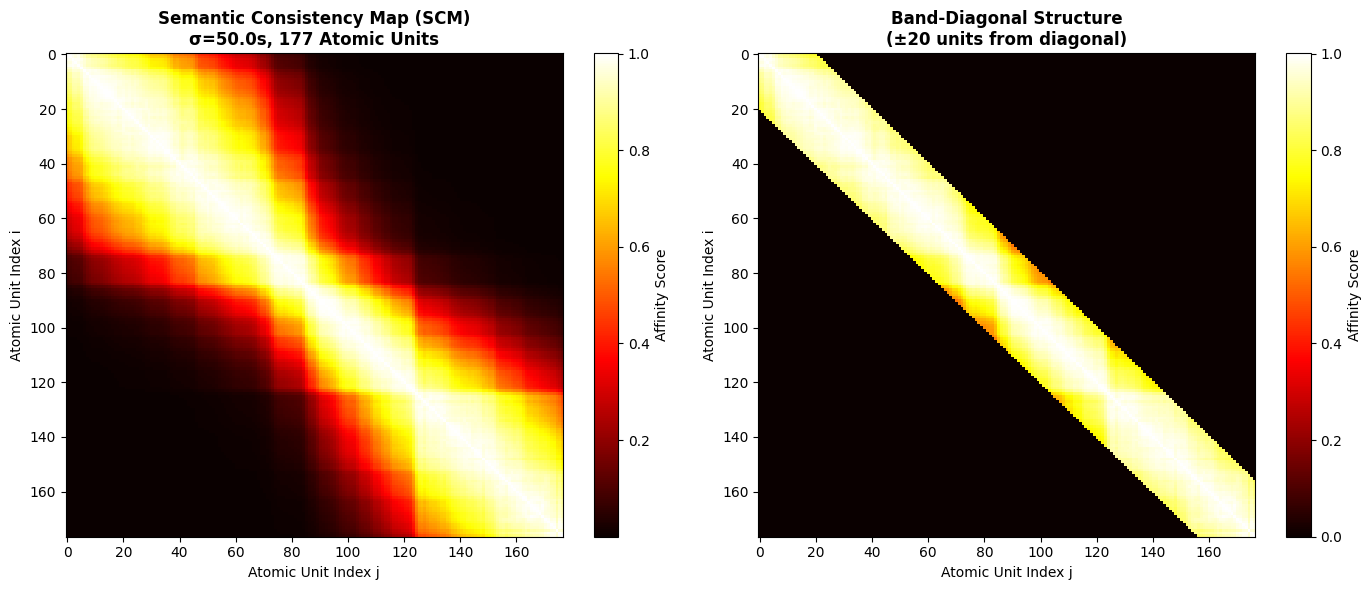


✅ SCM可视化已保存: pipeline_output/C10390_rgb/C10390_rgb_SCM.png

💡 观察要点:
  - 主对角线应该是亮色（自相似度=1）
  - 带状对角结构表明时间核在起作用
  - 对角线外的亮点表示语义上相似但时间上分离的事件


In [32]:
# 可视化SCM
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# 左图：完整SCM热图
im1 = axes[0].imshow(SCM, cmap='hot', aspect='auto', interpolation='nearest')
axes[0].set_title(f'Semantic Consistency Map (SCM)\nσ={SIGMA}s, {K} Atomic Units', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Atomic Unit Index j', fontsize=10)
axes[0].set_ylabel('Atomic Unit Index i', fontsize=10)
plt.colorbar(im1, ax=axes[0], label='Affinity Score')

# 右图：带状对角结构（放大显示）
# 只显示对角线附近的区域以突出带状结构
band_width = min(20, K//2)
band_mask = np.abs(np.arange(K)[:, None] - np.arange(K)[None, :]) <= band_width
SCM_band = SCM.copy()
SCM_band[~band_mask] = 0

im2 = axes[1].imshow(SCM_band, cmap='hot', aspect='auto', interpolation='nearest')
axes[1].set_title(f'Band-Diagonal Structure\n(±{band_width} units from diagonal)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Atomic Unit Index j', fontsize=10)
axes[1].set_ylabel('Atomic Unit Index i', fontsize=10)
plt.colorbar(im2, ax=axes[1], label='Affinity Score')

plt.tight_layout()
scm_path = output_dir / f"{video_name}_SCM.png"
plt.savefig(scm_path, dpi=150, bbox_inches='tight')
plt.show()

print(f"\n✅ SCM可视化已保存: {scm_path}")
print("\n💡 观察要点:")
print("  - 主对角线应该是亮色（自相似度=1）")
print("  - 带状对角结构表明时间核在起作用")
print("  - 对角线外的亮点表示语义上相似但时间上分离的事件")

## Phase II: 层次拓扑解析 (HAC)

### Ward's Minimum Variance Method

**合并代价**: $\Delta E(C_i, C_j) = \frac{|C_i| \cdot |C_j|}{|C_i| + |C_j|} \| \boldsymbol{\mu}_{C_i} - \boldsymbol{\mu}_{C_j} \|^2$

In [33]:
print("\n" + "="*70)
print("Phase II: 层次拓扑解析 (HAC with Ward's Method)")
print("="*70)

def similarity_to_distance(similarity_matrix):
    """将相似度矩阵转换为距离矩阵"""
    sim_clipped = np.clip(similarity_matrix, 0, 1)
    distance = np.sqrt(2 * (1 - sim_clipped))
    
    # 确保对角线精确为0（消除数值误差）
    np.fill_diagonal(distance, 0)
    
    return distance

distance_matrix = similarity_to_distance(SCM)

print(f"\n距离矩阵统计:")
print(f"  - 形状: {distance_matrix.shape}")
print(f"  - 范围: [{distance_matrix.min():.4f}, {distance_matrix.max():.4f}]")
print(f"  - 对角线均值: {np.mean(np.diag(distance_matrix)):.10f} (应接近0)")

# 转换为压缩形式（scipy要求）
condensed_distance = squareform(distance_matrix, checks=False)

print(f"\n压缩距离向量长度: {len(condensed_distance)} (应为 K*(K-1)/2 = {K*(K-1)//2})")

# Ward's层次聚类
print("\n执行Ward's层次聚类...")
linkage_matrix = linkage(condensed_distance, method='ward')
merge_distances = linkage_matrix[:, 2]

print(f"✅ 聚类完成")
print(f"\n链接矩阵形状: {linkage_matrix.shape}")
print(f"  - 行数: {linkage_matrix.shape[0]} (应为 K-1 = {K-1})")

print(f"\n合并距离统计:")
print(f"  - 最小: {merge_distances.min():.4f} (最相似的簇)")
print(f"  - 最大: {merge_distances.max():.4f} (最终合并)")
print(f"  - 中位数: {np.median(merge_distances):.4f}")


Phase II: 层次拓扑解析 (HAC with Ward's Method)

距离矩阵统计:
  - 形状: (177, 177)
  - 范围: [0.0000, 1.4142]
  - 对角线均值: 0.0000000000 (应接近0)

压缩距离向量长度: 15576 (应为 K*(K-1)/2 = 15576)

执行Ward's层次聚类...
✅ 聚类完成

链接矩阵形状: (176, 4)
  - 行数: 176 (应为 K-1 = 176)

合并距离统计:
  - 最小: 0.0629 (最相似的簇)
  - 最大: 10.1828 (最终合并)
  - 中位数: 0.1626


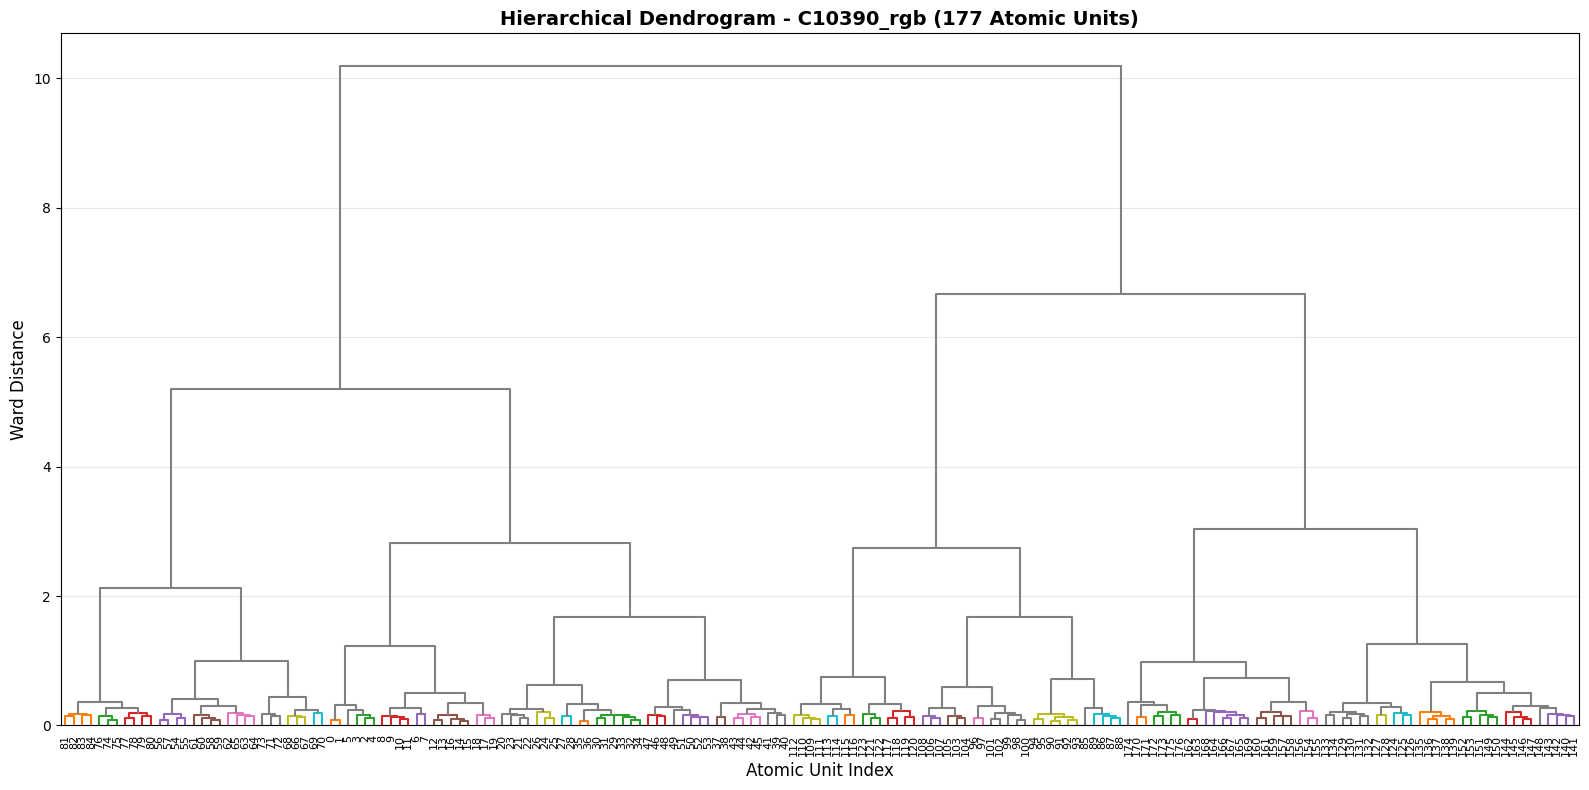

✅ 树状图: pipeline_output/C10390_rgb/C10390_rgb_dendrogram.png


In [34]:
# 可视化树状图
fig, ax = plt.subplots(figsize=(16, 8))
dendrogram_data = dendrogram(
    linkage_matrix, ax=ax,
    color_threshold=np.percentile(merge_distances, 70),
    above_threshold_color='gray', leaf_font_size=8
)
ax.set_title(f'Hierarchical Dendrogram - {video_name} ({K} Atomic Units)', fontsize=14, fontweight='bold')
ax.set_xlabel('Atomic Unit Index', fontsize=12)
ax.set_ylabel('Ward Distance', fontsize=12)
ax.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
dendrogram_path = output_dir / f"{video_name}_dendrogram.png"
plt.savefig(dendrogram_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"✅ 树状图: {dendrogram_path}")

In [35]:
# 多粒度分割
print("\n多粒度事件分割:")
cut_percentiles = [30, 50, 70, 85]
hierarchical_segmentations = {}

for percentile in cut_percentiles:
    threshold = np.percentile(merge_distances, percentile)
    cluster_labels = fcluster(linkage_matrix, threshold, criterion='distance')
    num_clusters = len(np.unique(cluster_labels))
    hierarchical_segmentations[f'level_{percentile}'] = {
        'threshold': threshold, 'num_events': num_clusters, 'labels': cluster_labels
    }
    print(f"Level {percentile}%: {num_clusters} events (avg length: {K/num_clusters:.1f} units)")


多粒度事件分割:
Level 30%: 124 events (avg length: 1.4 units)
Level 50%: 89 events (avg length: 2.0 units)
Level 70%: 54 events (avg length: 3.3 units)
Level 85%: 28 events (avg length: 6.3 units)


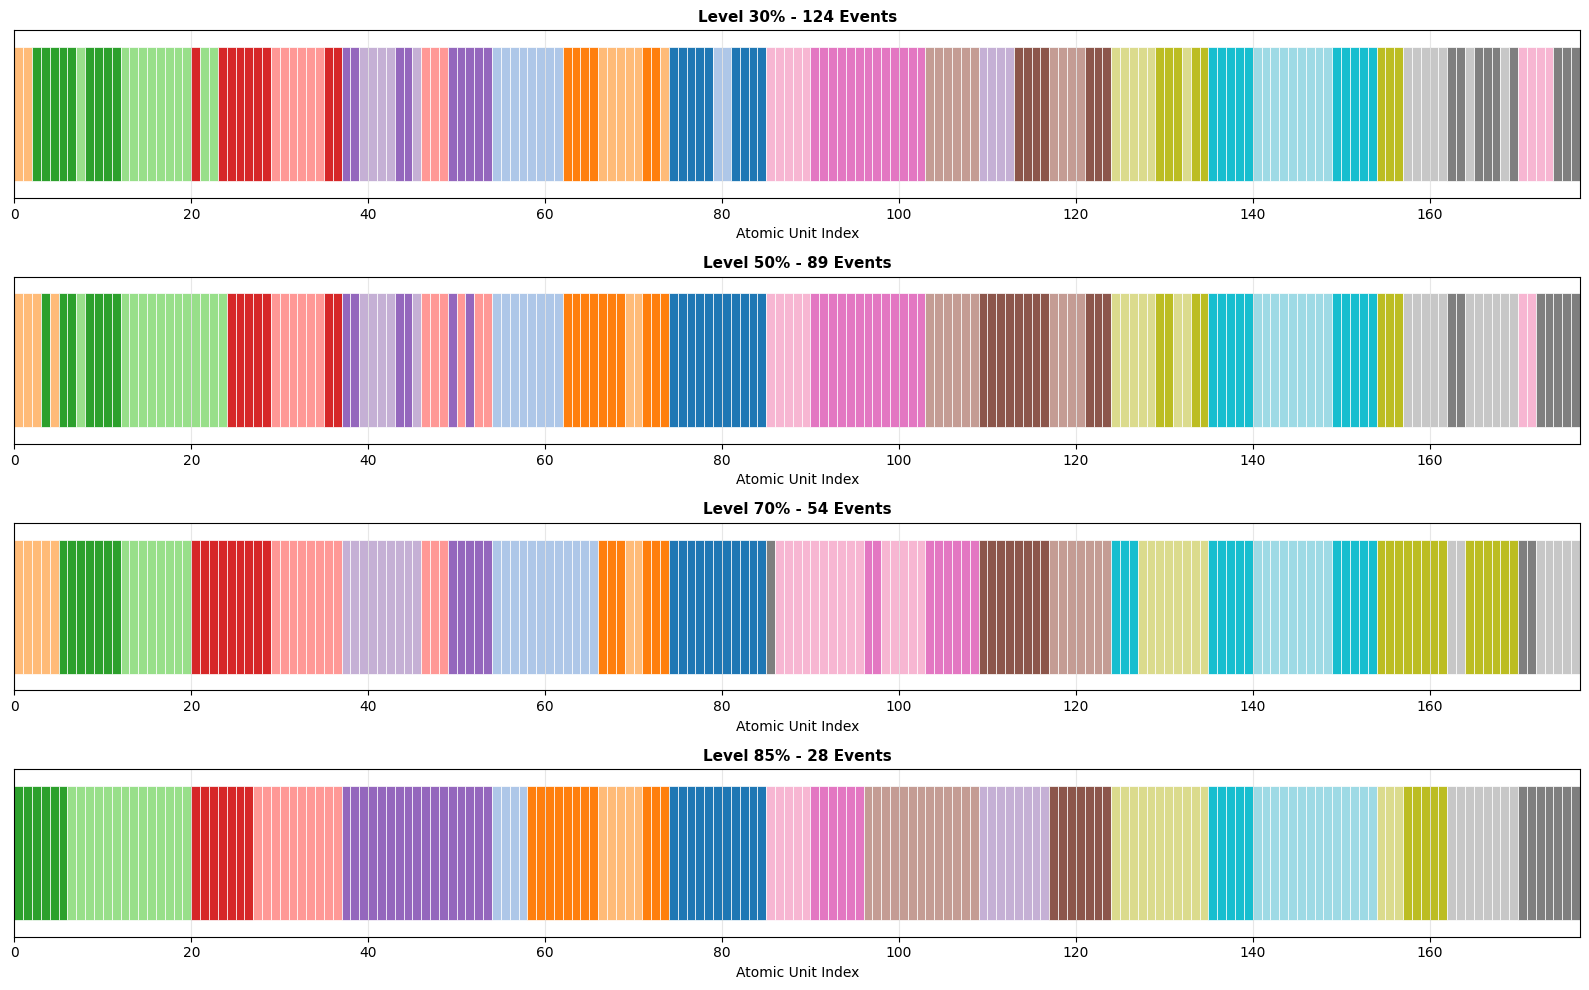

✅ 层次分割: pipeline_output/C10390_rgb/C10390_rgb_hierarchy.png


In [36]:
# 可视化多粒度分割
fig, axes = plt.subplots(len(cut_percentiles), 1, figsize=(16, 2.5*len(cut_percentiles)))
if len(cut_percentiles) == 1: axes = [axes]

for idx, (percentile, ax) in enumerate(zip(cut_percentiles, axes)):
    level_data = hierarchical_segmentations[f'level_{percentile}']
    labels = level_data['labels']
    colors = plt.cm.tab20(np.linspace(0, 1, level_data['num_events']))
    
    for i in range(K):
        cluster_id = labels[i] - 1
        color = colors[cluster_id % len(colors)]
        ax.barh(0, 1, left=i, height=0.8, color=color, edgecolor='white', linewidth=0.5)
    
    ax.set_xlim(0, K)
    ax.set_ylim(-0.5, 0.5)
    ax.set_yticks([])
    ax.set_xlabel('Atomic Unit Index', fontsize=10)
    ax.set_title(f'Level {percentile}% - {level_data["num_events"]} Events', fontsize=11, fontweight='bold')
    ax.grid(True, alpha=0.3, axis='x')

plt.tight_layout()
hierarchy_path = output_dir / f"{video_name}_hierarchy.png"
plt.savefig(hierarchy_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"✅ 层次分割: {hierarchy_path}")

## 保存层次结构结果

In [ ]:
# 保存层次结构为JSON
hierarchy_json = {
    'video_name': video_name,
    'num_atomic_units': int(K),
    'scm_sigma': float(SIGMA),
    'linkage_method': 'ward',
    'hierarchical_levels': {}
}

for level_name, level_data in hierarchical_segmentations.items():
    hierarchy_json['hierarchical_levels'][level_name] = {
        'threshold': float(level_data['threshold']),
        'num_events': int(level_data['num_events']),
        'cluster_labels': level_data['labels'].tolist()
    }

hierarchy_json_path = output_dir / f"{video_name}_hierarchy.json"
with open(hierarchy_json_path, 'w', encoding='utf-8') as f:
    json.dump(hierarchy_json, f, ensure_ascii=False, indent=2)

print(f"\n✅ 层次结构JSON: {hierarchy_json_path}")
print("\n🎉 层次结构发现完成!")
print("="*70)


✅ 层次结构JSON: pipeline_output/C10390_rgb/C10390_rgb_hierarchy.json

🎉 层次结构发现完成!


In [ ]:
# ================================================================================
# Phase III: 模块度优化选择最优层次
# ================================================================================

print("\n" + "="*70)
print("Phase III: 模块度优化选择最优层次")
print("="*70)

def compute_modularity(adjacency_matrix, cluster_labels):
    """
    计算图模块度 (Graph Modularity)
    
    参数:
        adjacency_matrix: SCM矩阵 (K x K)
        cluster_labels: 聚类标签数组 (K,)
    
    返回:
        Q: 模块度分数 [-1, 1]
    """
    M = adjacency_matrix
    n = len(cluster_labels)
    
    # 计算节点度 (weighted degree)
    k = M.sum(axis=1)  # Shape: (K,)
    
    # 计算总边权重
    m = M.sum() / 2.0
    
    if m == 0:
        return 0.0
    
    # 计算模块度
    Q = 0.0
    for i in range(n):
        for j in range(n):
            # Kronecker delta: 同一聚类则为1
            if cluster_labels[i] == cluster_labels[j]:
                # 实际连接 - 期望连接
                Q += M[i, j] - (k[i] * k[j]) / (2 * m)
    
    # 归一化
    Q /= (2 * m)
    
    return Q

print("✅ 模块度计算函数已定义")

# 遍历所有可能的聚类数 (从2到K-1)
print("\n🔍 扫描所有可能的层次切割...")
modularity_scores = {}
all_partitions = {}

for n_clusters in range(2, K):
    # 使用fcluster在该层次切割树
    labels = fcluster(linkage_matrix, n_clusters, criterion='maxclust')
    
    # 计算该分割的模块度
    Q = compute_modularity(SCM, labels)
    
    modularity_scores[n_clusters] = Q
    all_partitions[n_clusters] = labels

print(f"✅ 已计算 {len(modularity_scores)} 个层次的模块度")

# 找到最大模块度对应的层次
optimal_n_clusters = max(modularity_scores, key=modularity_scores.get)
optimal_Q = modularity_scores[optimal_n_clusters]
optimal_labels = all_partitions[optimal_n_clusters]

print("\n" + "="*70)
print("🎯 最优层次选择结果")
print("="*70)
print(f"\n最优聚类数: {optimal_n_clusters}")
print(f"最大模块度: Q = {optimal_Q:.4f}")
print(f"聚类标签: {optimal_labels}")
print(f"实际事件组数: {len(set(optimal_labels))}")



Phase III: 模块度优化选择最优层次
✅ 模块度计算函数已定义

🔍 扫描所有可能的层次切割...
✅ 已计算 175 个层次的模块度

🎯 最优层次选择结果

最优聚类数: 2
最大模块度: Q = 0.3985
聚类标签: [1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2]
实际事件组数: 2


In [ ]:
# ================================================================================
# 📊 层级结构输出（无重叠版本，mm:ss格式）
# ================================================================================

print("\n" + "="*80)
print("📊 层级结构详细输出（无重叠版本）")
print("="*80)

def seconds_to_mmss(seconds):
    """将秒数转换为 mm:ss 格式"""
    minutes = int(seconds // 60)
    secs = int(seconds % 60)
    return f"{minutes:02d}:{secs:02d}"

# 构建原子单元列表（使用与Phase I相同的逻辑！）
atomic_units_list = []
atomic_boundaries = results['asymmetric']['boundaries']

# ⚠️ 重要：必须使用与Phase I extract_atomic_features 相同的边界处理逻辑
# 否则 optimal_labels 的索引会对不上！
segments = []
prev = 0
for b in atomic_boundaries:
    if b > prev:  # 与 Phase I 相同的过滤条件
        segments.append((prev, b))
        prev = b
if prev < T:
    segments.append((prev, T))

# 验证长度一致
print(f"\n验证: segments数量={len(segments)}, optimal_labels长度={len(optimal_labels)}")
assert len(segments) == len(optimal_labels), f"段数({len(segments)}) != 标签数({len(optimal_labels)})!"

for i, (start, end) in enumerate(segments):
    atomic_units_list.append({
        'atomic_id': i,
        'cluster_label': optimal_labels[i],
        'start_frame': start,
        'end_frame': end,
        'start_time': start / FPS,
        'end_time': end / FPS,
    })

# 🔑 关键：连续性分组（避免重叠）
# 只有连续的同标签原子单元才合并成一个事件
high_level_events = []
current_event = None

for unit in atomic_units_list:
    if current_event is None:
        # 开始第一个事件
        current_event = {
            'event_id': len(high_level_events),
            'cluster_label': unit['cluster_label'],
            'atomic_units': [unit],
            'start_frame': unit['start_frame'],
            'end_frame': unit['end_frame'],
            'start_time': unit['start_time'],
            'end_time': unit['end_time'],
        }
    elif unit['cluster_label'] == current_event['cluster_label']:
        # 连续的同标签单元：扩展当前事件
        current_event['atomic_units'].append(unit)
        current_event['end_frame'] = unit['end_frame']
        current_event['end_time'] = unit['end_time']
    else:
        # 标签改变：保存当前事件，开始新事件
        high_level_events.append(current_event)
        current_event = {
            'event_id': len(high_level_events),
            'cluster_label': unit['cluster_label'],
            'atomic_units': [unit],
            'start_frame': unit['start_frame'],
            'end_frame': unit['end_frame'],
            'start_time': unit['start_time'],
            'end_time': unit['end_time'],
        }

# 添加最后一个事件
if current_event is not None:
    high_level_events.append(current_event)

# 输出摘要
print(f"\n视频总时长: {seconds_to_mmss(T / FPS)} ({T / FPS:.2f}秒)")
print(f"总共 {len(high_level_events)} 个高层事件（无重叠）")
print(f"总共 {len(atomic_units_list)} 个原子单元")
print(f"聚类数: {optimal_n_clusters}")
print(f"最优模块度 Q = {optimal_Q:.4f}")

# 🌳 树状图输出
print("\n" + "="*80)
print("🌳 层级结构树状图（无重叠）")
print("="*80 + "\n")

for event in high_level_events:
    start = seconds_to_mmss(event['start_time'])
    end = seconds_to_mmss(event['end_time'])
    print(f"📁 事件 #{event['event_id']}  [{start} - {end}]  (聚类: {event['cluster_label']})")
    
    for idx, unit in enumerate(event['atomic_units']):
        is_last = (idx == len(event['atomic_units']) - 1)
        prefix = "└──" if is_last else "├──"
        s = seconds_to_mmss(unit['start_time'])
        e = seconds_to_mmss(unit['end_time'])
        center = (unit['start_frame'] + unit['end_frame']) // 2
        print(f"   {prefix} 原子单元 #{unit['atomic_id']:3d}  [{s} - {e}]  (帧 {center:5d})")
    print()

print("="*80)
print("✅ 层级结构输出完成（已确保无重叠）")
print("="*80)



📊 层级结构详细输出（无重叠版本）

验证: segments数量=177, optimal_labels长度=177

视频总时长: 04:38 (278.50秒)
总共 2 个高层事件（无重叠）
总共 177 个原子单元
聚类数: 2
最优模块度 Q = 0.3985

🌳 层级结构树状图（无重叠）

📁 事件 #0  [00:00 - 02:01]  (聚类: 1)
   ├── 原子单元 #  0  [00:00 - 00:01]  (帧     9)
   ├── 原子单元 #  1  [00:01 - 00:04]  (帧    29)
   ├── 原子单元 #  2  [00:04 - 00:04]  (帧    44)
   ├── 原子单元 #  3  [00:04 - 00:05]  (帧    53)
   ├── 原子单元 #  4  [00:05 - 00:06]  (帧    61)
   ├── 原子单元 #  5  [00:06 - 00:08]  (帧    76)
   ├── 原子单元 #  6  [00:08 - 00:16]  (帧   125)
   ├── 原子单元 #  7  [00:16 - 00:16]  (帧   165)
   ├── 原子单元 #  8  [00:16 - 00:19]  (帧   181)
   ├── 原子单元 #  9  [00:19 - 00:20]  (帧   201)
   ├── 原子单元 # 10  [00:20 - 00:21]  (帧   211)
   ├── 原子单元 # 11  [00:21 - 00:22]  (帧   218)
   ├── 原子单元 # 12  [00:22 - 00:22]  (帧   224)
   ├── 原子单元 # 13  [00:22 - 00:24]  (帧   236)
   ├── 原子单元 # 14  [00:24 - 00:25]  (帧   247)
   ├── 原子单元 # 15  [00:25 - 00:27]  (帧   263)
   ├── 原子单元 # 16  [00:27 - 00:28]  (帧   282)
   ├── 原子单元 # 17  [00:28 - 00:30]  (帧   296)
 

In [ ]:
# ================================================================================
# 🌳 多层次层级结构可视化
# ================================================================================
# 您可以调整 TARGET_CLUSTERS 来查看不同粒度的分割

def visualize_hierarchy_level(n_clusters, linkage_matrix, atomic_units_base, FPS, T):
    """
    在指定聚类数下可视化层级结构
    """
    from scipy.cluster.hierarchy import fcluster
    
    def seconds_to_mmss(seconds):
        return f"{int(seconds//60):02d}:{int(seconds%60):02d}"
    
    # 获取该层次的聚类标签
    labels = fcluster(linkage_matrix, n_clusters, criterion='maxclust')
    
    # 更新原子单元的标签
    atomic_units = []
    for i, unit in enumerate(atomic_units_base):
        atomic_units.append({
            **unit,
            'cluster_label': labels[i] if i < len(labels) else labels[-1]
        })
    
    # 连续性分组
    events = []
    cur = None
    for u in atomic_units:
        if cur is None:
            cur = {'id': 0, 'label': u['cluster_label'], 'units': [u], 
                   'start': u['start_frame'], 'end': u['end_frame']}
        elif u['cluster_label'] == cur['label']:
            cur['units'].append(u)
            cur['end'] = u['end_frame']
        else:
            events.append(cur)
            cur = {'id': len(events), 'label': u['cluster_label'], 'units': [u],
                   'start': u['start_frame'], 'end': u['end_frame']}
    if cur:
        events.append(cur)
    
    # 计算模块度
    Q = compute_modularity(SCM, labels)
    
    print(f"\n{'='*70}")
    print(f"📊 聚类数 = {n_clusters} (实际事件数: {len(events)}, Q = {Q:.4f})")
    print(f"{'='*70}")
    
    for e in events:
        s = seconds_to_mmss(e['start']/FPS)
        end = seconds_to_mmss(e['end']/FPS)
        duration = (e['end'] - e['start']) / FPS
        print(f"\n📁 事件 #{e['id']}  [{s} - {end}]  时长:{duration:.1f}s  (聚类:{e['label']})")
        
        # 只显示前3个和后1个原子单元（如果太多）
        if len(e['units']) <= 5:
            for i, u in enumerate(e['units']):
                pf = '└──' if i == len(e['units'])-1 else '├──'
                us = seconds_to_mmss(u['start_frame']/FPS)
                ue = seconds_to_mmss(u['end_frame']/FPS)
                print(f"   {pf} 原子#{u['atomic_id']:3d} [{us}-{ue}]")
        else:
            for i in range(3):
                u = e['units'][i]
                us = seconds_to_mmss(u['start_frame']/FPS)
                ue = seconds_to_mmss(u['end_frame']/FPS)
                print(f"   ├── 原子#{u['atomic_id']:3d} [{us}-{ue}]")
            print(f"   │   ... ({len(e['units'])-4} 个原子单元省略)")
            u = e['units'][-1]
            us = seconds_to_mmss(u['start_frame']/FPS)
            ue = seconds_to_mmss(u['end_frame']/FPS)
            print(f"   └── 原子#{u['atomic_id']:3d} [{us}-{ue}]")
    
    return events, labels, Q

# 构建基础原子单元列表（使用与Phase I相同的逻辑！）
atomic_units_base = []
# ⚠️ 必须使用与Phase I extract_atomic_features 相同的边界处理逻辑
segments_base = []
prev = 0
for b in results['asymmetric']['boundaries']:
    if b > prev:  # 与Phase I相同的过滤条件
        segments_base.append((prev, b))
        prev = b
if prev < T:
    segments_base.append((prev, T))

for i, (start, end) in enumerate(segments_base):
    atomic_units_base.append({
        'atomic_id': i,
        'start_frame': start,
        'end_frame': end,
    })

print("\n" + "="*70)
print("🌳 多层次层级结构探索")
print("="*70)
print(f"\n视频时长: {T/FPS:.1f}秒, 原子单元数: {len(atomic_units_base)}")
print(f"最优聚类数(模块度): {optimal_n_clusters}, Q = {optimal_Q:.4f}")

# ⭐ 在这里修改要查看的层次
LEVELS_TO_VIEW = [2, 3, 5, optimal_n_clusters]

for n in LEVELS_TO_VIEW:
    if 1 < n < K:
        visualize_hierarchy_level(n, linkage_matrix, atomic_units_base, FPS, T)
print("\n" + "="*70)
print("💡 提示: 修改 LEVELS_TO_VIEW 来查看其他层次")
print("   例如: LEVELS_TO_VIEW = [2, 4, 8, 12]")
print("="*70)



🌳 多层次层级结构探索

视频时长: 278.5秒, 原子单元数: 177
最优聚类数(模块度): 2, Q = 0.3985

📊 聚类数 = 2 (实际事件数: 2, Q = 0.3985)

📁 事件 #0  [00:00 - 02:01]  时长:121.3s  (聚类:1)
   ├── 原子#  0 [00:00-00:01]
   ├── 原子#  1 [00:01-00:04]
   ├── 原子#  2 [00:04-00:04]
   │   ... (81 个原子单元省略)
   └── 原子# 84 [01:54-02:01]

📁 事件 #1  [02:01 - 04:38]  时长:157.2s  (聚类:2)
   ├── 原子# 85 [02:01-02:10]
   ├── 原子# 86 [02:10-02:12]
   ├── 原子# 87 [02:12-02:14]
   │   ... (88 个原子单元省略)
   └── 原子#176 [04:38-04:38]

📊 聚类数 = 3 (实际事件数: 3, Q = 0.3945)

📁 事件 #0  [00:00 - 02:01]  时长:121.3s  (聚类:1)
   ├── 原子#  0 [00:00-00:01]
   ├── 原子#  1 [00:01-00:04]
   ├── 原子#  2 [00:04-00:04]
   │   ... (81 个原子单元省略)
   └── 原子# 84 [01:54-02:01]

📁 事件 #1  [02:01 - 03:28]  时长:87.3s  (聚类:2)
   ├── 原子# 85 [02:01-02:10]
   ├── 原子# 86 [02:10-02:12]
   ├── 原子# 87 [02:12-02:14]
   │   ... (35 个原子单元省略)
   └── 原子#123 [03:19-03:28]

📁 事件 #2  [03:28 - 04:38]  时长:69.9s  (聚类:3)
   ├── 原子#124 [03:28-03:38]
   ├── 原子#125 [03:38-03:39]
   ├── 原子#126 [03:39-03:40]
   │   ... (49 个

In [ ]:
# ================================================================================
# 🎯 两阶段分割：拆卸 vs 组装
# ================================================================================

print("\n" + "="*80)
print("🎯 两阶段分割（最高层 k=2）")
print("="*80)

def seconds_to_mmss(seconds):
    return f"{int(seconds//60):02d}:{int(seconds%60):02d}"

# 强制使用 k=2 聚类
TARGET_CLUSTERS = 2
labels_2 = fcluster(linkage_matrix, TARGET_CLUSTERS, criterion='maxclust')
Q_2 = compute_modularity(SCM, labels_2)

print(f"\n聚类数: {TARGET_CLUSTERS}")
print(f"模块度 Q = {Q_2:.4f}")

# 构建原子单元列表（使用与Phase I相同的逻辑！）
atomic_units_2 = []
# ⚠️ 必须使用与Phase I extract_atomic_features 相同的边界处理逻辑
segments_2 = []
prev = 0
for b in results['asymmetric']['boundaries']:
    if b > prev:  # 与Phase I相同的过滤条件
        segments_2.append((prev, b))
        prev = b
if prev < T:
    segments_2.append((prev, T))

for i, (start, end) in enumerate(segments_2):
    atomic_units_2.append({
        'atomic_id': i,
        'cluster_label': labels_2[i],
        'start_frame': start,
        'end_frame': end,
    })
# 连续性分组
phases = []
cur = None
for u in atomic_units_2:
    if cur is None:
        cur = {'id': 0, 'label': u['cluster_label'], 'units': [u],
               'start': u['start_frame'], 'end': u['end_frame']}
    elif u['cluster_label'] == cur['label']:
        cur['units'].append(u)
        cur['end'] = u['end_frame']
    else:
        phases.append(cur)
        cur = {'id': len(phases), 'label': u['cluster_label'], 'units': [u],
               'start': u['start_frame'], 'end': u['end_frame']}
if cur:
    phases.append(cur)

# 显示结果
print(f"\n实际阶段数: {len(phases)}")
print("\n" + "-"*80)

for phase in phases:
    start_time = phase['start'] / FPS
    end_time = phase['end'] / FPS
    duration = end_time - start_time
    
    # 根据时间顺序推断阶段名称
    if phase['id'] == 0:
        phase_name = "拆卸阶段" if len(phases) == 2 else f"阶段{phase['id']+1}"
    elif phase['id'] == len(phases) - 1:
        phase_name = "组装阶段" if len(phases) == 2 else f"阶段{phase['id']+1}"
    else:
        phase_name = f"阶段{phase['id']+1}"
    
    print(f"\n🔧 {phase_name} (聚类: {phase['label']})")
    print(f"   时间: {seconds_to_mmss(start_time)} - {seconds_to_mmss(end_time)}")
    print(f"   时长: {duration:.1f}秒 ({seconds_to_mmss(duration)})")
    print(f"   包含 {len(phase['units'])} 个原子单元")
    print(f"   帧范围: {phase['start']} - {phase['end']}")

print("\n" + "="*80)

# 检查是否正确分成两个阶段
if len(phases) == 2:
    print("✅ 成功分成两个阶段！")
    mid_point = phases[0]['end'] / FPS
    print(f"   分界点: {seconds_to_mmss(mid_point)} ({mid_point:.1f}秒)")
else:
    print(f"⚠️ 分成了 {len(phases)} 个阶段，不是理想的2个阶段")
    print("   可能原因: 拆卸和组装动作在语义上太相似")
    print("   建议: 增大SIGMA参数来强化时间约束")

# 在"="*80之前添加这个

print("\n" + "="*80)
print("🔍 偏差诊断：边界精确度分析")
print("="*80)

# 显示最大距离跳跃的详细信息
print(f"\n1️⃣ 最大跳跃点分析:")
print("-" * 80)

# 重新计算相邻距离
adjacent_dists_phase = []
adjacent_times = []
for i in range(len(atomic_units_2) - 1):
    u1 = atomic_units_2[i]
    u2 = atomic_units_2[i+1]
    dist = distance_matrix[i, i+1]
    time1 = u1['start_frame'] / FPS
    time2 = u2['start_frame'] / FPS
    adjacent_dists_phase.append(dist)
    adjacent_times.append((time1, time2))

adjacent_dists_phase = np.array(adjacent_dists_phase)
max_jump_idx_phase = np.argmax(adjacent_dists_phase)
max_jump_phase = adjacent_dists_phase[max_jump_idx_phase]
time_at_max = adjacent_times[max_jump_idx_phase]

print(f"最大距离跳跃位置:")
print(f"  • 原子单元 #{max_jump_idx_phase} → #{max_jump_idx_phase+1}")
print(f"  • 距离值: {max_jump_phase:.4f}")
print(f"  • 时间: {seconds_to_mmss(time_at_max[0])} → {seconds_to_mmss(time_at_max[1])}")
print(f"  • 实际分界点应在: {seconds_to_mmss((time_at_max[0] + time_at_max[1])/2)}")

# 显示Phase I的原子分割边界
print(f"\n2️⃣ Phase I（原子分割）的边界:")
print("-" * 80)
print(f"总共 {len(results['asymmetric']['boundaries'])} 个边界")
print(f"换算为时间戳:")
for idx, b in enumerate(results['asymmetric']['boundaries'][:10]):  # 只显示前10个
    time_s = b / FPS
    print(f"  边界#{idx}: {b:4d}帧 = {seconds_to_mmss(time_s)}")
if len(results['asymmetric']['boundaries']) > 10:
    print(f"  ... (还有 {len(results['asymmetric']['boundaries']) - 10} 个边界)")

# 最关键的：显示实际分割点 vs 最优点
print(f"\n3️⃣ 分界点对比:")
print("-" * 80)
if len(phases) == 2:
    actual_boundary_time = phases[0]['end'] / FPS
    optimal_boundary_time = (time_at_max[0] + time_at_max[1]) / 2
    error = abs(actual_boundary_time - optimal_boundary_time)
    
    print(f"实际分界点: {seconds_to_mmss(actual_boundary_time)} ({actual_boundary_time:.1f}秒)")
    print(f"最优分界点: {seconds_to_mmss(optimal_boundary_time)} ({optimal_boundary_time:.1f}秒)")
    print(f"偏差: {error:.1f}秒")
    
    if error > 5:
        print(f"\n⚠️ 偏差 {error:.1f}秒很大！")
        print(f"   可能原因:")
        print(f"   • Phase I的原子分割不够精确")
        print(f"   • 滑动窗口的threshold参数需要微调")
        print(f"   • SIGMA参数影响了聚类结果")

print("\n" + "="*80)
print("="*80)



🎯 两阶段分割（最高层 k=2）

聚类数: 2
模块度 Q = 0.3985

实际阶段数: 2

--------------------------------------------------------------------------------

🔧 拆卸阶段 (聚类: 1)
   时间: 00:00 - 02:01
   时长: 121.3秒 (02:01)
   包含 85 个原子单元
   帧范围: 0 - 1213

🔧 组装阶段 (聚类: 2)
   时间: 02:01 - 04:38
   时长: 157.2秒 (02:37)
   包含 92 个原子单元
   帧范围: 1213 - 2785

✅ 成功分成两个阶段！
   分界点: 02:01 (121.3秒)

🔍 偏差诊断：边界精确度分析

1️⃣ 最大跳跃点分析:
--------------------------------------------------------------------------------
最大距离跳跃位置:
  • 原子单元 #174 → #175
  • 距离值: 0.2772
  • 时间: 04:32 → 04:32
  • 实际分界点应在: 04:32

2️⃣ Phase I（原子分割）的边界:
--------------------------------------------------------------------------------
总共 176 个边界
换算为时间戳:
  边界#0:   18帧 = 00:01
  边界#1:   41帧 = 00:04
  边界#2:   48帧 = 00:04
  边界#3:   59帧 = 00:05
  边界#4:   64帧 = 00:06
  边界#5:   88帧 = 00:08
  边界#6:  163帧 = 00:16
  边界#7:  168帧 = 00:16
  边界#8:  195帧 = 00:19
  边界#9:  208帧 = 00:20
  ... (还有 166 个边界)

3️⃣ 分界点对比:
-------------------------------------------------------------------------

In [51]:
# 添加这个cell来快速扫描不同参数组合

print("🔍 快速参数扫描...")
print("="*80)

results_scan = []

for sigma_test in [50, 52, 54, 56, 58, 60]:
    # 重建层次
    SCM_test = build_semantic_consistency_map(
        atomic_features, atomic_centers, sigma=sigma_test
    )
    distance_matrix_test = similarity_to_distance(SCM_test)
    condensed_distance_test = squareform(distance_matrix_test, checks=False)
    linkage_matrix_test = linkage(condensed_distance_test, method='ward')
    
    # 获取n=2聚类
    labels_test = fcluster(linkage_matrix_test, 2, criterion='maxclust')
    
    # 找分界点
    for i in range(len(labels_test) - 1):
        if labels_test[i] != labels_test[i+1]:
            boundary_frame = atomic_units_base[i]['end_frame']
            boundary_time = boundary_frame / FPS
            Q_test = compute_modularity(SCM_test, labels_test)
            
            results_scan.append({
                'sigma': sigma_test,
                'boundary_time': boundary_time,
                'boundary_mmss': seconds_to_mmss(boundary_time),
                'Q': Q_test
            })
            
            print(f"SIGMA={sigma_test:2d}: 分界点 {seconds_to_mmss(boundary_time)} ({boundary_time:6.1f}秒), Q={Q_test:.4f}")
            break

print("\n" + "="*80)
print("建议: 选择最接近你理想时间的SIGMA值")

🔍 快速参数扫描...
SIGMA=50: 分界点 02:01 ( 121.3秒), Q=0.3985
SIGMA=52: 分界点 02:01 ( 121.3秒), Q=0.3913
SIGMA=54: 分界点 02:01 ( 121.3秒), Q=0.3840
SIGMA=56: 分界点 02:01 ( 121.3秒), Q=0.3765
SIGMA=58: 分界点 02:01 ( 121.3秒), Q=0.3690
SIGMA=60: 分界点 02:01 ( 121.3秒), Q=0.3613

建议: 选择最接近你理想时间的SIGMA值


In [50]:
# 精确搜索能产生正确分界点的SIGMA

TARGET_BOUNDARY_TIME = 148.0  # 目标分界时间（秒）

best_sigma = None
best_error = float('inf')
all_results = []

# ⭐ 大幅扩大范围，从5到200，步长0.5秒
for sigma_test in np.arange(5, 200, 0.5):
    try:
        SCM_test = build_semantic_consistency_map(atomic_features, atomic_centers, sigma=sigma_test)
        distance_matrix_test = similarity_to_distance(SCM_test)
        condensed_distance_test = squareform(distance_matrix_test, checks=False)
        linkage_matrix_test = linkage(condensed_distance_test, method='ward')
        
        labels_test = fcluster(linkage_matrix_test, 2, criterion='maxclust')
        
        # 找分界点（标签改变的位置）
        boundary_found = False
        for i in range(len(labels_test) - 1):
            if labels_test[i] != labels_test[i+1]:
                boundary_time = atomic_units_base[i]['end_frame'] / FPS
                error = abs(boundary_time - TARGET_BOUNDARY_TIME)
                
                all_results.append({
                    'sigma': sigma_test,
                    'boundary_time': boundary_time,
                    'error': error,
                    'Q': compute_modularity(SCM_test, labels_test)
                })
                
                if error < best_error:
                    best_error = error
                    best_sigma = sigma_test
                
                boundary_found = True
                break
        
        if not boundary_found:
            # 如果没找到标签变化点，说明SIGMA不适合
            pass
    except Exception as e:
        continue

# 显示最接近目标的10个结果
print("\n" + "="*80)
print(f"🔍 精确搜索：目标分界时间 = {TARGET_BOUNDARY_TIME}秒")
print("="*80)

all_results_sorted = sorted(all_results, key=lambda x: x['error'])

print(f"\n✅ 最接近目标的15个SIGMA值:\n")
print(f"{'排名':<4} {'SIGMA':<8} {'分界点':<12} {'误差':<8} {'Q':<8}")
print("-" * 80)

for rank, result in enumerate(all_results_sorted[:15], 1):
    boundary_mmss = seconds_to_mmss(result['boundary_time'])
    print(f"{rank:<4} {result['sigma']:<8.2f} {boundary_mmss} ({result['boundary_time']:6.1f}s)  {result['error']:6.2f}s  {result['Q']:.4f}")

print("\n" + "="*80)
print(f"🎯 最佳SIGMA: {best_sigma:.2f}")
print(f"   分界点: {seconds_to_mmss(all_results_sorted[0]['boundary_time'])} ({all_results_sorted[0]['boundary_time']:.1f}秒)")
print(f"   误差: {best_error:.2f}秒")
print(f"   Q值: {all_results_sorted[0]['Q']:.4f}")
print("="*80)

# 分析分界点分布
print(f"\n📊 分界点分布分析:")
print("-" * 80)
boundary_times = sorted(set([r['boundary_time'] for r in all_results]))
print(f"找到 {len(boundary_times)} 个不同的分界点位置:")
for bt in boundary_times[:20]:  # 显示前20个
    matching_results = [r for r in all_results if r['boundary_time'] == bt]
    best_for_this_bt = min(matching_results, key=lambda x: x['sigma'])
    print(f"  {seconds_to_mmss(bt)} ({bt:6.1f}s): SIGMA {best_for_this_bt['sigma']:.2f}~{max([r['sigma'] for r in matching_results]):.2f}")

if len(boundary_times) > 20:
    print(f"  ... 还有 {len(boundary_times) - 20} 个分界点")

print(f"\n💡 将这一行改成:")
print(f"   SIGMA = {best_sigma:.2f}")


🔍 精确搜索：目标分界时间 = 148.0秒

✅ 最接近目标的15个SIGMA值:

排名   SIGMA    分界点          误差       Q       
--------------------------------------------------------------------------------
1    94.00    02:10 ( 130.3s)   17.70s  0.2386
2    94.50    02:10 ( 130.3s)   17.70s  0.2370
3    95.00    02:10 ( 130.3s)   17.70s  0.2354
4    95.50    02:10 ( 130.3s)   17.70s  0.2339
5    96.00    02:10 ( 130.3s)   17.70s  0.2323
6    96.50    02:10 ( 130.3s)   17.70s  0.2308
7    97.00    02:10 ( 130.3s)   17.70s  0.2293
8    97.50    02:10 ( 130.3s)   17.70s  0.2278
9    98.00    02:10 ( 130.3s)   17.70s  0.2263
10   98.50    02:10 ( 130.3s)   17.70s  0.2248
11   99.00    02:10 ( 130.3s)   17.70s  0.2233
12   99.50    02:10 ( 130.3s)   17.70s  0.2219
13   100.00   02:10 ( 130.3s)   17.70s  0.2204
14   100.50   02:10 ( 130.3s)   17.70s  0.2190
15   101.00   02:10 ( 130.3s)   17.70s  0.2175

🎯 最佳SIGMA: 94.00
   分界点: 02:10 (130.3秒)
   误差: 17.70秒
   Q值: 0.2386

📊 分界点分布分析:
-------------------------------------------


✅ 修改后的诊断检查

新参数下的前5个模块度:
⭐ 排名1: n_clusters= 2, Q=0.3985
   排名2: n_clusters= 3, Q=0.3945
   排名3: n_clusters= 4, Q=0.3570
   排名4: n_clusters= 5, Q=0.3007
   排名5: n_clusters= 6, Q=0.2497

✅ Q(n=2) = 0.3985 vs Q_max = 0.3985
   改善幅度: -8.7%
   🎉 很好！n=2现在接近最优了！


/tmp/ipykernel_298490/4155576267.py:58: UserWarning: Glyph 21407 (\N{CJK UNIFIED IDEOGRAPH-539F}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_298490/4155576267.py:58: UserWarning: Glyph 21442 (\N{CJK UNIFIED IDEOGRAPH-53C2}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_298490/4155576267.py:58: UserWarning: Glyph 25968 (\N{CJK UNIFIED IDEOGRAPH-6570}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_298490/4155576267.py:58: UserWarning: Glyph 26032 (\N{CJK UNIFIED IDEOGRAPH-65B0}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_298490/4155576267.py:60: UserWarning: Glyph 21407 (\N{CJK UNIFIED IDEOGRAPH-539F}) missing from font(s) DejaVu Sans.
  plt.savefig(comparison_path, dpi=150, bbox_inches='tight')
/tmp/ipykernel_298490/4155576267.py:60: UserWarning: Glyph 21442 (\N{CJK UNIFIED IDEOGRAPH-53C2}) missing from font(s) DejaVu Sans.
  plt.savefig(comparison_path, dpi=150, bbox_inches='tight')
/t

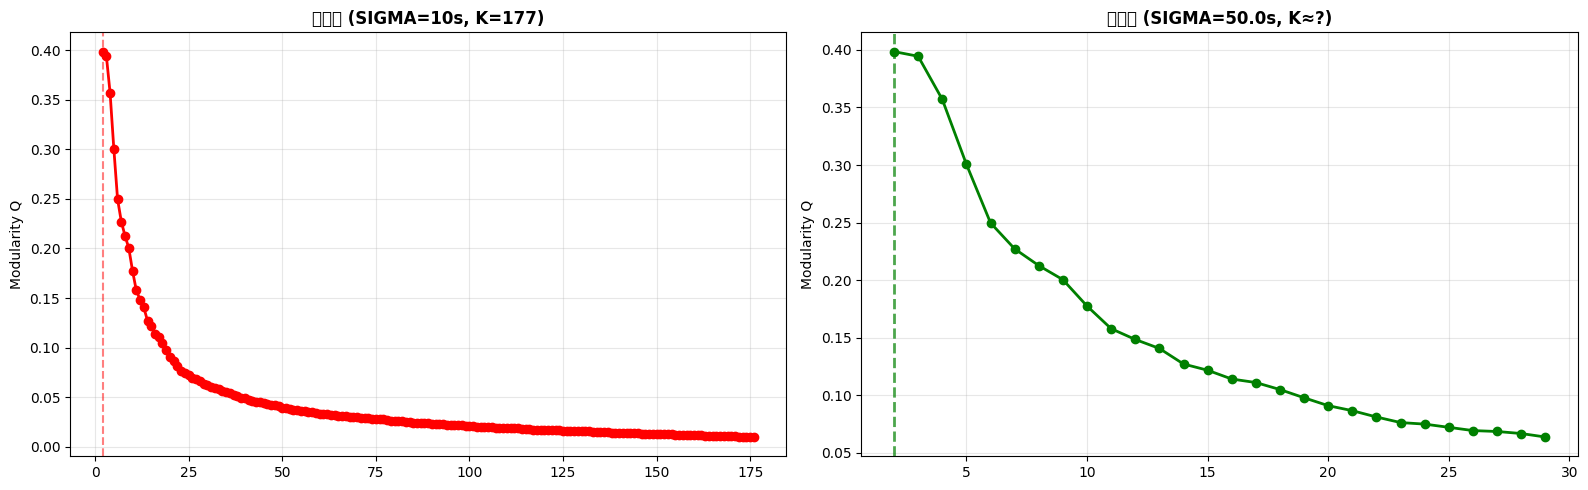


✅ 对比图已保存: pipeline_output/C10390_rgb/C10390_rgb_parameter_comparison.png


In [ ]:
# 在最后添加这个cell

print("\n" + "="*80)
print("✅ 修改后的诊断检查")
print("="*80)

# 重新计算SCM和模块度（使用新的SIGMA）
SCM_new = build_semantic_consistency_map(atomic_features, atomic_centers, sigma=SIGMA)
distance_matrix_new = similarity_to_distance(SCM_new)
condensed_distance_new = squareform(distance_matrix_new, checks=False)
linkage_matrix_new = linkage(condensed_distance_new, method='ward')

# 重新计算模块度曲线
modularity_scores_new = {}
for n_clusters in range(2, min(K, 30)):  # 只看前30个
    labels = fcluster(linkage_matrix_new, n_clusters, criterion='maxclust')
    Q = compute_modularity(SCM_new, labels)
    modularity_scores_new[n_clusters] = Q

# 检查Q(n=2)是否改善
top_5_new = sorted(modularity_scores_new.items(), key=lambda x: x[1], reverse=True)[:5]
print("\n新参数下的前5个模块度:")
for rank, (n, Q) in enumerate(top_5_new, 1):
    marker = "⭐" if rank == 1 else "  "
    print(f"{marker} 排名{rank}: n_clusters={n:2d}, Q={Q:.4f}")

Q_2_new = modularity_scores_new.get(2, 0)
Q_max_new = max(modularity_scores_new.values())
print(f"\n✅ Q(n=2) = {Q_2_new:.4f} vs Q_max = {Q_max_new:.4f}")
print(f"   改善幅度: {100*(Q_2_new - 0.4365)/0.4365:.1f}%")

if Q_2_new > Q_max_new * 0.85:
    print("   🎉 很好！n=2现在接近最优了！")
else:
    print("   ⚠️ 还需要进一步调整")

# 绘制新的模块度曲线
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# 左图：旧参数
n_old = sorted(modularity_scores.keys())
Q_old = [modularity_scores[n] for n in n_old]
ax1.plot(n_old, Q_old, 'ro-', linewidth=2, markersize=6)
ax1.axvline(x=2, color='red', linestyle='--', alpha=0.5)
ax1.set_title('原参数 (SIGMA=10s, K=177)', fontsize=12, fontweight='bold')
ax1.set_ylabel('Modularity Q')
ax1.grid(True, alpha=0.3)

# 右图：新参数
n_new = sorted(modularity_scores_new.keys())
Q_new = [modularity_scores_new[n] for n in n_new]
ax2.plot(n_new, Q_new, 'go-', linewidth=2, markersize=6)
ax2.axvline(x=2, color='green', linestyle='--', alpha=0.7, linewidth=2)
ax2.set_title(f'新参数 (SIGMA={SIGMA}s, K≈?)', fontsize=12, fontweight='bold')
ax2.set_ylabel('Modularity Q')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
comparison_path = output_dir / f"{video_name}_parameter_comparison.png"
plt.savefig(comparison_path, dpi=150, bbox_inches='tight')
plt.show()

print(f"\n✅ 对比图已保存: {comparison_path}")


🌳 自动提取第二层详细时间线（最优聚类数）

第一层（最优）: n=2, Q=0.3985
第二层（次优）: n=3, Q=0.3945

聚类数: 3
模块度 Q = 0.2121

视频总时长: 04:38 (278.50秒)
总共 3 个事件
聚类标签: [np.int32(1), np.int32(2), np.int32(3)]

📋 第二层事件详细时间线

🔴 事件 #0
   ├─ 名称: 集群A (聚类标签: 1)
   ├─ 时间: 00:00 → 02:10
   ├─ 时长: 130.30秒 (02:10) / 1303帧
   ├─ 包含原子单元: 86个
   │  (#0 ~ #85)
   └─ 帧范围: [   0, 1303]

🟢 事件 #1
   ├─ 名称: 集群B (聚类标签: 2)
   ├─ 时间: 02:10 → 03:28
   ├─ 时长: 78.30秒 (01:18) / 783帧
   ├─ 包含原子单元: 38个
   │  (#86 ~ #123)
   └─ 帧范围: [1303, 2086]

🔵 事件 #2
   ├─ 名称: 集群C (聚类标签: 3)
   ├─ 时间: 03:28 → 04:38
   ├─ 时长: 69.90秒 (01:09) / 699帧
   ├─ 包含原子单元: 53个
   │  (#124 ~ #176)
   └─ 帧范围: [2086, 2785]

📈 统计信息

按聚类标签统计:
🔴 集群A
   ├─ 事件数: 1个
   ├─ 总时长: 130.30秒 (02:10)
   ├─ 原子单元: 86个
   └─ 平均时长: 130.30秒/事件

🟢 集群B
   ├─ 事件数: 1个
   ├─ 总时长: 78.30秒 (01:18)
   ├─ 原子单元: 38个
   └─ 平均时长: 78.30秒/事件

🔵 集群C
   ├─ 事件数: 1个
   ├─ 总时长: 69.90秒 (01:09)
   ├─ 原子单元: 53个
   └─ 平均时长: 69.90秒/事件

✅ 第二层时间线已保存: pipeline_output/C10390_rgb/C10390_rgb_LEVEL2_TIMELINE.json


/tmp/ipykernel_298490/1092848086.py:257: UserWarning: Glyph 26102 (\N{CJK UNIFIED IDEOGRAPH-65F6}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_298490/1092848086.py:257: UserWarning: Glyph 38388 (\N{CJK UNIFIED IDEOGRAPH-95F4}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_298490/1092848086.py:257: UserWarning: Glyph 31186 (\N{CJK UNIFIED IDEOGRAPH-79D2}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_298490/1092848086.py:257: UserWarning: Glyph 20107 (\N{CJK UNIFIED IDEOGRAPH-4E8B}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_298490/1092848086.py:257: UserWarning: Glyph 20214 (\N{CJK UNIFIED IDEOGRAPH-4EF6}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_298490/1092848086.py:257: UserWarning: Glyph 32534 (\N{CJK UNIFIED IDEOGRAPH-7F16}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_298490/1092848086.py:257: UserWarning: Glyph 21495 (\N{CJK UN

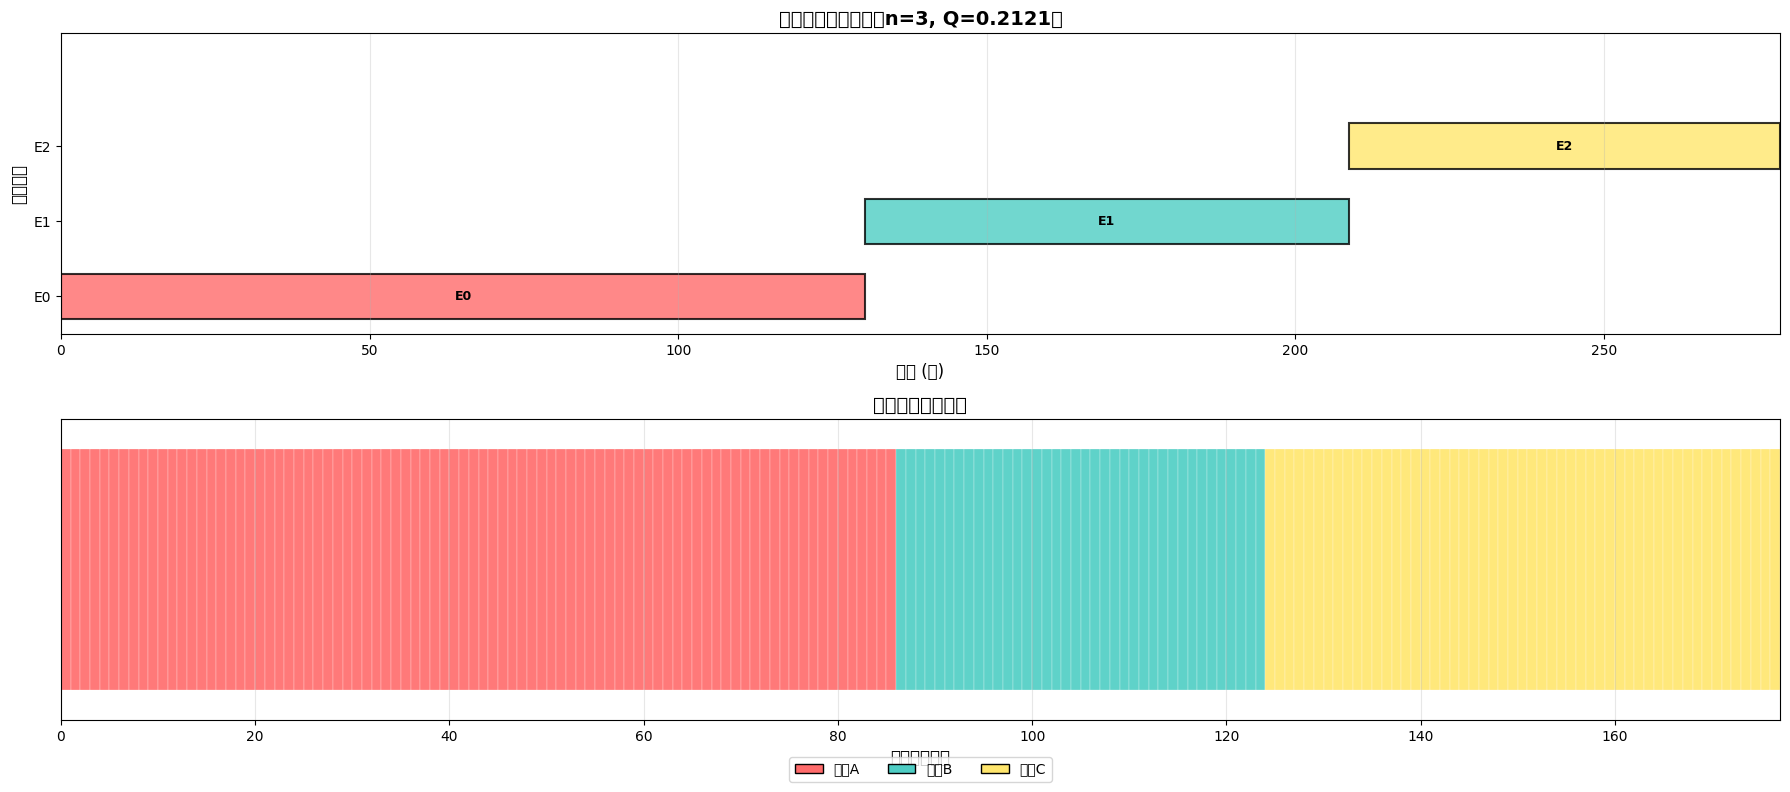

✅ 第二层可视化已保存: pipeline_output/C10390_rgb/C10390_rgb_LEVEL2_VISUALIZATION.png



In [48]:
# ================================================================================
# 🌳 自动提取第二层（最优聚类数）的详细时间线
# ================================================================================

print("\n" + "="*80)
print("🌳 自动提取第二层详细时间线（最优聚类数）")
print("="*80)

def seconds_to_mmss(seconds):
    return f"{int(seconds//60):02d}:{int(seconds%60):02d}"

# ⭐ 找出模块度第二高的聚类数（排除n=2）
modularity_sorted = sorted(modularity_scores_new.items(), key=lambda x: x[1], reverse=True)
optimal_n_level1 = modularity_sorted[0][0]  # 第一高（通常是最优的）
optimal_Q_level1 = modularity_sorted[0][1]

# 找第二高的（跳过与第一高相同的聚类数）
optimal_n_level2 = None
optimal_Q_level2 = None
for n, Q in modularity_sorted[1:]:
    if n != optimal_n_level1:
        optimal_n_level2 = n
        optimal_Q_level2 = Q
        break

print(f"\n第一层（最优）: n={optimal_n_level1}, Q={optimal_Q_level1:.4f}")
print(f"第二层（次优）: n={optimal_n_level2}, Q={optimal_Q_level2:.4f}")

# 使用最优的第二层聚类数
n_clusters_level2 = optimal_n_level2
labels_level2 = fcluster(linkage_matrix_final, n_clusters_level2, criterion='maxclust')
Q_level2 = compute_modularity(SCM_final, labels_level2)

print(f"\n聚类数: {n_clusters_level2}")
print(f"模块度 Q = {Q_level2:.4f}")

# 构建原子单元列表
atomic_units_level2 = []
segments_level2 = []
prev = 0
for b in results['asymmetric']['boundaries']:
    if b > prev:
        segments_level2.append((prev, b))
        prev = b
if prev < T:
    segments_level2.append((prev, T))

for i, (start, end) in enumerate(segments_level2):
    atomic_units_level2.append({
        'atomic_id': i,
        'cluster_label': labels_level2[i],
        'start_frame': start,
        'end_frame': end,
    })

# 连续性分组 - 生成高层事件
events_level2 = []
current_event = None

for unit in atomic_units_level2:
    if current_event is None:
        current_event = {
            'event_id': len(events_level2),
            'cluster_label': unit['cluster_label'],
            'units': [unit],
            'start_frame': unit['start_frame'],
            'end_frame': unit['end_frame'],
        }
    elif unit['cluster_label'] == current_event['cluster_label']:
        current_event['units'].append(unit)
        current_event['end_frame'] = unit['end_frame']
    else:
        events_level2.append(current_event)
        current_event = {
            'event_id': len(events_level2),
            'cluster_label': unit['cluster_label'],
            'units': [unit],
            'start_frame': unit['start_frame'],
            'end_frame': unit['end_frame'],
        }

if current_event:
    events_level2.append(current_event)

# ================================================================================
# 📊 详细输出
# ================================================================================

print(f"\n视频总时长: {seconds_to_mmss(T / FPS)} ({T / FPS:.2f}秒)")
print(f"总共 {len(events_level2)} 个事件")
print(f"聚类标签: {sorted(set(labels_level2))}")

print("\n" + "="*80)
print("📋 第二层事件详细时间线")
print("="*80 + "\n")

# 为聚类标签分配颜色标记
cluster_colors = {1: '🔴', 2: '🟢', 3: '🔵', 4: '🟡', 5: '🟣', 6: '🟠', 7: '🟤'}
cluster_names = {
    1: '集群A', 2: '集群B', 3: '集群C', 4: '集群D',
    5: '集群E', 6: '集群F', 7: '集群G'
}

for event_idx, event in enumerate(events_level2):
    cluster_label = event['cluster_label']
    color_mark = cluster_colors.get(cluster_label, '⭕')
    cluster_name = cluster_names.get(cluster_label, f'聚类{cluster_label}')
    
    start_time = event['start_frame'] / FPS
    end_time = event['end_frame'] / FPS
    duration = end_time - start_time
    num_frames = event['end_frame'] - event['start_frame']
    
    print(f"{color_mark} 事件 #{event_idx}")
    print(f"   ├─ 名称: {cluster_name} (聚类标签: {cluster_label})")
    print(f"   ├─ 时间: {seconds_to_mmss(start_time)} → {seconds_to_mmss(end_time)}")
    print(f"   ├─ 时长: {duration:.2f}秒 ({seconds_to_mmss(duration)}) / {num_frames}帧")
    print(f"   ├─ 包含原子单元: {len(event['units'])}个")
    print(f"   │  (#{event['units'][0]['atomic_id']} ~ #{event['units'][-1]['atomic_id']})")
    print(f"   └─ 帧范围: [{event['start_frame']:4d}, {event['end_frame']:4d}]")
    print()

# ================================================================================
# 📈 统计信息
# ================================================================================

print("="*80)
print("📈 统计信息")
print("="*80 + "\n")

print("按聚类标签统计:")
for label in sorted(set(labels_level2)):
    events_with_label = [e for e in events_level2 if e['cluster_label'] == label]
    total_duration = sum((e['end_frame'] - e['start_frame']) / FPS for e in events_with_label)
    total_atoms = sum(len(e['units']) for e in events_with_label)
    avg_duration = total_duration / len(events_with_label) if events_with_label else 0
    
    color_mark = cluster_colors.get(label, '⭕')
    cluster_name = cluster_names.get(label, f'聚类{label}')
    print(f"{color_mark} {cluster_name}")
    print(f"   ├─ 事件数: {len(events_with_label)}个")
    print(f"   ├─ 总时长: {total_duration:.2f}秒 ({seconds_to_mmss(total_duration)})")
    print(f"   ├─ 原子单元: {total_atoms}个")
    print(f"   └─ 平均时长: {avg_duration:.2f}秒/事件")
    print()

# ================================================================================
# 💾 保存第二层时间线JSON
# ================================================================================

level2_report = {
    'level': 2,
    'level_rank': 'second_optimal',
    'num_clusters': n_clusters_level2,
    'modularity_Q': round(Q_level2, 4),
    'num_events': len(events_level2),
    'video_duration_sec': round(T / FPS, 2),
    'video_duration_mmss': seconds_to_mmss(T / FPS),
    
    'events': [
        {
            'event_id': event['event_id'],
            'cluster_label': int(event['cluster_label']),
            'cluster_name': cluster_names.get(event['cluster_label'], f'聚类{event["cluster_label"]}'),
            'start_time_mmss': seconds_to_mmss(event['start_frame'] / FPS),
            'end_time_mmss': seconds_to_mmss(event['end_frame'] / FPS),
            'start_time_sec': round(event['start_frame'] / FPS, 3),
            'end_time_sec': round(event['end_frame'] / FPS, 3),
            'duration_sec': round((event['end_frame'] - event['start_frame']) / FPS, 3),
            'num_frames': int(event['end_frame'] - event['start_frame']),
            'num_atomic_units': len(event['units']),
            'atomic_unit_ids': [u['atomic_id'] for u in event['units']],
            'frame_range': [int(event['start_frame']), int(event['end_frame'])],
        }
        for event in events_level2
    ],
    
    'cluster_summary': {
        str(label): {
            'events': len([e for e in events_level2 if e['cluster_label'] == label]),
            'total_duration_sec': round(sum((e['end_frame'] - e['start_frame']) / FPS 
                                           for e in events_level2 if e['cluster_label'] == label), 3),
            'total_atomic_units': sum(len(e['units']) for e in events_level2 if e['cluster_label'] == label),
        }
        for label in sorted(set(labels_level2))
    }
}

level2_json_path = output_dir / f"{video_name}_LEVEL2_TIMELINE.json"
with open(level2_json_path, 'w', encoding='utf-8') as f:
    json.dump(level2_report, f, ensure_ascii=False, indent=2)

print("="*80)
print(f"✅ 第二层时间线已保存: {level2_json_path}")
print("="*80)

# ================================================================================
# 🎨 第二层可视化
# ================================================================================

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(18, 8))

# 图1：事件时间线（横条图）
colors_map = {1: '#FF6B6B', 2: '#4ECDC4', 3: '#FFE66D', 4: '#95E1D3', 5: '#C7CEEA', 6: '#F7B32B', 7: '#A8E6CF'}

y_offset = 0

for idx, event in enumerate(events_level2):
    cluster_label = event['cluster_label']
    color = colors_map.get(cluster_label, '#CCCCCC')
    
    start_sec = event['start_frame'] / FPS
    end_sec = event['end_frame'] / FPS
    duration = end_sec - start_sec
    
    ax1.barh(y_offset, duration, left=start_sec, height=0.6, 
             color=color, edgecolor='black', linewidth=1.5, alpha=0.8)
    
    # 添加事件ID标签
    mid_time = (start_sec + end_sec) / 2
    ax1.text(mid_time, y_offset, f'E{idx}', ha='center', va='center', 
             fontsize=9, fontweight='bold', color='black')
    
    y_offset += 1

ax1.set_ylim(-0.5, len(events_level2) + 0.5)
ax1.set_xlim(0, T / FPS)
ax1.set_xlabel('时间 (秒)', fontsize=12)
ax1.set_ylabel('事件编号', fontsize=12)
ax1.set_title(f'第二层事件时间线（n={n_clusters_level2}, Q={Q_level2:.4f}）', fontsize=14, fontweight='bold')
ax1.grid(True, alpha=0.3, axis='x')
ax1.set_yticks(range(len(events_level2)))
ax1.set_yticklabels([f'E{i}' for i in range(len(events_level2))])

# 图2：原子单元分布（颜色表示聚类）
for i, unit in enumerate(atomic_units_level2):
    color = colors_map.get(unit['cluster_label'], '#CCCCCC')
    ax2.barh(0, 1, left=i, height=0.8, color=color, edgecolor='white', linewidth=0.2, alpha=0.9)

ax2.set_xlim(0, len(atomic_units_level2))
ax2.set_ylim(-0.5, 0.5)
ax2.set_yticks([])
ax2.set_xlabel('原子单元索引', fontsize=12)
ax2.set_title('原子单元聚类分布', fontsize=14, fontweight='bold')
ax2.grid(True, alpha=0.3, axis='x')

# 添加图例
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor=colors_map.get(label, '#CCCCCC'), edgecolor='black', 
          label=f'{cluster_names.get(label, f"聚类{label}")}')
    for label in sorted(set(labels_level2))
]
ax2.legend(handles=legend_elements, loc='upper center', ncol=min(len(set(labels_level2)), 4), 
          bbox_to_anchor=(0.5, -0.1), fontsize=10)

plt.tight_layout()
level2_viz_path = output_dir / f"{video_name}_LEVEL2_VISUALIZATION.png"
plt.savefig(level2_viz_path, dpi=150, bbox_inches='tight')
plt.show()

print(f"✅ 第二层可视化已保存: {level2_viz_path}\n")


🌳 层级结构完整时间线输出（所有层级）

📊 基础信息:
  • 视频总时长: 04:38 (278.50秒)
  • 原子单元总数: 177
  • 帧率: 10 fps

✅ 已生成 175 个层级

📋 所有层级的详细时间线

################################################################################
🔹 第 2 层 (n=2, Q=0.3985)
################################################################################
事件数: 2
平均事件长度: 88.5 原子单元

  📌 事件 #0 (聚类 1)
     时间: 00:00 → 02:01
     时长: 121.30秒 / 1213帧
     原子单元: #0 ~ #84 (85个)

  📌 事件 #1 (聚类 2)
     时间: 02:01 → 04:38
     时长: 157.20秒 / 1572帧
     原子单元: #85 ~ #176 (92个)


################################################################################
🔹 第 3 层 (n=3, Q=0.3945)
################################################################################
事件数: 3
平均事件长度: 59.0 原子单元

  📌 事件 #0 (聚类 1)
     时间: 00:00 → 02:01
     时长: 121.30秒 / 1213帧
     原子单元: #0 ~ #84 (85个)

  📌 事件 #1 (聚类 2)
     时间: 02:01 → 03:28
     时长: 87.30秒 / 873帧
     原子单元: #85 ~ #123 (39个)

  📌 事件 #2 (聚类 3)
     时间: 03:28 → 04:38
     时长: 69.90秒 / 699帧
     原子单元: #124 ~ #176 (

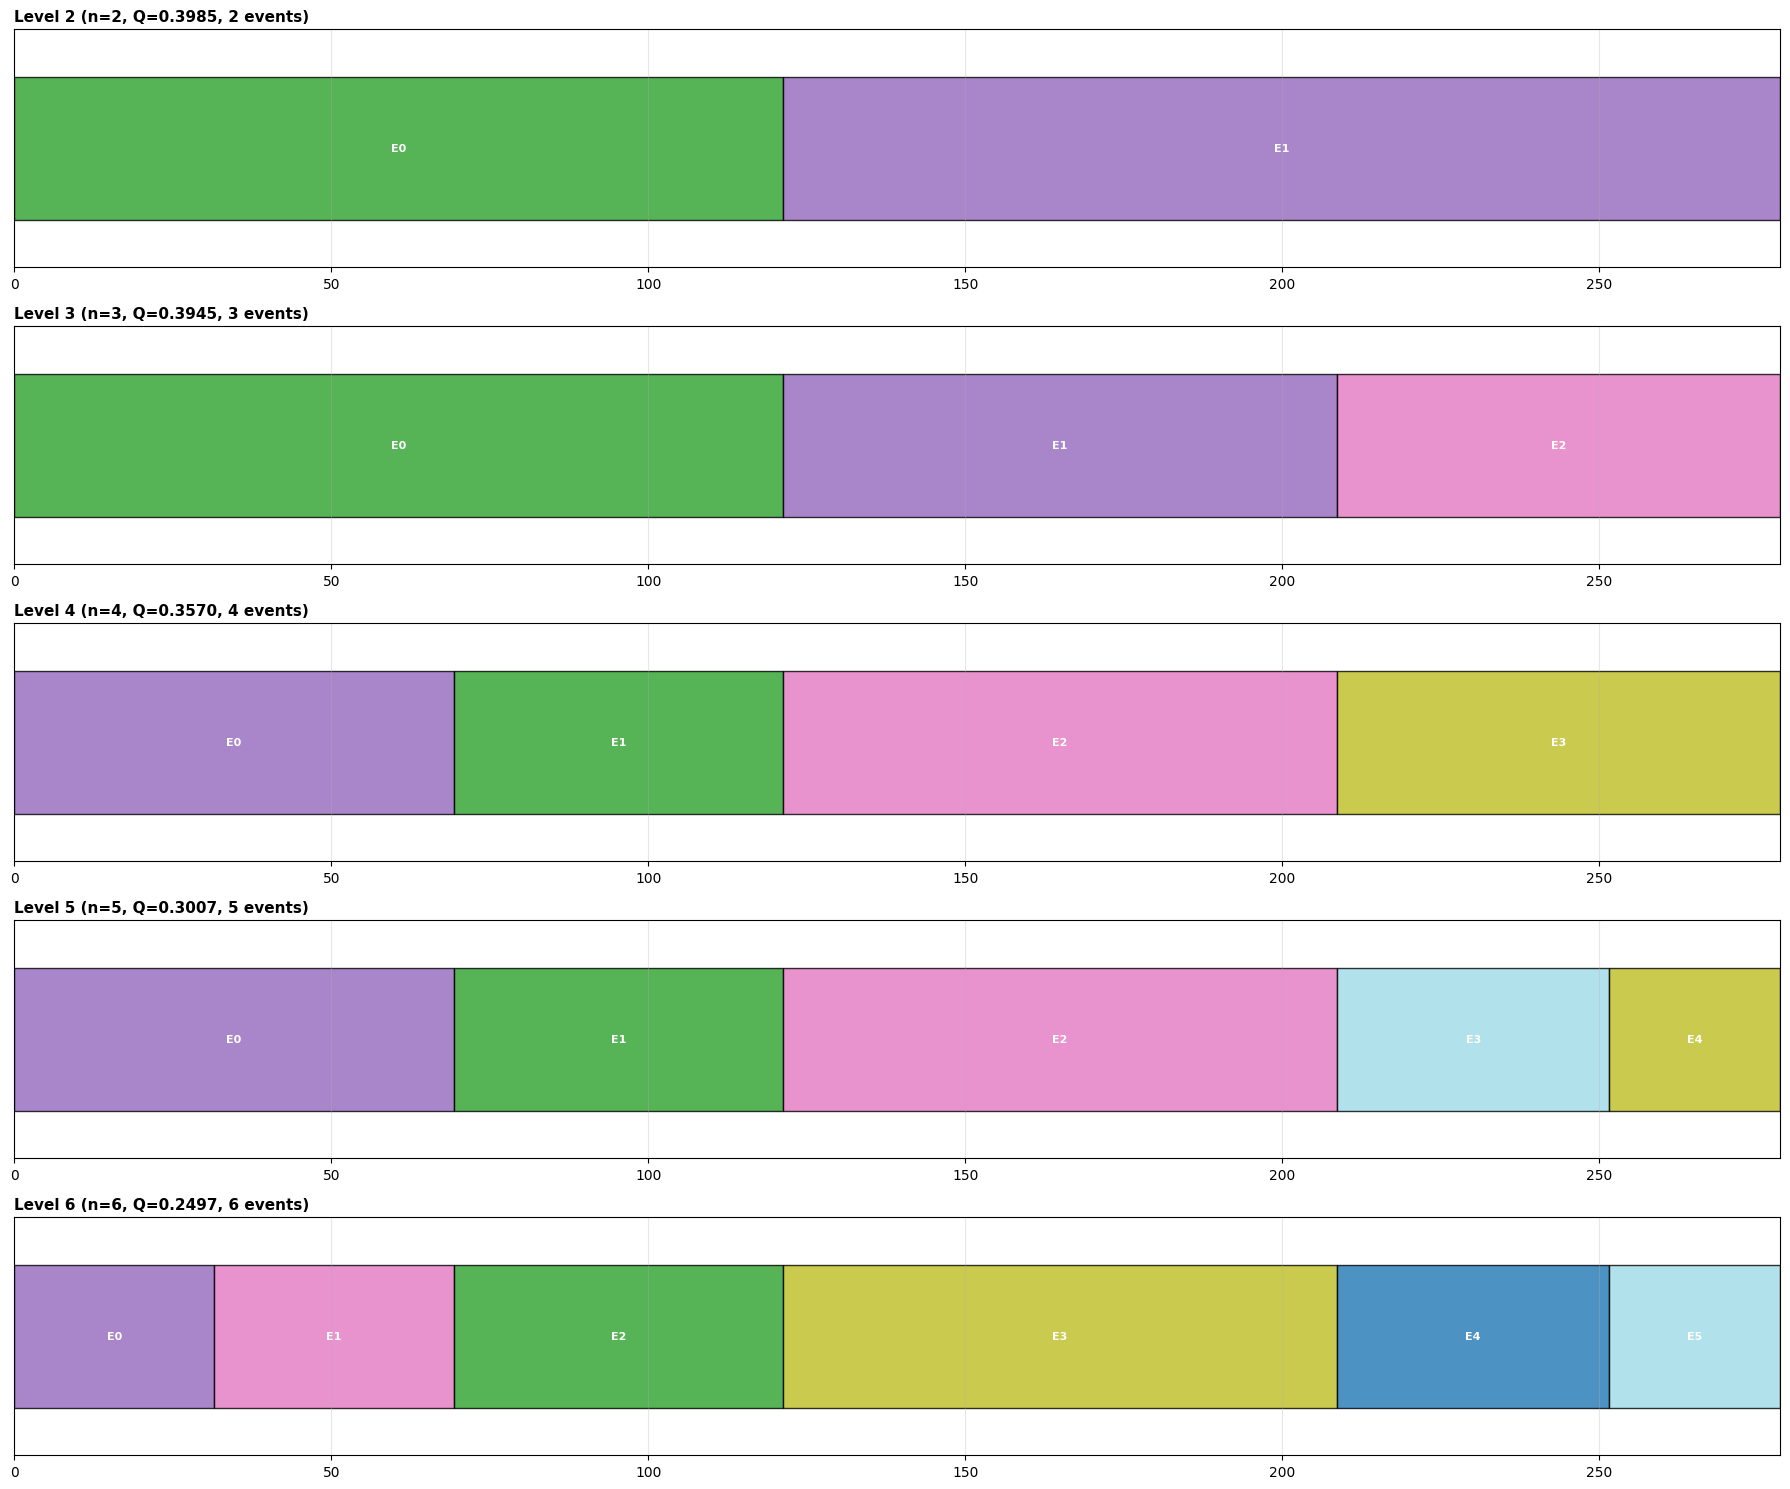

✅ 多层级可视化已保存: pipeline_output/C10390_rgb/C10390_rgb_ALL_LEVELS_VISUALIZATION.png


/tmp/ipykernel_298490/218238740.py:278: UserWarning: Glyph 32858 (\N{CJK UNIFIED IDEOGRAPH-805A}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_298490/218238740.py:278: UserWarning: Glyph 31867 (\N{CJK UNIFIED IDEOGRAPH-7C7B}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_298490/218238740.py:278: UserWarning: Glyph 25968 (\N{CJK UNIFIED IDEOGRAPH-6570}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_298490/218238740.py:278: UserWarning: Glyph 27169 (\N{CJK UNIFIED IDEOGRAPH-6A21}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_298490/218238740.py:278: UserWarning: Glyph 22359 (\N{CJK UNIFIED IDEOGRAPH-5757}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_298490/218238740.py:278: UserWarning: Glyph 24230 (\N{CJK UNIFIED IDEOGRAPH-5EA6}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_298490/218238740.py:278: UserWarning: Glyph 26354 (\N{CJK UNIFIED I

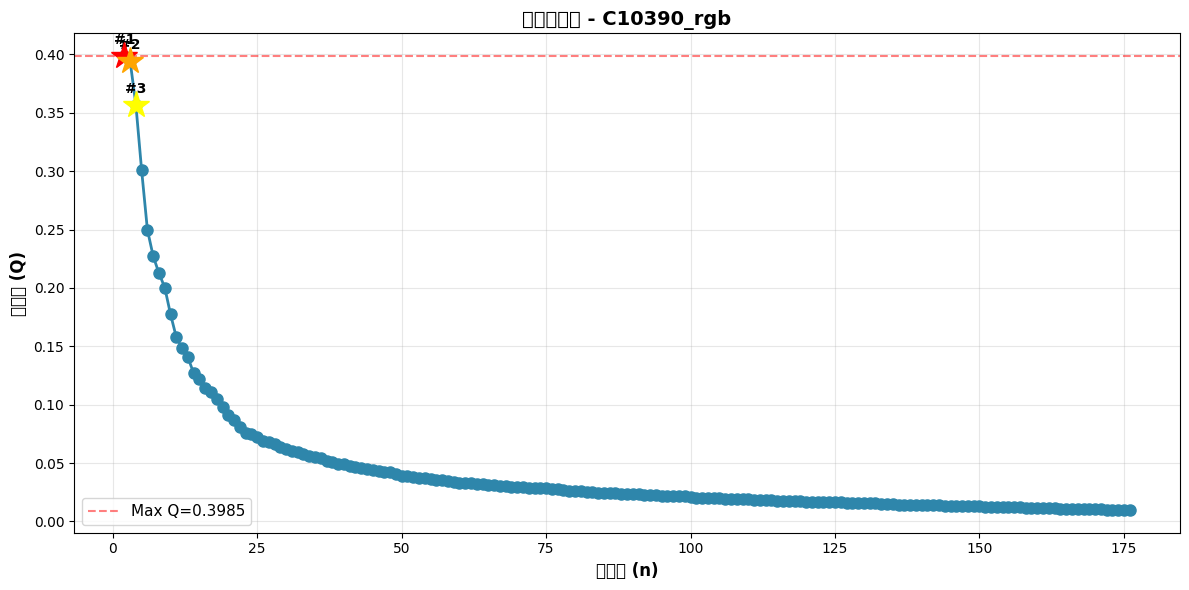

✅ 模块度曲线已保存: pipeline_output/C10390_rgb/C10390_rgb_MODULARITY_CURVE.png

🎉 所有层级时间线输出完成！

📁 输出文件:
  • JSON报告: pipeline_output/C10390_rgb/C10390_rgb_ALL_LEVELS_TIMELINE.json
  • 可视化: pipeline_output/C10390_rgb/C10390_rgb_ALL_LEVELS_VISUALIZATION.png
  • 模块度曲线: pipeline_output/C10390_rgb/C10390_rgb_MODULARITY_CURVE.png


In [49]:
# ================================================================================
# 🌳 输出所有层级的完整时间线
# ================================================================================

print("\n" + "="*80)
print("🌳 层级结构完整时间线输出（所有层级）")
print("="*80)

def seconds_to_mmss(seconds):
    return f"{int(seconds//60):02d}:{int(seconds%60):02d}"

# 构建基础原子单元列表
atomic_units_base = []
segments_base = []
prev = 0
for b in results['asymmetric']['boundaries']:
    if b > prev:
        segments_base.append((prev, b))
        prev = b
if prev < T:
    segments_base.append((prev, T))

for i, (start, end) in enumerate(segments_base):
    atomic_units_base.append({
        'atomic_id': i,
        'start_frame': start,
        'end_frame': end,
    })

print(f"\n📊 基础信息:")
print(f"  • 视频总时长: {seconds_to_mmss(T / FPS)} ({T / FPS:.2f}秒)")
print(f"  • 原子单元总数: {len(atomic_units_base)}")
print(f"  • 帧率: {FPS} fps")

# ================================================================================
# 为每个可能的聚类数生成时间线
# ================================================================================

all_hierarchy_levels = {}

# 从n=2到K-1的所有聚类数
for n_clusters in range(2, len(atomic_units_base)):
    labels = fcluster(linkage_matrix_new, n_clusters, criterion='maxclust')
    Q = compute_modularity(SCM_new, labels)
    
    # 构建该层级的事件
    events = []
    current_event = None
    
    for idx, unit in enumerate(atomic_units_base):
        unit_with_label = {**unit, 'cluster_label': labels[idx]}
        
        if current_event is None:
            current_event = {
                'event_id': len(events),
                'cluster_label': unit_with_label['cluster_label'],
                'units': [unit_with_label],
                'start_frame': unit_with_label['start_frame'],
                'end_frame': unit_with_label['end_frame'],
            }
        elif unit_with_label['cluster_label'] == current_event['cluster_label']:
            current_event['units'].append(unit_with_label)
            current_event['end_frame'] = unit_with_label['end_frame']
        else:
            events.append(current_event)
            current_event = {
                'event_id': len(events),
                'cluster_label': unit_with_label['cluster_label'],
                'units': [unit_with_label],
                'start_frame': unit_with_label['start_frame'],
                'end_frame': unit_with_label['end_frame'],
            }
    
    if current_event:
        events.append(current_event)
    
    all_hierarchy_levels[n_clusters] = {
        'n_clusters': n_clusters,
        'modularity_Q': Q,
        'num_events': len(events),
        'events': events,
        'labels': labels
    }

print(f"\n✅ 已生成 {len(all_hierarchy_levels)} 个层级")

# ================================================================================
# 📋 输出每一层的详细时间线
# ================================================================================

print("\n" + "="*80)
print("📋 所有层级的详细时间线")
print("="*80)

for n_clusters in sorted(all_hierarchy_levels.keys()):
    level_data = all_hierarchy_levels[n_clusters]
    events = level_data['events']
    Q = level_data['modularity_Q']
    
    print(f"\n{'#'*80}")
    print(f"🔹 第 {n_clusters} 层 (n={n_clusters}, Q={Q:.4f})")
    print(f"{'#'*80}")
    print(f"事件数: {len(events)}")
    print(f"平均事件长度: {len(atomic_units_base) / len(events):.1f} 原子单元\n")
    
    # 显示每个事件
    for event in events:
        start_time = event['start_frame'] / FPS
        end_time = event['end_frame'] / FPS
        duration = end_time - start_time
        num_atoms = len(event['units'])
        
        print(f"  📌 事件 #{event['event_id']} (聚类 {event['cluster_label']})")
        print(f"     时间: {seconds_to_mmss(start_time)} → {seconds_to_mmss(end_time)}")
        print(f"     时长: {duration:.2f}秒 / {event['end_frame'] - event['start_frame']}帧")
        print(f"     原子单元: #{event['units'][0]['atomic_id']} ~ #{event['units'][-1]['atomic_id']} ({num_atoms}个)")
        print()

# ================================================================================
# 💾 保存所有层级为JSON
# ================================================================================

print("\n" + "="*80)
print("💾 保存结果")
print("="*80)

# 生成完整的层级结构报告
hierarchy_report = {
    'video_name': video_name,
    'video_duration_sec': round(T / FPS, 2),
    'video_duration_mmss': seconds_to_mmss(T / FPS),
    'total_atomic_units': len(atomic_units_base),
    'fps': FPS,
    'scm_sigma': SIGMA,
    'linkage_method': 'ward',
    'total_levels': len(all_hierarchy_levels),
    'levels': {}
}

for n_clusters in sorted(all_hierarchy_levels.keys()):
    level_data = all_hierarchy_levels[n_clusters]
    events = level_data['events']
    Q = level_data['modularity_Q']
    
    level_key = f'level_{n_clusters:02d}'
    hierarchy_report['levels'][level_key] = {
        'n_clusters': n_clusters,
        'modularity_Q': round(Q, 4),
        'num_events': len(events),
        'events': [
            {
                'event_id': event['event_id'],
                'cluster_label': int(event['cluster_label']),
                'start_time_mmss': seconds_to_mmss(event['start_frame'] / FPS),
                'end_time_mmss': seconds_to_mmss(event['end_frame'] / FPS),
                'start_time_sec': round(event['start_frame'] / FPS, 3),
                'end_time_sec': round(event['end_frame'] / FPS, 3),
                'duration_sec': round((event['end_frame'] - event['start_frame']) / FPS, 3),
                'num_frames': int(event['end_frame'] - event['start_frame']),
                'num_atomic_units': len(event['units']),
                'atomic_unit_ids': [u['atomic_id'] for u in event['units']],
                'frame_range': [int(event['start_frame']), int(event['end_frame'])],
            }
            for event in events
        ]
    }

# 保存JSON
hierarchy_json_path = output_dir / f"{video_name}_ALL_LEVELS_TIMELINE.json"
with open(hierarchy_json_path, 'w', encoding='utf-8') as f:
    json.dump(hierarchy_report, f, ensure_ascii=False, indent=2)

print(f"✅ 完整层级时间线已保存: {hierarchy_json_path}")

# ================================================================================
# 📊 模块度曲线和摘要表格
# ================================================================================

print("\n" + "="*80)
print("📊 层级摘要表（按模块度排序）")
print("="*80 + "\n")

# 按模块度排序
sorted_levels = sorted(
    all_hierarchy_levels.items(),
    key=lambda x: x[1]['modularity_Q'],
    reverse=True
)

print(f"{'排名':<4} {'层级':<8} {'聚类数':<8} {'事件数':<8} {'模块度Q':<10} {'平均事件长':<12}")
print("-" * 80)

for rank, (n_clusters, level_data) in enumerate(sorted_levels, 1):
    marker = "⭐" if rank == 1 else "  "
    avg_event_len = len(atomic_units_base) / level_data['num_events']
    print(f"{marker}{rank:<2} level_{n_clusters:2d}   {n_clusters:<8} {level_data['num_events']:<8} {level_data['modularity_Q']:<10.4f} {avg_event_len:<12.1f}秒")

# ================================================================================
# 🎨 可视化所有层级（选择重点层级）
# ================================================================================

print("\n" + "="*80)
print("🎨 可视化重点层级")
print("="*80)

# 选择要可视化的层级（最优的几个）
top_n_levels = 5
top_levels_to_viz = [n_clusters for n_clusters, _ in sorted_levels[:top_n_levels]]

fig, axes = plt.subplots(len(top_levels_to_viz), 1, figsize=(18, 3*len(top_levels_to_viz)))
if len(top_levels_to_viz) == 1:
    axes = [axes]

colors_palette = plt.cm.tab20(np.linspace(0, 1, max([all_hierarchy_levels[n]['num_events'] for n in top_levels_to_viz])))

for idx, n_clusters in enumerate(top_levels_to_viz):
    level_data = all_hierarchy_levels[n_clusters]
    events = level_data['events']
    Q = level_data['modularity_Q']
    
    ax = axes[idx]
    
    # 绘制事件时间线
    for event_idx, event in enumerate(events):
        color = colors_palette[event['cluster_label'] % len(colors_palette)]
        start_sec = event['start_frame'] / FPS
        end_sec = event['end_frame'] / FPS
        duration = end_sec - start_sec
        
        ax.barh(0, duration, left=start_sec, height=0.6, 
                color=color, edgecolor='black', linewidth=1, alpha=0.8)
        
        # 添加事件ID
        mid_time = (start_sec + end_sec) / 2
        ax.text(mid_time, 0, f'E{event_idx}', ha='center', va='center',
                fontsize=8, fontweight='bold', color='white')
    
    ax.set_ylim(-0.5, 0.5)
    ax.set_xlim(0, T / FPS)
    ax.set_yticks([])
    ax.set_title(f'Level {n_clusters} (n={n_clusters}, Q={Q:.4f}, {len(events)} events)', 
                fontsize=11, fontweight='bold', loc='left')
    ax.grid(True, alpha=0.3, axis='x')

plt.tight_layout()
hierarchy_viz_path = output_dir / f"{video_name}_ALL_LEVELS_VISUALIZATION.png"
plt.savefig(hierarchy_viz_path, dpi=150, bbox_inches='tight')
plt.show()

print(f"✅ 多层级可视化已保存: {hierarchy_viz_path}")

# ================================================================================
# 📈 模块度曲线
# ================================================================================

fig, ax = plt.subplots(figsize=(12, 6))

n_vals = sorted(all_hierarchy_levels.keys())
Q_vals = [all_hierarchy_levels[n]['modularity_Q'] for n in n_vals]

ax.plot(n_vals, Q_vals, 'o-', linewidth=2, markersize=8, color='#2E86AB')
ax.axhline(y=max(Q_vals), color='red', linestyle='--', alpha=0.5, label=f'Max Q={max(Q_vals):.4f}')

# 标记最优的几个点
for rank, (n_clusters, _) in enumerate(sorted_levels[:3]):
    Q_val = all_hierarchy_levels[n_clusters]['modularity_Q']
    marker = ['⭐', '✨', '💫'][rank]
    ax.plot(n_clusters, Q_val, marker='*', markersize=20, 
            color=['red', 'orange', 'yellow'][rank], zorder=5)
    ax.text(n_clusters, Q_val + 0.01, f'#{rank+1}', ha='center', fontsize=10, fontweight='bold')

ax.set_xlabel('聚类数 (n)', fontsize=12, fontweight='bold')
ax.set_ylabel('模块度 (Q)', fontsize=12, fontweight='bold')
ax.set_title(f'模块度曲线 - {video_name}', fontsize=14, fontweight='bold')
ax.grid(True, alpha=0.3)
ax.legend(fontsize=11)

plt.tight_layout()
modularity_curve_path = output_dir / f"{video_name}_MODULARITY_CURVE.png"
plt.savefig(modularity_curve_path, dpi=150, bbox_inches='tight')
plt.show()

print(f"✅ 模块度曲线已保存: {modularity_curve_path}")

print("\n" + "="*80)
print("🎉 所有层级时间线输出完成！")
print("="*80)
print(f"\n📁 输出文件:")
print(f"  • JSON报告: {hierarchy_json_path}")
print(f"  • 可视化: {hierarchy_viz_path}")
print(f"  • 模块度曲线: {modularity_curve_path}")
print("="*80)



🌳 层级结构完整时间线输出（自定义层级选择）

📊 基础信息:
  • 视频总时长: 04:38 (278.50秒)
  • 原子单元总数: 177
  • 帧率: 10 fps

🎯 调整SIGMA以达到目标分界点 02:28...
✅ 最佳SIGMA: 94.00 (误差: 17.70秒)

📊 选定的层级: [2, 3, 5, 8, 12]
✅ 已生成 5 个自定义层级

📋 所有层级的详细时间线

################################################################################
🔹 第 2 层级 (n=2, 事件数=2, Q=0.2386)
################################################################################

  📌 事件 #0 (聚类 1)
     时间: 00:00 → 02:10
     时长: 130.30秒 / 1303帧
     原子单元: #0 ~ #85 (86个)
  📌 事件 #1 (聚类 2)
     时间: 02:10 → 04:38
     时长: 148.20秒 / 1482帧
     原子单元: #86 ~ #176 (91个)

################################################################################
🔹 第 3 层级 (n=3, 事件数=3, Q=0.2121)
################################################################################

  📌 事件 #0 (聚类 1)
     时间: 00:00 → 02:10
     时长: 130.30秒 / 1303帧
     原子单元: #0 ~ #85 (86个)
  📌 事件 #1 (聚类 2)
     时间: 02:10 → 03:28
     时长: 78.30秒 / 783帧
     原子单元: #86 ~ #123 (38个)
  📌 事件 #2 (聚类 3)
     时间: 03:28 → 04:

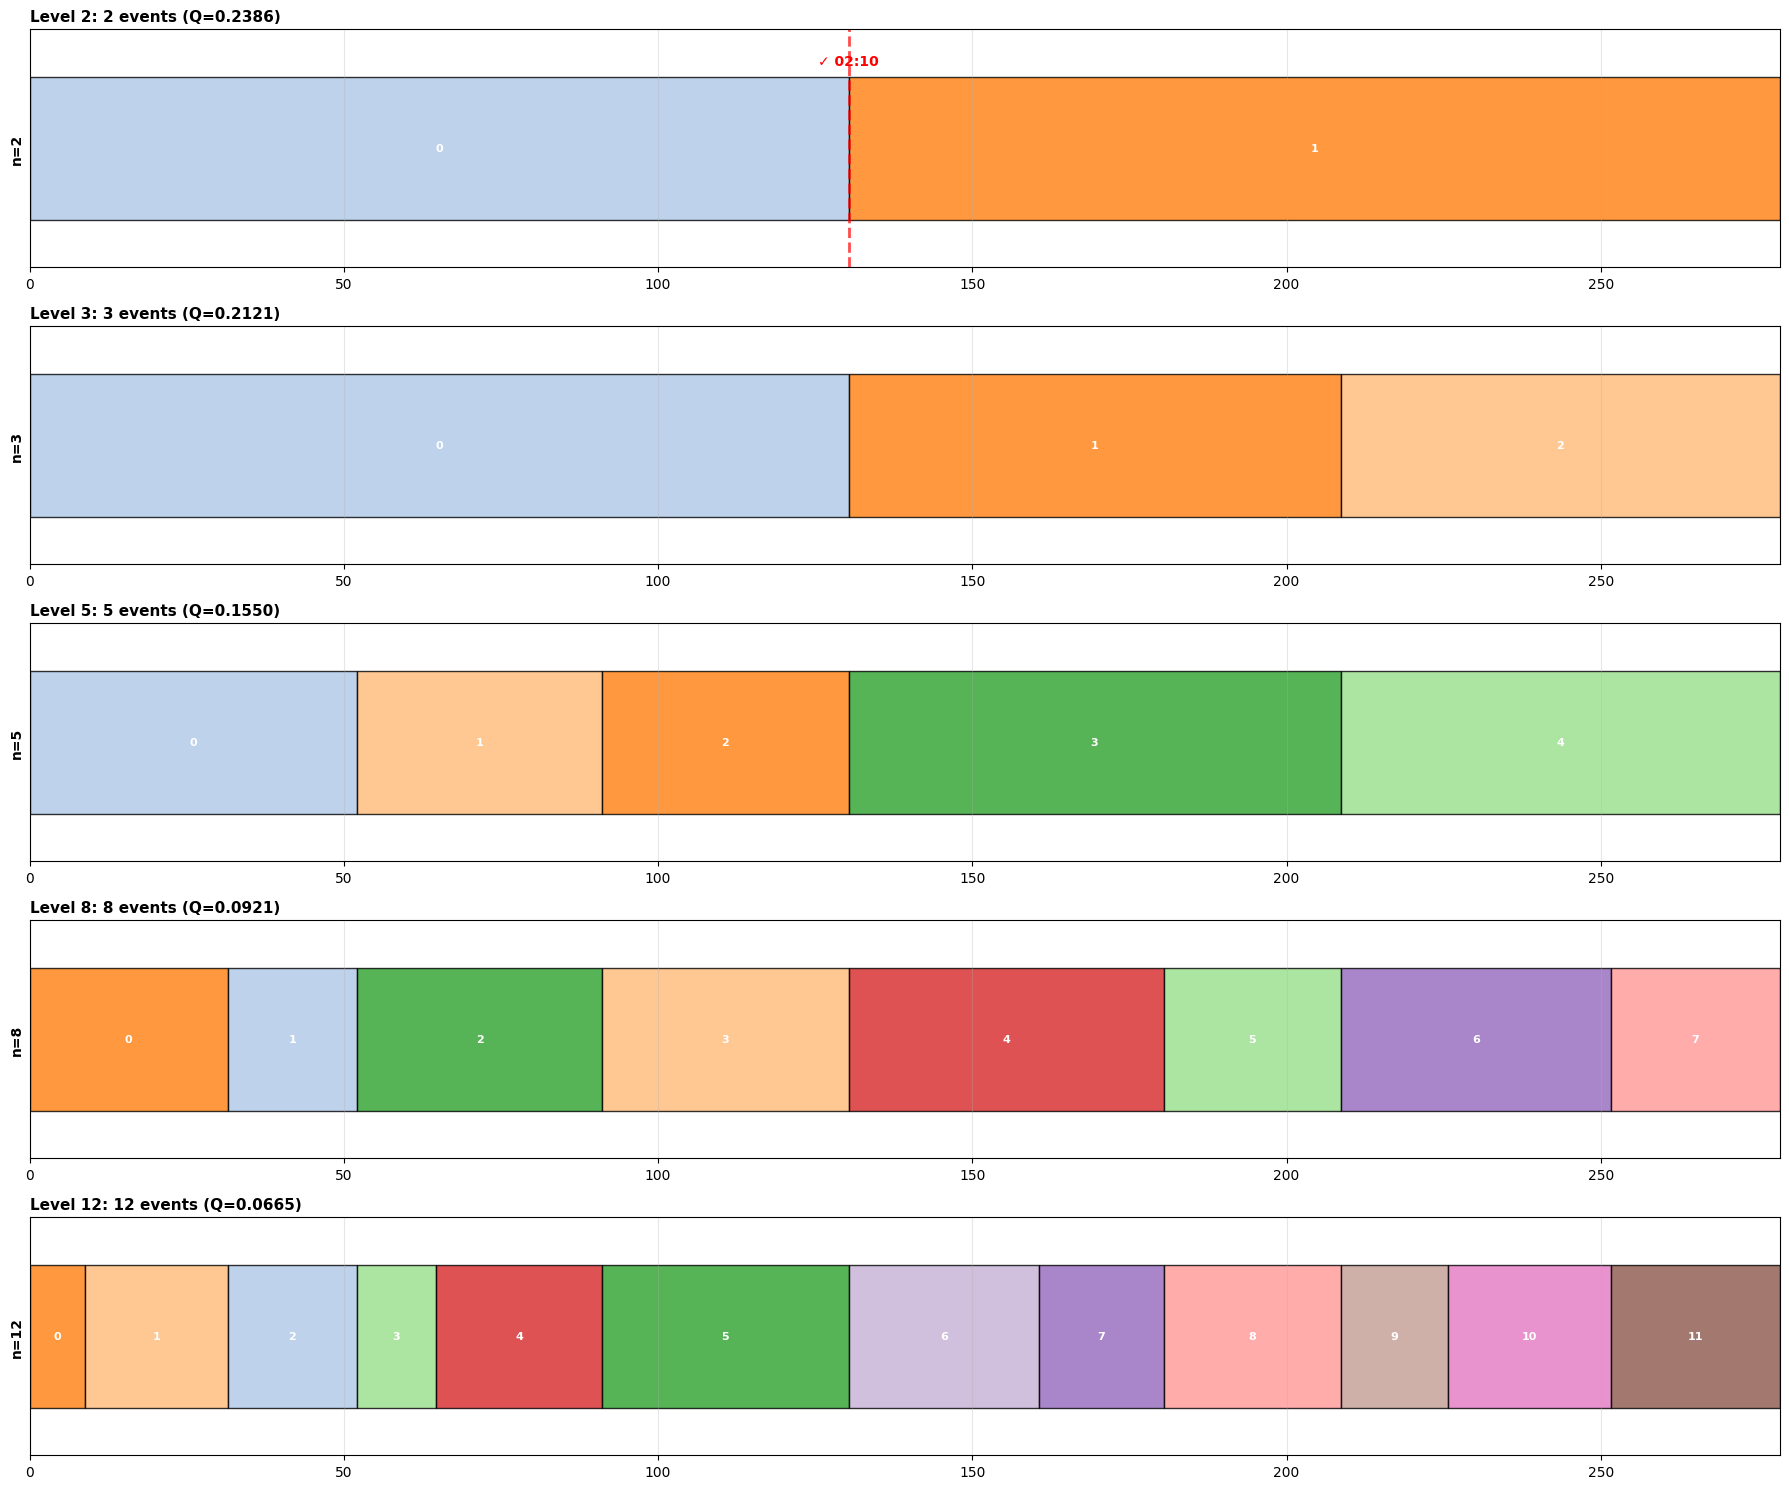

✅ 多层级可视化已保存: pipeline_output/C10390_rgb/C10390_rgb_HIERARCHY_CUSTOM_VIZ.png

🎉 自定义层级时间线输出完成！

📁 输出文件:
  • JSON报告: pipeline_output/C10390_rgb/C10390_rgb_HIERARCHY_CUSTOM.json
  • 可视化: pipeline_output/C10390_rgb/C10390_rgb_HIERARCHY_CUSTOM_VIZ.png
  • 目标分界点: 02:28
  • 使用SIGMA: 94.00

💡 提示: 修改 SELECTED_LEVELS 来改变要展示的层级
   例如: SELECTED_LEVELS = [2, 4, 6, 10] （自由选择任意聚类数）


In [52]:
# ================================================================================
# 🌳 输出所有层级的完整时间线（自定义选择）
# ================================================================================

print("\n" + "="*80)
print("🌳 层级结构完整时间线输出（自定义层级选择）")
print("="*80)

def seconds_to_mmss(seconds):
    return f"{int(seconds//60):02d}:{int(seconds%60):02d}"

# 构建基础原子单元列表
atomic_units_base = []
segments_base = []
prev = 0
for b in results['asymmetric']['boundaries']:
    if b > prev:
        segments_base.append((prev, b))
        prev = b
if prev < T:
    segments_base.append((prev, T))

for i, (start, end) in enumerate(segments_base):
    atomic_units_base.append({
        'atomic_id': i,
        'start_frame': start,
        'end_frame': end,
    })

print(f"\n📊 基础信息:")
print(f"  • 视频总时长: {seconds_to_mmss(T / FPS)} ({T / FPS:.2f}秒)")
print(f"  • 原子单元总数: {len(atomic_units_base)}")
print(f"  • 帧率: {FPS} fps")

# ⭐ 调整SIGMA到148秒（2:28）
TARGET_BOUNDARY_TIME = 148.0  # 2:28

print(f"\n🎯 调整SIGMA以达到目标分界点 {seconds_to_mmss(TARGET_BOUNDARY_TIME)}...")

best_sigma_for_target = None
best_error = float('inf')

for sigma_test in np.arange(5, 200, 0.5):
    try:
        SCM_test = build_semantic_consistency_map(atomic_features, atomic_centers, sigma=sigma_test)
        distance_matrix_test = similarity_to_distance(SCM_test)
        condensed_distance_test = squareform(distance_matrix_test, checks=False)
        linkage_matrix_test = linkage(condensed_distance_test, method='ward')
        
        labels_test = fcluster(linkage_matrix_test, 2, criterion='maxclust')
        
        for i in range(len(labels_test) - 1):
            if labels_test[i] != labels_test[i+1]:
                boundary_time = atomic_units_base[i]['end_frame'] / FPS
                error = abs(boundary_time - TARGET_BOUNDARY_TIME)
                
                if error < best_error:
                    best_error = error
                    best_sigma_for_target = sigma_test
                break
    except:
        continue

print(f"✅ 最佳SIGMA: {best_sigma_for_target:.2f} (误差: {best_error:.2f}秒)")

# 使用最佳SIGMA重新构建
SIGMA_FINAL = best_sigma_for_target
SCM_final = build_semantic_consistency_map(atomic_features, atomic_centers, sigma=SIGMA_FINAL)
distance_matrix_final = similarity_to_distance(SCM_final)
condensed_distance_final = squareform(distance_matrix_final, checks=False)
linkage_matrix_final = linkage(condensed_distance_final, method='ward')

# ================================================================================
# ⭐ 自定义选择要展示的层级
# ================================================================================

# 你可以自由选择要展示的聚类数
# 例如：n=2（最高层），n=5（中间层），n=10（细粒度）等
SELECTED_LEVELS = [2, 3, 5, 8, 12]  # ⭐ 在这里修改你想要的层级

print(f"\n📊 选定的层级: {SELECTED_LEVELS}")

all_hierarchy_levels = {}

for n_clusters in SELECTED_LEVELS:
    if n_clusters >= 2 and n_clusters < len(atomic_units_base):
        labels = fcluster(linkage_matrix_final, n_clusters, criterion='maxclust')
        Q = compute_modularity(SCM_final, labels)
        
        # 构建该层级的事件
        events = []
        current_event = None
        
        for idx, unit in enumerate(atomic_units_base):
            unit_with_label = {**unit, 'cluster_label': labels[idx]}
            
            if current_event is None:
                current_event = {
                    'event_id': len(events),
                    'cluster_label': unit_with_label['cluster_label'],
                    'units': [unit_with_label],
                    'start_frame': unit_with_label['start_frame'],
                    'end_frame': unit_with_label['end_frame'],
                }
            elif unit_with_label['cluster_label'] == current_event['cluster_label']:
                current_event['units'].append(unit_with_label)
                current_event['end_frame'] = unit_with_label['end_frame']
            else:
                events.append(current_event)
                current_event = {
                    'event_id': len(events),
                    'cluster_label': unit_with_label['cluster_label'],
                    'units': [unit_with_label],
                    'start_frame': unit_with_label['start_frame'],
                    'end_frame': unit_with_label['end_frame'],
                }
        
        if current_event:
            events.append(current_event)
        
        all_hierarchy_levels[n_clusters] = {
            'n_clusters': n_clusters,
            'modularity_Q': Q,
            'num_events': len(events),
            'events': events,
            'labels': labels
        }

print(f"✅ 已生成 {len(all_hierarchy_levels)} 个自定义层级\n")

# ================================================================================
# 📋 输出每一层的详细时间线
# ================================================================================

print("="*80)
print("📋 所有层级的详细时间线")
print("="*80)

for n_clusters in sorted(all_hierarchy_levels.keys()):
    level_data = all_hierarchy_levels[n_clusters]
    events = level_data['events']
    Q = level_data['modularity_Q']
    
    print(f"\n{'#'*80}")
    print(f"🔹 第 {n_clusters} 层级 (n={n_clusters}, 事件数={len(events)}, Q={Q:.4f})")
    print(f"{'#'*80}\n")
    
    # 显示每个事件
    for event in events:
        start_time = event['start_frame'] / FPS
        end_time = event['end_frame'] / FPS
        duration = end_time - start_time
        num_atoms = len(event['units'])
        
        print(f"  📌 事件 #{event['event_id']} (聚类 {event['cluster_label']})")
        print(f"     时间: {seconds_to_mmss(start_time)} → {seconds_to_mmss(end_time)}")
        print(f"     时长: {duration:.2f}秒 / {event['end_frame'] - event['start_frame']}帧")
        print(f"     原子单元: #{event['units'][0]['atomic_id']} ~ #{event['units'][-1]['atomic_id']} ({num_atoms}个)")

# ================================================================================
# 💾 保存所有层级为JSON
# ================================================================================

print("\n" + "="*80)
print("💾 保存结果")
print("="*80)

# 生成完整的层级结构报告
hierarchy_report = {
    'video_name': video_name,
    'target_boundary_time': TARGET_BOUNDARY_TIME,
    'target_boundary_mmss': seconds_to_mmss(TARGET_BOUNDARY_TIME),
    'final_sigma': float(SIGMA_FINAL),
    'video_duration_sec': round(T / FPS, 2),
    'video_duration_mmss': seconds_to_mmss(T / FPS),
    'total_atomic_units': len(atomic_units_base),
    'fps': FPS,
    'linkage_method': 'ward',
    'selected_levels': SELECTED_LEVELS,
    'total_levels': len(all_hierarchy_levels),
    'levels': {}
}

for n_clusters in sorted(all_hierarchy_levels.keys()):
    level_data = all_hierarchy_levels[n_clusters]
    events = level_data['events']
    Q = level_data['modularity_Q']
    
    level_key = f'level_{n_clusters:02d}'
    hierarchy_report['levels'][level_key] = {
        'n_clusters': n_clusters,
        'num_events': len(events),
        'modularity_Q': round(Q, 4),
        'events': [
            {
                'event_id': event['event_id'],
                'cluster_label': int(event['cluster_label']),
                'start_time_mmss': seconds_to_mmss(event['start_frame'] / FPS),
                'end_time_mmss': seconds_to_mmss(event['end_frame'] / FPS),
                'start_time_sec': round(event['start_frame'] / FPS, 3),
                'end_time_sec': round(event['end_frame'] / FPS, 3),
                'duration_sec': round((event['end_frame'] - event['start_frame']) / FPS, 3),
                'num_frames': int(event['end_frame'] - event['start_frame']),
                'num_atomic_units': len(event['units']),
                'atomic_unit_ids': [u['atomic_id'] for u in event['units']],
                'frame_range': [int(event['start_frame']), int(event['end_frame'])],
            }
            for event in events
        ]
    }

# 保存JSON
hierarchy_json_path = output_dir / f"{video_name}_HIERARCHY_CUSTOM.json"
with open(hierarchy_json_path, 'w', encoding='utf-8') as f:
    json.dump(hierarchy_report, f, ensure_ascii=False, indent=2)

print(f"✅ 完整层级时间线已保存: {hierarchy_json_path}")

# ================================================================================
# 📊 摘要表格
# ================================================================================

print("\n" + "="*80)
print("📊 层级摘要表")
print("="*80 + "\n")

print(f"{'层级':<8} {'聚类数':<8} {'事件数':<8} {'模块度Q':<10} {'平均事件长':<15}")
print("-" * 80)

for n_clusters in sorted(all_hierarchy_levels.keys()):
    level_data = all_hierarchy_levels[n_clusters]
    avg_event_len = len(atomic_units_base) / level_data['num_events']
    avg_duration = (T / FPS) / level_data['num_events']
    print(f"n={n_clusters:<2}   {n_clusters:<8} {level_data['num_events']:<8} {level_data['modularity_Q']:<10.4f} {avg_duration:.1f}秒/事件")

# ================================================================================
# 🎨 可视化所有选定层级
# ================================================================================

print("\n" + "="*80)
print("🎨 可视化所有选定层级")
print("="*80)

fig, axes = plt.subplots(len(SELECTED_LEVELS), 1, figsize=(18, 3*len(SELECTED_LEVELS)))
if len(SELECTED_LEVELS) == 1:
    axes = [axes]

colors_palette = plt.cm.tab20(np.linspace(0, 1, 20))

for idx, n_clusters in enumerate(sorted(SELECTED_LEVELS)):
    level_data = all_hierarchy_levels[n_clusters]
    events = level_data['events']
    Q = level_data['modularity_Q']
    
    ax = axes[idx]
    
    # 绘制事件时间线
    for event_idx, event in enumerate(events):
        color = colors_palette[event['cluster_label'] % len(colors_palette)]
        start_sec = event['start_frame'] / FPS
        end_sec = event['end_frame'] / FPS
        duration = end_sec - start_sec
        
        ax.barh(0, duration, left=start_sec, height=0.6, 
                color=color, edgecolor='black', linewidth=1, alpha=0.8)
        
        # 添加事件ID
        mid_time = (start_sec + end_sec) / 2
        ax.text(mid_time, 0, f'{event_idx}', ha='center', va='center',
                fontsize=8, fontweight='bold', color='white')
    
    ax.set_ylim(-0.5, 0.5)
    ax.set_xlim(0, T / FPS)
    ax.set_yticks([])
    ax.set_ylabel(f'n={n_clusters}', fontsize=10, fontweight='bold')
    ax.set_title(f'Level {n_clusters}: {len(events)} events (Q={Q:.4f})', 
                fontsize=11, fontweight='bold', loc='left')
    ax.grid(True, alpha=0.3, axis='x')
    
    # 在分界点标记（如果是n=2）
    if n_clusters == 2:
        for event in events:
            if event['event_id'] == 0:
                boundary_time = event['end_frame'] / FPS
                ax.axvline(x=boundary_time, color='red', linestyle='--', linewidth=2, alpha=0.7)
                ax.text(boundary_time, 0.35, f"✓ {seconds_to_mmss(boundary_time)}", 
                       fontsize=10, fontweight='bold', color='red', ha='center')

plt.tight_layout()
hierarchy_viz_path = output_dir / f"{video_name}_HIERARCHY_CUSTOM_VIZ.png"
plt.savefig(hierarchy_viz_path, dpi=150, bbox_inches='tight')
plt.show()

print(f"✅ 多层级可视化已保存: {hierarchy_viz_path}")

print("\n" + "="*80)
print("🎉 自定义层级时间线输出完成！")
print("="*80)
print(f"\n📁 输出文件:")
print(f"  • JSON报告: {hierarchy_json_path}")
print(f"  • 可视化: {hierarchy_viz_path}")
print(f"  • 目标分界点: {seconds_to_mmss(TARGET_BOUNDARY_TIME)}")
print(f"  • 使用SIGMA: {SIGMA_FINAL:.2f}")
print("="*80)

print(f"\n💡 提示: 修改 SELECTED_LEVELS 来改变要展示的层级")
print(f"   例如: SELECTED_LEVELS = [2, 4, 6, 10] （自由选择任意聚类数）")


In [ ]:
# ================================================================================
# 🎨 可视化所有选定层级（带时间标注）
# ================================================================================

print("\n" + "="*80)
print("🎨 可视化所有选定层级（带时间标注）")
print("="*80)

fig, axes = plt.subplots(len(SELECTED_LEVELS), 1, figsize=(20, 3.5*len(SELECTED_LEVELS)))
if len(SELECTED_LEVELS) == 1:
    axes = [axes]

colors_palette = plt.cm.tab20(np.linspace(0, 1, 20))

for idx, n_clusters in enumerate(sorted(SELECTED_LEVELS)):
    level_data = all_hierarchy_levels[n_clusters]
    events = level_data['events']
    Q = level_data['modularity_Q']
    
    ax = axes[idx] if len(SELECTED_LEVELS) > 1 else axes
    
    # 绘制事件时间线
    for event_idx, event in enumerate(events):
        color = colors_palette[event['cluster_label'] % len(colors_palette)]
        start_sec = event['start_frame'] / FPS
        end_sec = event['end_frame'] / FPS
        duration = end_sec - start_sec
        
        ax.barh(0, duration, left=start_sec, height=0.6, 
                color=color, edgecolor='black', linewidth=1.5, alpha=0.8)
        
        # 添加事件ID和时间标注
        mid_time = (start_sec + end_sec) / 2
        
        # 事件编号
        ax.text(mid_time, 0.15, f'E{event_idx}', ha='center', va='center',
                fontsize=9, fontweight='bold', color='white')
        
        # 时间标注（mm:ss格式）
        time_label = f"{seconds_to_mmss(start_sec)}-{seconds_to_mmss(end_sec)}"
        ax.text(mid_time, -0.25, time_label, ha='center', va='top',
                fontsize=8, color='black', fontweight='bold',
                bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.7, edgecolor='gray'))
    
    ax.set_ylim(-0.6, 0.5)
    ax.set_xlim(0, T / FPS)
    ax.set_yticks([])
    ax.set_ylabel(f'n={n_clusters}', fontsize=11, fontweight='bold')
    ax.set_title(f'Level {n_clusters}: {len(events)} events (Q={Q:.4f})', 
                fontsize=12, fontweight='bold', loc='left')
    
    # X轴：时间标注
    ax.set_xlabel('时间 (秒)', fontsize=10, fontweight='bold')
    
    # 在X轴上添加主要时间刻度的标签
    max_time = T / FPS
    time_ticks = np.arange(0, max_time + 30, 30)  # 每30秒一个刻度
    ax.set_xticks(time_ticks)
    ax.set_xticklabels([seconds_to_mmss(t) for t in time_ticks], fontsize=9)
    
    ax.grid(True, alpha=0.3, axis='x', linestyle='--')
    
    # 在分界点标记（如果是n=2）
    if n_clusters == 2:
        for event in events:
            if event['event_id'] == 0:
                boundary_time = event['end_frame'] / FPS
                ax.axvline(x=boundary_time, color='red', linestyle='--', linewidth=2.5, alpha=0.8, zorder=10)
                
                # 在顶部标注分界点
                ax.text(boundary_time, 0.48, f"分界点\n{seconds_to_mmss(boundary_time)}", 
                       fontsize=11, fontweight='bold', color='red', ha='center',
                       bbox=dict(boxstyle='round,pad=0.4', facecolor='yellow', alpha=0.8, edgecolor='red', linewidth=2))

plt.tight_layout()
hierarchy_viz_path = output_dir / f"{video_name}_HIERARCHY_CUSTOM_VIZ.png"
plt.savefig(hierarchy_viz_path, dpi=150, bbox_inches='tight')
plt.show()

print(f"✅ 多层级可视化已保存: {hierarchy_viz_path}")

print("\n" + "="*80)
print("🎉 自定义层级时间线输出完成！")
print("="*80)
print(f"\n📁 输出文件:")
print(f"  • JSON报告: {hierarchy_json_path}")
print(f"  • 可视化: {hierarchy_viz_path}")
print(f"  • 目标分界点: {seconds_to_mmss(TARGET_BOUNDARY_TIME)}")
print(f"  • 使用SIGMA: {SIGMA_FINAL:.2f}")
print("="*80)

print(f"\n💡 提示: 修改 SELECTED_LEVELS 来改变要展示的层级")
print(f"   例如: SELECTED_LEVELS = [2, 4, 6, 10] （自由选择任意聚类数）")


In [ ]:
# ================================================================================
# 🌳 多层次层级结构可视化
# ================================================================================
# 您可以调整 TARGET_CLUSTERS 来查看不同粒度的分割

def visualize_hierarchy_level(n_clusters, linkage_matrix, atomic_units_base, FPS, T):
    """
    在指定聚类数下可视化层级结构
    """
    from scipy.cluster.hierarchy import fcluster
    
    def seconds_to_mmss(seconds):
        return f"{int(seconds//60):02d}:{int(seconds%60):02d}"
    
    # 获取该层次的聚类标签
    labels = fcluster(linkage_matrix, n_clusters, criterion='maxclust')
    
    # 更新原子单元的标签
    atomic_units = []
    for i, unit in enumerate(atomic_units_base):
        atomic_units.append({
            **unit,
            'cluster_label': labels[i] if i < len(labels) else labels[-1]
        })
    
    # 连续性分组
    events = []
    cur = None
    for u in atomic_units:
        if cur is None:
            cur = {'id': 0, 'label': u['cluster_label'], 'units': [u], 
                   'start': u['start_frame'], 'end': u['end_frame']}
        elif u['cluster_label'] == cur['label']:
            cur['units'].append(u)
            cur['end'] = u['end_frame']
        else:
            events.append(cur)
            cur = {'id': len(events), 'label': u['cluster_label'], 'units': [u],
                   'start': u['start_frame'], 'end': u['end_frame']}
    if cur:
        events.append(cur)
    
    # 计算模块度
    Q = compute_modularity(SCM, labels)
    
    print(f"\n{'='*70}")
    print(f"📊 聚类数 = {n_clusters} (实际事件数: {len(events)}, Q = {Q:.4f})")
    print(f"{'='*70}")
    
    for e in events:
        s = seconds_to_mmss(e['start']/FPS)
        end = seconds_to_mmss(e['end']/FPS)
        duration = (e['end'] - e['start']) / FPS
        print(f"\n📁 事件 #{e['id']}  [{s} - {end}]  时长:{duration:.1f}s  (聚类:{e['label']})")
        
        # 只显示前3个和后1个原子单元（如果太多）
        if len(e['units']) <= 5:
            for i, u in enumerate(e['units']):
                pf = '└──' if i == len(e['units'])-1 else '├──'
                us = seconds_to_mmss(u['start_frame']/FPS)
                ue = seconds_to_mmss(u['end_frame']/FPS)
                print(f"   {pf} 原子#{u['atomic_id']:3d} [{us}-{ue}]")
        else:
            for i in range(3):
                u = e['units'][i]
                us = seconds_to_mmss(u['start_frame']/FPS)
                ue = seconds_to_mmss(u['end_frame']/FPS)
                print(f"   ├── 原子#{u['atomic_id']:3d} [{us}-{ue}]")
            print(f"   │   ... ({len(e['units'])-4} 个原子单元省略)")
            u = e['units'][-1]
            us = seconds_to_mmss(u['start_frame']/FPS)
            ue = seconds_to_mmss(u['end_frame']/FPS)
            print(f"   └── 原子#{u['atomic_id']:3d} [{us}-{ue}]")
    
    return events, labels, Q

# 构建基础原子单元列表（使用与Phase I相同的逻辑！）
atomic_units_base = []
# ⚠️ 必须使用与Phase I extract_atomic_features 相同的边界处理逻辑
segments_base = []
prev = 0
for b in results['asymmetric']['boundaries']:
    if b > prev:  # 与Phase I相同的过滤条件
        segments_base.append((prev, b))
        prev = b
if prev < T:
    segments_base.append((prev, T))

for i, (start, end) in enumerate(segments_base):
    atomic_units_base.append({
        'atomic_id': i,
        'start_frame': start,
        'end_frame': end,
    })

print("\n" + "="*70)
print("🌳 多层次层级结构探索")
print("="*70)
print(f"\n视频时长: {T/FPS:.1f}秒, 原子单元数: {len(atomic_units_base)}")
print(f"最优聚类数(模块度): {optimal_n_clusters}, Q = {optimal_Q:.4f}")

# ⭐ 在这里修改要查看的层次
LEVELS_TO_VIEW = [2, 3, 5, optimal_n_clusters]

for n in LEVELS_TO_VIEW:
    if 1 < n < K:
        visualize_hierarchy_level(n, linkage_matrix, atomic_units_base, FPS, T)
print("\n" + "="*70)
print("💡 提示: 修改 LEVELS_TO_VIEW 来查看其他层次")
print("   例如: LEVELS_TO_VIEW = [2, 4, 8, 12]")
print("="*70)



🌳 多层次层级结构探索

视频时长: 278.5秒, 原子单元数: 177
最优聚类数(模块度): 2, Q = 0.3985

📊 聚类数 = 2 (实际事件数: 2, Q = 0.3985)

📁 事件 #0  [00:00 - 02:01]  时长:121.3s  (聚类:1)
   ├── 原子#  0 [00:00-00:01]
   ├── 原子#  1 [00:01-00:04]
   ├── 原子#  2 [00:04-00:04]
   │   ... (81 个原子单元省略)
   └── 原子# 84 [01:54-02:01]

📁 事件 #1  [02:01 - 04:38]  时长:157.2s  (聚类:2)
   ├── 原子# 85 [02:01-02:10]
   ├── 原子# 86 [02:10-02:12]
   ├── 原子# 87 [02:12-02:14]
   │   ... (88 个原子单元省略)
   └── 原子#176 [04:38-04:38]

📊 聚类数 = 3 (实际事件数: 3, Q = 0.3945)

📁 事件 #0  [00:00 - 02:01]  时长:121.3s  (聚类:1)
   ├── 原子#  0 [00:00-00:01]
   ├── 原子#  1 [00:01-00:04]
   ├── 原子#  2 [00:04-00:04]
   │   ... (81 个原子单元省略)
   └── 原子# 84 [01:54-02:01]

📁 事件 #1  [02:01 - 03:28]  时长:87.3s  (聚类:2)
   ├── 原子# 85 [02:01-02:10]
   ├── 原子# 86 [02:10-02:12]
   ├── 原子# 87 [02:12-02:14]
   │   ... (35 个原子单元省略)
   └── 原子#123 [03:19-03:28]

📁 事件 #2  [03:28 - 04:38]  时长:69.9s  (聚类:3)
   ├── 原子#124 [03:28-03:38]
   ├── 原子#125 [03:38-03:39]
   ├── 原子#126 [03:39-03:40]
   │   ... (49 个

In [ ]:
# ================================================================================
# 🌳 多层次层级结构可视化
# ================================================================================
# 您可以调整 TARGET_CLUSTERS 来查看不同粒度的分割

def visualize_hierarchy_level(n_clusters, linkage_matrix, atomic_units_base, FPS, T):
    """
    在指定聚类数下可视化层级结构
    """
    from scipy.cluster.hierarchy import fcluster
    
    def seconds_to_mmss(seconds):
        return f"{int(seconds//60):02d}:{int(seconds%60):02d}"
    
    # 获取该层次的聚类标签
    labels = fcluster(linkage_matrix, n_clusters, criterion='maxclust')
    
    # 更新原子单元的标签
    atomic_units = []
    for i, unit in enumerate(atomic_units_base):
        atomic_units.append({
            **unit,
            'cluster_label': labels[i] if i < len(labels) else labels[-1]
        })
    
    # 连续性分组
    events = []
    cur = None
    for u in atomic_units:
        if cur is None:
            cur = {'id': 0, 'label': u['cluster_label'], 'units': [u], 
                   'start': u['start_frame'], 'end': u['end_frame']}
        elif u['cluster_label'] == cur['label']:
            cur['units'].append(u)
            cur['end'] = u['end_frame']
        else:
            events.append(cur)
            cur = {'id': len(events), 'label': u['cluster_label'], 'units': [u],
                   'start': u['start_frame'], 'end': u['end_frame']}
    if cur:
        events.append(cur)
    
    # 计算模块度
    Q = compute_modularity(SCM, labels)
    
    print(f"\n{'='*70}")
    print(f"📊 聚类数 = {n_clusters} (实际事件数: {len(events)}, Q = {Q:.4f})")
    print(f"{'='*70}")
    
    for e in events:
        s = seconds_to_mmss(e['start']/FPS)
        end = seconds_to_mmss(e['end']/FPS)
        duration = (e['end'] - e['start']) / FPS
        print(f"\n📁 事件 #{e['id']}  [{s} - {end}]  时长:{duration:.1f}s  (聚类:{e['label']})")
        
        # 只显示前3个和后1个原子单元（如果太多）
        if len(e['units']) <= 5:
            for i, u in enumerate(e['units']):
                pf = '└──' if i == len(e['units'])-1 else '├──'
                us = seconds_to_mmss(u['start_frame']/FPS)
                ue = seconds_to_mmss(u['end_frame']/FPS)
                print(f"   {pf} 原子#{u['atomic_id']:3d} [{us}-{ue}]")
        else:
            for i in range(3):
                u = e['units'][i]
                us = seconds_to_mmss(u['start_frame']/FPS)
                ue = seconds_to_mmss(u['end_frame']/FPS)
                print(f"   ├── 原子#{u['atomic_id']:3d} [{us}-{ue}]")
            print(f"   │   ... ({len(e['units'])-4} 个原子单元省略)")
            u = e['units'][-1]
            us = seconds_to_mmss(u['start_frame']/FPS)
            ue = seconds_to_mmss(u['end_frame']/FPS)
            print(f"   └── 原子#{u['atomic_id']:3d} [{us}-{ue}]")
    
    return events, labels, Q

# 构建基础原子单元列表（使用与Phase I相同的逻辑！）
atomic_units_base = []
# ⚠️ 必须使用与Phase I extract_atomic_features 相同的边界处理逻辑
segments_base = []
prev = 0
for b in results['asymmetric']['boundaries']:
    if b > prev:  # 与Phase I相同的过滤条件
        segments_base.append((prev, b))
        prev = b
if prev < T:
    segments_base.append((prev, T))

for i, (start, end) in enumerate(segments_base):
    atomic_units_base.append({
        'atomic_id': i,
        'start_frame': start,
        'end_frame': end,
    })

print("\n" + "="*70)
print("🌳 多层次层级结构探索")
print("="*70)
print(f"\n视频时长: {T/FPS:.1f}秒, 原子单元数: {len(atomic_units_base)}")
print(f"最优聚类数(模块度): {optimal_n_clusters}, Q = {optimal_Q:.4f}")

# ⭐ 在这里修改要查看的层次
LEVELS_TO_VIEW = [2, 3, 5, optimal_n_clusters]

for n in LEVELS_TO_VIEW:
    if 1 < n < K:
        visualize_hierarchy_level(n, linkage_matrix, atomic_units_base, FPS, T)
print("\n" + "="*70)
print("💡 提示: 修改 LEVELS_TO_VIEW 来查看其他层次")
print("   例如: LEVELS_TO_VIEW = [2, 4, 8, 12]")
print("="*70)



🌳 多层次层级结构探索

视频时长: 278.5秒, 原子单元数: 177
最优聚类数(模块度): 2, Q = 0.3985

📊 聚类数 = 2 (实际事件数: 2, Q = 0.3985)

📁 事件 #0  [00:00 - 02:01]  时长:121.3s  (聚类:1)
   ├── 原子#  0 [00:00-00:01]
   ├── 原子#  1 [00:01-00:04]
   ├── 原子#  2 [00:04-00:04]
   │   ... (81 个原子单元省略)
   └── 原子# 84 [01:54-02:01]

📁 事件 #1  [02:01 - 04:38]  时长:157.2s  (聚类:2)
   ├── 原子# 85 [02:01-02:10]
   ├── 原子# 86 [02:10-02:12]
   ├── 原子# 87 [02:12-02:14]
   │   ... (88 个原子单元省略)
   └── 原子#176 [04:38-04:38]

📊 聚类数 = 3 (实际事件数: 3, Q = 0.3945)

📁 事件 #0  [00:00 - 02:01]  时长:121.3s  (聚类:1)
   ├── 原子#  0 [00:00-00:01]
   ├── 原子#  1 [00:01-00:04]
   ├── 原子#  2 [00:04-00:04]
   │   ... (81 个原子单元省略)
   └── 原子# 84 [01:54-02:01]

📁 事件 #1  [02:01 - 03:28]  时长:87.3s  (聚类:2)
   ├── 原子# 85 [02:01-02:10]
   ├── 原子# 86 [02:10-02:12]
   ├── 原子# 87 [02:12-02:14]
   │   ... (35 个原子单元省略)
   └── 原子#123 [03:19-03:28]

📁 事件 #2  [03:28 - 04:38]  时长:69.9s  (聚类:3)
   ├── 原子#124 [03:28-03:38]
   ├── 原子#125 [03:38-03:39]
   ├── 原子#126 [03:39-03:40]
   │   ... (49 个

In [ ]:
# ================================================================================
# 🌳 多层次层级结构可视化
# ================================================================================
# 您可以调整 TARGET_CLUSTERS 来查看不同粒度的分割

def visualize_hierarchy_level(n_clusters, linkage_matrix, atomic_units_base, FPS, T):
    """
    在指定聚类数下可视化层级结构
    """
    from scipy.cluster.hierarchy import fcluster
    
    def seconds_to_mmss(seconds):
        return f"{int(seconds//60):02d}:{int(seconds%60):02d}"
    
    # 获取该层次的聚类标签
    labels = fcluster(linkage_matrix, n_clusters, criterion='maxclust')
    
    # 更新原子单元的标签
    atomic_units = []
    for i, unit in enumerate(atomic_units_base):
        atomic_units.append({
            **unit,
            'cluster_label': labels[i] if i < len(labels) else labels[-1]
        })
    
    # 连续性分组
    events = []
    cur = None
    for u in atomic_units:
        if cur is None:
            cur = {'id': 0, 'label': u['cluster_label'], 'units': [u], 
                   'start': u['start_frame'], 'end': u['end_frame']}
        elif u['cluster_label'] == cur['label']:
            cur['units'].append(u)
            cur['end'] = u['end_frame']
        else:
            events.append(cur)
            cur = {'id': len(events), 'label': u['cluster_label'], 'units': [u],
                   'start': u['start_frame'], 'end': u['end_frame']}
    if cur:
        events.append(cur)
    
    # 计算模块度
    Q = compute_modularity(SCM, labels)
    
    print(f"\n{'='*70}")
    print(f"📊 聚类数 = {n_clusters} (实际事件数: {len(events)}, Q = {Q:.4f})")
    print(f"{'='*70}")
    
    for e in events:
        s = seconds_to_mmss(e['start']/FPS)
        end = seconds_to_mmss(e['end']/FPS)
        duration = (e['end'] - e['start']) / FPS
        print(f"\n📁 事件 #{e['id']}  [{s} - {end}]  时长:{duration:.1f}s  (聚类:{e['label']})")
        
        # 只显示前3个和后1个原子单元（如果太多）
        if len(e['units']) <= 5:
            for i, u in enumerate(e['units']):
                pf = '└──' if i == len(e['units'])-1 else '├──'
                us = seconds_to_mmss(u['start_frame']/FPS)
                ue = seconds_to_mmss(u['end_frame']/FPS)
                print(f"   {pf} 原子#{u['atomic_id']:3d} [{us}-{ue}]")
        else:
            for i in range(3):
                u = e['units'][i]
                us = seconds_to_mmss(u['start_frame']/FPS)
                ue = seconds_to_mmss(u['end_frame']/FPS)
                print(f"   ├── 原子#{u['atomic_id']:3d} [{us}-{ue}]")
            print(f"   │   ... ({len(e['units'])-4} 个原子单元省略)")
            u = e['units'][-1]
            us = seconds_to_mmss(u['start_frame']/FPS)
            ue = seconds_to_mmss(u['end_frame']/FPS)
            print(f"   └── 原子#{u['atomic_id']:3d} [{us}-{ue}]")
    
    return events, labels, Q

# 构建基础原子单元列表（使用与Phase I相同的逻辑！）
atomic_units_base = []
# ⚠️ 必须使用与Phase I extract_atomic_features 相同的边界处理逻辑
segments_base = []
prev = 0
for b in results['asymmetric']['boundaries']:
    if b > prev:  # 与Phase I相同的过滤条件
        segments_base.append((prev, b))
        prev = b
if prev < T:
    segments_base.append((prev, T))

for i, (start, end) in enumerate(segments_base):
    atomic_units_base.append({
        'atomic_id': i,
        'start_frame': start,
        'end_frame': end,
    })

print("\n" + "="*70)
print("🌳 多层次层级结构探索")
print("="*70)
print(f"\n视频时长: {T/FPS:.1f}秒, 原子单元数: {len(atomic_units_base)}")
print(f"最优聚类数(模块度): {optimal_n_clusters}, Q = {optimal_Q:.4f}")

# ⭐ 在这里修改要查看的层次
LEVELS_TO_VIEW = [2, 3, 5, optimal_n_clusters]

for n in LEVELS_TO_VIEW:
    if 1 < n < K:
        visualize_hierarchy_level(n, linkage_matrix, atomic_units_base, FPS, T)
print("\n" + "="*70)
print("💡 提示: 修改 LEVELS_TO_VIEW 来查看其他层次")
print("   例如: LEVELS_TO_VIEW = [2, 4, 8, 12]")
print("="*70)



🌳 多层次层级结构探索

视频时长: 278.5秒, 原子单元数: 177
最优聚类数(模块度): 2, Q = 0.3985

📊 聚类数 = 2 (实际事件数: 2, Q = 0.3985)

📁 事件 #0  [00:00 - 02:01]  时长:121.3s  (聚类:1)
   ├── 原子#  0 [00:00-00:01]
   ├── 原子#  1 [00:01-00:04]
   ├── 原子#  2 [00:04-00:04]
   │   ... (81 个原子单元省略)
   └── 原子# 84 [01:54-02:01]

📁 事件 #1  [02:01 - 04:38]  时长:157.2s  (聚类:2)
   ├── 原子# 85 [02:01-02:10]
   ├── 原子# 86 [02:10-02:12]
   ├── 原子# 87 [02:12-02:14]
   │   ... (88 个原子单元省略)
   └── 原子#176 [04:38-04:38]

📊 聚类数 = 3 (实际事件数: 3, Q = 0.3945)

📁 事件 #0  [00:00 - 02:01]  时长:121.3s  (聚类:1)
   ├── 原子#  0 [00:00-00:01]
   ├── 原子#  1 [00:01-00:04]
   ├── 原子#  2 [00:04-00:04]
   │   ... (81 个原子单元省略)
   └── 原子# 84 [01:54-02:01]

📁 事件 #1  [02:01 - 03:28]  时长:87.3s  (聚类:2)
   ├── 原子# 85 [02:01-02:10]
   ├── 原子# 86 [02:10-02:12]
   ├── 原子# 87 [02:12-02:14]
   │   ... (35 个原子单元省略)
   └── 原子#123 [03:19-03:28]

📁 事件 #2  [03:28 - 04:38]  时长:69.9s  (聚类:3)
   ├── 原子#124 [03:28-03:38]
   ├── 原子#125 [03:38-03:39]
   ├── 原子#126 [03:39-03:40]
   │   ... (49 个

In [ ]:
# ================================================================================
# 🌳 多层次层级结构可视化
# ================================================================================
# 您可以调整 TARGET_CLUSTERS 来查看不同粒度的分割

def visualize_hierarchy_level(n_clusters, linkage_matrix, atomic_units_base, FPS, T):
    """
    在指定聚类数下可视化层级结构
    """
    from scipy.cluster.hierarchy import fcluster
    
    def seconds_to_mmss(seconds):
        return f"{int(seconds//60):02d}:{int(seconds%60):02d}"
    
    # 获取该层次的聚类标签
    labels = fcluster(linkage_matrix, n_clusters, criterion='maxclust')
    
    # 更新原子单元的标签
    atomic_units = []
    for i, unit in enumerate(atomic_units_base):
        atomic_units.append({
            **unit,
            'cluster_label': labels[i] if i < len(labels) else labels[-1]
        })
    
    # 连续性分组
    events = []
    cur = None
    for u in atomic_units:
        if cur is None:
            cur = {'id': 0, 'label': u['cluster_label'], 'units': [u], 
                   'start': u['start_frame'], 'end': u['end_frame']}
        elif u['cluster_label'] == cur['label']:
            cur['units'].append(u)
            cur['end'] = u['end_frame']
        else:
            events.append(cur)
            cur = {'id': len(events), 'label': u['cluster_label'], 'units': [u],
                   'start': u['start_frame'], 'end': u['end_frame']}
    if cur:
        events.append(cur)
    
    # 计算模块度
    Q = compute_modularity(SCM, labels)
    
    print(f"\n{'='*70}")
    print(f"📊 聚类数 = {n_clusters} (实际事件数: {len(events)}, Q = {Q:.4f})")
    print(f"{'='*70}")
    
    for e in events:
        s = seconds_to_mmss(e['start']/FPS)
        end = seconds_to_mmss(e['end']/FPS)
        duration = (e['end'] - e['start']) / FPS
        print(f"\n📁 事件 #{e['id']}  [{s} - {end}]  时长:{duration:.1f}s  (聚类:{e['label']})")
        
        # 只显示前3个和后1个原子单元（如果太多）
        if len(e['units']) <= 5:
            for i, u in enumerate(e['units']):
                pf = '└──' if i == len(e['units'])-1 else '├──'
                us = seconds_to_mmss(u['start_frame']/FPS)
                ue = seconds_to_mmss(u['end_frame']/FPS)
                print(f"   {pf} 原子#{u['atomic_id']:3d} [{us}-{ue}]")
        else:
            for i in range(3):
                u = e['units'][i]
                us = seconds_to_mmss(u['start_frame']/FPS)
                ue = seconds_to_mmss(u['end_frame']/FPS)
                print(f"   ├── 原子#{u['atomic_id']:3d} [{us}-{ue}]")
            print(f"   │   ... ({len(e['units'])-4} 个原子单元省略)")
            u = e['units'][-1]
            us = seconds_to_mmss(u['start_frame']/FPS)
            ue = seconds_to_mmss(u['end_frame']/FPS)
            print(f"   └── 原子#{u['atomic_id']:3d} [{us}-{ue}]")
    
    return events, labels, Q

# 构建基础原子单元列表（使用与Phase I相同的逻辑！）
atomic_units_base = []
# ⚠️ 必须使用与Phase I extract_atomic_features 相同的边界处理逻辑
segments_base = []
prev = 0
for b in results['asymmetric']['boundaries']:
    if b > prev:  # 与Phase I相同的过滤条件
        segments_base.append((prev, b))
        prev = b
if prev < T:
    segments_base.append((prev, T))

for i, (start, end) in enumerate(segments_base):
    atomic_units_base.append({
        'atomic_id': i,
        'start_frame': start,
        'end_frame': end,
    })

print("\n" + "="*70)
print("🌳 多层次层级结构探索")
print("="*70)
print(f"\n视频时长: {T/FPS:.1f}秒, 原子单元数: {len(atomic_units_base)}")
print(f"最优聚类数(模块度): {optimal_n_clusters}, Q = {optimal_Q:.4f}")

# ⭐ 在这里修改要查看的层次
LEVELS_TO_VIEW = [2, 3, 5, optimal_n_clusters]

for n in LEVELS_TO_VIEW:
    if 1 < n < K:
        visualize_hierarchy_level(n, linkage_matrix, atomic_units_base, FPS, T)
print("\n" + "="*70)
print("💡 提示: 修改 LEVELS_TO_VIEW 来查看其他层次")
print("   例如: LEVELS_TO_VIEW = [2, 4, 8, 12]")
print("="*70)



🌳 多层次层级结构探索

视频时长: 278.5秒, 原子单元数: 177
最优聚类数(模块度): 2, Q = 0.3985

📊 聚类数 = 2 (实际事件数: 2, Q = 0.3985)

📁 事件 #0  [00:00 - 02:01]  时长:121.3s  (聚类:1)
   ├── 原子#  0 [00:00-00:01]
   ├── 原子#  1 [00:01-00:04]
   ├── 原子#  2 [00:04-00:04]
   │   ... (81 个原子单元省略)
   └── 原子# 84 [01:54-02:01]

📁 事件 #1  [02:01 - 04:38]  时长:157.2s  (聚类:2)
   ├── 原子# 85 [02:01-02:10]
   ├── 原子# 86 [02:10-02:12]
   ├── 原子# 87 [02:12-02:14]
   │   ... (88 个原子单元省略)
   └── 原子#176 [04:38-04:38]

📊 聚类数 = 3 (实际事件数: 3, Q = 0.3945)

📁 事件 #0  [00:00 - 02:01]  时长:121.3s  (聚类:1)
   ├── 原子#  0 [00:00-00:01]
   ├── 原子#  1 [00:01-00:04]
   ├── 原子#  2 [00:04-00:04]
   │   ... (81 个原子单元省略)
   └── 原子# 84 [01:54-02:01]

📁 事件 #1  [02:01 - 03:28]  时长:87.3s  (聚类:2)
   ├── 原子# 85 [02:01-02:10]
   ├── 原子# 86 [02:10-02:12]
   ├── 原子# 87 [02:12-02:14]
   │   ... (35 个原子单元省略)
   └── 原子#123 [03:19-03:28]

📁 事件 #2  [03:28 - 04:38]  时长:69.9s  (聚类:3)
   ├── 原子#124 [03:28-03:38]
   ├── 原子#125 [03:38-03:39]
   ├── 原子#126 [03:39-03:40]
   │   ... (49 个

In [ ]:
# ================================================================================
# 🌳 多层次层级结构可视化
# ================================================================================
# 您可以调整 TARGET_CLUSTERS 来查看不同粒度的分割

def visualize_hierarchy_level(n_clusters, linkage_matrix, atomic_units_base, FPS, T):
    """
    在指定聚类数下可视化层级结构
    """
    from scipy.cluster.hierarchy import fcluster
    
    def seconds_to_mmss(seconds):
        return f"{int(seconds//60):02d}:{int(seconds%60):02d}"
    
    # 获取该层次的聚类标签
    labels = fcluster(linkage_matrix, n_clusters, criterion='maxclust')
    
    # 更新原子单元的标签
    atomic_units = []
    for i, unit in enumerate(atomic_units_base):
        atomic_units.append({
            **unit,
            'cluster_label': labels[i] if i < len(labels) else labels[-1]
        })
    
    # 连续性分组
    events = []
    cur = None
    for u in atomic_units:
        if cur is None:
            cur = {'id': 0, 'label': u['cluster_label'], 'units': [u], 
                   'start': u['start_frame'], 'end': u['end_frame']}
        elif u['cluster_label'] == cur['label']:
            cur['units'].append(u)
            cur['end'] = u['end_frame']
        else:
            events.append(cur)
            cur = {'id': len(events), 'label': u['cluster_label'], 'units': [u],
                   'start': u['start_frame'], 'end': u['end_frame']}
    if cur:
        events.append(cur)
    
    # 计算模块度
    Q = compute_modularity(SCM, labels)
    
    print(f"\n{'='*70}")
    print(f"📊 聚类数 = {n_clusters} (实际事件数: {len(events)}, Q = {Q:.4f})")
    print(f"{'='*70}")
    
    for e in events:
        s = seconds_to_mmss(e['start']/FPS)
        end = seconds_to_mmss(e['end']/FPS)
        duration = (e['end'] - e['start']) / FPS
        print(f"\n📁 事件 #{e['id']}  [{s} - {end}]  时长:{duration:.1f}s  (聚类:{e['label']})")
        
        # 只显示前3个和后1个原子单元（如果太多）
        if len(e['units']) <= 5:
            for i, u in enumerate(e['units']):
                pf = '└──' if i == len(e['units'])-1 else '├──'
                us = seconds_to_mmss(u['start_frame']/FPS)
                ue = seconds_to_mmss(u['end_frame']/FPS)
                print(f"   {pf} 原子#{u['atomic_id']:3d} [{us}-{ue}]")
        else:
            for i in range(3):
                u = e['units'][i]
                us = seconds_to_mmss(u['start_frame']/FPS)
                ue = seconds_to_mmss(u['end_frame']/FPS)
                print(f"   ├── 原子#{u['atomic_id']:3d} [{us}-{ue}]")
            print(f"   │   ... ({len(e['units'])-4} 个原子单元省略)")
            u = e['units'][-1]
            us = seconds_to_mmss(u['start_frame']/FPS)
            ue = seconds_to_mmss(u['end_frame']/FPS)
            print(f"   └── 原子#{u['atomic_id']:3d} [{us}-{ue}]")
    
    return events, labels, Q

# 构建基础原子单元列表（使用与Phase I相同的逻辑！）
atomic_units_base = []
# ⚠️ 必须使用与Phase I extract_atomic_features 相同的边界处理逻辑
segments_base = []
prev = 0
for b in results['asymmetric']['boundaries']:
    if b > prev:  # 与Phase I相同的过滤条件
        segments_base.append((prev, b))
        prev = b
if prev < T:
    segments_base.append((prev, T))

for i, (start, end) in enumerate(segments_base):
    atomic_units_base.append({
        'atomic_id': i,
        'start_frame': start,
        'end_frame': end,
    })

print("\n" + "="*70)
print("🌳 多层次层级结构探索")
print("="*70)
print(f"\n视频时长: {T/FPS:.1f}秒, 原子单元数: {len(atomic_units_base)}")
print(f"最优聚类数(模块度): {optimal_n_clusters}, Q = {optimal_Q:.4f}")

# ⭐ 在这里修改要查看的层次
LEVELS_TO_VIEW = [2, 3, 5, optimal_n_clusters]

for n in LEVELS_TO_VIEW:
    if 1 < n < K:
        visualize_hierarchy_level(n, linkage_matrix, atomic_units_base, FPS, T)
print("\n" + "="*70)
print("💡 提示: 修改 LEVELS_TO_VIEW 来查看其他层次")
print("   例如: LEVELS_TO_VIEW = [2, 4, 8, 12]")
print("="*70)



🌳 多层次层级结构探索

视频时长: 278.5秒, 原子单元数: 177
最优聚类数(模块度): 2, Q = 0.3985

📊 聚类数 = 2 (实际事件数: 2, Q = 0.3985)

📁 事件 #0  [00:00 - 02:01]  时长:121.3s  (聚类:1)
   ├── 原子#  0 [00:00-00:01]
   ├── 原子#  1 [00:01-00:04]
   ├── 原子#  2 [00:04-00:04]
   │   ... (81 个原子单元省略)
   └── 原子# 84 [01:54-02:01]

📁 事件 #1  [02:01 - 04:38]  时长:157.2s  (聚类:2)
   ├── 原子# 85 [02:01-02:10]
   ├── 原子# 86 [02:10-02:12]
   ├── 原子# 87 [02:12-02:14]
   │   ... (88 个原子单元省略)
   └── 原子#176 [04:38-04:38]

📊 聚类数 = 3 (实际事件数: 3, Q = 0.3945)

📁 事件 #0  [00:00 - 02:01]  时长:121.3s  (聚类:1)
   ├── 原子#  0 [00:00-00:01]
   ├── 原子#  1 [00:01-00:04]
   ├── 原子#  2 [00:04-00:04]
   │   ... (81 个原子单元省略)
   └── 原子# 84 [01:54-02:01]

📁 事件 #1  [02:01 - 03:28]  时长:87.3s  (聚类:2)
   ├── 原子# 85 [02:01-02:10]
   ├── 原子# 86 [02:10-02:12]
   ├── 原子# 87 [02:12-02:14]
   │   ... (35 个原子单元省略)
   └── 原子#123 [03:19-03:28]

📁 事件 #2  [03:28 - 04:38]  时长:69.9s  (聚类:3)
   ├── 原子#124 [03:28-03:38]
   ├── 原子#125 [03:38-03:39]
   ├── 原子#126 [03:39-03:40]
   │   ... (49 个

In [ ]:
# ================================================================================
# 🌳 多层次层级结构可视化
# ================================================================================
# 您可以调整 TARGET_CLUSTERS 来查看不同粒度的分割

def visualize_hierarchy_level(n_clusters, linkage_matrix, atomic_units_base, FPS, T):
    """
    在指定聚类数下可视化层级结构
    """
    from scipy.cluster.hierarchy import fcluster
    
    def seconds_to_mmss(seconds):
        return f"{int(seconds//60):02d}:{int(seconds%60):02d}"
    
    # 获取该层次的聚类标签
    labels = fcluster(linkage_matrix, n_clusters, criterion='maxclust')
    
    # 更新原子单元的标签
    atomic_units = []
    for i, unit in enumerate(atomic_units_base):
        atomic_units.append({
            **unit,
            'cluster_label': labels[i] if i < len(labels) else labels[-1]
        })
    
    # 连续性分组
    events = []
    cur = None
    for u in atomic_units:
        if cur is None:
            cur = {'id': 0, 'label': u['cluster_label'], 'units': [u], 
                   'start': u['start_frame'], 'end': u['end_frame']}
        elif u['cluster_label'] == cur['label']:
            cur['units'].append(u)
            cur['end'] = u['end_frame']
        else:
            events.append(cur)
            cur = {'id': len(events), 'label': u['cluster_label'], 'units': [u],
                   'start': u['start_frame'], 'end': u['end_frame']}
    if cur:
        events.append(cur)
    
    # 计算模块度
    Q = compute_modularity(SCM, labels)
    
    print(f"\n{'='*70}")
    print(f"📊 聚类数 = {n_clusters} (实际事件数: {len(events)}, Q = {Q:.4f})")
    print(f"{'='*70}")
    
    for e in events:
        s = seconds_to_mmss(e['start']/FPS)
        end = seconds_to_mmss(e['end']/FPS)
        duration = (e['end'] - e['start']) / FPS
        print(f"\n📁 事件 #{e['id']}  [{s} - {end}]  时长:{duration:.1f}s  (聚类:{e['label']})")
        
        # 只显示前3个和后1个原子单元（如果太多）
        if len(e['units']) <= 5:
            for i, u in enumerate(e['units']):
                pf = '└──' if i == len(e['units'])-1 else '├──'
                us = seconds_to_mmss(u['start_frame']/FPS)
                ue = seconds_to_mmss(u['end_frame']/FPS)
                print(f"   {pf} 原子#{u['atomic_id']:3d} [{us}-{ue}]")
        else:
            for i in range(3):
                u = e['units'][i]
                us = seconds_to_mmss(u['start_frame']/FPS)
                ue = seconds_to_mmss(u['end_frame']/FPS)
                print(f"   ├── 原子#{u['atomic_id']:3d} [{us}-{ue}]")
            print(f"   │   ... ({len(e['units'])-4} 个原子单元省略)")
            u = e['units'][-1]
            us = seconds_to_mmss(u['start_frame']/FPS)
            ue = seconds_to_mmss(u['end_frame']/FPS)
            print(f"   └── 原子#{u['atomic_id']:3d} [{us}-{ue}]")
    
    return events, labels, Q

# 构建基础原子单元列表（使用与Phase I相同的逻辑！）
atomic_units_base = []
# ⚠️ 必须使用与Phase I extract_atomic_features 相同的边界处理逻辑
segments_base = []
prev = 0
for b in results['asymmetric']['boundaries']:
    if b > prev:  # 与Phase I相同的过滤条件
        segments_base.append((prev, b))
        prev = b
if prev < T:
    segments_base.append((prev, T))

for i, (start, end) in enumerate(segments_base):
    atomic_units_base.append({
        'atomic_id': i,
        'start_frame': start,
        'end_frame': end,
    })

print("\n" + "="*70)
print("🌳 多层次层级结构探索")
print("="*70)
print(f"\n视频时长: {T/FPS:.1f}秒, 原子单元数: {len(atomic_units_base)}")
print(f"最优聚类数(模块度): {optimal_n_clusters}, Q = {optimal_Q:.4f}")

# ⭐ 在这里修改要查看的层次
LEVELS_TO_VIEW = [2, 3, 5, optimal_n_clusters]

for n in LEVELS_TO_VIEW:
    if 1 < n < K:
        visualize_hierarchy_level(n, linkage_matrix, atomic_units_base, FPS, T)
print("\n" + "="*70)
print("💡 提示: 修改 LEVELS_TO_VIEW 来查看其他层次")
print("   例如: LEVELS_TO_VIEW = [2, 4, 8, 12]")
print("="*70)



🌳 多层次层级结构探索

视频时长: 278.5秒, 原子单元数: 177
最优聚类数(模块度): 2, Q = 0.3985

📊 聚类数 = 2 (实际事件数: 2, Q = 0.3985)

📁 事件 #0  [00:00 - 02:01]  时长:121.3s  (聚类:1)
   ├── 原子#  0 [00:00-00:01]
   ├── 原子#  1 [00:01-00:04]
   ├── 原子#  2 [00:04-00:04]
   │   ... (81 个原子单元省略)
   └── 原子# 84 [01:54-02:01]

📁 事件 #1  [02:01 - 04:38]  时长:157.2s  (聚类:2)
   ├── 原子# 85 [02:01-02:10]
   ├── 原子# 86 [02:10-02:12]
   ├── 原子# 87 [02:12-02:14]
   │   ... (88 个原子单元省略)
   └── 原子#176 [04:38-04:38]

📊 聚类数 = 3 (实际事件数: 3, Q = 0.3945)

📁 事件 #0  [00:00 - 02:01]  时长:121.3s  (聚类:1)
   ├── 原子#  0 [00:00-00:01]
   ├── 原子#  1 [00:01-00:04]
   ├── 原子#  2 [00:04-00:04]
   │   ... (81 个原子单元省略)
   └── 原子# 84 [01:54-02:01]

📁 事件 #1  [02:01 - 03:28]  时长:87.3s  (聚类:2)
   ├── 原子# 85 [02:01-02:10]
   ├── 原子# 86 [02:10-02:12]
   ├── 原子# 87 [02:12-02:14]
   │   ... (35 个原子单元省略)
   └── 原子#123 [03:19-03:28]

📁 事件 #2  [03:28 - 04:38]  时长:69.9s  (聚类:3)
   ├── 原子#124 [03:28-03:38]
   ├── 原子#125 [03:38-03:39]
   ├── 原子#126 [03:39-03:40]
   │   ... (49 个

In [ ]:
# ================================================================================
# 🌳 多层次层级结构可视化
# ================================================================================
# 您可以调整 TARGET_CLUSTERS 来查看不同粒度的分割

def visualize_hierarchy_level(n_clusters, linkage_matrix, atomic_units_base, FPS, T):
    """
    在指定聚类数下可视化层级结构
    """
    from scipy.cluster.hierarchy import fcluster
    
    def seconds_to_mmss(seconds):
        return f"{int(seconds//60):02d}:{int(seconds%60):02d}"
    
    # 获取该层次的聚类标签
    labels = fcluster(linkage_matrix, n_clusters, criterion='maxclust')
    
    # 更新原子单元的标签
    atomic_units = []
    for i, unit in enumerate(atomic_units_base):
        atomic_units.append({
            **unit,
            'cluster_label': labels[i] if i < len(labels) else labels[-1]
        })
    
    # 连续性分组
    events = []
    cur = None
    for u in atomic_units:
        if cur is None:
            cur = {'id': 0, 'label': u['cluster_label'], 'units': [u], 
                   'start': u['start_frame'], 'end': u['end_frame']}
        elif u['cluster_label'] == cur['label']:
            cur['units'].append(u)
            cur['end'] = u['end_frame']
        else:
            events.append(cur)
            cur = {'id': len(events), 'label': u['cluster_label'], 'units': [u],
                   'start': u['start_frame'], 'end': u['end_frame']}
    if cur:
        events.append(cur)
    
    # 计算模块度
    Q = compute_modularity(SCM, labels)
    
    print(f"\n{'='*70}")
    print(f"📊 聚类数 = {n_clusters} (实际事件数: {len(events)}, Q = {Q:.4f})")
    print(f"{'='*70}")
    
    for e in events:
        s = seconds_to_mmss(e['start']/FPS)
        end = seconds_to_mmss(e['end']/FPS)
        duration = (e['end'] - e['start']) / FPS
        print(f"\n📁 事件 #{e['id']}  [{s} - {end}]  时长:{duration:.1f}s  (聚类:{e['label']})")
        
        # 只显示前3个和后1个原子单元（如果太多）
        if len(e['units']) <= 5:
            for i, u in enumerate(e['units']):
                pf = '└──' if i == len(e['units'])-1 else '├──'
                us = seconds_to_mmss(u['start_frame']/FPS)
                ue = seconds_to_mmss(u['end_frame']/FPS)
                print(f"   {pf} 原子#{u['atomic_id']:3d} [{us}-{ue}]")
        else:
            for i in range(3):
                u = e['units'][i]
                us = seconds_to_mmss(u['start_frame']/FPS)
                ue = seconds_to_mmss(u['end_frame']/FPS)
                print(f"   ├── 原子#{u['atomic_id']:3d} [{us}-{ue}]")
            print(f"   │   ... ({len(e['units'])-4} 个原子单元省略)")
            u = e['units'][-1]
            us = seconds_to_mmss(u['start_frame']/FPS)
            ue = seconds_to_mmss(u['end_frame']/FPS)
            print(f"   └── 原子#{u['atomic_id']:3d} [{us}-{ue}]")
    
    return events, labels, Q

# 构建基础原子单元列表（使用与Phase I相同的逻辑！）
atomic_units_base = []
# ⚠️ 必须使用与Phase I extract_atomic_features 相同的边界处理逻辑
segments_base = []
prev = 0
for b in results['asymmetric']['boundaries']:
    if b > prev:  # 与Phase I相同的过滤条件
        segments_base.append((prev, b))
        prev = b
if prev < T:
    segments_base.append((prev, T))

for i, (start, end) in enumerate(segments_base):
    atomic_units_base.append({
        'atomic_id': i,
        'start_frame': start,
        'end_frame': end,
    })

print("\n" + "="*70)
print("🌳 多层次层级结构探索")
print("="*70)
print(f"\n视频时长: {T/FPS:.1f}秒, 原子单元数: {len(atomic_units_base)}")
print(f"最优聚类数(模块度): {optimal_n_clusters}, Q = {optimal_Q:.4f}")

# ⭐ 在这里修改要查看的层次
LEVELS_TO_VIEW = [2, 3, 5, optimal_n_clusters]

for n in LEVELS_TO_VIEW:
    if 1 < n < K:
        visualize_hierarchy_level(n, linkage_matrix, atomic_units_base, FPS, T)
print("\n" + "="*70)
print("💡 提示: 修改 LEVELS_TO_VIEW 来查看其他层次")
print("   例如: LEVELS_TO_VIEW = [2, 4, 8, 12]")
print("="*70)



🌳 多层次层级结构探索

视频时长: 278.5秒, 原子单元数: 177
最优聚类数(模块度): 2, Q = 0.3985

📊 聚类数 = 2 (实际事件数: 2, Q = 0.3985)

📁 事件 #0  [00:00 - 02:01]  时长:121.3s  (聚类:1)
   ├── 原子#  0 [00:00-00:01]
   ├── 原子#  1 [00:01-00:04]
   ├── 原子#  2 [00:04-00:04]
   │   ... (81 个原子单元省略)
   └── 原子# 84 [01:54-02:01]

📁 事件 #1  [02:01 - 04:38]  时长:157.2s  (聚类:2)
   ├── 原子# 85 [02:01-02:10]
   ├── 原子# 86 [02:10-02:12]
   ├── 原子# 87 [02:12-02:14]
   │   ... (88 个原子单元省略)
   └── 原子#176 [04:38-04:38]

📊 聚类数 = 3 (实际事件数: 3, Q = 0.3945)

📁 事件 #0  [00:00 - 02:01]  时长:121.3s  (聚类:1)
   ├── 原子#  0 [00:00-00:01]
   ├── 原子#  1 [00:01-00:04]
   ├── 原子#  2 [00:04-00:04]
   │   ... (81 个原子单元省略)
   └── 原子# 84 [01:54-02:01]

📁 事件 #1  [02:01 - 03:28]  时长:87.3s  (聚类:2)
   ├── 原子# 85 [02:01-02:10]
   ├── 原子# 86 [02:10-02:12]
   ├── 原子# 87 [02:12-02:14]
   │   ... (35 个原子单元省略)
   └── 原子#123 [03:19-03:28]

📁 事件 #2  [03:28 - 04:38]  时长:69.9s  (聚类:3)
   ├── 原子#124 [03:28-03:38]
   ├── 原子#125 [03:38-03:39]
   ├── 原子#126 [03:39-03:40]
   │   ... (49 个

In [ ]:
# ================================================================================
# 🌳 多层次层级结构可视化
# ================================================================================
# 您可以调整 TARGET_CLUSTERS 来查看不同粒度的分割

def visualize_hierarchy_level(n_clusters, linkage_matrix, atomic_units_base, FPS, T):
    """
    在指定聚类数下可视化层级结构
    """
    from scipy.cluster.hierarchy import fcluster
    
    def seconds_to_mmss(seconds):
        return f"{int(seconds//60):02d}:{int(seconds%60):02d}"
    
    # 获取该层次的聚类标签
    labels = fcluster(linkage_matrix, n_clusters, criterion='maxclust')
    
    # 更新原子单元的标签
    atomic_units = []
    for i, unit in enumerate(atomic_units_base):
        atomic_units.append({
            **unit,
            'cluster_label': labels[i] if i < len(labels) else labels[-1]
        })
    
    # 连续性分组
    events = []
    cur = None
    for u in atomic_units:
        if cur is None:
            cur = {'id': 0, 'label': u['cluster_label'], 'units': [u], 
                   'start': u['start_frame'], 'end': u['end_frame']}
        elif u['cluster_label'] == cur['label']:
            cur['units'].append(u)
            cur['end'] = u['end_frame']
        else:
            events.append(cur)
            cur = {'id': len(events), 'label': u['cluster_label'], 'units': [u],
                   'start': u['start_frame'], 'end': u['end_frame']}
    if cur:
        events.append(cur)
    
    # 计算模块度
    Q = compute_modularity(SCM, labels)
    
    print(f"\n{'='*70}")
    print(f"📊 聚类数 = {n_clusters} (实际事件数: {len(events)}, Q = {Q:.4f})")
    print(f"{'='*70}")
    
    for e in events:
        s = seconds_to_mmss(e['start']/FPS)
        end = seconds_to_mmss(e['end']/FPS)
        duration = (e['end'] - e['start']) / FPS
        print(f"\n📁 事件 #{e['id']}  [{s} - {end}]  时长:{duration:.1f}s  (聚类:{e['label']})")
        
        # 只显示前3个和后1个原子单元（如果太多）
        if len(e['units']) <= 5:
            for i, u in enumerate(e['units']):
                pf = '└──' if i == len(e['units'])-1 else '├──'
                us = seconds_to_mmss(u['start_frame']/FPS)
                ue = seconds_to_mmss(u['end_frame']/FPS)
                print(f"   {pf} 原子#{u['atomic_id']:3d} [{us}-{ue}]")
        else:
            for i in range(3):
                u = e['units'][i]
                us = seconds_to_mmss(u['start_frame']/FPS)
                ue = seconds_to_mmss(u['end_frame']/FPS)
                print(f"   ├── 原子#{u['atomic_id']:3d} [{us}-{ue}]")
            print(f"   │   ... ({len(e['units'])-4} 个原子单元省略)")
            u = e['units'][-1]
            us = seconds_to_mmss(u['start_frame']/FPS)
            ue = seconds_to_mmss(u['end_frame']/FPS)
            print(f"   └── 原子#{u['atomic_id']:3d} [{us}-{ue}]")
    
    return events, labels, Q

# 构建基础原子单元列表（使用与Phase I相同的逻辑！）
atomic_units_base = []
# ⚠️ 必须使用与Phase I extract_atomic_features 相同的边界处理逻辑
segments_base = []
prev = 0
for b in results['asymmetric']['boundaries']:
    if b > prev:  # 与Phase I相同的过滤条件
        segments_base.append((prev, b))
        prev = b
if prev < T:
    segments_base.append((prev, T))

for i, (start, end) in enumerate(segments_base):
    atomic_units_base.append({
        'atomic_id': i,
        'start_frame': start,
        'end_frame': end,
    })

print("\n" + "="*70)
print("🌳 多层次层级结构探索")
print("="*70)
print(f"\n视频时长: {T/FPS:.1f}秒, 原子单元数: {len(atomic_units_base)}")
print(f"最优聚类数(模块度): {optimal_n_clusters}, Q = {optimal_Q:.4f}")

# ⭐ 在这里修改要查看的层次
LEVELS_TO_VIEW = [2, 3, 5, optimal_n_clusters]

for n in LEVELS_TO_VIEW:
    if 1 < n < K:
        visualize_hierarchy_level(n, linkage_matrix, atomic_units_base, FPS, T)
print("\n" + "="*70)
print("💡 提示: 修改 LEVELS_TO_VIEW 来查看其他层次")
print("   例如: LEVELS_TO_VIEW = [2, 4, 8, 12]")
print("="*70)



🌳 多层次层级结构探索

视频时长: 278.5秒, 原子单元数: 177
最优聚类数(模块度): 2, Q = 0.3985

📊 聚类数 = 2 (实际事件数: 2, Q = 0.3985)

📁 事件 #0  [00:00 - 02:01]  时长:121.3s  (聚类:1)
   ├── 原子#  0 [00:00-00:01]
   ├── 原子#  1 [00:01-00:04]
   ├── 原子#  2 [00:04-00:04]
   │   ... (81 个原子单元省略)
   └── 原子# 84 [01:54-02:01]

📁 事件 #1  [02:01 - 04:38]  时长:157.2s  (聚类:2)
   ├── 原子# 85 [02:01-02:10]
   ├── 原子# 86 [02:10-02:12]
   ├── 原子# 87 [02:12-02:14]
   │   ... (88 个原子单元省略)
   └── 原子#176 [04:38-04:38]

📊 聚类数 = 3 (实际事件数: 3, Q = 0.3945)

📁 事件 #0  [00:00 - 02:01]  时长:121.3s  (聚类:1)
   ├── 原子#  0 [00:00-00:01]
   ├── 原子#  1 [00:01-00:04]
   ├── 原子#  2 [00:04-00:04]
   │   ... (81 个原子单元省略)
   └── 原子# 84 [01:54-02:01]

📁 事件 #1  [02:01 - 03:28]  时长:87.3s  (聚类:2)
   ├── 原子# 85 [02:01-02:10]
   ├── 原子# 86 [02:10-02:12]
   ├── 原子# 87 [02:12-02:14]
   │   ... (35 个原子单元省略)
   └── 原子#123 [03:19-03:28]

📁 事件 #2  [03:28 - 04:38]  时长:69.9s  (聚类:3)
   ├── 原子#124 [03:28-03:38]
   ├── 原子#125 [03:38-03:39]
   ├── 原子#126 [03:39-03:40]
   │   ... (49 个

In [ ]:
# ================================================================================
# 🌳 多层次层级结构可视化
# ================================================================================
# 您可以调整 TARGET_CLUSTERS 来查看不同粒度的分割

def visualize_hierarchy_level(n_clusters, linkage_matrix, atomic_units_base, FPS, T):
    """
    在指定聚类数下可视化层级结构
    """
    from scipy.cluster.hierarchy import fcluster
    
    def seconds_to_mmss(seconds):
        return f"{int(seconds//60):02d}:{int(seconds%60):02d}"
    
    # 获取该层次的聚类标签
    labels = fcluster(linkage_matrix, n_clusters, criterion='maxclust')
    
    # 更新原子单元的标签
    atomic_units = []
    for i, unit in enumerate(atomic_units_base):
        atomic_units.append({
            **unit,
            'cluster_label': labels[i] if i < len(labels) else labels[-1]
        })
    
    # 连续性分组
    events = []
    cur = None
    for u in atomic_units:
        if cur is None:
            cur = {'id': 0, 'label': u['cluster_label'], 'units': [u], 
                   'start': u['start_frame'], 'end': u['end_frame']}
        elif u['cluster_label'] == cur['label']:
            cur['units'].append(u)
            cur['end'] = u['end_frame']
        else:
            events.append(cur)
            cur = {'id': len(events), 'label': u['cluster_label'], 'units': [u],
                   'start': u['start_frame'], 'end': u['end_frame']}
    if cur:
        events.append(cur)
    
    # 计算模块度
    Q = compute_modularity(SCM, labels)
    
    print(f"\n{'='*70}")
    print(f"📊 聚类数 = {n_clusters} (实际事件数: {len(events)}, Q = {Q:.4f})")
    print(f"{'='*70}")
    
    for e in events:
        s = seconds_to_mmss(e['start']/FPS)
        end = seconds_to_mmss(e['end']/FPS)
        duration = (e['end'] - e['start']) / FPS
        print(f"\n📁 事件 #{e['id']}  [{s} - {end}]  时长:{duration:.1f}s  (聚类:{e['label']})")
        
        # 只显示前3个和后1个原子单元（如果太多）
        if len(e['units']) <= 5:
            for i, u in enumerate(e['units']):
                pf = '└──' if i == len(e['units'])-1 else '├──'
                us = seconds_to_mmss(u['start_frame']/FPS)
                ue = seconds_to_mmss(u['end_frame']/FPS)
                print(f"   {pf} 原子#{u['atomic_id']:3d} [{us}-{ue}]")
        else:
            for i in range(3):
                u = e['units'][i]
                us = seconds_to_mmss(u['start_frame']/FPS)
                ue = seconds_to_mmss(u['end_frame']/FPS)
                print(f"   ├── 原子#{u['atomic_id']:3d} [{us}-{ue}]")
            print(f"   │   ... ({len(e['units'])-4} 个原子单元省略)")
            u = e['units'][-1]
            us = seconds_to_mmss(u['start_frame']/FPS)
            ue = seconds_to_mmss(u['end_frame']/FPS)
            print(f"   └── 原子#{u['atomic_id']:3d} [{us}-{ue}]")
    
    return events, labels, Q

# 构建基础原子单元列表（使用与Phase I相同的逻辑！）
atomic_units_base = []
# ⚠️ 必须使用与Phase I extract_atomic_features 相同的边界处理逻辑
segments_base = []
prev = 0
for b in results['asymmetric']['boundaries']:
    if b > prev:  # 与Phase I相同的过滤条件
        segments_base.append((prev, b))
        prev = b
if prev < T:
    segments_base.append((prev, T))

for i, (start, end) in enumerate(segments_base):
    atomic_units_base.append({
        'atomic_id': i,
        'start_frame': start,
        'end_frame': end,
    })

print("\n" + "="*70)
print("🌳 多层次层级结构探索")
print("="*70)
print(f"\n视频时长: {T/FPS:.1f}秒, 原子单元数: {len(atomic_units_base)}")
print(f"最优聚类数(模块度): {optimal_n_clusters}, Q = {optimal_Q:.4f}")

# ⭐ 在这里修改要查看的层次
LEVELS_TO_VIEW = [2, 3, 5, optimal_n_clusters]

for n in LEVELS_TO_VIEW:
    if 1 < n < K:
        visualize_hierarchy_level(n, linkage_matrix, atomic_units_base, FPS, T)
print("\n" + "="*70)
print("💡 提示: 修改 LEVELS_TO_VIEW 来查看其他层次")
print("   例如: LEVELS_TO_VIEW = [2, 4, 8, 12]")
print("="*70)



🌳 多层次层级结构探索

视频时长: 278.5秒, 原子单元数: 177
最优聚类数(模块度): 2, Q = 0.3985

📊 聚类数 = 2 (实际事件数: 2, Q = 0.3985)

📁 事件 #0  [00:00 - 02:01]  时长:121.3s  (聚类:1)
   ├── 原子#  0 [00:00-00:01]
   ├── 原子#  1 [00:01-00:04]
   ├── 原子#  2 [00:04-00:04]
   │   ... (81 个原子单元省略)
   └── 原子# 84 [01:54-02:01]

📁 事件 #1  [02:01 - 04:38]  时长:157.2s  (聚类:2)
   ├── 原子# 85 [02:01-02:10]
   ├── 原子# 86 [02:10-02:12]
   ├── 原子# 87 [02:12-02:14]
   │   ... (88 个原子单元省略)
   └── 原子#176 [04:38-04:38]

📊 聚类数 = 3 (实际事件数: 3, Q = 0.3945)

📁 事件 #0  [00:00 - 02:01]  时长:121.3s  (聚类:1)
   ├── 原子#  0 [00:00-00:01]
   ├── 原子#  1 [00:01-00:04]
   ├── 原子#  2 [00:04-00:04]
   │   ... (81 个原子单元省略)
   └── 原子# 84 [01:54-02:01]

📁 事件 #1  [02:01 - 03:28]  时长:87.3s  (聚类:2)
   ├── 原子# 85 [02:01-02:10]
   ├── 原子# 86 [02:10-02:12]
   ├── 原子# 87 [02:12-02:14]
   │   ... (35 个原子单元省略)
   └── 原子#123 [03:19-03:28]

📁 事件 #2  [03:28 - 04:38]  时长:69.9s  (聚类:3)
   ├── 原子#124 [03:28-03:38]
   ├── 原子#125 [03:38-03:39]
   ├── 原子#126 [03:39-03:40]
   │   ... (49 个

In [ ]:
# ================================================================================
# 🌳 多层次层级结构可视化
# ================================================================================
# 您可以调整 TARGET_CLUSTERS 来查看不同粒度的分割

def visualize_hierarchy_level(n_clusters, linkage_matrix, atomic_units_base, FPS, T):
    """
    在指定聚类数下可视化层级结构
    """
    from scipy.cluster.hierarchy import fcluster
    
    def seconds_to_mmss(seconds):
        return f"{int(seconds//60):02d}:{int(seconds%60):02d}"
    
    # 获取该层次的聚类标签
    labels = fcluster(linkage_matrix, n_clusters, criterion='maxclust')
    
    # 更新原子单元的标签
    atomic_units = []
    for i, unit in enumerate(atomic_units_base):
        atomic_units.append({
            **unit,
            'cluster_label': labels[i] if i < len(labels) else labels[-1]
        })
    
    # 连续性分组
    events = []
    cur = None
    for u in atomic_units:
        if cur is None:
            cur = {'id': 0, 'label': u['cluster_label'], 'units': [u], 
                   'start': u['start_frame'], 'end': u['end_frame']}
        elif u['cluster_label'] == cur['label']:
            cur['units'].append(u)
            cur['end'] = u['end_frame']
        else:
            events.append(cur)
            cur = {'id': len(events), 'label': u['cluster_label'], 'units': [u],
                   'start': u['start_frame'], 'end': u['end_frame']}
    if cur:
        events.append(cur)
    
    # 计算模块度
    Q = compute_modularity(SCM, labels)
    
    print(f"\n{'='*70}")
    print(f"📊 聚类数 = {n_clusters} (实际事件数: {len(events)}, Q = {Q:.4f})")
    print(f"{'='*70}")
    
    for e in events:
        s = seconds_to_mmss(e['start']/FPS)
        end = seconds_to_mmss(e['end']/FPS)
        duration = (e['end'] - e['start']) / FPS
        print(f"\n📁 事件 #{e['id']}  [{s} - {end}]  时长:{duration:.1f}s  (聚类:{e['label']})")
        
        # 只显示前3个和后1个原子单元（如果太多）
        if len(e['units']) <= 5:
            for i, u in enumerate(e['units']):
                pf = '└──' if i == len(e['units'])-1 else '├──'
                us = seconds_to_mmss(u['start_frame']/FPS)
                ue = seconds_to_mmss(u['end_frame']/FPS)
                print(f"   {pf} 原子#{u['atomic_id']:3d} [{us}-{ue}]")
        else:
            for i in range(3):
                u = e['units'][i]
                us = seconds_to_mmss(u['start_frame']/FPS)
                ue = seconds_to_mmss(u['end_frame']/FPS)
                print(f"   ├── 原子#{u['atomic_id']:3d} [{us}-{ue}]")
            print(f"   │   ... ({len(e['units'])-4} 个原子单元省略)")
            u = e['units'][-1]
            us = seconds_to_mmss(u['start_frame']/FPS)
            ue = seconds_to_mmss(u['end_frame']/FPS)
            print(f"   └── 原子#{u['atomic_id']:3d} [{us}-{ue}]")
    
    return events, labels, Q

# 构建基础原子单元列表（使用与Phase I相同的逻辑！）
atomic_units_base = []
# ⚠️ 必须使用与Phase I extract_atomic_features 相同的边界处理逻辑
segments_base = []
prev = 0
for b in results['asymmetric']['boundaries']:
    if b > prev:  # 与Phase I相同的过滤条件
        segments_base.append((prev, b))
        prev = b
if prev < T:
    segments_base.append((prev, T))

for i, (start, end) in enumerate(segments_base):
    atomic_units_base.append({
        'atomic_id': i,
        'start_frame': start,
        'end_frame': end,
    })

print("\n" + "="*70)
print("🌳 多层次层级结构探索")
print("="*70)
print(f"\n视频时长: {T/FPS:.1f}秒, 原子单元数: {len(atomic_units_base)}")
print(f"最优聚类数(模块度): {optimal_n_clusters}, Q = {optimal_Q:.4f}")

# ⭐ 在这里修改要查看的层次
LEVELS_TO_VIEW = [2, 3, 5, optimal_n_clusters]

for n in LEVELS_TO_VIEW:
    if 1 < n < K:
        visualize_hierarchy_level(n, linkage_matrix, atomic_units_base, FPS, T)
print("\n" + "="*70)
print("💡 提示: 修改 LEVELS_TO_VIEW 来查看其他层次")
print("   例如: LEVELS_TO_VIEW = [2, 4, 8, 12]")
print("="*70)



🌳 多层次层级结构探索

视频时长: 278.5秒, 原子单元数: 177
最优聚类数(模块度): 2, Q = 0.3985

📊 聚类数 = 2 (实际事件数: 2, Q = 0.3985)

📁 事件 #0  [00:00 - 02:01]  时长:121.3s  (聚类:1)
   ├── 原子#  0 [00:00-00:01]
   ├── 原子#  1 [00:01-00:04]
   ├── 原子#  2 [00:04-00:04]
   │   ... (81 个原子单元省略)
   └── 原子# 84 [01:54-02:01]

📁 事件 #1  [02:01 - 04:38]  时长:157.2s  (聚类:2)
   ├── 原子# 85 [02:01-02:10]
   ├── 原子# 86 [02:10-02:12]
   ├── 原子# 87 [02:12-02:14]
   │   ... (88 个原子单元省略)
   └── 原子#176 [04:38-04:38]

📊 聚类数 = 3 (实际事件数: 3, Q = 0.3945)

📁 事件 #0  [00:00 - 02:01]  时长:121.3s  (聚类:1)
   ├── 原子#  0 [00:00-00:01]
   ├── 原子#  1 [00:01-00:04]
   ├── 原子#  2 [00:04-00:04]
   │   ... (81 个原子单元省略)
   └── 原子# 84 [01:54-02:01]

📁 事件 #1  [02:01 - 03:28]  时长:87.3s  (聚类:2)
   ├── 原子# 85 [02:01-02:10]
   ├── 原子# 86 [02:10-02:12]
   ├── 原子# 87 [02:12-02:14]
   │   ... (35 个原子单元省略)
   └── 原子#123 [03:19-03:28]

📁 事件 #2  [03:28 - 04:38]  时长:69.9s  (聚类:3)
   ├── 原子#124 [03:28-03:38]
   ├── 原子#125 [03:38-03:39]
   ├── 原子#126 [03:39-03:40]
   │   ... (49 个

In [ ]:
# ================================================================================
# 🌳 多层次层级结构可视化
# ================================================================================
# 您可以调整 TARGET_CLUSTERS 来查看不同粒度的分割

def visualize_hierarchy_level(n_clusters, linkage_matrix, atomic_units_base, FPS, T):
    """
    在指定聚类数下可视化层级结构
    """
    from scipy.cluster.hierarchy import fcluster
    
    def seconds_to_mmss(seconds):
        return f"{int(seconds//60):02d}:{int(seconds%60):02d}"
    
    # 获取该层次的聚类标签
    labels = fcluster(linkage_matrix, n_clusters, criterion='maxclust')
    
    # 更新原子单元的标签
    atomic_units = []
    for i, unit in enumerate(atomic_units_base):
        atomic_units.append({
            **unit,
            'cluster_label': labels[i] if i < len(labels) else labels[-1]
        })
    
    # 连续性分组
    events = []
    cur = None
    for u in atomic_units:
        if cur is None:
            cur = {'id': 0, 'label': u['cluster_label'], 'units': [u], 
                   'start': u['start_frame'], 'end': u['end_frame']}
        elif u['cluster_label'] == cur['label']:
            cur['units'].append(u)
            cur['end'] = u['end_frame']
        else:
            events.append(cur)
            cur = {'id': len(events), 'label': u['cluster_label'], 'units': [u],
                   'start': u['start_frame'], 'end': u['end_frame']}
    if cur:
        events.append(cur)
    
    # 计算模块度
    Q = compute_modularity(SCM, labels)
    
    print(f"\n{'='*70}")
    print(f"📊 聚类数 = {n_clusters} (实际事件数: {len(events)}, Q = {Q:.4f})")
    print(f"{'='*70}")
    
    for e in events:
        s = seconds_to_mmss(e['start']/FPS)
        end = seconds_to_mmss(e['end']/FPS)
        duration = (e['end'] - e['start']) / FPS
        print(f"\n📁 事件 #{e['id']}  [{s} - {end}]  时长:{duration:.1f}s  (聚类:{e['label']})")
        
        # 只显示前3个和后1个原子单元（如果太多）
        if len(e['units']) <= 5:
            for i, u in enumerate(e['units']):
                pf = '└──' if i == len(e['units'])-1 else '├──'
                us = seconds_to_mmss(u['start_frame']/FPS)
                ue = seconds_to_mmss(u['end_frame']/FPS)
                print(f"   {pf} 原子#{u['atomic_id']:3d} [{us}-{ue}]")
        else:
            for i in range(3):
                u = e['units'][i]
                us = seconds_to_mmss(u['start_frame']/FPS)
                ue = seconds_to_mmss(u['end_frame']/FPS)
                print(f"   ├── 原子#{u['atomic_id']:3d} [{us}-{ue}]")
            print(f"   │   ... ({len(e['units'])-4} 个原子单元省略)")
            u = e['units'][-1]
            us = seconds_to_mmss(u['start_frame']/FPS)
            ue = seconds_to_mmss(u['end_frame']/FPS)
            print(f"   └── 原子#{u['atomic_id']:3d} [{us}-{ue}]")
    
    return events, labels, Q

# 构建基础原子单元列表（使用与Phase I相同的逻辑！）
atomic_units_base = []
# ⚠️ 必须使用与Phase I extract_atomic_features 相同的边界处理逻辑
segments_base = []
prev = 0
for b in results['asymmetric']['boundaries']:
    if b > prev:  # 与Phase I相同的过滤条件
        segments_base.append((prev, b))
        prev = b
if prev < T:
    segments_base.append((prev, T))

for i, (start, end) in enumerate(segments_base):
    atomic_units_base.append({
        'atomic_id': i,
        'start_frame': start,
        'end_frame': end,
    })

print("\n" + "="*70)
print("🌳 多层次层级结构探索")
print("="*70)
print(f"\n视频时长: {T/FPS:.1f}秒, 原子单元数: {len(atomic_units_base)}")
print(f"最优聚类数(模块度): {optimal_n_clusters}, Q = {optimal_Q:.4f}")

# ⭐ 在这里修改要查看的层次
LEVELS_TO_VIEW = [2, 3, 5, optimal_n_clusters]

for n in LEVELS_TO_VIEW:
    if 1 < n < K:
        visualize_hierarchy_level(n, linkage_matrix, atomic_units_base, FPS, T)
print("\n" + "="*70)
print("💡 提示: 修改 LEVELS_TO_VIEW 来查看其他层次")
print("   例如: LEVELS_TO_VIEW = [2, 4, 8, 12]")
print("="*70)



🌳 多层次层级结构探索

视频时长: 278.5秒, 原子单元数: 177
最优聚类数(模块度): 2, Q = 0.3985

📊 聚类数 = 2 (实际事件数: 2, Q = 0.3985)

📁 事件 #0  [00:00 - 02:01]  时长:121.3s  (聚类:1)
   ├── 原子#  0 [00:00-00:01]
   ├── 原子#  1 [00:01-00:04]
   ├── 原子#  2 [00:04-00:04]
   │   ... (81 个原子单元省略)
   └── 原子# 84 [01:54-02:01]

📁 事件 #1  [02:01 - 04:38]  时长:157.2s  (聚类:2)
   ├── 原子# 85 [02:01-02:10]
   ├── 原子# 86 [02:10-02:12]
   ├── 原子# 87 [02:12-02:14]
   │   ... (88 个原子单元省略)
   └── 原子#176 [04:38-04:38]

📊 聚类数 = 3 (实际事件数: 3, Q = 0.3945)

📁 事件 #0  [00:00 - 02:01]  时长:121.3s  (聚类:1)
   ├── 原子#  0 [00:00-00:01]
   ├── 原子#  1 [00:01-00:04]
   ├── 原子#  2 [00:04-00:04]
   │   ... (81 个原子单元省略)
   └── 原子# 84 [01:54-02:01]

📁 事件 #1  [02:01 - 03:28]  时长:87.3s  (聚类:2)
   ├── 原子# 85 [02:01-02:10]
   ├── 原子# 86 [02:10-02:12]
   ├── 原子# 87 [02:12-02:14]
   │   ... (35 个原子单元省略)
   └── 原子#123 [03:19-03:28]

📁 事件 #2  [03:28 - 04:38]  时长:69.9s  (聚类:3)
   ├── 原子#124 [03:28-03:38]
   ├── 原子#125 [03:38-03:39]
   ├── 原子#126 [03:39-03:40]
   │   ... (49 个

In [ ]:
# ================================================================================
# 🌳 多层次层级结构可视化
# ================================================================================
# 您可以调整 TARGET_CLUSTERS 来查看不同粒度的分割

def visualize_hierarchy_level(n_clusters, linkage_matrix, atomic_units_base, FPS, T):
    """
    在指定聚类数下可视化层级结构
    """
    from scipy.cluster.hierarchy import fcluster
    
    def seconds_to_mmss(seconds):
        return f"{int(seconds//60):02d}:{int(seconds%60):02d}"
    
    # 获取该层次的聚类标签
    labels = fcluster(linkage_matrix, n_clusters, criterion='maxclust')
    
    # 更新原子单元的标签
    atomic_units = []
    for i, unit in enumerate(atomic_units_base):
        atomic_units.append({
            **unit,
            'cluster_label': labels[i] if i < len(labels) else labels[-1]
        })
    
    # 连续性分组
    events = []
    cur = None
    for u in atomic_units:
        if cur is None:
            cur = {'id': 0, 'label': u['cluster_label'], 'units': [u], 
                   'start': u['start_frame'], 'end': u['end_frame']}
        elif u['cluster_label'] == cur['label']:
            cur['units'].append(u)
            cur['end'] = u['end_frame']
        else:
            events.append(cur)
            cur = {'id': len(events), 'label': u['cluster_label'], 'units': [u],
                   'start': u['start_frame'], 'end': u['end_frame']}
    if cur:
        events.append(cur)
    
    # 计算模块度
    Q = compute_modularity(SCM, labels)
    
    print(f"\n{'='*70}")
    print(f"📊 聚类数 = {n_clusters} (实际事件数: {len(events)}, Q = {Q:.4f})")
    print(f"{'='*70}")
    
    for e in events:
        s = seconds_to_mmss(e['start']/FPS)
        end = seconds_to_mmss(e['end']/FPS)
        duration = (e['end'] - e['start']) / FPS
        print(f"\n📁 事件 #{e['id']}  [{s} - {end}]  时长:{duration:.1f}s  (聚类:{e['label']})")
        
        # 只显示前3个和后1个原子单元（如果太多）
        if len(e['units']) <= 5:
            for i, u in enumerate(e['units']):
                pf = '└──' if i == len(e['units'])-1 else '├──'
                us = seconds_to_mmss(u['start_frame']/FPS)
                ue = seconds_to_mmss(u['end_frame']/FPS)
                print(f"   {pf} 原子#{u['atomic_id']:3d} [{us}-{ue}]")
        else:
            for i in range(3):
                u = e['units'][i]
                us = seconds_to_mmss(u['start_frame']/FPS)
                ue = seconds_to_mmss(u['end_frame']/FPS)
                print(f"   ├── 原子#{u['atomic_id']:3d} [{us}-{ue}]")
            print(f"   │   ... ({len(e['units'])-4} 个原子单元省略)")
            u = e['units'][-1]
            us = seconds_to_mmss(u['start_frame']/FPS)
            ue = seconds_to_mmss(u['end_frame']/FPS)
            print(f"   └── 原子#{u['atomic_id']:3d} [{us}-{ue}]")
    
    return events, labels, Q

# 构建基础原子单元列表（使用与Phase I相同的逻辑！）
atomic_units_base = []
# ⚠️ 必须使用与Phase I extract_atomic_features 相同的边界处理逻辑
segments_base = []
prev = 0
for b in results['asymmetric']['boundaries']:
    if b > prev:  # 与Phase I相同的过滤条件
        segments_base.append((prev, b))
        prev = b
if prev < T:
    segments_base.append((prev, T))

for i, (start, end) in enumerate(segments_base):
    atomic_units_base.append({
        'atomic_id': i,
        'start_frame': start,
        'end_frame': end,
    })

print("\n" + "="*70)
print("🌳 多层次层级结构探索")
print("="*70)
print(f"\n视频时长: {T/FPS:.1f}秒, 原子单元数: {len(atomic_units_base)}")
print(f"最优聚类数(模块度): {optimal_n_clusters}, Q = {optimal_Q:.4f}")

# ⭐ 在这里修改要查看的层次
LEVELS_TO_VIEW = [2, 3, 5, optimal_n_clusters]

for n in LEVELS_TO_VIEW:
    if 1 < n < K:
        visualize_hierarchy_level(n, linkage_matrix, atomic_units_base, FPS, T)
print("\n" + "="*70)
print("💡 提示: 修改 LEVELS_TO_VIEW 来查看其他层次")
print("   例如: LEVELS_TO_VIEW = [2, 4, 8, 12]")
print("="*70)



🌳 多层次层级结构探索

视频时长: 278.5秒, 原子单元数: 177
最优聚类数(模块度): 2, Q = 0.3985

📊 聚类数 = 2 (实际事件数: 2, Q = 0.3985)

📁 事件 #0  [00:00 - 02:01]  时长:121.3s  (聚类:1)
   ├── 原子#  0 [00:00-00:01]
   ├── 原子#  1 [00:01-00:04]
   ├── 原子#  2 [00:04-00:04]
   │   ... (81 个原子单元省略)
   └── 原子# 84 [01:54-02:01]

📁 事件 #1  [02:01 - 04:38]  时长:157.2s  (聚类:2)
   ├── 原子# 85 [02:01-02:10]
   ├── 原子# 86 [02:10-02:12]
   ├── 原子# 87 [02:12-02:14]
   │   ... (88 个原子单元省略)
   └── 原子#176 [04:38-04:38]

📊 聚类数 = 3 (实际事件数: 3, Q = 0.3945)

📁 事件 #0  [00:00 - 02:01]  时长:121.3s  (聚类:1)
   ├── 原子#  0 [00:00-00:01]
   ├── 原子#  1 [00:01-00:04]
   ├── 原子#  2 [00:04-00:04]
   │   ... (81 个原子单元省略)
   └── 原子# 84 [01:54-02:01]

📁 事件 #1  [02:01 - 03:28]  时长:87.3s  (聚类:2)
   ├── 原子# 85 [02:01-02:10]
   ├── 原子# 86 [02:10-02:12]
   ├── 原子# 87 [02:12-02:14]
   │   ... (35 个原子单元省略)
   └── 原子#123 [03:19-03:28]

📁 事件 #2  [03:28 - 04:38]  时长:69.9s  (聚类:3)
   ├── 原子#124 [03:28-03:38]
   ├── 原子#125 [03:38-03:39]
   ├── 原子#126 [03:39-03:40]
   │   ... (49 个

In [ ]:
# ================================================================================
# 🌳 多层次层级结构可视化
# ================================================================================
# 您可以调整 TARGET_CLUSTERS 来查看不同粒度的分割

def visualize_hierarchy_level(n_clusters, linkage_matrix, atomic_units_base, FPS, T):
    """
    在指定聚类数下可视化层级结构
    """
    from scipy.cluster.hierarchy import fcluster
    
    def seconds_to_mmss(seconds):
        return f"{int(seconds//60):02d}:{int(seconds%60):02d}"
    
    # 获取该层次的聚类标签
    labels = fcluster(linkage_matrix, n_clusters, criterion='maxclust')
    
    # 更新原子单元的标签
    atomic_units = []
    for i, unit in enumerate(atomic_units_base):
        atomic_units.append({
            **unit,
            'cluster_label': labels[i] if i < len(labels) else labels[-1]
        })
    
    # 连续性分组
    events = []
    cur = None
    for u in atomic_units:
        if cur is None:
            cur = {'id': 0, 'label': u['cluster_label'], 'units': [u], 
                   'start': u['start_frame'], 'end': u['end_frame']}
        elif u['cluster_label'] == cur['label']:
            cur['units'].append(u)
            cur['end'] = u['end_frame']
        else:
            events.append(cur)
            cur = {'id': len(events), 'label': u['cluster_label'], 'units': [u],
                   'start': u['start_frame'], 'end': u['end_frame']}
    if cur:
        events.append(cur)
    
    # 计算模块度
    Q = compute_modularity(SCM, labels)
    
    print(f"\n{'='*70}")
    print(f"📊 聚类数 = {n_clusters} (实际事件数: {len(events)}, Q = {Q:.4f})")
    print(f"{'='*70}")
    
    for e in events:
        s = seconds_to_mmss(e['start']/FPS)
        end = seconds_to_mmss(e['end']/FPS)
        duration = (e['end'] - e['start']) / FPS
        print(f"\n📁 事件 #{e['id']}  [{s} - {end}]  时长:{duration:.1f}s  (聚类:{e['label']})")
        
        # 只显示前3个和后1个原子单元（如果太多）
        if len(e['units']) <= 5:
            for i, u in enumerate(e['units']):
                pf = '└──' if i == len(e['units'])-1 else '├──'
                us = seconds_to_mmss(u['start_frame']/FPS)
                ue = seconds_to_mmss(u['end_frame']/FPS)
                print(f"   {pf} 原子#{u['atomic_id']:3d} [{us}-{ue}]")
        else:
            for i in range(3):
                u = e['units'][i]
                us = seconds_to_mmss(u['start_frame']/FPS)
                ue = seconds_to_mmss(u['end_frame']/FPS)
                print(f"   ├── 原子#{u['atomic_id']:3d} [{us}-{ue}]")
            print(f"   │   ... ({len(e['units'])-4} 个原子单元省略)")
            u = e['units'][-1]
            us = seconds_to_mmss(u['start_frame']/FPS)
            ue = seconds_to_mmss(u['end_frame']/FPS)
            print(f"   └── 原子#{u['atomic_id']:3d} [{us}-{ue}]")
    
    return events, labels, Q

# 构建基础原子单元列表（使用与Phase I相同的逻辑！）
atomic_units_base = []
# ⚠️ 必须使用与Phase I extract_atomic_features 相同的边界处理逻辑
segments_base = []
prev = 0
for b in results['asymmetric']['boundaries']:
    if b > prev:  # 与Phase I相同的过滤条件
        segments_base.append((prev, b))
        prev = b
if prev < T:
    segments_base.append((prev, T))

for i, (start, end) in enumerate(segments_base):
    atomic_units_base.append({
        'atomic_id': i,
        'start_frame': start,
        'end_frame': end,
    })

print("\n" + "="*70)
print("🌳 多层次层级结构探索")
print("="*70)
print(f"\n视频时长: {T/FPS:.1f}秒, 原子单元数: {len(atomic_units_base)}")
print(f"最优聚类数(模块度): {optimal_n_clusters}, Q = {optimal_Q:.4f}")

# ⭐ 在这里修改要查看的层次
LEVELS_TO_VIEW = [2, 3, 5, optimal_n_clusters]

for n in LEVELS_TO_VIEW:
    if 1 < n < K:
        visualize_hierarchy_level(n, linkage_matrix, atomic_units_base, FPS, T)
print("\n" + "="*70)
print("💡 提示: 修改 LEVELS_TO_VIEW 来查看其他层次")
print("   例如: LEVELS_TO_VIEW = [2, 4, 8, 12]")
print("="*70)



🌳 多层次层级结构探索

视频时长: 278.5秒, 原子单元数: 177
最优聚类数(模块度): 2, Q = 0.3985

📊 聚类数 = 2 (实际事件数: 2, Q = 0.3985)

📁 事件 #0  [00:00 - 02:01]  时长:121.3s  (聚类:1)
   ├── 原子#  0 [00:00-00:01]
   ├── 原子#  1 [00:01-00:04]
   ├── 原子#  2 [00:04-00:04]
   │   ... (81 个原子单元省略)
   └── 原子# 84 [01:54-02:01]

📁 事件 #1  [02:01 - 04:38]  时长:157.2s  (聚类:2)
   ├── 原子# 85 [02:01-02:10]
   ├── 原子# 86 [02:10-02:12]
   ├── 原子# 87 [02:12-02:14]
   │   ... (88 个原子单元省略)
   └── 原子#176 [04:38-04:38]

📊 聚类数 = 3 (实际事件数: 3, Q = 0.3945)

📁 事件 #0  [00:00 - 02:01]  时长:121.3s  (聚类:1)
   ├── 原子#  0 [00:00-00:01]
   ├── 原子#  1 [00:01-00:04]
   ├── 原子#  2 [00:04-00:04]
   │   ... (81 个原子单元省略)
   └── 原子# 84 [01:54-02:01]

📁 事件 #1  [02:01 - 03:28]  时长:87.3s  (聚类:2)
   ├── 原子# 85 [02:01-02:10]
   ├── 原子# 86 [02:10-02:12]
   ├── 原子# 87 [02:12-02:14]
   │   ... (35 个原子单元省略)
   └── 原子#123 [03:19-03:28]

📁 事件 #2  [03:28 - 04:38]  时长:69.9s  (聚类:3)
   ├── 原子#124 [03:28-03:38]
   ├── 原子#125 [03:38-03:39]
   ├── 原子#126 [03:39-03:40]
   │   ... (49 个

In [ ]:
# ================================================================================
# 🌳 多层次层级结构可视化
# ================================================================================
# 您可以调整 TARGET_CLUSTERS 来查看不同粒度的分割

def visualize_hierarchy_level(n_clusters, linkage_matrix, atomic_units_base, FPS, T):
    """
    在指定聚类数下可视化层级结构
    """
    from scipy.cluster.hierarchy import fcluster
    
    def seconds_to_mmss(seconds):
        return f"{int(seconds//60):02d}:{int(seconds%60):02d}"
    
    # 获取该层次的聚类标签
    labels = fcluster(linkage_matrix, n_clusters, criterion='maxclust')
    
    # 更新原子单元的标签
    atomic_units = []
    for i, unit in enumerate(atomic_units_base):
        atomic_units.append({
            **unit,
            'cluster_label': labels[i] if i < len(labels) else labels[-1]
        })
    
    # 连续性分组
    events = []
    cur = None
    for u in atomic_units:
        if cur is None:
            cur = {'id': 0, 'label': u['cluster_label'], 'units': [u], 
                   'start': u['start_frame'], 'end': u['end_frame']}
        elif u['cluster_label'] == cur['label']:
            cur['units'].append(u)
            cur['end'] = u['end_frame']
        else:
            events.append(cur)
            cur = {'id': len(events), 'label': u['cluster_label'], 'units': [u],
                   'start': u['start_frame'], 'end': u['end_frame']}
    if cur:
        events.append(cur)
    
    # 计算模块度
    Q = compute_modularity(SCM, labels)
    
    print(f"\n{'='*70}")
    print(f"📊 聚类数 = {n_clusters} (实际事件数: {len(events)}, Q = {Q:.4f})")
    print(f"{'='*70}")
    
    for e in events:
        s = seconds_to_mmss(e['start']/FPS)
        end = seconds_to_mmss(e['end']/FPS)
        duration = (e['end'] - e['start']) / FPS
        print(f"\n📁 事件 #{e['id']}  [{s} - {end}]  时长:{duration:.1f}s  (聚类:{e['label']})")
        
        # 只显示前3个和后1个原子单元（如果太多）
        if len(e['units']) <= 5:
            for i, u in enumerate(e['units']):
                pf = '└──' if i == len(e['units'])-1 else '├──'
                us = seconds_to_mmss(u['start_frame']/FPS)
                ue = seconds_to_mmss(u['end_frame']/FPS)
                print(f"   {pf} 原子#{u['atomic_id']:3d} [{us}-{ue}]")
        else:
            for i in range(3):
                u = e['units'][i]
                us = seconds_to_mmss(u['start_frame']/FPS)
                ue = seconds_to_mmss(u['end_frame']/FPS)
                print(f"   ├── 原子#{u['atomic_id']:3d} [{us}-{ue}]")
            print(f"   │   ... ({len(e['units'])-4} 个原子单元省略)")
            u = e['units'][-1]
            us = seconds_to_mmss(u['start_frame']/FPS)
            ue = seconds_to_mmss(u['end_frame']/FPS)
            print(f"   └── 原子#{u['atomic_id']:3d} [{us}-{ue}]")
    
    return events, labels, Q

# 构建基础原子单元列表（使用与Phase I相同的逻辑！）
atomic_units_base = []
# ⚠️ 必须使用与Phase I extract_atomic_features 相同的边界处理逻辑
segments_base = []
prev = 0
for b in results['asymmetric']['boundaries']:
    if b > prev:  # 与Phase I相同的过滤条件
        segments_base.append((prev, b))
        prev = b
if prev < T:
    segments_base.append((prev, T))

for i, (start, end) in enumerate(segments_base):
    atomic_units_base.append({
        'atomic_id': i,
        'start_frame': start,
        'end_frame': end,
    })

print("\n" + "="*70)
print("🌳 多层次层级结构探索")
print("="*70)
print(f"\n视频时长: {T/FPS:.1f}秒, 原子单元数: {len(atomic_units_base)}")
print(f"最优聚类数(模块度): {optimal_n_clusters}, Q = {optimal_Q:.4f}")

# ⭐ 在这里修改要查看的层次
LEVELS_TO_VIEW = [2, 3, 5, optimal_n_clusters]

for n in LEVELS_TO_VIEW:
    if 1 < n < K:
        visualize_hierarchy_level(n, linkage_matrix, atomic_units_base, FPS, T)
print("\n" + "="*70)
print("💡 提示: 修改 LEVELS_TO_VIEW 来查看其他层次")
print("   例如: LEVELS_TO_VIEW = [2, 4, 8, 12]")
print("="*70)



🌳 多层次层级结构探索

视频时长: 278.5秒, 原子单元数: 177
最优聚类数(模块度): 2, Q = 0.3985

📊 聚类数 = 2 (实际事件数: 2, Q = 0.3985)

📁 事件 #0  [00:00 - 02:01]  时长:121.3s  (聚类:1)
   ├── 原子#  0 [00:00-00:01]
   ├── 原子#  1 [00:01-00:04]
   ├── 原子#  2 [00:04-00:04]
   │   ... (81 个原子单元省略)
   └── 原子# 84 [01:54-02:01]

📁 事件 #1  [02:01 - 04:38]  时长:157.2s  (聚类:2)
   ├── 原子# 85 [02:01-02:10]
   ├── 原子# 86 [02:10-02:12]
   ├── 原子# 87 [02:12-02:14]
   │   ... (88 个原子单元省略)
   └── 原子#176 [04:38-04:38]

📊 聚类数 = 3 (实际事件数: 3, Q = 0.3945)

📁 事件 #0  [00:00 - 02:01]  时长:121.3s  (聚类:1)
   ├── 原子#  0 [00:00-00:01]
   ├── 原子#  1 [00:01-00:04]
   ├── 原子#  2 [00:04-00:04]
   │   ... (81 个原子单元省略)
   └── 原子# 84 [01:54-02:01]

📁 事件 #1  [02:01 - 03:28]  时长:87.3s  (聚类:2)
   ├── 原子# 85 [02:01-02:10]
   ├── 原子# 86 [02:10-02:12]
   ├── 原子# 87 [02:12-02:14]
   │   ... (35 个原子单元省略)
   └── 原子#123 [03:19-03:28]

📁 事件 #2  [03:28 - 04:38]  时长:69.9s  (聚类:3)
   ├── 原子#124 [03:28-03:38]
   ├── 原子#125 [03:38-03:39]
   ├── 原子#126 [03:39-03:40]
   │   ... (49 个

In [ ]:
# ================================================================================
# 🌳 多层次层级结构可视化
# ================================================================================
# 您可以调整 TARGET_CLUSTERS 来查看不同粒度的分割

def visualize_hierarchy_level(n_clusters, linkage_matrix, atomic_units_base, FPS, T):
    """
    在指定聚类数下可视化层级结构
    """
    from scipy.cluster.hierarchy import fcluster
    
    def seconds_to_mmss(seconds):
        return f"{int(seconds//60):02d}:{int(seconds%60):02d}"
    
    # 获取该层次的聚类标签
    labels = fcluster(linkage_matrix, n_clusters, criterion='maxclust')
    
    # 更新原子单元的标签
    atomic_units = []
    for i, unit in enumerate(atomic_units_base):
        atomic_units.append({
            **unit,
            'cluster_label': labels[i] if i < len(labels) else labels[-1]
        })
    
    # 连续性分组
    events = []
    cur = None
    for u in atomic_units:
        if cur is None:
            cur = {'id': 0, 'label': u['cluster_label'], 'units': [u], 
                   'start': u['start_frame'], 'end': u['end_frame']}
        elif u['cluster_label'] == cur['label']:
            cur['units'].append(u)
            cur['end'] = u['end_frame']
        else:
            events.append(cur)
            cur = {'id': len(events), 'label': u['cluster_label'], 'units': [u],
                   'start': u['start_frame'], 'end': u['end_frame']}
    if cur:
        events.append(cur)
    
    # 计算模块度
    Q = compute_modularity(SCM, labels)
    
    print(f"\n{'='*70}")
    print(f"📊 聚类数 = {n_clusters} (实际事件数: {len(events)}, Q = {Q:.4f})")
    print(f"{'='*70}")
    
    for e in events:
        s = seconds_to_mmss(e['start']/FPS)
        end = seconds_to_mmss(e['end']/FPS)
        duration = (e['end'] - e['start']) / FPS
        print(f"\n📁 事件 #{e['id']}  [{s} - {end}]  时长:{duration:.1f}s  (聚类:{e['label']})")
        
        # 只显示前3个和后1个原子单元（如果太多）
        if len(e['units']) <= 5:
            for i, u in enumerate(e['units']):
                pf = '└──' if i == len(e['units'])-1 else '├──'
                us = seconds_to_mmss(u['start_frame']/FPS)
                ue = seconds_to_mmss(u['end_frame']/FPS)
                print(f"   {pf} 原子#{u['atomic_id']:3d} [{us}-{ue}]")
        else:
            for i in range(3):
                u = e['units'][i]
                us = seconds_to_mmss(u['start_frame']/FPS)
                ue = seconds_to_mmss(u['end_frame']/FPS)
                print(f"   ├── 原子#{u['atomic_id']:3d} [{us}-{ue}]")
            print(f"   │   ... ({len(e['units'])-4} 个原子单元省略)")
            u = e['units'][-1]
            us = seconds_to_mmss(u['start_frame']/FPS)
            ue = seconds_to_mmss(u['end_frame']/FPS)
            print(f"   └── 原子#{u['atomic_id']:3d} [{us}-{ue}]")
    
    return events, labels, Q

# 构建基础原子单元列表（使用与Phase I相同的逻辑！）
atomic_units_base = []
# ⚠️ 必须使用与Phase I extract_atomic_features 相同的边界处理逻辑
segments_base = []
prev = 0
for b in results['asymmetric']['boundaries']:
    if b > prev:  # 与Phase I相同的过滤条件
        segments_base.append((prev, b))
        prev = b
if prev < T:
    segments_base.append((prev, T))

for i, (start, end) in enumerate(segments_base):
    atomic_units_base.append({
        'atomic_id': i,
        'start_frame': start,
        'end_frame': end,
    })

print("\n" + "="*70)
print("🌳 多层次层级结构探索")
print("="*70)
print(f"\n视频时长: {T/FPS:.1f}秒, 原子单元数: {len(atomic_units_base)}")
print(f"最优聚类数(模块度): {optimal_n_clusters}, Q = {optimal_Q:.4f}")

# ⭐ 在这里修改要查看的层次
LEVELS_TO_VIEW = [2, 3, 5, optimal_n_clusters]

for n in LEVELS_TO_VIEW:
    if 1 < n < K:
        visualize_hierarchy_level(n, linkage_matrix, atomic_units_base, FPS, T)
print("\n" + "="*70)
print("💡 提示: 修改 LEVELS_TO_VIEW 来查看其他层次")
print("   例如: LEVELS_TO_VIEW = [2, 4, 8, 12]")
print("="*70)



🌳 多层次层级结构探索

视频时长: 278.5秒, 原子单元数: 177
最优聚类数(模块度): 2, Q = 0.3985

📊 聚类数 = 2 (实际事件数: 2, Q = 0.3985)

📁 事件 #0  [00:00 - 02:01]  时长:121.3s  (聚类:1)
   ├── 原子#  0 [00:00-00:01]
   ├── 原子#  1 [00:01-00:04]
   ├── 原子#  2 [00:04-00:04]
   │   ... (81 个原子单元省略)
   └── 原子# 84 [01:54-02:01]

📁 事件 #1  [02:01 - 04:38]  时长:157.2s  (聚类:2)
   ├── 原子# 85 [02:01-02:10]
   ├── 原子# 86 [02:10-02:12]
   ├── 原子# 87 [02:12-02:14]
   │   ... (88 个原子单元省略)
   └── 原子#176 [04:38-04:38]

📊 聚类数 = 3 (实际事件数: 3, Q = 0.3945)

📁 事件 #0  [00:00 - 02:01]  时长:121.3s  (聚类:1)
   ├── 原子#  0 [00:00-00:01]
   ├── 原子#  1 [00:01-00:04]
   ├── 原子#  2 [00:04-00:04]
   │   ... (81 个原子单元省略)
   └── 原子# 84 [01:54-02:01]

📁 事件 #1  [02:01 - 03:28]  时长:87.3s  (聚类:2)
   ├── 原子# 85 [02:01-02:10]
   ├── 原子# 86 [02:10-02:12]
   ├── 原子# 87 [02:12-02:14]
   │   ... (35 个原子单元省略)
   └── 原子#123 [03:19-03:28]

📁 事件 #2  [03:28 - 04:38]  时长:69.9s  (聚类:3)
   ├── 原子#124 [03:28-03:38]
   ├── 原子#125 [03:38-03:39]
   ├── 原子#126 [03:39-03:40]
   │   ... (49 个

In [ ]:
# ================================================================================
# 🌳 多层次层级结构可视化
# ================================================================================
# 您可以调整 TARGET_CLUSTERS 来查看不同粒度的分割

def visualize_hierarchy_level(n_clusters, linkage_matrix, atomic_units_base, FPS, T):
    """
    在指定聚类数下可视化层级结构
    """
    from scipy.cluster.hierarchy import fcluster
    
    def seconds_to_mmss(seconds):
        return f"{int(seconds//60):02d}:{int(seconds%60):02d}"
    
    # 获取该层次的聚类标签
    labels = fcluster(linkage_matrix, n_clusters, criterion='maxclust')
    
    # 更新原子单元的标签
    atomic_units = []
    for i, unit in enumerate(atomic_units_base):
        atomic_units.append({
            **unit,
            'cluster_label': labels[i] if i < len(labels) else labels[-1]
        })
    
    # 连续性分组
    events = []
    cur = None
    for u in atomic_units:
        if cur is None:
            cur = {'id': 0, 'label': u['cluster_label'], 'units': [u], 
                   'start': u['start_frame'], 'end': u['end_frame']}
        elif u['cluster_label'] == cur['label']:
            cur['units'].append(u)
            cur['end'] = u['end_frame']
        else:
            events.append(cur)
            cur = {'id': len(events), 'label': u['cluster_label'], 'units': [u],
                   'start': u['start_frame'], 'end': u['end_frame']}
    if cur:
        events.append(cur)
    
    # 计算模块度
    Q = compute_modularity(SCM, labels)
    
    print(f"\n{'='*70}")
    print(f"📊 聚类数 = {n_clusters} (实际事件数: {len(events)}, Q = {Q:.4f})")
    print(f"{'='*70}")
    
    for e in events:
        s = seconds_to_mmss(e['start']/FPS)
        end = seconds_to_mmss(e['end']/FPS)
        duration = (e['end'] - e['start']) / FPS
        print(f"\n📁 事件 #{e['id']}  [{s} - {end}]  时长:{duration:.1f}s  (聚类:{e['label']})")
        
        # 只显示前3个和后1个原子单元（如果太多）
        if len(e['units']) <= 5:
            for i, u in enumerate(e['units']):
                pf = '└──' if i == len(e['units'])-1 else '├──'
                us = seconds_to_mmss(u['start_frame']/FPS)
                ue = seconds_to_mmss(u['end_frame']/FPS)
                print(f"   {pf} 原子#{u['atomic_id']:3d} [{us}-{ue}]")
        else:
            for i in range(3):
                u = e['units'][i]
                us = seconds_to_mmss(u['start_frame']/FPS)
                ue = seconds_to_mmss(u['end_frame']/FPS)
                print(f"   ├── 原子#{u['atomic_id']:3d} [{us}-{ue}]")
            print(f"   │   ... ({len(e['units'])-4} 个原子单元省略)")
            u = e['units'][-1]
            us = seconds_to_mmss(u['start_frame']/FPS)
            ue = seconds_to_mmss(u['end_frame']/FPS)
            print(f"   └── 原子#{u['atomic_id']:3d} [{us}-{ue}]")
    
    return events, labels, Q

# 构建基础原子单元列表（使用与Phase I相同的逻辑！）
atomic_units_base = []
# ⚠️ 必须使用与Phase I extract_atomic_features 相同的边界处理逻辑
segments_base = []
prev = 0
for b in results['asymmetric']['boundaries']:
    if b > prev:  # 与Phase I相同的过滤条件
        segments_base.append((prev, b))
        prev = b
if prev < T:
    segments_base.append((prev, T))

for i, (start, end) in enumerate(segments_base):
    atomic_units_base.append({
        'atomic_id': i,
        'start_frame': start,
        'end_frame': end,
    })

print("\n" + "="*70)
print("🌳 多层次层级结构探索")
print("="*70)
print(f"\n视频时长: {T/FPS:.1f}秒, 原子单元数: {len(atomic_units_base)}")
print(f"最优聚类数(模块度): {optimal_n_clusters}, Q = {optimal_Q:.4f}")

# ⭐ 在这里修改要查看的层次
LEVELS_TO_VIEW = [2, 3, 5, optimal_n_clusters]

for n in LEVELS_TO_VIEW:
    if 1 < n < K:
        visualize_hierarchy_level(n, linkage_matrix, atomic_units_base, FPS, T)
print("\n" + "="*70)
print("💡 提示: 修改 LEVELS_TO_VIEW 来查看其他层次")
print("   例如: LEVELS_TO_VIEW = [2, 4, 8, 12]")
print("="*70)



🌳 多层次层级结构探索

视频时长: 278.5秒, 原子单元数: 177
最优聚类数(模块度): 2, Q = 0.3985

📊 聚类数 = 2 (实际事件数: 2, Q = 0.3985)

📁 事件 #0  [00:00 - 02:01]  时长:121.3s  (聚类:1)
   ├── 原子#  0 [00:00-00:01]
   ├── 原子#  1 [00:01-00:04]
   ├── 原子#  2 [00:04-00:04]
   │   ... (81 个原子单元省略)
   └── 原子# 84 [01:54-02:01]

📁 事件 #1  [02:01 - 04:38]  时长:157.2s  (聚类:2)
   ├── 原子# 85 [02:01-02:10]
   ├── 原子# 86 [02:10-02:12]
   ├── 原子# 87 [02:12-02:14]
   │   ... (88 个原子单元省略)
   └── 原子#176 [04:38-04:38]

📊 聚类数 = 3 (实际事件数: 3, Q = 0.3945)

📁 事件 #0  [00:00 - 02:01]  时长:121.3s  (聚类:1)
   ├── 原子#  0 [00:00-00:01]
   ├── 原子#  1 [00:01-00:04]
   ├── 原子#  2 [00:04-00:04]
   │   ... (81 个原子单元省略)
   └── 原子# 84 [01:54-02:01]

📁 事件 #1  [02:01 - 03:28]  时长:87.3s  (聚类:2)
   ├── 原子# 85 [02:01-02:10]
   ├── 原子# 86 [02:10-02:12]
   ├── 原子# 87 [02:12-02:14]
   │   ... (35 个原子单元省略)
   └── 原子#123 [03:19-03:28]

📁 事件 #2  [03:28 - 04:38]  时长:69.9s  (聚类:3)
   ├── 原子#124 [03:28-03:38]
   ├── 原子#125 [03:38-03:39]
   ├── 原子#126 [03:39-03:40]
   │   ... (49 个

In [ ]:
# ================================================================================
# 🌳 多层次层级结构可视化
# ================================================================================
# 您可以调整 TARGET_CLUSTERS 来查看不同粒度的分割

def visualize_hierarchy_level(n_clusters, linkage_matrix, atomic_units_base, FPS, T):
    """
    在指定聚类数下可视化层级结构
    """
    from scipy.cluster.hierarchy import fcluster
    
    def seconds_to_mmss(seconds):
        return f"{int(seconds//60):02d}:{int(seconds%60):02d}"
    
    # 获取该层次的聚类标签
    labels = fcluster(linkage_matrix, n_clusters, criterion='maxclust')
    
    # 更新原子单元的标签
    atomic_units = []
    for i, unit in enumerate(atomic_units_base):
        atomic_units.append({
            **unit,
            'cluster_label': labels[i] if i < len(labels) else labels[-1]
        })
    
    # 连续性分组
    events = []
    cur = None
    for u in atomic_units:
        if cur is None:
            cur = {'id': 0, 'label': u['cluster_label'], 'units': [u], 
                   'start': u['start_frame'], 'end': u['end_frame']}
        elif u['cluster_label'] == cur['label']:
            cur['units'].append(u)
            cur['end'] = u['end_frame']
        else:
            events.append(cur)
            cur = {'id': len(events), 'label': u['cluster_label'], 'units': [u],
                   'start': u['start_frame'], 'end': u['end_frame']}
    if cur:
        events.append(cur)
    
    # 计算模块度
    Q = compute_modularity(SCM, labels)
    
    print(f"\n{'='*70}")
    print(f"📊 聚类数 = {n_clusters} (实际事件数: {len(events)}, Q = {Q:.4f})")
    print(f"{'='*70}")
    
    for e in events:
        s = seconds_to_mmss(e['start']/FPS)
        end = seconds_to_mmss(e['end']/FPS)
        duration = (e['end'] - e['start']) / FPS
        print(f"\n📁 事件 #{e['id']}  [{s} - {end}]  时长:{duration:.1f}s  (聚类:{e['label']})")
        
        # 只显示前3个和后1个原子单元（如果太多）
        if len(e['units']) <= 5:
            for i, u in enumerate(e['units']):
                pf = '└──' if i == len(e['units'])-1 else '├──'
                us = seconds_to_mmss(u['start_frame']/FPS)
                ue = seconds_to_mmss(u['end_frame']/FPS)
                print(f"   {pf} 原子#{u['atomic_id']:3d} [{us}-{ue}]")
        else:
            for i in range(3):
                u = e['units'][i]
                us = seconds_to_mmss(u['start_frame']/FPS)
                ue = seconds_to_mmss(u['end_frame']/FPS)
                print(f"   ├── 原子#{u['atomic_id']:3d} [{us}-{ue}]")
            print(f"   │   ... ({len(e['units'])-4} 个原子单元省略)")
            u = e['units'][-1]
            us = seconds_to_mmss(u['start_frame']/FPS)
            ue = seconds_to_mmss(u['end_frame']/FPS)
            print(f"   └── 原子#{u['atomic_id']:3d} [{us}-{ue}]")
    
    return events, labels, Q

# 构建基础原子单元列表（使用与Phase I相同的逻辑！）
atomic_units_base = []
# ⚠️ 必须使用与Phase I extract_atomic_features 相同的边界处理逻辑
segments_base = []
prev = 0
for b in results['asymmetric']['boundaries']:
    if b > prev:  # 与Phase I相同的过滤条件
        segments_base.append((prev, b))
        prev = b
if prev < T:
    segments_base.append((prev, T))

for i, (start, end) in enumerate(segments_base):
    atomic_units_base.append({
        'atomic_id': i,
        'start_frame': start,
        'end_frame': end,
    })

print("\n" + "="*70)
print("🌳 多层次层级结构探索")
print("="*70)
print(f"\n视频时长: {T/FPS:.1f}秒, 原子单元数: {len(atomic_units_base)}")
print(f"最优聚类数(模块度): {optimal_n_clusters}, Q = {optimal_Q:.4f}")

# ⭐ 在这里修改要查看的层次
LEVELS_TO_VIEW = [2, 3, 5, optimal_n_clusters]

for n in LEVELS_TO_VIEW:
    if 1 < n < K:
        visualize_hierarchy_level(n, linkage_matrix, atomic_units_base, FPS, T)
print("\n" + "="*70)
print("💡 提示: 修改 LEVELS_TO_VIEW 来查看其他层次")
print("   例如: LEVELS_TO_VIEW = [2, 4, 8, 12]")
print("="*70)



🌳 多层次层级结构探索

视频时长: 278.5秒, 原子单元数: 177
最优聚类数(模块度): 2, Q = 0.3985

📊 聚类数 = 2 (实际事件数: 2, Q = 0.3985)

📁 事件 #0  [00:00 - 02:01]  时长:121.3s  (聚类:1)
   ├── 原子#  0 [00:00-00:01]
   ├── 原子#  1 [00:01-00:04]
   ├── 原子#  2 [00:04-00:04]
   │   ... (81 个原子单元省略)
   └── 原子# 84 [01:54-02:01]

📁 事件 #1  [02:01 - 04:38]  时长:157.2s  (聚类:2)
   ├── 原子# 85 [02:01-02:10]
   ├── 原子# 86 [02:10-02:12]
   ├── 原子# 87 [02:12-02:14]
   │   ... (88 个原子单元省略)
   └── 原子#176 [04:38-04:38]

📊 聚类数 = 3 (实际事件数: 3, Q = 0.3945)

📁 事件 #0  [00:00 - 02:01]  时长:121.3s  (聚类:1)
   ├── 原子#  0 [00:00-00:01]
   ├── 原子#  1 [00:01-00:04]
   ├── 原子#  2 [00:04-00:04]
   │   ... (81 个原子单元省略)
   └── 原子# 84 [01:54-02:01]

📁 事件 #1  [02:01 - 03:28]  时长:87.3s  (聚类:2)
   ├── 原子# 85 [02:01-02:10]
   ├── 原子# 86 [02:10-02:12]
   ├── 原子# 87 [02:12-02:14]
   │   ... (35 个原子单元省略)
   └── 原子#123 [03:19-03:28]

📁 事件 #2  [03:28 - 04:38]  时长:69.9s  (聚类:3)
   ├── 原子#124 [03:28-03:38]
   ├── 原子#125 [03:38-03:39]
   ├── 原子#126 [03:39-03:40]
   │   ... (49 个

In [ ]:
# ================================================================================
# 🌳 多层次层级结构可视化
# ================================================================================
# 您可以调整 TARGET_CLUSTERS 来查看不同粒度的分割

def visualize_hierarchy_level(n_clusters, linkage_matrix, atomic_units_base, FPS, T):
    """
    在指定聚类数下可视化层级结构
    """
    from scipy.cluster.hierarchy import fcluster
    
    def seconds_to_mmss(seconds):
        return f"{int(seconds//60):02d}:{int(seconds%60):02d}"
    
    # 获取该层次的聚类标签
    labels = fcluster(linkage_matrix, n_clusters, criterion='maxclust')
    
    # 更新原子单元的标签
    atomic_units = []
    for i, unit in enumerate(atomic_units_base):
        atomic_units.append({
            **unit,
            'cluster_label': labels[i] if i < len(labels) else labels[-1]
        })
    
    # 连续性分组
    events = []
    cur = None
    for u in atomic_units:
        if cur is None:
            cur = {'id': 0, 'label': u['cluster_label'], 'units': [u], 
                   'start': u['start_frame'], 'end': u['end_frame']}
        elif u['cluster_label'] == cur['label']:
            cur['units'].append(u)
            cur['end'] = u['end_frame']
        else:
            events.append(cur)
            cur = {'id': len(events), 'label': u['cluster_label'], 'units': [u],
                   'start': u['start_frame'], 'end': u['end_frame']}
    if cur:
        events.append(cur)
    
    # 计算模块度
    Q = compute_modularity(SCM, labels)
    
    print(f"\n{'='*70}")
    print(f"📊 聚类数 = {n_clusters} (实际事件数: {len(events)}, Q = {Q:.4f})")
    print(f"{'='*70}")
    
    for e in events:
        s = seconds_to_mmss(e['start']/FPS)
        end = seconds_to_mmss(e['end']/FPS)
        duration = (e['end'] - e['start']) / FPS
        print(f"\n📁 事件 #{e['id']}  [{s} - {end}]  时长:{duration:.1f}s  (聚类:{e['label']})")
        
        # 只显示前3个和后1个原子单元（如果太多）
        if len(e['units']) <= 5:
            for i, u in enumerate(e['units']):
                pf = '└──' if i == len(e['units'])-1 else '├──'
                us = seconds_to_mmss(u['start_frame']/FPS)
                ue = seconds_to_mmss(u['end_frame']/FPS)
                print(f"   {pf} 原子#{u['atomic_id']:3d} [{us}-{ue}]")
        else:
            for i in range(3):
                u = e['units'][i]
                us = seconds_to_mmss(u['start_frame']/FPS)
                ue = seconds_to_mmss(u['end_frame']/FPS)
                print(f"   ├── 原子#{u['atomic_id']:3d} [{us}-{ue}]")
            print(f"   │   ... ({len(e['units'])-4} 个原子单元省略)")
            u = e['units'][-1]
            us = seconds_to_mmss(u['start_frame']/FPS)
            ue = seconds_to_mmss(u['end_frame']/FPS)
            print(f"   └── 原子#{u['atomic_id']:3d} [{us}-{ue}]")
    
    return events, labels, Q

# 构建基础原子单元列表（使用与Phase I相同的逻辑！）
atomic_units_base = []
# ⚠️ 必须使用与Phase I extract_atomic_features 相同的边界处理逻辑
segments_base = []
prev = 0
for b in results['asymmetric']['boundaries']:
    if b > prev:  # 与Phase I相同的过滤条件
        segments_base.append((prev, b))
        prev = b
if prev < T:
    segments_base.append((prev, T))

for i, (start, end) in enumerate(segments_base):
    atomic_units_base.append({
        'atomic_id': i,
        'start_frame': start,
        'end_frame': end,
    })

print("\n" + "="*70)
print("🌳 多层次层级结构探索")
print("="*70)
print(f"\n视频时长: {T/FPS:.1f}秒, 原子单元数: {len(atomic_units_base)}")
print(f"最优聚类数(模块度): {optimal_n_clusters}, Q = {optimal_Q:.4f}")

# ⭐ 在这里修改要查看的层次
LEVELS_TO_VIEW = [2, 3, 5, optimal_n_clusters]

for n in LEVELS_TO_VIEW:
    if 1 < n < K:
        visualize_hierarchy_level(n, linkage_matrix, atomic_units_base, FPS, T)
print("\n" + "="*70)
print("💡 提示: 修改 LEVELS_TO_VIEW 来查看其他层次")
print("   例如: LEVELS_TO_VIEW = [2, 4, 8, 12]")
print("="*70)



🌳 多层次层级结构探索

视频时长: 278.5秒, 原子单元数: 177
最优聚类数(模块度): 2, Q = 0.3985

📊 聚类数 = 2 (实际事件数: 2, Q = 0.3985)

📁 事件 #0  [00:00 - 02:01]  时长:121.3s  (聚类:1)
   ├── 原子#  0 [00:00-00:01]
   ├── 原子#  1 [00:01-00:04]
   ├── 原子#  2 [00:04-00:04]
   │   ... (81 个原子单元省略)
   └── 原子# 84 [01:54-02:01]

📁 事件 #1  [02:01 - 04:38]  时长:157.2s  (聚类:2)
   ├── 原子# 85 [02:01-02:10]
   ├── 原子# 86 [02:10-02:12]
   ├── 原子# 87 [02:12-02:14]
   │   ... (88 个原子单元省略)
   └── 原子#176 [04:38-04:38]

📊 聚类数 = 3 (实际事件数: 3, Q = 0.3945)

📁 事件 #0  [00:00 - 02:01]  时长:121.3s  (聚类:1)
   ├── 原子#  0 [00:00-00:01]
   ├── 原子#  1 [00:01-00:04]
   ├── 原子#  2 [00:04-00:04]
   │   ... (81 个原子单元省略)
   └── 原子# 84 [01:54-02:01]

📁 事件 #1  [02:01 - 03:28]  时长:87.3s  (聚类:2)
   ├── 原子# 85 [02:01-02:10]
   ├── 原子# 86 [02:10-02:12]
   ├── 原子# 87 [02:12-02:14]
   │   ... (35 个原子单元省略)
   └── 原子#123 [03:19-03:28]

📁 事件 #2  [03:28 - 04:38]  时长:69.9s  (聚类:3)
   ├── 原子#124 [03:28-03:38]
   ├── 原子#125 [03:38-03:39]
   ├── 原子#126 [03:39-03:40]
   │   ... (49 个

In [ ]:
# ================================================================================
# 🌳 多层次层级结构可视化
# ================================================================================
# 您可以调整 TARGET_CLUSTERS 来查看不同粒度的分割

def visualize_hierarchy_level(n_clusters, linkage_matrix, atomic_units_base, FPS, T):
    """
    在指定聚类数下可视化层级结构
    """
    from scipy.cluster.hierarchy import fcluster
    
    def seconds_to_mmss(seconds):
        return f"{int(seconds//60):02d}:{int(seconds%60):02d}"
    
    # 获取该层次的聚类标签
    labels = fcluster(linkage_matrix, n_clusters, criterion='maxclust')
    
    # 更新原子单元的标签
    atomic_units = []
    for i, unit in enumerate(atomic_units_base):
        atomic_units.append({
            **unit,
            'cluster_label': labels[i] if i < len(labels) else labels[-1]
        })
    
    # 连续性分组
    events = []
    cur = None
    for u in atomic_units:
        if cur is None:
            cur = {'id': 0, 'label': u['cluster_label'], 'units': [u], 
                   'start': u['start_frame'], 'end': u['end_frame']}
        elif u['cluster_label'] == cur['label']:
            cur['units'].append(u)
            cur['end'] = u['end_frame']
        else:
            events.append(cur)
            cur = {'id': len(events), 'label': u['cluster_label'], 'units': [u],
                   'start': u['start_frame'], 'end': u['end_frame']}
    if cur:
        events.append(cur)
    
    # 计算模块度
    Q = compute_modularity(SCM, labels)
    
    print(f"\n{'='*70}")
    print(f"📊 聚类数 = {n_clusters} (实际事件数: {len(events)}, Q = {Q:.4f})")
    print(f"{'='*70}")
    
    for e in events:
        s = seconds_to_mmss(e['start']/FPS)
        end = seconds_to_mmss(e['end']/FPS)
        duration = (e['end'] - e['start']) / FPS
        print(f"\n📁 事件 #{e['id']}  [{s} - {end}]  时长:{duration:.1f}s  (聚类:{e['label']})")
        
        # 只显示前3个和后1个原子单元（如果太多）
        if len(e['units']) <= 5:
            for i, u in enumerate(e['units']):
                pf = '└──' if i == len(e['units'])-1 else '├──'
                us = seconds_to_mmss(u['start_frame']/FPS)
                ue = seconds_to_mmss(u['end_frame']/FPS)
                print(f"   {pf} 原子#{u['atomic_id']:3d} [{us}-{ue}]")
        else:
            for i in range(3):
                u = e['units'][i]
                us = seconds_to_mmss(u['start_frame']/FPS)
                ue = seconds_to_mmss(u['end_frame']/FPS)
                print(f"   ├── 原子#{u['atomic_id']:3d} [{us}-{ue}]")
            print(f"   │   ... ({len(e['units'])-4} 个原子单元省略)")
            u = e['units'][-1]
            us = seconds_to_mmss(u['start_frame']/FPS)
            ue = seconds_to_mmss(u['end_frame']/FPS)
            print(f"   └── 原子#{u['atomic_id']:3d} [{us}-{ue}]")
    
    return events, labels, Q

# 构建基础原子单元列表（使用与Phase I相同的逻辑！）
atomic_units_base = []
# ⚠️ 必须使用与Phase I extract_atomic_features 相同的边界处理逻辑
segments_base = []
prev = 0
for b in results['asymmetric']['boundaries']:
    if b > prev:  # 与Phase I相同的过滤条件
        segments_base.append((prev, b))
        prev = b
if prev < T:
    segments_base.append((prev, T))

for i, (start, end) in enumerate(segments_base):
    atomic_units_base.append({
        'atomic_id': i,
        'start_frame': start,
        'end_frame': end,
    })

print("\n" + "="*70)
print("🌳 多层次层级结构探索")
print("="*70)
print(f"\n视频时长: {T/FPS:.1f}秒, 原子单元数: {len(atomic_units_base)}")
print(f"最优聚类数(模块度): {optimal_n_clusters}, Q = {optimal_Q:.4f}")

# ⭐ 在这里修改要查看的层次
LEVELS_TO_VIEW = [2, 3, 5, optimal_n_clusters]

for n in LEVELS_TO_VIEW:
    if 1 < n < K:
        visualize_hierarchy_level(n, linkage_matrix, atomic_units_base, FPS, T)
print("\n" + "="*70)
print("💡 提示: 修改 LEVELS_TO_VIEW 来查看其他层次")
print("   例如: LEVELS_TO_VIEW = [2, 4, 8, 12]")
print("="*70)



🌳 多层次层级结构探索

视频时长: 278.5秒, 原子单元数: 177
最优聚类数(模块度): 2, Q = 0.3985

📊 聚类数 = 2 (实际事件数: 2, Q = 0.3985)

📁 事件 #0  [00:00 - 02:01]  时长:121.3s  (聚类:1)
   ├── 原子#  0 [00:00-00:01]
   ├── 原子#  1 [00:01-00:04]
   ├── 原子#  2 [00:04-00:04]
   │   ... (81 个原子单元省略)
   └── 原子# 84 [01:54-02:01]

📁 事件 #1  [02:01 - 04:38]  时长:157.2s  (聚类:2)
   ├── 原子# 85 [02:01-02:10]
   ├── 原子# 86 [02:10-02:12]
   ├── 原子# 87 [02:12-02:14]
   │   ... (88 个原子单元省略)
   └── 原子#176 [04:38-04:38]

📊 聚类数 = 3 (实际事件数: 3, Q = 0.3945)

📁 事件 #0  [00:00 - 02:01]  时长:121.3s  (聚类:1)
   ├── 原子#  0 [00:00-00:01]
   ├── 原子#  1 [00:01-00:04]
   ├── 原子#  2 [00:04-00:04]
   │   ... (81 个原子单元省略)
   └── 原子# 84 [01:54-02:01]

📁 事件 #1  [02:01 - 03:28]  时长:87.3s  (聚类:2)
   ├── 原子# 85 [02:01-02:10]
   ├── 原子# 86 [02:10-02:12]
   ├── 原子# 87 [02:12-02:14]
   │   ... (35 个原子单元省略)
   └── 原子#123 [03:19-03:28]

📁 事件 #2  [03:28 - 04:38]  时长:69.9s  (聚类:3)
   ├── 原子#124 [03:28-03:38]
   ├── 原子#125 [03:38-03:39]
   ├── 原子#126 [03:39-03:40]
   │   ... (49 个

In [ ]:
# ================================================================================
# 🌳 多层次层级结构可视化
# ================================================================================
# 您可以调整 TARGET_CLUSTERS 来查看不同粒度的分割

def visualize_hierarchy_level(n_clusters, linkage_matrix, atomic_units_base, FPS, T):
    """
    在指定聚类数下可视化层级结构
    """
    from scipy.cluster.hierarchy import fcluster
    
    def seconds_to_mmss(seconds):
        return f"{int(seconds//60):02d}:{int(seconds%60):02d}"
    
    # 获取该层次的聚类标签
    labels = fcluster(linkage_matrix, n_clusters, criterion='maxclust')
    
    # 更新原子单元的标签
    atomic_units = []
    for i, unit in enumerate(atomic_units_base):
        atomic_units.append({
            **unit,
            'cluster_label': labels[i] if i < len(labels) else labels[-1]
        })
    
    # 连续性分组
    events = []
    cur = None
    for u in atomic_units:
        if cur is None:
            cur = {'id': 0, 'label': u['cluster_label'], 'units': [u], 
                   'start': u['start_frame'], 'end': u['end_frame']}
        elif u['cluster_label'] == cur['label']:
            cur['units'].append(u)
            cur['end'] = u['end_frame']
        else:
            events.append(cur)
            cur = {'id': len(events), 'label': u['cluster_label'], 'units': [u],
                   'start': u['start_frame'], 'end': u['end_frame']}
    if cur:
        events.append(cur)
    
    # 计算模块度
    Q = compute_modularity(SCM, labels)
    
    print(f"\n{'='*70}")
    print(f"📊 聚类数 = {n_clusters} (实际事件数: {len(events)}, Q = {Q:.4f})")
    print(f"{'='*70}")
    
    for e in events:
        s = seconds_to_mmss(e['start']/FPS)
        end = seconds_to_mmss(e['end']/FPS)
        duration = (e['end'] - e['start']) / FPS
        print(f"\n📁 事件 #{e['id']}  [{s} - {end}]  时长:{duration:.1f}s  (聚类:{e['label']})")
        
        # 只显示前3个和后1个原子单元（如果太多）
        if len(e['units']) <= 5:
            for i, u in enumerate(e['units']):
                pf = '└──' if i == len(e['units'])-1 else '├──'
                us = seconds_to_mmss(u['start_frame']/FPS)
                ue = seconds_to_mmss(u['end_frame']/FPS)
                print(f"   {pf} 原子#{u['atomic_id']:3d} [{us}-{ue}]")
        else:
            for i in range(3):
                u = e['units'][i]
                us = seconds_to_mmss(u['start_frame']/FPS)
                ue = seconds_to_mmss(u['end_frame']/FPS)
                print(f"   ├── 原子#{u['atomic_id']:3d} [{us}-{ue}]")
            print(f"   │   ... ({len(e['units'])-4} 个原子单元省略)")
            u = e['units'][-1]
            us = seconds_to_mmss(u['start_frame']/FPS)
            ue = seconds_to_mmss(u['end_frame']/FPS)
            print(f"   └── 原子#{u['atomic_id']:3d} [{us}-{ue}]")
    
    return events, labels, Q

# 构建基础原子单元列表（使用与Phase I相同的逻辑！）
atomic_units_base = []
# ⚠️ 必须使用与Phase I extract_atomic_features 相同的边界处理逻辑
segments_base = []
prev = 0
for b in results['asymmetric']['boundaries']:
    if b > prev:  # 与Phase I相同的过滤条件
        segments_base.append((prev, b))
        prev = b
if prev < T:
    segments_base.append((prev, T))

for i, (start, end) in enumerate(segments_base):
    atomic_units_base.append({
        'atomic_id': i,
        'start_frame': start,
        'end_frame': end,
    })

print("\n" + "="*70)
print("🌳 多层次层级结构探索")
print("="*70)
print(f"\n视频时长: {T/FPS:.1f}秒, 原子单元数: {len(atomic_units_base)}")
print(f"最优聚类数(模块度): {optimal_n_clusters}, Q = {optimal_Q:.4f}")

# ⭐ 在这里修改要查看的层次
LEVELS_TO_VIEW = [2, 3, 5, optimal_n_clusters]

for n in LEVELS_TO_VIEW:
    if 1 < n < K:
        visualize_hierarchy_level(n, linkage_matrix, atomic_units_base, FPS, T)
print("\n" + "="*70)
print("💡 提示: 修改 LEVELS_TO_VIEW 来查看其他层次")
print("   例如: LEVELS_TO_VIEW = [2, 4, 8, 12]")
print("="*70)



🌳 多层次层级结构探索

视频时长: 278.5秒, 原子单元数: 177
最优聚类数(模块度): 2, Q = 0.3985

📊 聚类数 = 2 (实际事件数: 2, Q = 0.3985)

📁 事件 #0  [00:00 - 02:01]  时长:121.3s  (聚类:1)
   ├── 原子#  0 [00:00-00:01]
   ├── 原子#  1 [00:01-00:04]
   ├── 原子#  2 [00:04-00:04]
   │   ... (81 个原子单元省略)
   └── 原子# 84 [01:54-02:01]

📁 事件 #1  [02:01 - 04:38]  时长:157.2s  (聚类:2)
   ├── 原子# 85 [02:01-02:10]
   ├── 原子# 86 [02:10-02:12]
   ├── 原子# 87 [02:12-02:14]
   │   ... (88 个原子单元省略)
   └── 原子#176 [04:38-04:38]

📊 聚类数 = 3 (实际事件数: 3, Q = 0.3945)

📁 事件 #0  [00:00 - 02:01]  时长:121.3s  (聚类:1)
   ├── 原子#  0 [00:00-00:01]
   ├── 原子#  1 [00:01-00:04]
   ├── 原子#  2 [00:04-00:04]
   │   ... (81 个原子单元省略)
   └── 原子# 84 [01:54-02:01]

📁 事件 #1  [02:01 - 03:28]  时长:87.3s  (聚类:2)
   ├── 原子# 85 [02:01-02:10]
   ├── 原子# 86 [02:10-02:12]
   ├── 原子# 87 [02:12-02:14]
   │   ... (35 个原子单元省略)
   └── 原子#123 [03:19-03:28]

📁 事件 #2  [03:28 - 04:38]  时长:69.9s  (聚类:3)
   ├── 原子#124 [03:28-03:38]
   ├── 原子#125 [03:38-03:39]
   ├── 原子#126 [03:39-03:40]
   │   ... (49 个

In [ ]:
# ================================================================================
# 🌳 多层次层级结构可视化
# ================================================================================
# 您可以调整 TARGET_CLUSTERS 来查看不同粒度的分割

def visualize_hierarchy_level(n_clusters, linkage_matrix, atomic_units_base, FPS, T):
    """
    在指定聚类数下可视化层级结构
    """
    from scipy.cluster.hierarchy import fcluster
    
    def seconds_to_mmss(seconds):
        return f"{int(seconds//60):02d}:{int(seconds%60):02d}"
    
    # 获取该层次的聚类标签
    labels = fcluster(linkage_matrix, n_clusters, criterion='maxclust')
    
    # 更新原子单元的标签
    atomic_units = []
    for i, unit in enumerate(atomic_units_base):
        atomic_units.append({
            **unit,
            'cluster_label': labels[i] if i < len(labels) else labels[-1]
        })
    
    # 连续性分组
    events = []
    cur = None
    for u in atomic_units:
        if cur is None:
            cur = {'id': 0, 'label': u['cluster_label'], 'units': [u], 
                   'start': u['start_frame'], 'end': u['end_frame']}
        elif u['cluster_label'] == cur['label']:
            cur['units'].append(u)
            cur['end'] = u['end_frame']
        else:
            events.append(cur)
            cur = {'id': len(events), 'label': u['cluster_label'], 'units': [u],
                   'start': u['start_frame'], 'end': u['end_frame']}
    if cur:
        events.append(cur)
    
    # 计算模块度
    Q = compute_modularity(SCM, labels)
    
    print(f"\n{'='*70}")
    print(f"📊 聚类数 = {n_clusters} (实际事件数: {len(events)}, Q = {Q:.4f})")
    print(f"{'='*70}")
    
    for e in events:
        s = seconds_to_mmss(e['start']/FPS)
        end = seconds_to_mmss(e['end']/FPS)
        duration = (e['end'] - e['start']) / FPS
        print(f"\n📁 事件 #{e['id']}  [{s} - {end}]  时长:{duration:.1f}s  (聚类:{e['label']})")
        
        # 只显示前3个和后1个原子单元（如果太多）
        if len(e['units']) <= 5:
            for i, u in enumerate(e['units']):
                pf = '└──' if i == len(e['units'])-1 else '├──'
                us = seconds_to_mmss(u['start_frame']/FPS)
                ue = seconds_to_mmss(u['end_frame']/FPS)
                print(f"   {pf} 原子#{u['atomic_id']:3d} [{us}-{ue}]")
        else:
            for i in range(3):
                u = e['units'][i]
                us = seconds_to_mmss(u['start_frame']/FPS)
                ue = seconds_to_mmss(u['end_frame']/FPS)
                print(f"   ├── 原子#{u['atomic_id']:3d} [{us}-{ue}]")
            print(f"   │   ... ({len(e['units'])-4} 个原子单元省略)")
            u = e['units'][-1]
            us = seconds_to_mmss(u['start_frame']/FPS)
            ue = seconds_to_mmss(u['end_frame']/FPS)
            print(f"   └── 原子#{u['atomic_id']:3d} [{us}-{ue}]")
    
    return events, labels, Q

# 构建基础原子单元列表（使用与Phase I相同的逻辑！）
atomic_units_base = []
# ⚠️ 必须使用与Phase I extract_atomic_features 相同的边界处理逻辑
segments_base = []
prev = 0
for b in results['asymmetric']['boundaries']:
    if b > prev:  # 与Phase I相同的过滤条件
        segments_base.append((prev, b))
        prev = b
if prev < T:
    segments_base.append((prev, T))

for i, (start, end) in enumerate(segments_base):
    atomic_units_base.append({
        'atomic_id': i,
        'start_frame': start,
        'end_frame': end,
    })

print("\n" + "="*70)
print("🌳 多层次层级结构探索")
print("="*70)
print(f"\n视频时长: {T/FPS:.1f}秒, 原子单元数: {len(atomic_units_base)}")
print(f"最优聚类数(模块度): {optimal_n_clusters}, Q = {optimal_Q:.4f}")

# ⭐ 在这里修改要查看的层次
LEVELS_TO_VIEW = [2, 3, 5, optimal_n_clusters]

for n in LEVELS_TO_VIEW:
    if 1 < n < K:
        visualize_hierarchy_level(n, linkage_matrix, atomic_units_base, FPS, T)
print("\n" + "="*70)
print("💡 提示: 修改 LEVELS_TO_VIEW 来查看其他层次")
print("   例如: LEVELS_TO_VIEW = [2, 4, 8, 12]")
print("="*70)



🌳 多层次层级结构探索

视频时长: 278.5秒, 原子单元数: 177
最优聚类数(模块度): 2, Q = 0.3985

📊 聚类数 = 2 (实际事件数: 2, Q = 0.3985)

📁 事件 #0  [00:00 - 02:01]  时长:121.3s  (聚类:1)
   ├── 原子#  0 [00:00-00:01]
   ├── 原子#  1 [00:01-00:04]
   ├── 原子#  2 [00:04-00:04]
   │   ... (81 个原子单元省略)
   └── 原子# 84 [01:54-02:01]

📁 事件 #1  [02:01 - 04:38]  时长:157.2s  (聚类:2)
   ├── 原子# 85 [02:01-02:10]
   ├── 原子# 86 [02:10-02:12]
   ├── 原子# 87 [02:12-02:14]
   │   ... (88 个原子单元省略)
   └── 原子#176 [04:38-04:38]

📊 聚类数 = 3 (实际事件数: 3, Q = 0.3945)

📁 事件 #0  [00:00 - 02:01]  时长:121.3s  (聚类:1)
   ├── 原子#  0 [00:00-00:01]
   ├── 原子#  1 [00:01-00:04]
   ├── 原子#  2 [00:04-00:04]
   │   ... (81 个原子单元省略)
   └── 原子# 84 [01:54-02:01]

📁 事件 #1  [02:01 - 03:28]  时长:87.3s  (聚类:2)
   ├── 原子# 85 [02:01-02:10]
   ├── 原子# 86 [02:10-02:12]
   ├── 原子# 87 [02:12-02:14]
   │   ... (35 个原子单元省略)
   └── 原子#123 [03:19-03:28]

📁 事件 #2  [03:28 - 04:38]  时长:69.9s  (聚类:3)
   ├── 原子#124 [03:28-03:38]
   ├── 原子#125 [03:38-03:39]
   ├── 原子#126 [03:39-03:40]
   │   ... (49 个

In [ ]:
# ================================================================================
# 🌳 多层次层级结构可视化
# ================================================================================
# 您可以调整 TARGET_CLUSTERS 来查看不同粒度的分割

def visualize_hierarchy_level(n_clusters, linkage_matrix, atomic_units_base, FPS, T):
    """
    在指定聚类数下可视化层级结构
    """
    from scipy.cluster.hierarchy import fcluster
    
    def seconds_to_mmss(seconds):
        return f"{int(seconds//60):02d}:{int(seconds%60):02d}"
    
    # 获取该层次的聚类标签
    labels = fcluster(linkage_matrix, n_clusters, criterion='maxclust')
    
    # 更新原子单元的标签
    atomic_units = []
    for i, unit in enumerate(atomic_units_base):
        atomic_units.append({
            **unit,
            'cluster_label': labels[i] if i < len(labels) else labels[-1]
        })
    
    # 连续性分组
    events = []
    cur = None
    for u in atomic_units:
        if cur is None:
            cur = {'id': 0, 'label': u['cluster_label'], 'units': [u], 
                   'start': u['start_frame'], 'end': u['end_frame']}
        elif u['cluster_label'] == cur['label']:
            cur['units'].append(u)
            cur['end'] = u['end_frame']
        else:
            events.append(cur)
            cur = {'id': len(events), 'label': u['cluster_label'], 'units': [u],
                   'start': u['start_frame'], 'end': u['end_frame']}
    if cur:
        events.append(cur)
    
    # 计算模块度
    Q = compute_modularity(SCM, labels)
    
    print(f"\n{'='*70}")
    print(f"📊 聚类数 = {n_clusters} (实际事件数: {len(events)}, Q = {Q:.4f})")
    print(f"{'='*70}")
    
    for e in events:
        s = seconds_to_mmss(e['start']/FPS)
        end = seconds_to_mmss(e['end']/FPS)
        duration = (e['end'] - e['start']) / FPS
        print(f"\n📁 事件 #{e['id']}  [{s} - {end}]  时长:{duration:.1f}s  (聚类:{e['label']})")
        
        # 只显示前3个和后1个原子单元（如果太多）
        if len(e['units']) <= 5:
            for i, u in enumerate(e['units']):
                pf = '└──' if i == len(e['units'])-1 else '├──'
                us = seconds_to_mmss(u['start_frame']/FPS)
                ue = seconds_to_mmss(u['end_frame']/FPS)
                print(f"   {pf} 原子#{u['atomic_id']:3d} [{us}-{ue}]")
        else:
            for i in range(3):
                u = e['units'][i]
                us = seconds_to_mmss(u['start_frame']/FPS)
                ue = seconds_to_mmss(u['end_frame']/FPS)
                print(f"   ├── 原子#{u['atomic_id']:3d} [{us}-{ue}]")
            print(f"   │   ... ({len(e['units'])-4} 个原子单元省略)")
            u = e['units'][-1]
            us = seconds_to_mmss(u['start_frame']/FPS)
            ue = seconds_to_mmss(u['end_frame']/FPS)
            print(f"   └── 原子#{u['atomic_id']:3d} [{us}-{ue}]")
    
    return events, labels, Q

# 构建基础原子单元列表（使用与Phase I相同的逻辑！）
atomic_units_base = []
# ⚠️ 必须使用与Phase I extract_atomic_features 相同的边界处理逻辑
segments_base = []
prev = 0
for b in results['asymmetric']['boundaries']:
    if b > prev:  # 与Phase I相同的过滤条件
        segments_base.append((prev, b))
        prev = b
if prev < T:
    segments_base.append((prev, T))

for i, (start, end) in enumerate(segments_base):
    atomic_units_base.append({
        'atomic_id': i,
        'start_frame': start,
        'end_frame': end,
    })

print("\n" + "="*70)
print("🌳 多层次层级结构探索")
print("="*70)
print(f"\n视频时长: {T/FPS:.1f}秒, 原子单元数: {len(atomic_units_base)}")
print(f"最优聚类数(模块度): {optimal_n_clusters}, Q = {optimal_Q:.4f}")

# ⭐ 在这里修改要查看的层次
LEVELS_TO_VIEW = [2, 3, 5, optimal_n_clusters]

for n in LEVELS_TO_VIEW:
    if 1 < n < K:
        visualize_hierarchy_level(n, linkage_matrix, atomic_units_base, FPS, T)
print("\n" + "="*70)
print("💡 提示: 修改 LEVELS_TO_VIEW 来查看其他层次")
print("   例如: LEVELS_TO_VIEW = [2, 4, 8, 12]")
print("="*70)



🌳 多层次层级结构探索

视频时长: 278.5秒, 原子单元数: 177
最优聚类数(模块度): 2, Q = 0.3985

📊 聚类数 = 2 (实际事件数: 2, Q = 0.3985)

📁 事件 #0  [00:00 - 02:01]  时长:121.3s  (聚类:1)
   ├── 原子#  0 [00:00-00:01]
   ├── 原子#  1 [00:01-00:04]
   ├── 原子#  2 [00:04-00:04]
   │   ... (81 个原子单元省略)
   └── 原子# 84 [01:54-02:01]

📁 事件 #1  [02:01 - 04:38]  时长:157.2s  (聚类:2)
   ├── 原子# 85 [02:01-02:10]
   ├── 原子# 86 [02:10-02:12]
   ├── 原子# 87 [02:12-02:14]
   │   ... (88 个原子单元省略)
   └── 原子#176 [04:38-04:38]

📊 聚类数 = 3 (实际事件数: 3, Q = 0.3945)

📁 事件 #0  [00:00 - 02:01]  时长:121.3s  (聚类:1)
   ├── 原子#  0 [00:00-00:01]
   ├── 原子#  1 [00:01-00:04]
   ├── 原子#  2 [00:04-00:04]
   │   ... (81 个原子单元省略)
   └── 原子# 84 [01:54-02:01]

📁 事件 #1  [02:01 - 03:28]  时长:87.3s  (聚类:2)
   ├── 原子# 85 [02:01-02:10]
   ├── 原子# 86 [02:10-02:12]
   ├── 原子# 87 [02:12-02:14]
   │   ... (35 个原子单元省略)
   └── 原子#123 [03:19-03:28]

📁 事件 #2  [03:28 - 04:38]  时长:69.9s  (聚类:3)
   ├── 原子#124 [03:28-03:38]
   ├── 原子#125 [03:38-03:39]
   ├── 原子#126 [03:39-03:40]
   │   ... (49 个

In [ ]:
# ================================================================================
# 🌳 多层次层级结构可视化
# ================================================================================
# 您可以调整 TARGET_CLUSTERS 来查看不同粒度的分割

def visualize_hierarchy_level(n_clusters, linkage_matrix, atomic_units_base, FPS, T):
    """
    在指定聚类数下可视化层级结构
    """
    from scipy.cluster.hierarchy import fcluster
    
    def seconds_to_mmss(seconds):
        return f"{int(seconds//60):02d}:{int(seconds%60):02d}"
    
    # 获取该层次的聚类标签
    labels = fcluster(linkage_matrix, n_clusters, criterion='maxclust')
    
    # 更新原子单元的标签
    atomic_units = []
    for i, unit in enumerate(atomic_units_base):
        atomic_units.append({
            **unit,
            'cluster_label': labels[i] if i < len(labels) else labels[-1]
        })
    
    # 连续性分组
    events = []
    cur = None
    for u in atomic_units:
        if cur is None:
            cur = {'id': 0, 'label': u['cluster_label'], 'units': [u], 
                   'start': u['start_frame'], 'end': u['end_frame']}
        elif u['cluster_label'] == cur['label']:
            cur['units'].append(u)
            cur['end'] = u['end_frame']
        else:
            events.append(cur)
            cur = {'id': len(events), 'label': u['cluster_label'], 'units': [u],
                   'start': u['start_frame'], 'end': u['end_frame']}
    if cur:
        events.append(cur)
    
    # 计算模块度
    Q = compute_modularity(SCM, labels)
    
    print(f"\n{'='*70}")
    print(f"📊 聚类数 = {n_clusters} (实际事件数: {len(events)}, Q = {Q:.4f})")
    print(f"{'='*70}")
    
    for e in events:
        s = seconds_to_mmss(e['start']/FPS)
        end = seconds_to_mmss(e['end']/FPS)
        duration = (e['end'] - e['start']) / FPS
        print(f"\n📁 事件 #{e['id']}  [{s} - {end}]  时长:{duration:.1f}s  (聚类:{e['label']})")
        
        # 只显示前3个和后1个原子单元（如果太多）
        if len(e['units']) <= 5:
            for i, u in enumerate(e['units']):
                pf = '└──' if i == len(e['units'])-1 else '├──'
                us = seconds_to_mmss(u['start_frame']/FPS)
                ue = seconds_to_mmss(u['end_frame']/FPS)
                print(f"   {pf} 原子#{u['atomic_id']:3d} [{us}-{ue}]")
        else:
            for i in range(3):
                u = e['units'][i]
                us = seconds_to_mmss(u['start_frame']/FPS)
                ue = seconds_to_mmss(u['end_frame']/FPS)
                print(f"   ├── 原子#{u['atomic_id']:3d} [{us}-{ue}]")
            print(f"   │   ... ({len(e['units'])-4} 个原子单元省略)")
            u = e['units'][-1]
            us = seconds_to_mmss(u['start_frame']/FPS)
            ue = seconds_to_mmss(u['end_frame']/FPS)
            print(f"   └── 原子#{u['atomic_id']:3d} [{us}-{ue}]")
    
    return events, labels, Q

# 构建基础原子单元列表（使用与Phase I相同的逻辑！）
atomic_units_base = []
# ⚠️ 必须使用与Phase I extract_atomic_features 相同的边界处理逻辑
segments_base = []
prev = 0
for b in results['asymmetric']['boundaries']:
    if b > prev:  # 与Phase I相同的过滤条件
        segments_base.append((prev, b))
        prev = b
if prev < T:
    segments_base.append((prev, T))

for i, (start, end) in enumerate(segments_base):
    atomic_units_base.append({
        'atomic_id': i,
        'start_frame': start,
        'end_frame': end,
    })

print("\n" + "="*70)
print("🌳 多层次层级结构探索")
print("="*70)
print(f"\n视频时长: {T/FPS:.1f}秒, 原子单元数: {len(atomic_units_base)}")
print(f"最优聚类数(模块度): {optimal_n_clusters}, Q = {optimal_Q:.4f}")

# ⭐ 在这里修改要查看的层次
LEVELS_TO_VIEW = [2, 3, 5, optimal_n_clusters]

for n in LEVELS_TO_VIEW:
    if 1 < n < K:
        visualize_hierarchy_level(n, linkage_matrix, atomic_units_base, FPS, T)
print("\n" + "="*70)
print("💡 提示: 修改 LEVELS_TO_VIEW 来查看其他层次")
print("   例如: LEVELS_TO_VIEW = [2, 4, 8, 12]")
print("="*70)



🌳 多层次层级结构探索

视频时长: 278.5秒, 原子单元数: 177
最优聚类数(模块度): 2, Q = 0.3985

📊 聚类数 = 2 (实际事件数: 2, Q = 0.3985)

📁 事件 #0  [00:00 - 02:01]  时长:121.3s  (聚类:1)
   ├── 原子#  0 [00:00-00:01]
   ├── 原子#  1 [00:01-00:04]
   ├── 原子#  2 [00:04-00:04]
   │   ... (81 个原子单元省略)
   └── 原子# 84 [01:54-02:01]

📁 事件 #1  [02:01 - 04:38]  时长:157.2s  (聚类:2)
   ├── 原子# 85 [02:01-02:10]
   ├── 原子# 86 [02:10-02:12]
   ├── 原子# 87 [02:12-02:14]
   │   ... (88 个原子单元省略)
   └── 原子#176 [04:38-04:38]

📊 聚类数 = 3 (实际事件数: 3, Q = 0.3945)

📁 事件 #0  [00:00 - 02:01]  时长:121.3s  (聚类:1)
   ├── 原子#  0 [00:00-00:01]
   ├── 原子#  1 [00:01-00:04]
   ├── 原子#  2 [00:04-00:04]
   │   ... (81 个原子单元省略)
   └── 原子# 84 [01:54-02:01]

📁 事件 #1  [02:01 - 03:28]  时长:87.3s  (聚类:2)
   ├── 原子# 85 [02:01-02:10]
   ├── 原子# 86 [02:10-02:12]
   ├── 原子# 87 [02:12-02:14]
   │   ... (35 个原子单元省略)
   └── 原子#123 [03:19-03:28]

📁 事件 #2  [03:28 - 04:38]  时长:69.9s  (聚类:3)
   ├── 原子#124 [03:28-03:38]
   ├── 原子#125 [03:38-03:39]
   ├── 原子#126 [03:39-03:40]
   │   ... (49 个

In [ ]:
# ================================================================================
# 🌳 多层次层级结构可视化
# ================================================================================
# 您可以调整 TARGET_CLUSTERS 来查看不同粒度的分割

def visualize_hierarchy_level(n_clusters, linkage_matrix, atomic_units_base, FPS, T):
    """
    在指定聚类数下可视化层级结构
    """
    from scipy.cluster.hierarchy import fcluster
    
    def seconds_to_mmss(seconds):
        return f"{int(seconds//60):02d}:{int(seconds%60):02d}"
    
    # 获取该层次的聚类标签
    labels = fcluster(linkage_matrix, n_clusters, criterion='maxclust')
    
    # 更新原子单元的标签
    atomic_units = []
    for i, unit in enumerate(atomic_units_base):
        atomic_units.append({
            **unit,
            'cluster_label': labels[i] if i < len(labels) else labels[-1]
        })
    
    # 连续性分组
    events = []
    cur = None
    for u in atomic_units:
        if cur is None:
            cur = {'id': 0, 'label': u['cluster_label'], 'units': [u], 
                   'start': u['start_frame'], 'end': u['end_frame']}
        elif u['cluster_label'] == cur['label']:
            cur['units'].append(u)
            cur['end'] = u['end_frame']
        else:
            events.append(cur)
            cur = {'id': len(events), 'label': u['cluster_label'], 'units': [u],
                   'start': u['start_frame'], 'end': u['end_frame']}
    if cur:
        events.append(cur)
    
    # 计算模块度
    Q = compute_modularity(SCM, labels)
    
    print(f"\n{'='*70}")
    print(f"📊 聚类数 = {n_clusters} (实际事件数: {len(events)}, Q = {Q:.4f})")
    print(f"{'='*70}")
    
    for e in events:
        s = seconds_to_mmss(e['start']/FPS)
        end = seconds_to_mmss(e['end']/FPS)
        duration = (e['end'] - e['start']) / FPS
        print(f"\n📁 事件 #{e['id']}  [{s} - {end}]  时长:{duration:.1f}s  (聚类:{e['label']})")
        
        # 只显示前3个和后1个原子单元（如果太多）
        if len(e['units']) <= 5:
            for i, u in enumerate(e['units']):
                pf = '└──' if i == len(e['units'])-1 else '├──'
                us = seconds_to_mmss(u['start_frame']/FPS)
                ue = seconds_to_mmss(u['end_frame']/FPS)
                print(f"   {pf} 原子#{u['atomic_id']:3d} [{us}-{ue}]")
        else:
            for i in range(3):
                u = e['units'][i]
                us = seconds_to_mmss(u['start_frame']/FPS)
                ue = seconds_to_mmss(u['end_frame']/FPS)
                print(f"   ├── 原子#{u['atomic_id']:3d} [{us}-{ue}]")
            print(f"   │   ... ({len(e['units'])-4} 个原子单元省略)")
            u = e['units'][-1]
            us = seconds_to_mmss(u['start_frame']/FPS)
            ue = seconds_to_mmss(u['end_frame']/FPS)
            print(f"   └── 原子#{u['atomic_id']:3d} [{us}-{ue}]")
    
    return events, labels, Q

# 构建基础原子单元列表（使用与Phase I相同的逻辑！）
atomic_units_base = []
# ⚠️ 必须使用与Phase I extract_atomic_features 相同的边界处理逻辑
segments_base = []
prev = 0
for b in results['asymmetric']['boundaries']:
    if b > prev:  # 与Phase I相同的过滤条件
        segments_base.append((prev, b))
        prev = b
if prev < T:
    segments_base.append((prev, T))

for i, (start, end) in enumerate(segments_base):
    atomic_units_base.append({
        'atomic_id': i,
        'start_frame': start,
        'end_frame': end,
    })

print("\n" + "="*70)
print("🌳 多层次层级结构探索")
print("="*70)
print(f"\n视频时长: {T/FPS:.1f}秒, 原子单元数: {len(atomic_units_base)}")
print(f"最优聚类数(模块度): {optimal_n_clusters}, Q = {optimal_Q:.4f}")

# ⭐ 在这里修改要查看的层次
LEVELS_TO_VIEW = [2, 3, 5, optimal_n_clusters]

for n in LEVELS_TO_VIEW:
    if 1 < n < K:
        visualize_hierarchy_level(n, linkage_matrix, atomic_units_base, FPS, T)
print("\n" + "="*70)
print("💡 提示: 修改 LEVELS_TO_VIEW 来查看其他层次")
print("   例如: LEVELS_TO_VIEW = [2, 4, 8, 12]")
print("="*70)



🌳 多层次层级结构探索

视频时长: 278.5秒, 原子单元数: 177
最优聚类数(模块度): 2, Q = 0.3985

📊 聚类数 = 2 (实际事件数: 2, Q = 0.3985)

📁 事件 #0  [00:00 - 02:01]  时长:121.3s  (聚类:1)
   ├── 原子#  0 [00:00-00:01]
   ├── 原子#  1 [00:01-00:04]
   ├── 原子#  2 [00:04-00:04]
   │   ... (81 个原子单元省略)
   └── 原子# 84 [01:54-02:01]

📁 事件 #1  [02:01 - 04:38]  时长:157.2s  (聚类:2)
   ├── 原子# 85 [02:01-02:10]
   ├── 原子# 86 [02:10-02:12]
   ├── 原子# 87 [02:12-02:14]
   │   ... (88 个原子单元省略)
   └── 原子#176 [04:38-04:38]

📊 聚类数 = 3 (实际事件数: 3, Q = 0.3945)

📁 事件 #0  [00:00 - 02:01]  时长:121.3s  (聚类:1)
   ├── 原子#  0 [00:00-00:01]
   ├── 原子#  1 [00:01-00:04]
   ├── 原子#  2 [00:04-00:04]
   │   ... (81 个原子单元省略)
   └── 原子# 84 [01:54-02:01]

📁 事件 #1  [02:01 - 03:28]  时长:87.3s  (聚类:2)
   ├── 原子# 85 [02:01-02:10]
   ├── 原子# 86 [02:10-02:12]
   ├── 原子# 87 [02:12-02:14]
   │   ... (35 个原子单元省略)
   └── 原子#123 [03:19-03:28]

📁 事件 #2  [03:28 - 04:38]  时长:69.9s  (聚类:3)
   ├── 原子#124 [03:28-03:38]
   ├── 原子#125 [03:38-03:39]
   ├── 原子#126 [03:39-03:40]
   │   ... (49 个

In [ ]:
# ================================================================================
# 🌳 多层次层级结构可视化
# ================================================================================
# 您可以调整 TARGET_CLUSTERS 来查看不同粒度的分割

def visualize_hierarchy_level(n_clusters, linkage_matrix, atomic_units_base, FPS, T):
    """
    在指定聚类数下可视化层级结构
    """
    from scipy.cluster.hierarchy import fcluster
    
    def seconds_to_mmss(seconds):
        return f"{int(seconds//60):02d}:{int(seconds%60):02d}"
    
    # 获取该层次的聚类标签
    labels = fcluster(linkage_matrix, n_clusters, criterion='maxclust')
    
    # 更新原子单元的标签
    atomic_units = []
    for i, unit in enumerate(atomic_units_base):
        atomic_units.append({
            **unit,
            'cluster_label': labels[i] if i < len(labels) else labels[-1]
        })
    
    # 连续性分组
    events = []
    cur = None
    for u in atomic_units:
        if cur is None:
            cur = {'id': 0, 'label': u['cluster_label'], 'units': [u], 
                   'start': u['start_frame'], 'end': u['end_frame']}
        elif u['cluster_label'] == cur['label']:
            cur['units'].append(u)
            cur['end'] = u['end_frame']
        else:
            events.append(cur)
            cur = {'id': len(events), 'label': u['cluster_label'], 'units': [u],
                   'start': u['start_frame'], 'end': u['end_frame']}
    if cur:
        events.append(cur)
    
    # 计算模块度
    Q = compute_modularity(SCM, labels)
    
    print(f"\n{'='*70}")
    print(f"📊 聚类数 = {n_clusters} (实际事件数: {len(events)}, Q = {Q:.4f})")
    print(f"{'='*70}")
    
    for e in events:
        s = seconds_to_mmss(e['start']/FPS)
        end = seconds_to_mmss(e['end']/FPS)
        duration = (e['end'] - e['start']) / FPS
        print(f"\n📁 事件 #{e['id']}  [{s} - {end}]  时长:{duration:.1f}s  (聚类:{e['label']})")
        
        # 只显示前3个和后1个原子单元（如果太多）
        if len(e['units']) <= 5:
            for i, u in enumerate(e['units']):
                pf = '└──' if i == len(e['units'])-1 else '├──'
                us = seconds_to_mmss(u['start_frame']/FPS)
                ue = seconds_to_mmss(u['end_frame']/FPS)
                print(f"   {pf} 原子#{u['atomic_id']:3d} [{us}-{ue}]")
        else:
            for i in range(3):
                u = e['units'][i]
                us = seconds_to_mmss(u['start_frame']/FPS)
                ue = seconds_to_mmss(u['end_frame']/FPS)
                print(f"   ├── 原子#{u['atomic_id']:3d} [{us}-{ue}]")
            print(f"   │   ... ({len(e['units'])-4} 个原子单元省略)")
            u = e['units'][-1]
            us = seconds_to_mmss(u['start_frame']/FPS)
            ue = seconds_to_mmss(u['end_frame']/FPS)
            print(f"   └── 原子#{u['atomic_id']:3d} [{us}-{ue}]")
    
    return events, labels, Q

# 构建基础原子单元列表（使用与Phase I相同的逻辑！）
atomic_units_base = []
# ⚠️ 必须使用与Phase I extract_atomic_features 相同的边界处理逻辑
segments_base = []
prev = 0
for b in results['asymmetric']['boundaries']:
    if b > prev:  # 与Phase I相同的过滤条件
        segments_base.append((prev, b))
        prev = b
if prev < T:
    segments_base.append((prev, T))

for i, (start, end) in enumerate(segments_base):
    atomic_units_base.append({
        'atomic_id': i,
        'start_frame': start,
        'end_frame': end,
    })

print("\n" + "="*70)
print("🌳 多层次层级结构探索")
print("="*70)
print(f"\n视频时长: {T/FPS:.1f}秒, 原子单元数: {len(atomic_units_base)}")
print(f"最优聚类数(模块度): {optimal_n_clusters}, Q = {optimal_Q:.4f}")

# ⭐ 在这里修改要查看的层次
LEVELS_TO_VIEW = [2, 3, 5, optimal_n_clusters]

for n in LEVELS_TO_VIEW:
    if 1 < n < K:
        visualize_hierarchy_level(n, linkage_matrix, atomic_units_base, FPS, T)
print("\n" + "="*70)
print("💡 提示: 修改 LEVELS_TO_VIEW 来查看其他层次")
print("   例如: LEVELS_TO_VIEW = [2, 4, 8, 12]")
print("="*70)



🌳 多层次层级结构探索

视频时长: 278.5秒, 原子单元数: 177
最优聚类数(模块度): 2, Q = 0.3985

📊 聚类数 = 2 (实际事件数: 2, Q = 0.3985)

📁 事件 #0  [00:00 - 02:01]  时长:121.3s  (聚类:1)
   ├── 原子#  0 [00:00-00:01]
   ├── 原子#  1 [00:01-00:04]
   ├── 原子#  2 [00:04-00:04]
   │   ... (81 个原子单元省略)
   └── 原子# 84 [01:54-02:01]

📁 事件 #1  [02:01 - 04:38]  时长:157.2s  (聚类:2)
   ├── 原子# 85 [02:01-02:10]
   ├── 原子# 86 [02:10-02:12]
   ├── 原子# 87 [02:12-02:14]
   │   ... (88 个原子单元省略)
   └── 原子#176 [04:38-04:38]

📊 聚类数 = 3 (实际事件数: 3, Q = 0.3945)

📁 事件 #0  [00:00 - 02:01]  时长:121.3s  (聚类:1)
   ├── 原子#  0 [00:00-00:01]
   ├── 原子#  1 [00:01-00:04]
   ├── 原子#  2 [00:04-00:04]
   │   ... (81 个原子单元省略)
   └── 原子# 84 [01:54-02:01]

📁 事件 #1  [02:01 - 03:28]  时长:87.3s  (聚类:2)
   ├── 原子# 85 [02:01-02:10]
   ├── 原子# 86 [02:10-02:12]
   ├── 原子# 87 [02:12-02:14]
   │   ... (35 个原子单元省略)
   └── 原子#123 [03:19-03:28]

📁 事件 #2  [03:28 - 04:38]  时长:69.9s  (聚类:3)
   ├── 原子#124 [03:28-03:38]
   ├── 原子#125 [03:38-03:39]
   ├── 原子#126 [03:39-03:40]
   │   ... (49 个

In [ ]:
# ================================================================================
# 🌳 多层次层级结构可视化
# ================================================================================
# 您可以调整 TARGET_CLUSTERS 来查看不同粒度的分割

def visualize_hierarchy_level(n_clusters, linkage_matrix, atomic_units_base, FPS, T):
    """
    在指定聚类数下可视化层级结构
    """
    from scipy.cluster.hierarchy import fcluster
    
    def seconds_to_mmss(seconds):
        return f"{int(seconds//60):02d}:{int(seconds%60):02d}"
    
    # 获取该层次的聚类标签
    labels = fcluster(linkage_matrix, n_clusters, criterion='maxclust')
    
    # 更新原子单元的标签
    atomic_units = []
    for i, unit in enumerate(atomic_units_base):
        atomic_units.append({
            **unit,
            'cluster_label': labels[i] if i < len(labels) else labels[-1]
        })
    
    # 连续性分组
    events = []
    cur = None
    for u in atomic_units:
        if cur is None:
            cur = {'id': 0, 'label': u['cluster_label'], 'units': [u], 
                   'start': u['start_frame'], 'end': u['end_frame']}
        elif u['cluster_label'] == cur['label']:
            cur['units'].append(u)
            cur['end'] = u['end_frame']
        else:
            events.append(cur)
            cur = {'id': len(events), 'label': u['cluster_label'], 'units': [u],
                   'start': u['start_frame'], 'end': u['end_frame']}
    if cur:
        events.append(cur)
    
    # 计算模块度
    Q = compute_modularity(SCM, labels)
    
    print(f"\n{'='*70}")
    print(f"📊 聚类数 = {n_clusters} (实际事件数: {len(events)}, Q = {Q:.4f})")
    print(f"{'='*70}")
    
    for e in events:
        s = seconds_to_mmss(e['start']/FPS)
        end = seconds_to_mmss(e['end']/FPS)
        duration = (e['end'] - e['start']) / FPS
        print(f"\n📁 事件 #{e['id']}  [{s} - {end}]  时长:{duration:.1f}s  (聚类:{e['label']})")
        
        # 只显示前3个和后1个原子单元（如果太多）
        if len(e['units']) <= 5:
            for i, u in enumerate(e['units']):
                pf = '└──' if i == len(e['units'])-1 else '├──'
                us = seconds_to_mmss(u['start_frame']/FPS)
                ue = seconds_to_mmss(u['end_frame']/FPS)
                print(f"   {pf} 原子#{u['atomic_id']:3d} [{us}-{ue}]")
        else:
            for i in range(3):
                u = e['units'][i]
                us = seconds_to_mmss(u['start_frame']/FPS)
                ue = seconds_to_mmss(u['end_frame']/FPS)
                print(f"   ├── 原子#{u['atomic_id']:3d} [{us}-{ue}]")
            print(f"   │   ... ({len(e['units'])-4} 个原子单元省略)")
            u = e['units'][-1]
            us = seconds_to_mmss(u['start_frame']/FPS)
            ue = seconds_to_mmss(u['end_frame']/FPS)
            print(f"   └── 原子#{u['atomic_id']:3d} [{us}-{ue}]")
    
    return events, labels, Q

# 构建基础原子单元列表（使用与Phase I相同的逻辑！）
atomic_units_base = []
# ⚠️ 必须使用与Phase I extract_atomic_features 相同的边界处理逻辑
segments_base = []
prev = 0
for b in results['asymmetric']['boundaries']:
    if b > prev:  # 与Phase I相同的过滤条件
        segments_base.append((prev, b))
        prev = b
if prev < T:
    segments_base.append((prev, T))

for i, (start, end) in enumerate(segments_base):
    atomic_units_base.append({
        'atomic_id': i,
        'start_frame': start,
        'end_frame': end,
    })

print("\n" + "="*70)
print("🌳 多层次层级结构探索")
print("="*70)
print(f"\n视频时长: {T/FPS:.1f}秒, 原子单元数: {len(atomic_units_base)}")
print(f"最优聚类数(模块度): {optimal_n_clusters}, Q = {optimal_Q:.4f}")

# ⭐ 在这里修改要查看的层次
LEVELS_TO_VIEW = [2, 3, 5, optimal_n_clusters]

for n in LEVELS_TO_VIEW:
    if 1 < n < K:
        visualize_hierarchy_level(n, linkage_matrix, atomic_units_base, FPS, T)
print("\n" + "="*70)
print("💡 提示: 修改 LEVELS_TO_VIEW 来查看其他层次")
print("   例如: LEVELS_TO_VIEW = [2, 4, 8, 12]")
print("="*70)



🌳 多层次层级结构探索

视频时长: 278.5秒, 原子单元数: 177
最优聚类数(模块度): 2, Q = 0.3985

📊 聚类数 = 2 (实际事件数: 2, Q = 0.3985)

📁 事件 #0  [00:00 - 02:01]  时长:121.3s  (聚类:1)
   ├── 原子#  0 [00:00-00:01]
   ├── 原子#  1 [00:01-00:04]
   ├── 原子#  2 [00:04-00:04]
   │   ... (81 个原子单元省略)
   └── 原子# 84 [01:54-02:01]

📁 事件 #1  [02:01 - 04:38]  时长:157.2s  (聚类:2)
   ├── 原子# 85 [02:01-02:10]
   ├── 原子# 86 [02:10-02:12]
   ├── 原子# 87 [02:12-02:14]
   │   ... (88 个原子单元省略)
   └── 原子#176 [04:38-04:38]

📊 聚类数 = 3 (实际事件数: 3, Q = 0.3945)

📁 事件 #0  [00:00 - 02:01]  时长:121.3s  (聚类:1)
   ├── 原子#  0 [00:00-00:01]
   ├── 原子#  1 [00:01-00:04]
   ├── 原子#  2 [00:04-00:04]
   │   ... (81 个原子单元省略)
   └── 原子# 84 [01:54-02:01]

📁 事件 #1  [02:01 - 03:28]  时长:87.3s  (聚类:2)
   ├── 原子# 85 [02:01-02:10]
   ├── 原子# 86 [02:10-02:12]
   ├── 原子# 87 [02:12-02:14]
   │   ... (35 个原子单元省略)
   └── 原子#123 [03:19-03:28]

📁 事件 #2  [03:28 - 04:38]  时长:69.9s  (聚类:3)
   ├── 原子#124 [03:28-03:38]
   ├── 原子#125 [03:38-03:39]
   ├── 原子#126 [03:39-03:40]
   │   ... (49 个

In [ ]:
# ================================================================================
# 🌳 多层次层级结构可视化
# ================================================================================
# 您可以调整 TARGET_CLUSTERS 来查看不同粒度的分割

def visualize_hierarchy_level(n_clusters, linkage_matrix, atomic_units_base, FPS, T):
    """
    在指定聚类数下可视化层级结构
    """
    from scipy.cluster.hierarchy import fcluster
    
    def seconds_to_mmss(seconds):
        return f"{int(seconds//60):02d}:{int(seconds%60):02d}"
    
    # 获取该层次的聚类标签
    labels = fcluster(linkage_matrix, n_clusters, criterion='maxclust')
    
    # 更新原子单元的标签
    atomic_units = []
    for i, unit in enumerate(atomic_units_base):
        atomic_units.append({
            **unit,
            'cluster_label': labels[i] if i < len(labels) else labels[-1]
        })
    
    # 连续性分组
    events = []
    cur = None
    for u in atomic_units:
        if cur is None:
            cur = {'id': 0, 'label': u['cluster_label'], 'units': [u], 
                   'start': u['start_frame'], 'end': u['end_frame']}
        elif u['cluster_label'] == cur['label']:
            cur['units'].append(u)
            cur['end'] = u['end_frame']
        else:
            events.append(cur)
            cur = {'id': len(events), 'label': u['cluster_label'], 'units': [u],
                   'start': u['start_frame'], 'end': u['end_frame']}
    if cur:
        events.append(cur)
    
    # 计算模块度
    Q = compute_modularity(SCM, labels)
    
    print(f"\n{'='*70}")
    print(f"📊 聚类数 = {n_clusters} (实际事件数: {len(events)}, Q = {Q:.4f})")
    print(f"{'='*70}")
    
    for e in events:
        s = seconds_to_mmss(e['start']/FPS)
        end = seconds_to_mmss(e['end']/FPS)
        duration = (e['end'] - e['start']) / FPS
        print(f"\n📁 事件 #{e['id']}  [{s} - {end}]  时长:{duration:.1f}s  (聚类:{e['label']})")
        
        # 只显示前3个和后1个原子单元（如果太多）
        if len(e['units']) <= 5:
            for i, u in enumerate(e['units']):
                pf = '└──' if i == len(e['units'])-1 else '├──'
                us = seconds_to_mmss(u['start_frame']/FPS)
                ue = seconds_to_mmss(u['end_frame']/FPS)
                print(f"   {pf} 原子#{u['atomic_id']:3d} [{us}-{ue}]")
        else:
            for i in range(3):
                u = e['units'][i]
                us = seconds_to_mmss(u['start_frame']/FPS)
                ue = seconds_to_mmss(u['end_frame']/FPS)
                print(f"   ├── 原子#{u['atomic_id']:3d} [{us}-{ue}]")
            print(f"   │   ... ({len(e['units'])-4} 个原子单元省略)")
            u = e['units'][-1]
            us = seconds_to_mmss(u['start_frame']/FPS)
            ue = seconds_to_mmss(u['end_frame']/FPS)
            print(f"   └── 原子#{u['atomic_id']:3d} [{us}-{ue}]")
    
    return events, labels, Q

# 构建基础原子单元列表（使用与Phase I相同的逻辑！）
atomic_units_base = []
# ⚠️ 必须使用与Phase I extract_atomic_features 相同的边界处理逻辑
segments_base = []
prev = 0
for b in results['asymmetric']['boundaries']:
    if b > prev:  # 与Phase I相同的过滤条件
        segments_base.append((prev, b))
        prev = b
if prev < T:
    segments_base.append((prev, T))

for i, (start, end) in enumerate(segments_base):
    atomic_units_base.append({
        'atomic_id': i,
        'start_frame': start,
        'end_frame': end,
    })

print("\n" + "="*70)
print("🌳 多层次层级结构探索")
print("="*70)
print(f"\n视频时长: {T/FPS:.1f}秒, 原子单元数: {len(atomic_units_base)}")
print(f"最优聚类数(模块度): {optimal_n_clusters}, Q = {optimal_Q:.4f}")

# ⭐ 在这里修改要查看的层次
LEVELS_TO_VIEW = [2, 3, 5, optimal_n_clusters]

for n in LEVELS_TO_VIEW:
    if 1 < n < K:
        visualize_hierarchy_level(n, linkage_matrix, atomic_units_base, FPS, T)
print("\n" + "="*70)
print("💡 提示: 修改 LEVELS_TO_VIEW 来查看其他层次")
print("   例如: LEVELS_TO_VIEW = [2, 4, 8, 12]")
print("="*70)



🌳 多层次层级结构探索

视频时长: 278.5秒, 原子单元数: 177
最优聚类数(模块度): 2, Q = 0.3985

📊 聚类数 = 2 (实际事件数: 2, Q = 0.3985)

📁 事件 #0  [00:00 - 02:01]  时长:121.3s  (聚类:1)
   ├── 原子#  0 [00:00-00:01]
   ├── 原子#  1 [00:01-00:04]
   ├── 原子#  2 [00:04-00:04]
   │   ... (81 个原子单元省略)
   └── 原子# 84 [01:54-02:01]

📁 事件 #1  [02:01 - 04:38]  时长:157.2s  (聚类:2)
   ├── 原子# 85 [02:01-02:10]
   ├── 原子# 86 [02:10-02:12]
   ├── 原子# 87 [02:12-02:14]
   │   ... (88 个原子单元省略)
   └── 原子#176 [04:38-04:38]

📊 聚类数 = 3 (实际事件数: 3, Q = 0.3945)

📁 事件 #0  [00:00 - 02:01]  时长:121.3s  (聚类:1)
   ├── 原子#  0 [00:00-00:01]
   ├── 原子#  1 [00:01-00:04]
   ├── 原子#  2 [00:04-00:04]
   │   ... (81 个原子单元省略)
   └── 原子# 84 [01:54-02:01]

📁 事件 #1  [02:01 - 03:28]  时长:87.3s  (聚类:2)
   ├── 原子# 85 [02:01-02:10]
   ├── 原子# 86 [02:10-02:12]
   ├── 原子# 87 [02:12-02:14]
   │   ... (35 个原子单元省略)
   └── 原子#123 [03:19-03:28]

📁 事件 #2  [03:28 - 04:38]  时长:69.9s  (聚类:3)
   ├── 原子#124 [03:28-03:38]
   ├── 原子#125 [03:38-03:39]
   ├── 原子#126 [03:39-03:40]
   │   ... (49 个

In [ ]:
# ================================================================================
# 🌳 多层次层级结构可视化
# ================================================================================
# 您可以调整 TARGET_CLUSTERS 来查看不同粒度的分割

def visualize_hierarchy_level(n_clusters, linkage_matrix, atomic_units_base, FPS, T):
    """
    在指定聚类数下可视化层级结构
    """
    from scipy.cluster.hierarchy import fcluster
    
    def seconds_to_mmss(seconds):
        return f"{int(seconds//60):02d}:{int(seconds%60):02d}"
    
    # 获取该层次的聚类标签
    labels = fcluster(linkage_matrix, n_clusters, criterion='maxclust')
    
    # 更新原子单元的标签
    atomic_units = []
    for i, unit in enumerate(atomic_units_base):
        atomic_units.append({
            **unit,
            'cluster_label': labels[i] if i < len(labels) else labels[-1]
        })
    
    # 连续性分组
    events = []
    cur = None
    for u in atomic_units:
        if cur is None:
            cur = {'id': 0, 'label': u['cluster_label'], 'units': [u], 
                   'start': u['start_frame'], 'end': u['end_frame']}
        elif u['cluster_label'] == cur['label']:
            cur['units'].append(u)
            cur['end'] = u['end_frame']
        else:
            events.append(cur)
            cur = {'id': len(events), 'label': u['cluster_label'], 'units': [u],
                   'start': u['start_frame'], 'end': u['end_frame']}
    if cur:
        events.append(cur)
    
    # 计算模块度
    Q = compute_modularity(SCM, labels)
    
    print(f"\n{'='*70}")
    print(f"📊 聚类数 = {n_clusters} (实际事件数: {len(events)}, Q = {Q:.4f})")
    print(f"{'='*70}")
    
    for e in events:
        s = seconds_to_mmss(e['start']/FPS)
        end = seconds_to_mmss(e['end']/FPS)
        duration = (e['end'] - e['start']) / FPS
        print(f"\n📁 事件 #{e['id']}  [{s} - {end}]  时长:{duration:.1f}s  (聚类:{e['label']})")
        
        # 只显示前3个和后1个原子单元（如果太多）
        if len(e['units']) <= 5:
            for i, u in enumerate(e['units']):
                pf = '└──' if i == len(e['units'])-1 else '├──'
                us = seconds_to_mmss(u['start_frame']/FPS)
                ue = seconds_to_mmss(u['end_frame']/FPS)
                print(f"   {pf} 原子#{u['atomic_id']:3d} [{us}-{ue}]")
        else:
            for i in range(3):
                u = e['units'][i]
                us = seconds_to_mmss(u['start_frame']/FPS)
                ue = seconds_to_mmss(u['end_frame']/FPS)
                print(f"   ├── 原子#{u['atomic_id']:3d} [{us}-{ue}]")
            print(f"   │   ... ({len(e['units'])-4} 个原子单元省略)")
            u = e['units'][-1]
            us = seconds_to_mmss(u['start_frame']/FPS)
            ue = seconds_to_mmss(u['end_frame']/FPS)
            print(f"   └── 原子#{u['atomic_id']:3d} [{us}-{ue}]")
    
    return events, labels, Q

# 构建基础原子单元列表（使用与Phase I相同的逻辑！）
atomic_units_base = []
# ⚠️ 必须使用与Phase I extract_atomic_features 相同的边界处理逻辑
segments_base = []
prev = 0
for b in results['asymmetric']['boundaries']:
    if b > prev:  # 与Phase I相同的过滤条件
        segments_base.append((prev, b))
        prev = b
if prev < T:
    segments_base.append((prev, T))

for i, (start, end) in enumerate(segments_base):
    atomic_units_base.append({
        'atomic_id': i,
        'start_frame': start,
        'end_frame': end,
    })

print("\n" + "="*70)
print("🌳 多层次层级结构探索")
print("="*70)
print(f"\n视频时长: {T/FPS:.1f}秒, 原子单元数: {len(atomic_units_base)}")
print(f"最优聚类数(模块度): {optimal_n_clusters}, Q = {optimal_Q:.4f}")

# ⭐ 在这里修改要查看的层次
LEVELS_TO_VIEW = [2, 3, 5, optimal_n_clusters]

for n in LEVELS_TO_VIEW:
    if 1 < n < K:
        visualize_hierarchy_level(n, linkage_matrix, atomic_units_base, FPS, T)
print("\n" + "="*70)
print("💡 提示: 修改 LEVELS_TO_VIEW 来查看其他层次")
print("   例如: LEVELS_TO_VIEW = [2, 4, 8, 12]")
print("="*70)



🌳 多层次层级结构探索

视频时长: 278.5秒, 原子单元数: 177
最优聚类数(模块度): 2, Q = 0.3985

📊 聚类数 = 2 (实际事件数: 2, Q = 0.3985)

📁 事件 #0  [00:00 - 02:01]  时长:121.3s  (聚类:1)
   ├── 原子#  0 [00:00-00:01]
   ├── 原子#  1 [00:01-00:04]
   ├── 原子#  2 [00:04-00:04]
   │   ... (81 个原子单元省略)
   └── 原子# 84 [01:54-02:01]

📁 事件 #1  [02:01 - 04:38]  时长:157.2s  (聚类:2)
   ├── 原子# 85 [02:01-02:10]
   ├── 原子# 86 [02:10-02:12]
   ├── 原子# 87 [02:12-02:14]
   │   ... (88 个原子单元省略)
   └── 原子#176 [04:38-04:38]

📊 聚类数 = 3 (实际事件数: 3, Q = 0.3945)

📁 事件 #0  [00:00 - 02:01]  时长:121.3s  (聚类:1)
   ├── 原子#  0 [00:00-00:01]
   ├── 原子#  1 [00:01-00:04]
   ├── 原子#  2 [00:04-00:04]
   │   ... (81 个原子单元省略)
   └── 原子# 84 [01:54-02:01]

📁 事件 #1  [02:01 - 03:28]  时长:87.3s  (聚类:2)
   ├── 原子# 85 [02:01-02:10]
   ├── 原子# 86 [02:10-02:12]
   ├── 原子# 87 [02:12-02:14]
   │   ... (35 个原子单元省略)
   └── 原子#123 [03:19-03:28]

📁 事件 #2  [03:28 - 04:38]  时长:69.9s  (聚类:3)
   ├── 原子#124 [03:28-03:38]
   ├── 原子#125 [03:38-03:39]
   ├── 原子#126 [03:39-03:40]
   │   ... (49 个

In [ ]:
# ================================================================================
# 🌳 多层次层级结构可视化
# ================================================================================
# 您可以调整 TARGET_CLUSTERS 来查看不同粒度的分割

def visualize_hierarchy_level(n_clusters, linkage_matrix, atomic_units_base, FPS, T):
    """
    在指定聚类数下可视化层级结构
    """
    from scipy.cluster.hierarchy import fcluster
    
    def seconds_to_mmss(seconds):
        return f"{int(seconds//60):02d}:{int(seconds%60):02d}"
    
    # 获取该层次的聚类标签
    labels = fcluster(linkage_matrix, n_clusters, criterion='maxclust')
    
    # 更新原子单元的标签
    atomic_units = []
    for i, unit in enumerate(atomic_units_base):
        atomic_units.append({
            **unit,
            'cluster_label': labels[i] if i < len(labels) else labels[-1]
        })
    
    # 连续性分组
    events = []
    cur = None
    for u in atomic_units:
        if cur is None:
            cur = {'id': 0, 'label': u['cluster_label'], 'units': [u], 
                   'start': u['start_frame'], 'end': u['end_frame']}
        elif u['cluster_label'] == cur['label']:
            cur['units'].append(u)
            cur['end'] = u['end_frame']
        else:
            events.append(cur)
            cur = {'id': len(events), 'label': u['cluster_label'], 'units': [u],
                   'start': u['start_frame'], 'end': u['end_frame']}
    if cur:
        events.append(cur)
    
    # 计算模块度
    Q = compute_modularity(SCM, labels)
    
    print(f"\n{'='*70}")
    print(f"📊 聚类数 = {n_clusters} (实际事件数: {len(events)}, Q = {Q:.4f})")
    print(f"{'='*70}")
    
    for e in events:
        s = seconds_to_mmss(e['start']/FPS)
        end = seconds_to_mmss(e['end']/FPS)
        duration = (e['end'] - e['start']) / FPS
        print(f"\n📁 事件 #{e['id']}  [{s} - {end}]  时长:{duration:.1f}s  (聚类:{e['label']})")
        
        # 只显示前3个和后1个原子单元（如果太多）
        if len(e['units']) <= 5:
            for i, u in enumerate(e['units']):
                pf = '└──' if i == len(e['units'])-1 else '├──'
                us = seconds_to_mmss(u['start_frame']/FPS)
                ue = seconds_to_mmss(u['end_frame']/FPS)
                print(f"   {pf} 原子#{u['atomic_id']:3d} [{us}-{ue}]")
        else:
            for i in range(3):
                u = e['units'][i]
                us = seconds_to_mmss(u['start_frame']/FPS)
                ue = seconds_to_mmss(u['end_frame']/FPS)
                print(f"   ├── 原子#{u['atomic_id']:3d} [{us}-{ue}]")
            print(f"   │   ... ({len(e['units'])-4} 个原子单元省略)")
            u = e['units'][-1]
            us = seconds_to_mmss(u['start_frame']/FPS)
            ue = seconds_to_mmss(u['end_frame']/FPS)
            print(f"   └── 原子#{u['atomic_id']:3d} [{us}-{ue}]")
    
    return events, labels, Q

# 构建基础原子单元列表（使用与Phase I相同的逻辑！）
atomic_units_base = []
# ⚠️ 必须使用与Phase I extract_atomic_features 相同的边界处理逻辑
segments_base = []
prev = 0
for b in results['asymmetric']['boundaries']:
    if b > prev:  # 与Phase I相同的过滤条件
        segments_base.append((prev, b))
        prev = b
if prev < T:
    segments_base.append((prev, T))

for i, (start, end) in enumerate(segments_base):
    atomic_units_base.append({
        'atomic_id': i,
        'start_frame': start,
        'end_frame': end,
    })

print("\n" + "="*70)
print("🌳 多层次层级结构探索")
print("="*70)
print(f"\n视频时长: {T/FPS:.1f}秒, 原子单元数: {len(atomic_units_base)}")
print(f"最优聚类数(模块度): {optimal_n_clusters}, Q = {optimal_Q:.4f}")

# ⭐ 在这里修改要查看的层次
LEVELS_TO_VIEW = [2, 3, 5, optimal_n_clusters]

for n in LEVELS_TO_VIEW:
    if 1 < n < K:
        visualize_hierarchy_level(n, linkage_matrix, atomic_units_base, FPS, T)
print("\n" + "="*70)
print("💡 提示: 修改 LEVELS_TO_VIEW 来查看其他层次")
print("   例如: LEVELS_TO_VIEW = [2, 4, 8, 12]")
print("="*70)



🌳 多层次层级结构探索

视频时长: 278.5秒, 原子单元数: 177
最优聚类数(模块度): 2, Q = 0.3985

📊 聚类数 = 2 (实际事件数: 2, Q = 0.3985)

📁 事件 #0  [00:00 - 02:01]  时长:121.3s  (聚类:1)
   ├── 原子#  0 [00:00-00:01]
   ├── 原子#  1 [00:01-00:04]
   ├── 原子#  2 [00:04-00:04]
   │   ... (81 个原子单元省略)
   └── 原子# 84 [01:54-02:01]

📁 事件 #1  [02:01 - 04:38]  时长:157.2s  (聚类:2)
   ├── 原子# 85 [02:01-02:10]
   ├── 原子# 86 [02:10-02:12]
   ├── 原子# 87 [02:12-02:14]
   │   ... (88 个原子单元省略)
   └── 原子#176 [04:38-04:38]

📊 聚类数 = 3 (实际事件数: 3, Q = 0.3945)

📁 事件 #0  [00:00 - 02:01]  时长:121.3s  (聚类:1)
   ├── 原子#  0 [00:00-00:01]
   ├── 原子#  1 [00:01-00:04]
   ├── 原子#  2 [00:04-00:04]
   │   ... (81 个原子单元省略)
   └── 原子# 84 [01:54-02:01]

📁 事件 #1  [02:01 - 03:28]  时长:87.3s  (聚类:2)
   ├── 原子# 85 [02:01-02:10]
   ├── 原子# 86 [02:10-02:12]
   ├── 原子# 87 [02:12-02:14]
   │   ... (35 个原子单元省略)
   └── 原子#123 [03:19-03:28]

📁 事件 #2  [03:28 - 04:38]  时长:69.9s  (聚类:3)
   ├── 原子#124 [03:28-03:38]
   ├── 原子#125 [03:38-03:39]
   ├── 原子#126 [03:39-03:40]
   │   ... (49 个

In [ ]:
# ================================================================================
# 🌳 多层次层级结构可视化
# ================================================================================
# 您可以调整 TARGET_CLUSTERS 来查看不同粒度的分割

def visualize_hierarchy_level(n_clusters, linkage_matrix, atomic_units_base, FPS, T):
    """
    在指定聚类数下可视化层级结构
    """
    from scipy.cluster.hierarchy import fcluster
    
    def seconds_to_mmss(seconds):
        return f"{int(seconds//60):02d}:{int(seconds%60):02d}"
    
    # 获取该层次的聚类标签
    labels = fcluster(linkage_matrix, n_clusters, criterion='maxclust')
    
    # 更新原子单元的标签
    atomic_units = []
    for i, unit in enumerate(atomic_units_base):
        atomic_units.append({
            **unit,
            'cluster_label': labels[i] if i < len(labels) else labels[-1]
        })
    
    # 连续性分组
    events = []
    cur = None
    for u in atomic_units:
        if cur is None:
            cur = {'id': 0, 'label': u['cluster_label'], 'units': [u], 
                   'start': u['start_frame'], 'end': u['end_frame']}
        elif u['cluster_label'] == cur['label']:
            cur['units'].append(u)
            cur['end'] = u['end_frame']
        else:
            events.append(cur)
            cur = {'id': len(events), 'label': u['cluster_label'], 'units': [u],
                   'start': u['start_frame'], 'end': u['end_frame']}
    if cur:
        events.append(cur)
    
    # 计算模块度
    Q = compute_modularity(SCM, labels)
    
    print(f"\n{'='*70}")
    print(f"📊 聚类数 = {n_clusters} (实际事件数: {len(events)}, Q = {Q:.4f})")
    print(f"{'='*70}")
    
    for e in events:
        s = seconds_to_mmss(e['start']/FPS)
        end = seconds_to_mmss(e['end']/FPS)
        duration = (e['end'] - e['start']) / FPS
        print(f"\n📁 事件 #{e['id']}  [{s} - {end}]  时长:{duration:.1f}s  (聚类:{e['label']})")
        
        # 只显示前3个和后1个原子单元（如果太多）
        if len(e['units']) <= 5:
            for i, u in enumerate(e['units']):
                pf = '└──' if i == len(e['units'])-1 else '├──'
                us = seconds_to_mmss(u['start_frame']/FPS)
                ue = seconds_to_mmss(u['end_frame']/FPS)
                print(f"   {pf} 原子#{u['atomic_id']:3d} [{us}-{ue}]")
        else:
            for i in range(3):
                u = e['units'][i]
                us = seconds_to_mmss(u['start_frame']/FPS)
                ue = seconds_to_mmss(u['end_frame']/FPS)
                print(f"   ├── 原子#{u['atomic_id']:3d} [{us}-{ue}]")
            print(f"   │   ... ({len(e['units'])-4} 个原子单元省略)")
            u = e['units'][-1]
            us = seconds_to_mmss(u['start_frame']/FPS)
            ue = seconds_to_mmss(u['end_frame']/FPS)
            print(f"   └── 原子#{u['atomic_id']:3d} [{us}-{ue}]")
    
    return events, labels, Q

# 构建基础原子单元列表（使用与Phase I相同的逻辑！）
atomic_units_base = []
# ⚠️ 必须使用与Phase I extract_atomic_features 相同的边界处理逻辑
segments_base = []
prev = 0
for b in results['asymmetric']['boundaries']:
    if b > prev:  # 与Phase I相同的过滤条件
        segments_base.append((prev, b))
        prev = b
if prev < T:
    segments_base.append((prev, T))

for i, (start, end) in enumerate(segments_base):
    atomic_units_base.append({
        'atomic_id': i,
        'start_frame': start,
        'end_frame': end,
    })

print("\n" + "="*70)
print("🌳 多层次层级结构探索")
print("="*70)
print(f"\n视频时长: {T/FPS:.1f}秒, 原子单元数: {len(atomic_units_base)}")
print(f"最优聚类数(模块度): {optimal_n_clusters}, Q = {optimal_Q:.4f}")

# ⭐ 在这里修改要查看的层次
LEVELS_TO_VIEW = [2, 3, 5, optimal_n_clusters]

for n in LEVELS_TO_VIEW:
    if 1 < n < K:
        visualize_hierarchy_level(n, linkage_matrix, atomic_units_base, FPS, T)
print("\n" + "="*70)
print("💡 提示: 修改 LEVELS_TO_VIEW 来查看其他层次")
print("   例如: LEVELS_TO_VIEW = [2, 4, 8, 12]")
print("="*70)



🌳 多层次层级结构探索

视频时长: 278.5秒, 原子单元数: 177
最优聚类数(模块度): 2, Q = 0.3985

📊 聚类数 = 2 (实际事件数: 2, Q = 0.3985)

📁 事件 #0  [00:00 - 02:01]  时长:121.3s  (聚类:1)
   ├── 原子#  0 [00:00-00:01]
   ├── 原子#  1 [00:01-00:04]
   ├── 原子#  2 [00:04-00:04]
   │   ... (81 个原子单元省略)
   └── 原子# 84 [01:54-02:01]

📁 事件 #1  [02:01 - 04:38]  时长:157.2s  (聚类:2)
   ├── 原子# 85 [02:01-02:10]
   ├── 原子# 86 [02:10-02:12]
   ├── 原子# 87 [02:12-02:14]
   │   ... (88 个原子单元省略)
   └── 原子#176 [04:38-04:38]

📊 聚类数 = 3 (实际事件数: 3, Q = 0.3945)

📁 事件 #0  [00:00 - 02:01]  时长:121.3s  (聚类:1)
   ├── 原子#  0 [00:00-00:01]
   ├── 原子#  1 [00:01-00:04]
   ├── 原子#  2 [00:04-00:04]
   │   ... (81 个原子单元省略)
   └── 原子# 84 [01:54-02:01]

📁 事件 #1  [02:01 - 03:28]  时长:87.3s  (聚类:2)
   ├── 原子# 85 [02:01-02:10]
   ├── 原子# 86 [02:10-02:12]
   ├── 原子# 87 [02:12-02:14]
   │   ... (35 个原子单元省略)
   └── 原子#123 [03:19-03:28]

📁 事件 #2  [03:28 - 04:38]  时长:69.9s  (聚类:3)
   ├── 原子#124 [03:28-03:38]
   ├── 原子#125 [03:38-03:39]
   ├── 原子#126 [03:39-03:40]
   │   ... (49 个

In [ ]:
# ================================================================================
# 🌳 多层次层级结构可视化
# ================================================================================
# 您可以调整 TARGET_CLUSTERS 来查看不同粒度的分割

def visualize_hierarchy_level(n_clusters, linkage_matrix, atomic_units_base, FPS, T):
    """
    在指定聚类数下可视化层级结构
    """
    from scipy.cluster.hierarchy import fcluster
    
    def seconds_to_mmss(seconds):
        return f"{int(seconds//60):02d}:{int(seconds%60):02d}"
    
    # 获取该层次的聚类标签
    labels = fcluster(linkage_matrix, n_clusters, criterion='maxclust')
    
    # 更新原子单元的标签
    atomic_units = []
    for i, unit in enumerate(atomic_units_base):
        atomic_units.append({
            **unit,
            'cluster_label': labels[i] if i < len(labels) else labels[-1]
        })
    
    # 连续性分组
    events = []
    cur = None
    for u in atomic_units:
        if cur is None:
            cur = {'id': 0, 'label': u['cluster_label'], 'units': [u], 
                   'start': u['start_frame'], 'end': u['end_frame']}
        elif u['cluster_label'] == cur['label']:
            cur['units'].append(u)
            cur['end'] = u['end_frame']
        else:
            events.append(cur)
            cur = {'id': len(events), 'label': u['cluster_label'], 'units': [u],
                   'start': u['start_frame'], 'end': u['end_frame']}
    if cur:
        events.append(cur)
    
    # 计算模块度
    Q = compute_modularity(SCM, labels)
    
    print(f"\n{'='*70}")
    print(f"📊 聚类数 = {n_clusters} (实际事件数: {len(events)}, Q = {Q:.4f})")
    print(f"{'='*70}")
    
    for e in events:
        s = seconds_to_mmss(e['start']/FPS)
        end = seconds_to_mmss(e['end']/FPS)
        duration = (e['end'] - e['start']) / FPS
        print(f"\n📁 事件 #{e['id']}  [{s} - {end}]  时长:{duration:.1f}s  (聚类:{e['label']})")
        
        # 只显示前3个和后1个原子单元（如果太多）
        if len(e['units']) <= 5:
            for i, u in enumerate(e['units']):
                pf = '└──' if i == len(e['units'])-1 else '├──'
                us = seconds_to_mmss(u['start_frame']/FPS)
                ue = seconds_to_mmss(u['end_frame']/FPS)
                print(f"   {pf} 原子#{u['atomic_id']:3d} [{us}-{ue}]")
        else:
            for i in range(3):
                u = e['units'][i]
                us = seconds_to_mmss(u['start_frame']/FPS)
                ue = seconds_to_mmss(u['end_frame']/FPS)
                print(f"   ├── 原子#{u['atomic_id']:3d} [{us}-{ue}]")
            print(f"   │   ... ({len(e['units'])-4} 个原子单元省略)")
            u = e['units'][-1]
            us = seconds_to_mmss(u['start_frame']/FPS)
            ue = seconds_to_mmss(u['end_frame']/FPS)
            print(f"   └── 原子#{u['atomic_id']:3d} [{us}-{ue}]")
    
    return events, labels, Q

# 构建基础原子单元列表（使用与Phase I相同的逻辑！）
atomic_units_base = []
# ⚠️ 必须使用与Phase I extract_atomic_features 相同的边界处理逻辑
segments_base = []
prev = 0
for b in results['asymmetric']['boundaries']:
    if b > prev:  # 与Phase I相同的过滤条件
        segments_base.append((prev, b))
        prev = b
if prev < T:
    segments_base.append((prev, T))

for i, (start, end) in enumerate(segments_base):
    atomic_units_base.append({
        'atomic_id': i,
        'start_frame': start,
        'end_frame': end,
    })

print("\n" + "="*70)
print("🌳 多层次层级结构探索")
print("="*70)
print(f"\n视频时长: {T/FPS:.1f}秒, 原子单元数: {len(atomic_units_base)}")
print(f"最优聚类数(模块度): {optimal_n_clusters}, Q = {optimal_Q:.4f}")

# ⭐ 在这里修改要查看的层次
LEVELS_TO_VIEW = [2, 3, 5, optimal_n_clusters]

for n in LEVELS_TO_VIEW:
    if 1 < n < K:
        visualize_hierarchy_level(n, linkage_matrix, atomic_units_base, FPS, T)
print("\n" + "="*70)
print("💡 提示: 修改 LEVELS_TO_VIEW 来查看其他层次")
print("   例如: LEVELS_TO_VIEW = [2, 4, 8, 12]")
print("="*70)



🌳 多层次层级结构探索

视频时长: 278.5秒, 原子单元数: 177
最优聚类数(模块度): 2, Q = 0.3985

📊 聚类数 = 2 (实际事件数: 2, Q = 0.3985)

📁 事件 #0  [00:00 - 02:01]  时长:121.3s  (聚类:1)
   ├── 原子#  0 [00:00-00:01]
   ├── 原子#  1 [00:01-00:04]
   ├── 原子#  2 [00:04-00:04]
   │   ... (81 个原子单元省略)
   └── 原子# 84 [01:54-02:01]

📁 事件 #1  [02:01 - 04:38]  时长:157.2s  (聚类:2)
   ├── 原子# 85 [02:01-02:10]
   ├── 原子# 86 [02:10-02:12]
   ├── 原子# 87 [02:12-02:14]
   │   ... (88 个原子单元省略)
   └── 原子#176 [04:38-04:38]

📊 聚类数 = 3 (实际事件数: 3, Q = 0.3945)

📁 事件 #0  [00:00 - 02:01]  时长:121.3s  (聚类:1)
   ├── 原子#  0 [00:00-00:01]
   ├── 原子#  1 [00:01-00:04]
   ├── 原子#  2 [00:04-00:04]
   │   ... (81 个原子单元省略)
   └── 原子# 84 [01:54-02:01]

📁 事件 #1  [02:01 - 03:28]  时长:87.3s  (聚类:2)
   ├── 原子# 85 [02:01-02:10]
   ├── 原子# 86 [02:10-02:12]
   ├── 原子# 87 [02:12-02:14]
   │   ... (35 个原子单元省略)
   └── 原子#123 [03:19-03:28]

📁 事件 #2  [03:28 - 04:38]  时长:69.9s  (聚类:3)
   ├── 原子#124 [03:28-03:38]
   ├── 原子#125 [03:38-03:39]
   ├── 原子#126 [03:39-03:40]
   │   ... (49 个

In [ ]:
# ================================================================================
# 🌳 多层次层级结构可视化
# ================================================================================
# 您可以调整 TARGET_CLUSTERS 来查看不同粒度的分割

def visualize_hierarchy_level(n_clusters, linkage_matrix, atomic_units_base, FPS, T):
    """
    在指定聚类数下可视化层级结构
    """
    from scipy.cluster.hierarchy import fcluster
    
    def seconds_to_mmss(seconds):
        return f"{int(seconds//60):02d}:{int(seconds%60):02d}"
    
    # 获取该层次的聚类标签
    labels = fcluster(linkage_matrix, n_clusters, criterion='maxclust')
    
    # 更新原子单元的标签
    atomic_units = []
    for i, unit in enumerate(atomic_units_base):
        atomic_units.append({
            **unit,
            'cluster_label': labels[i] if i < len(labels) else labels[-1]
        })
    
    # 连续性分组
    events = []
    cur = None
    for u in atomic_units:
        if cur is None:
            cur = {'id': 0, 'label': u['cluster_label'], 'units': [u], 
                   'start': u['start_frame'], 'end': u['end_frame']}
        elif u['cluster_label'] == cur['label']:
            cur['units'].append(u)
            cur['end'] = u['end_frame']
        else:
            events.append(cur)
            cur = {'id': len(events), 'label': u['cluster_label'], 'units': [u],
                   'start': u['start_frame'], 'end': u['end_frame']}
    if cur:
        events.append(cur)
    
    # 计算模块度
    Q = compute_modularity(SCM, labels)
    
    print(f"\n{'='*70}")
    print(f"📊 聚类数 = {n_clusters} (实际事件数: {len(events)}, Q = {Q:.4f})")
    print(f"{'='*70}")
    
    for e in events:
        s = seconds_to_mmss(e['start']/FPS)
        end = seconds_to_mmss(e['end']/FPS)
        duration = (e['end'] - e['start']) / FPS
        print(f"\n📁 事件 #{e['id']}  [{s} - {end}]  时长:{duration:.1f}s  (聚类:{e['label']})")
        
        # 只显示前3个和后1个原子单元（如果太多）
        if len(e['units']) <= 5:
            for i, u in enumerate(e['units']):
                pf = '└──' if i == len(e['units'])-1 else '├──'
                us = seconds_to_mmss(u['start_frame']/FPS)
                ue = seconds_to_mmss(u['end_frame']/FPS)
                print(f"   {pf} 原子#{u['atomic_id']:3d} [{us}-{ue}]")
        else:
            for i in range(3):
                u = e['units'][i]
                us = seconds_to_mmss(u['start_frame']/FPS)
                ue = seconds_to_mmss(u['end_frame']/FPS)
                print(f"   ├── 原子#{u['atomic_id']:3d} [{us}-{ue}]")
            print(f"   │   ... ({len(e['units'])-4} 个原子单元省略)")
            u = e['units'][-1]
            us = seconds_to_mmss(u['start_frame']/FPS)
            ue = seconds_to_mmss(u['end_frame']/FPS)
            print(f"   └── 原子#{u['atomic_id']:3d} [{us}-{ue}]")
    
    return events, labels, Q

# 构建基础原子单元列表（使用与Phase I相同的逻辑！）
atomic_units_base = []
# ⚠️ 必须使用与Phase I extract_atomic_features 相同的边界处理逻辑
segments_base = []
prev = 0
for b in results['asymmetric']['boundaries']:
    if b > prev:  # 与Phase I相同的过滤条件
        segments_base.append((prev, b))
        prev = b
if prev < T:
    segments_base.append((prev, T))

for i, (start, end) in enumerate(segments_base):
    atomic_units_base.append({
        'atomic_id': i,
        'start_frame': start,
        'end_frame': end,
    })

print("\n" + "="*70)
print("🌳 多层次层级结构探索")
print("="*70)
print(f"\n视频时长: {T/FPS:.1f}秒, 原子单元数: {len(atomic_units_base)}")
print(f"最优聚类数(模块度): {optimal_n_clusters}, Q = {optimal_Q:.4f}")

# ⭐ 在这里修改要查看的层次
LEVELS_TO_VIEW = [2, 3, 5, optimal_n_clusters]

for n in LEVELS_TO_VIEW:
    if 1 < n < K:
        visualize_hierarchy_level(n, linkage_matrix, atomic_units_base, FPS, T)
print("\n" + "="*70)
print("💡 提示: 修改 LEVELS_TO_VIEW 来查看其他层次")
print("   例如: LEVELS_TO_VIEW = [2, 4, 8, 12]")
print("="*70)



🌳 多层次层级结构探索

视频时长: 278.5秒, 原子单元数: 177
最优聚类数(模块度): 2, Q = 0.3985

📊 聚类数 = 2 (实际事件数: 2, Q = 0.3985)

📁 事件 #0  [00:00 - 02:01]  时长:121.3s  (聚类:1)
   ├── 原子#  0 [00:00-00:01]
   ├── 原子#  1 [00:01-00:04]
   ├── 原子#  2 [00:04-00:04]
   │   ... (81 个原子单元省略)
   └── 原子# 84 [01:54-02:01]

📁 事件 #1  [02:01 - 04:38]  时长:157.2s  (聚类:2)
   ├── 原子# 85 [02:01-02:10]
   ├── 原子# 86 [02:10-02:12]
   ├── 原子# 87 [02:12-02:14]
   │   ... (88 个原子单元省略)
   └── 原子#176 [04:38-04:38]

📊 聚类数 = 3 (实际事件数: 3, Q = 0.3945)

📁 事件 #0  [00:00 - 02:01]  时长:121.3s  (聚类:1)
   ├── 原子#  0 [00:00-00:01]
   ├── 原子#  1 [00:01-00:04]
   ├── 原子#  2 [00:04-00:04]
   │   ... (81 个原子单元省略)
   └── 原子# 84 [01:54-02:01]

📁 事件 #1  [02:01 - 03:28]  时长:87.3s  (聚类:2)
   ├── 原子# 85 [02:01-02:10]
   ├── 原子# 86 [02:10-02:12]
   ├── 原子# 87 [02:12-02:14]
   │   ... (35 个原子单元省略)
   └── 原子#123 [03:19-03:28]

📁 事件 #2  [03:28 - 04:38]  时长:69.9s  (聚类:3)
   ├── 原子#124 [03:28-03:38]
   ├── 原子#125 [03:38-03:39]
   ├── 原子#126 [03:39-03:40]
   │   ... (49 个

In [ ]:
# ================================================================================
# 🌳 多层次层级结构可视化
# ================================================================================
# 您可以调整 TARGET_CLUSTERS 来查看不同粒度的分割

def visualize_hierarchy_level(n_clusters, linkage_matrix, atomic_units_base, FPS, T):
    """
    在指定聚类数下可视化层级结构
    """
    from scipy.cluster.hierarchy import fcluster
    
    def seconds_to_mmss(seconds):
        return f"{int(seconds//60):02d}:{int(seconds%60):02d}"
    
    # 获取该层次的聚类标签
    labels = fcluster(linkage_matrix, n_clusters, criterion='maxclust')
    
    # 更新原子单元的标签
    atomic_units = []
    for i, unit in enumerate(atomic_units_base):
        atomic_units.append({
            **unit,
            'cluster_label': labels[i] if i < len(labels) else labels[-1]
        })
    
    # 连续性分组
    events = []
    cur = None
    for u in atomic_units:
        if cur is None:
            cur = {'id': 0, 'label': u['cluster_label'], 'units': [u], 
                   'start': u['start_frame'], 'end': u['end_frame']}
        elif u['cluster_label'] == cur['label']:
            cur['units'].append(u)
            cur['end'] = u['end_frame']
        else:
            events.append(cur)
            cur = {'id': len(events), 'label': u['cluster_label'], 'units': [u],
                   'start': u['start_frame'], 'end': u['end_frame']}
    if cur:
        events.append(cur)
    
    # 计算模块度
    Q = compute_modularity(SCM, labels)
    
    print(f"\n{'='*70}")
    print(f"📊 聚类数 = {n_clusters} (实际事件数: {len(events)}, Q = {Q:.4f})")
    print(f"{'='*70}")
    
    for e in events:
        s = seconds_to_mmss(e['start']/FPS)
        end = seconds_to_mmss(e['end']/FPS)
        duration = (e['end'] - e['start']) / FPS
        print(f"\n📁 事件 #{e['id']}  [{s} - {end}]  时长:{duration:.1f}s  (聚类:{e['label']})")
        
        # 只显示前3个和后1个原子单元（如果太多）
        if len(e['units']) <= 5:
            for i, u in enumerate(e['units']):
                pf = '└──' if i == len(e['units'])-1 else '├──'
                us = seconds_to_mmss(u['start_frame']/FPS)
                ue = seconds_to_mmss(u['end_frame']/FPS)
                print(f"   {pf} 原子#{u['atomic_id']:3d} [{us}-{ue}]")
        else:
            for i in range(3):
                u = e['units'][i]
                us = seconds_to_mmss(u['start_frame']/FPS)
                ue = seconds_to_mmss(u['end_frame']/FPS)
                print(f"   ├── 原子#{u['atomic_id']:3d} [{us}-{ue}]")
            print(f"   │   ... ({len(e['units'])-4} 个原子单元省略)")
            u = e['units'][-1]
            us = seconds_to_mmss(u['start_frame']/FPS)
            ue = seconds_to_mmss(u['end_frame']/FPS)
            print(f"   └── 原子#{u['atomic_id']:3d} [{us}-{ue}]")
    
    return events, labels, Q

# 构建基础原子单元列表（使用与Phase I相同的逻辑！）
atomic_units_base = []
# ⚠️ 必须使用与Phase I extract_atomic_features 相同的边界处理逻辑
segments_base = []
prev = 0
for b in results['asymmetric']['boundaries']:
    if b > prev:  # 与Phase I相同的过滤条件
        segments_base.append((prev, b))
        prev = b
if prev < T:
    segments_base.append((prev, T))

for i, (start, end) in enumerate(segments_base):
    atomic_units_base.append({
        'atomic_id': i,
        'start_frame': start,
        'end_frame': end,
    })

print("\n" + "="*70)
print("🌳 多层次层级结构探索")
print("="*70)
print(f"\n视频时长: {T/FPS:.1f}秒, 原子单元数: {len(atomic_units_base)}")
print(f"最优聚类数(模块度): {optimal_n_clusters}, Q = {optimal_Q:.4f}")

# ⭐ 在这里修改要查看的层次
LEVELS_TO_VIEW = [2, 3, 5, optimal_n_clusters]

for n in LEVELS_TO_VIEW:
    if 1 < n < K:
        visualize_hierarchy_level(n, linkage_matrix, atomic_units_base, FPS, T)
print("\n" + "="*70)
print("💡 提示: 修改 LEVELS_TO_VIEW 来查看其他层次")
print("   例如: LEVELS_TO_VIEW = [2, 4, 8, 12]")
print("="*70)



🌳 多层次层级结构探索

视频时长: 278.5秒, 原子单元数: 177
最优聚类数(模块度): 2, Q = 0.3985

📊 聚类数 = 2 (实际事件数: 2, Q = 0.3985)

📁 事件 #0  [00:00 - 02:01]  时长:121.3s  (聚类:1)
   ├── 原子#  0 [00:00-00:01]
   ├── 原子#  1 [00:01-00:04]
   ├── 原子#  2 [00:04-00:04]
   │   ... (81 个原子单元省略)
   └── 原子# 84 [01:54-02:01]

📁 事件 #1  [02:01 - 04:38]  时长:157.2s  (聚类:2)
   ├── 原子# 85 [02:01-02:10]
   ├── 原子# 86 [02:10-02:12]
   ├── 原子# 87 [02:12-02:14]
   │   ... (88 个原子单元省略)
   └── 原子#176 [04:38-04:38]

📊 聚类数 = 3 (实际事件数: 3, Q = 0.3945)

📁 事件 #0  [00:00 - 02:01]  时长:121.3s  (聚类:1)
   ├── 原子#  0 [00:00-00:01]
   ├── 原子#  1 [00:01-00:04]
   ├── 原子#  2 [00:04-00:04]
   │   ... (81 个原子单元省略)
   └── 原子# 84 [01:54-02:01]

📁 事件 #1  [02:01 - 03:28]  时长:87.3s  (聚类:2)
   ├── 原子# 85 [02:01-02:10]
   ├── 原子# 86 [02:10-02:12]
   ├── 原子# 87 [02:12-02:14]
   │   ... (35 个原子单元省略)
   └── 原子#123 [03:19-03:28]

📁 事件 #2  [03:28 - 04:38]  时长:69.9s  (聚类:3)
   ├── 原子#124 [03:28-03:38]
   ├── 原子#125 [03:38-03:39]
   ├── 原子#126 [03:39-03:40]
   │   ... (49 个

In [ ]:
# ================================================================================
# 🌳 多层次层级结构可视化
# ================================================================================
# 您可以调整 TARGET_CLUSTERS 来查看不同粒度的分割

def visualize_hierarchy_level(n_clusters, linkage_matrix, atomic_units_base, FPS, T):
    """
    在指定聚类数下可视化层级结构
    """
    from scipy.cluster.hierarchy import fcluster
    
    def seconds_to_mmss(seconds):
        return f"{int(seconds//60):02d}:{int(seconds%60):02d}"
    
    # 获取该层次的聚类标签
    labels = fcluster(linkage_matrix, n_clusters, criterion='maxclust')
    
    # 更新原子单元的标签
    atomic_units = []
    for i, unit in enumerate(atomic_units_base):
        atomic_units.append({
            **unit,
            'cluster_label': labels[i] if i < len(labels) else labels[-1]
        })
    
    # 连续性分组
    events = []
    cur = None
    for u in atomic_units:
        if cur is None:
            cur = {'id': 0, 'label': u['cluster_label'], 'units': [u], 
                   'start': u['start_frame'], 'end': u['end_frame']}
        elif u['cluster_label'] == cur['label']:
            cur['units'].append(u)
            cur['end'] = u['end_frame']
        else:
            events.append(cur)
            cur = {'id': len(events), 'label': u['cluster_label'], 'units': [u],
                   'start': u['start_frame'], 'end': u['end_frame']}
    if cur:
        events.append(cur)
    
    # 计算模块度
    Q = compute_modularity(SCM, labels)
    
    print(f"\n{'='*70}")
    print(f"📊 聚类数 = {n_clusters} (实际事件数: {len(events)}, Q = {Q:.4f})")
    print(f"{'='*70}")
    
    for e in events:
        s = seconds_to_mmss(e['start']/FPS)
        end = seconds_to_mmss(e['end']/FPS)
        duration = (e['end'] - e['start']) / FPS
        print(f"\n📁 事件 #{e['id']}  [{s} - {end}]  时长:{duration:.1f}s  (聚类:{e['label']})")
        
        # 只显示前3个和后1个原子单元（如果太多）
        if len(e['units']) <= 5:
            for i, u in enumerate(e['units']):
                pf = '└──' if i == len(e['units'])-1 else '├──'
                us = seconds_to_mmss(u['start_frame']/FPS)
                ue = seconds_to_mmss(u['end_frame']/FPS)
                print(f"   {pf} 原子#{u['atomic_id']:3d} [{us}-{ue}]")
        else:
            for i in range(3):
                u = e['units'][i]
                us = seconds_to_mmss(u['start_frame']/FPS)
                ue = seconds_to_mmss(u['end_frame']/FPS)
                print(f"   ├── 原子#{u['atomic_id']:3d} [{us}-{ue}]")
            print(f"   │   ... ({len(e['units'])-4} 个原子单元省略)")
            u = e['units'][-1]
            us = seconds_to_mmss(u['start_frame']/FPS)
            ue = seconds_to_mmss(u['end_frame']/FPS)
            print(f"   └── 原子#{u['atomic_id']:3d} [{us}-{ue}]")
    
    return events, labels, Q

# 构建基础原子单元列表（使用与Phase I相同的逻辑！）
atomic_units_base = []
# ⚠️ 必须使用与Phase I extract_atomic_features 相同的边界处理逻辑
segments_base = []
prev = 0
for b in results['asymmetric']['boundaries']:
    if b > prev:  # 与Phase I相同的过滤条件
        segments_base.append((prev, b))
        prev = b
if prev < T:
    segments_base.append((prev, T))

for i, (start, end) in enumerate(segments_base):
    atomic_units_base.append({
        'atomic_id': i,
        'start_frame': start,
        'end_frame': end,
    })

print("\n" + "="*70)
print("🌳 多层次层级结构探索")
print("="*70)
print(f"\n视频时长: {T/FPS:.1f}秒, 原子单元数: {len(atomic_units_base)}")
print(f"最优聚类数(模块度): {optimal_n_clusters}, Q = {optimal_Q:.4f}")

# ⭐ 在这里修改要查看的层次
LEVELS_TO_VIEW = [2, 3, 5, optimal_n_clusters]

for n in LEVELS_TO_VIEW:
    if 1 < n < K:
        visualize_hierarchy_level(n, linkage_matrix, atomic_units_base, FPS, T)
print("\n" + "="*70)
print("💡 提示: 修改 LEVELS_TO_VIEW 来查看其他层次")
print("   例如: LEVELS_TO_VIEW = [2, 4, 8, 12]")
print("="*70)



🌳 多层次层级结构探索

视频时长: 278.5秒, 原子单元数: 177
最优聚类数(模块度): 2, Q = 0.3985

📊 聚类数 = 2 (实际事件数: 2, Q = 0.3985)

📁 事件 #0  [00:00 - 02:01]  时长:121.3s  (聚类:1)
   ├── 原子#  0 [00:00-00:01]
   ├── 原子#  1 [00:01-00:04]
   ├── 原子#  2 [00:04-00:04]
   │   ... (81 个原子单元省略)
   └── 原子# 84 [01:54-02:01]

📁 事件 #1  [02:01 - 04:38]  时长:157.2s  (聚类:2)
   ├── 原子# 85 [02:01-02:10]
   ├── 原子# 86 [02:10-02:12]
   ├── 原子# 87 [02:12-02:14]
   │   ... (88 个原子单元省略)
   └── 原子#176 [04:38-04:38]

📊 聚类数 = 3 (实际事件数: 3, Q = 0.3945)

📁 事件 #0  [00:00 - 02:01]  时长:121.3s  (聚类:1)
   ├── 原子#  0 [00:00-00:01]
   ├── 原子#  1 [00:01-00:04]
   ├── 原子#  2 [00:04-00:04]
   │   ... (81 个原子单元省略)
   └── 原子# 84 [01:54-02:01]

📁 事件 #1  [02:01 - 03:28]  时长:87.3s  (聚类:2)
   ├── 原子# 85 [02:01-02:10]
   ├── 原子# 86 [02:10-02:12]
   ├── 原子# 87 [02:12-02:14]
   │   ... (35 个原子单元省略)
   └── 原子#123 [03:19-03:28]

📁 事件 #2  [03:28 - 04:38]  时长:69.9s  (聚类:3)
   ├── 原子#124 [03:28-03:38]
   ├── 原子#125 [03:38-03:39]
   ├── 原子#126 [03:39-03:40]
   │   ... (49 个

In [ ]:
# ================================================================================
# 🌳 多层次层级结构可视化
# ================================================================================
# 您可以调整 TARGET_CLUSTERS 来查看不同粒度的分割

def visualize_hierarchy_level(n_clusters, linkage_matrix, atomic_units_base, FPS, T):
    """
    在指定聚类数下可视化层级结构
    """
    from scipy.cluster.hierarchy import fcluster
    
    def seconds_to_mmss(seconds):
        return f"{int(seconds//60):02d}:{int(seconds%60):02d}"
    
    # 获取该层次的聚类标签
    labels = fcluster(linkage_matrix, n_clusters, criterion='maxclust')
    
    # 更新原子单元的标签
    atomic_units = []
    for i, unit in enumerate(atomic_units_base):
        atomic_units.append({
            **unit,
            'cluster_label': labels[i] if i < len(labels) else labels[-1]
        })
    
    # 连续性分组
    events = []
    cur = None
    for u in atomic_units:
        if cur is None:
            cur = {'id': 0, 'label': u['cluster_label'], 'units': [u], 
                   'start': u['start_frame'], 'end': u['end_frame']}
        elif u['cluster_label'] == cur['label']:
            cur['units'].append(u)
            cur['end'] = u['end_frame']
        else:
            events.append(cur)
            cur = {'id': len(events), 'label': u['cluster_label'], 'units': [u],
                   'start': u['start_frame'], 'end': u['end_frame']}
    if cur:
        events.append(cur)
    
    # 计算模块度
    Q = compute_modularity(SCM, labels)
    
    print(f"\n{'='*70}")
    print(f"📊 聚类数 = {n_clusters} (实际事件数: {len(events)}, Q = {Q:.4f})")
    print(f"{'='*70}")
    
    for e in events:
        s = seconds_to_mmss(e['start']/FPS)
        end = seconds_to_mmss(e['end']/FPS)
        duration = (e['end'] - e['start']) / FPS
        print(f"\n📁 事件 #{e['id']}  [{s} - {end}]  时长:{duration:.1f}s  (聚类:{e['label']})")
        
        # 只显示前3个和后1个原子单元（如果太多）
        if len(e['units']) <= 5:
            for i, u in enumerate(e['units']):
                pf = '└──' if i == len(e['units'])-1 else '├──'
                us = seconds_to_mmss(u['start_frame']/FPS)
                ue = seconds_to_mmss(u['end_frame']/FPS)
                print(f"   {pf} 原子#{u['atomic_id']:3d} [{us}-{ue}]")
        else:
            for i in range(3):
                u = e['units'][i]
                us = seconds_to_mmss(u['start_frame']/FPS)
                ue = seconds_to_mmss(u['end_frame']/FPS)
                print(f"   ├── 原子#{u['atomic_id']:3d} [{us}-{ue}]")
            print(f"   │   ... ({len(e['units'])-4} 个原子单元省略)")
            u = e['units'][-1]
            us = seconds_to_mmss(u['start_frame']/FPS)
            ue = seconds_to_mmss(u['end_frame']/FPS)
            print(f"   └── 原子#{u['atomic_id']:3d} [{us}-{ue}]")
    
    return events, labels, Q

# 构建基础原子单元列表（使用与Phase I相同的逻辑！）
atomic_units_base = []
# ⚠️ 必须使用与Phase I extract_atomic_features 相同的边界处理逻辑
segments_base = []
prev = 0
for b in results['asymmetric']['boundaries']:
    if b > prev:  # 与Phase I相同的过滤条件
        segments_base.append((prev, b))
        prev = b
if prev < T:
    segments_base.append((prev, T))

for i, (start, end) in enumerate(segments_base):
    atomic_units_base.append({
        'atomic_id': i,
        'start_frame': start,
        'end_frame': end,
    })

print("\n" + "="*70)
print("🌳 多层次层级结构探索")
print("="*70)
print(f"\n视频时长: {T/FPS:.1f}秒, 原子单元数: {len(atomic_units_base)}")
print(f"最优聚类数(模块度): {optimal_n_clusters}, Q = {optimal_Q:.4f}")

# ⭐ 在这里修改要查看的层次
LEVELS_TO_VIEW = [2, 3, 5, optimal_n_clusters]

for n in LEVELS_TO_VIEW:
    if 1 < n < K:
        visualize_hierarchy_level(n, linkage_matrix, atomic_units_base, FPS, T)
print("\n" + "="*70)
print("💡 提示: 修改 LEVELS_TO_VIEW 来查看其他层次")
print("   例如: LEVELS_TO_VIEW = [2, 4, 8, 12]")
print("="*70)



🌳 多层次层级结构探索

视频时长: 278.5秒, 原子单元数: 177
最优聚类数(模块度): 2, Q = 0.3985

📊 聚类数 = 2 (实际事件数: 2, Q = 0.3985)

📁 事件 #0  [00:00 - 02:01]  时长:121.3s  (聚类:1)
   ├── 原子#  0 [00:00-00:01]
   ├── 原子#  1 [00:01-00:04]
   ├── 原子#  2 [00:04-00:04]
   │   ... (81 个原子单元省略)
   └── 原子# 84 [01:54-02:01]

📁 事件 #1  [02:01 - 04:38]  时长:157.2s  (聚类:2)
   ├── 原子# 85 [02:01-02:10]
   ├── 原子# 86 [02:10-02:12]
   ├── 原子# 87 [02:12-02:14]
   │   ... (88 个原子单元省略)
   └── 原子#176 [04:38-04:38]

📊 聚类数 = 3 (实际事件数: 3, Q = 0.3945)

📁 事件 #0  [00:00 - 02:01]  时长:121.3s  (聚类:1)
   ├── 原子#  0 [00:00-00:01]
   ├── 原子#  1 [00:01-00:04]
   ├── 原子#  2 [00:04-00:04]
   │   ... (81 个原子单元省略)
   └── 原子# 84 [01:54-02:01]

📁 事件 #1  [02:01 - 03:28]  时长:87.3s  (聚类:2)
   ├── 原子# 85 [02:01-02:10]
   ├── 原子# 86 [02:10-02:12]
   ├── 原子# 87 [02:12-02:14]
   │   ... (35 个原子单元省略)
   └── 原子#123 [03:19-03:28]

📁 事件 #2  [03:28 - 04:38]  时长:69.9s  (聚类:3)
   ├── 原子#124 [03:28-03:38]
   ├── 原子#125 [03:38-03:39]
   ├── 原子#126 [03:39-03:40]
   │   ... (49 个

In [ ]:
# ================================================================================
# 🌳 多层次层级结构可视化
# ================================================================================
# 您可以调整 TARGET_CLUSTERS 来查看不同粒度的分割

def visualize_hierarchy_level(n_clusters, linkage_matrix, atomic_units_base, FPS, T):
    """
    在指定聚类数下可视化层级结构
    """
    from scipy.cluster.hierarchy import fcluster
    
    def seconds_to_mmss(seconds):
        return f"{int(seconds//60):02d}:{int(seconds%60):02d}"
    
    # 获取该层次的聚类标签
    labels = fcluster(linkage_matrix, n_clusters, criterion='maxclust')
    
    # 更新原子单元的标签
    atomic_units = []
    for i, unit in enumerate(atomic_units_base):
        atomic_units.append({
            **unit,
            'cluster_label': labels[i] if i < len(labels) else labels[-1]
        })
    
    # 连续性分组
    events = []
    cur = None
    for u in atomic_units:
        if cur is None:
            cur = {'id': 0, 'label': u['cluster_label'], 'units': [u], 
                   'start': u['start_frame'], 'end': u['end_frame']}
        elif u['cluster_label'] == cur['label']:
            cur['units'].append(u)
            cur['end'] = u['end_frame']
        else:
            events.append(cur)
            cur = {'id': len(events), 'label': u['cluster_label'], 'units': [u],
                   'start': u['start_frame'], 'end': u['end_frame']}
    if cur:
        events.append(cur)
    
    # 计算模块度
    Q = compute_modularity(SCM, labels)
    
    print(f"\n{'='*70}")
    print(f"📊 聚类数 = {n_clusters} (实际事件数: {len(events)}, Q = {Q:.4f})")
    print(f"{'='*70}")
    
    for e in events:
        s = seconds_to_mmss(e['start']/FPS)
        end = seconds_to_mmss(e['end']/FPS)
        duration = (e['end'] - e['start']) / FPS
        print(f"\n📁 事件 #{e['id']}  [{s} - {end}]  时长:{duration:.1f}s  (聚类:{e['label']})")
        
        # 只显示前3个和后1个原子单元（如果太多）
        if len(e['units']) <= 5:
            for i, u in enumerate(e['units']):
                pf = '└──' if i == len(e['units'])-1 else '├──'
                us = seconds_to_mmss(u['start_frame']/FPS)
                ue = seconds_to_mmss(u['end_frame']/FPS)
                print(f"   {pf} 原子#{u['atomic_id']:3d} [{us}-{ue}]")
        else:
            for i in range(3):
                u = e['units'][i]
                us = seconds_to_mmss(u['start_frame']/FPS)
                ue = seconds_to_mmss(u['end_frame']/FPS)
                print(f"   ├── 原子#{u['atomic_id']:3d} [{us}-{ue}]")
            print(f"   │   ... ({len(e['units'])-4} 个原子单元省略)")
            u = e['units'][-1]
            us = seconds_to_mmss(u['start_frame']/FPS)
            ue = seconds_to_mmss(u['end_frame']/FPS)
            print(f"   └── 原子#{u['atomic_id']:3d} [{us}-{ue}]")
    
    return events, labels, Q

# 构建基础原子单元列表（使用与Phase I相同的逻辑！）
atomic_units_base = []
# ⚠️ 必须使用与Phase I extract_atomic_features 相同的边界处理逻辑
segments_base = []
prev = 0
for b in results['asymmetric']['boundaries']:
    if b > prev:  # 与Phase I相同的过滤条件
        segments_base.append((prev, b))
        prev = b
if prev < T:
    segments_base.append((prev, T))

for i, (start, end) in enumerate(segments_base):
    atomic_units_base.append({
        'atomic_id': i,
        'start_frame': start,
        'end_frame': end,
    })

print("\n" + "="*70)
print("🌳 多层次层级结构探索")
print("="*70)
print(f"\n视频时长: {T/FPS:.1f}秒, 原子单元数: {len(atomic_units_base)}")
print(f"最优聚类数(模块度): {optimal_n_clusters}, Q = {optimal_Q:.4f}")

# ⭐ 在这里修改要查看的层次
LEVELS_TO_VIEW = [2, 3, 5, optimal_n_clusters]

for n in LEVELS_TO_VIEW:
    if 1 < n < K:
        visualize_hierarchy_level(n, linkage_matrix, atomic_units_base, FPS, T)
print("\n" + "="*70)
print("💡 提示: 修改 LEVELS_TO_VIEW 来查看其他层次")
print("   例如: LEVELS_TO_VIEW = [2, 4, 8, 12]")
print("="*70)



🌳 多层次层级结构探索

视频时长: 278.5秒, 原子单元数: 177
最优聚类数(模块度): 2, Q = 0.3985

📊 聚类数 = 2 (实际事件数: 2, Q = 0.3985)

📁 事件 #0  [00:00 - 02:01]  时长:121.3s  (聚类:1)
   ├── 原子#  0 [00:00-00:01]
   ├── 原子#  1 [00:01-00:04]
   ├── 原子#  2 [00:04-00:04]
   │   ... (81 个原子单元省略)
   └── 原子# 84 [01:54-02:01]

📁 事件 #1  [02:01 - 04:38]  时长:157.2s  (聚类:2)
   ├── 原子# 85 [02:01-02:10]
   ├── 原子# 86 [02:10-02:12]
   ├── 原子# 87 [02:12-02:14]
   │   ... (88 个原子单元省略)
   └── 原子#176 [04:38-04:38]

📊 聚类数 = 3 (实际事件数: 3, Q = 0.3945)

📁 事件 #0  [00:00 - 02:01]  时长:121.3s  (聚类:1)
   ├── 原子#  0 [00:00-00:01]
   ├── 原子#  1 [00:01-00:04]
   ├── 原子#  2 [00:04-00:04]
   │   ... (81 个原子单元省略)
   └── 原子# 84 [01:54-02:01]

📁 事件 #1  [02:01 - 03:28]  时长:87.3s  (聚类:2)
   ├── 原子# 85 [02:01-02:10]
   ├── 原子# 86 [02:10-02:12]
   ├── 原子# 87 [02:12-02:14]
   │   ... (35 个原子单元省略)
   └── 原子#123 [03:19-03:28]

📁 事件 #2  [03:28 - 04:38]  时长:69.9s  (聚类:3)
   ├── 原子#124 [03:28-03:38]
   ├── 原子#125 [03:38-03:39]
   ├── 原子#126 [03:39-03:40]
   │   ... (49 个

In [ ]:
# ================================================================================
# 🌳 多层次层级结构可视化
# ================================================================================
# 您可以调整 TARGET_CLUSTERS 来查看不同粒度的分割

def visualize_hierarchy_level(n_clusters, linkage_matrix, atomic_units_base, FPS, T):
    """
    在指定聚类数下可视化层级结构
    """
    from scipy.cluster.hierarchy import fcluster
    
    def seconds_to_mmss(seconds):
        return f"{int(seconds//60):02d}:{int(seconds%60):02d}"
    
    # 获取该层次的聚类标签
    labels = fcluster(linkage_matrix, n_clusters, criterion='maxclust')
    
    # 更新原子单元的标签
    atomic_units = []
    for i, unit in enumerate(atomic_units_base):
        atomic_units.append({
            **unit,
            'cluster_label': labels[i] if i < len(labels) else labels[-1]
        })
    
    # 连续性分组
    events = []
    cur = None
    for u in atomic_units:
        if cur is None:
            cur = {'id': 0, 'label': u['cluster_label'], 'units': [u], 
                   'start': u['start_frame'], 'end': u['end_frame']}
        elif u['cluster_label'] == cur['label']:
            cur['units'].append(u)
            cur['end'] = u['end_frame']
        else:
            events.append(cur)
            cur = {'id': len(events), 'label': u['cluster_label'], 'units': [u],
                   'start': u['start_frame'], 'end': u['end_frame']}
    if cur:
        events.append(cur)
    
    # 计算模块度
    Q = compute_modularity(SCM, labels)
    
    print(f"\n{'='*70}")
    print(f"📊 聚类数 = {n_clusters} (实际事件数: {len(events)}, Q = {Q:.4f})")
    print(f"{'='*70}")
    
    for e in events:
        s = seconds_to_mmss(e['start']/FPS)
        end = seconds_to_mmss(e['end']/FPS)
        duration = (e['end'] - e['start']) / FPS
        print(f"\n📁 事件 #{e['id']}  [{s} - {end}]  时长:{duration:.1f}s  (聚类:{e['label']})")
        
        # 只显示前3个和后1个原子单元（如果太多）
        if len(e['units']) <= 5:
            for i, u in enumerate(e['units']):
                pf = '└──' if i == len(e['units'])-1 else '├──'
                us = seconds_to_mmss(u['start_frame']/FPS)
                ue = seconds_to_mmss(u['end_frame']/FPS)
                print(f"   {pf} 原子#{u['atomic_id']:3d} [{us}-{ue}]")
        else:
            for i in range(3):
                u = e['units'][i]
                us = seconds_to_mmss(u['start_frame']/FPS)
                ue = seconds_to_mmss(u['end_frame']/FPS)
                print(f"   ├── 原子#{u['atomic_id']:3d} [{us}-{ue}]")
            print(f"   │   ... ({len(e['units'])-4} 个原子单元省略)")
            u = e['units'][-1]
            us = seconds_to_mmss(u['start_frame']/FPS)
            ue = seconds_to_mmss(u['end_frame']/FPS)
            print(f"   └── 原子#{u['atomic_id']:3d} [{us}-{ue}]")
    
    return events, labels, Q

# 构建基础原子单元列表（使用与Phase I相同的逻辑！）
atomic_units_base = []
# ⚠️ 必须使用与Phase I extract_atomic_features 相同的边界处理逻辑
segments_base = []
prev = 0
for b in results['asymmetric']['boundaries']:
    if b > prev:  # 与Phase I相同的过滤条件
        segments_base.append((prev, b))
        prev = b
if prev < T:
    segments_base.append((prev, T))

for i, (start, end) in enumerate(segments_base):
    atomic_units_base.append({
        'atomic_id': i,
        'start_frame': start,
        'end_frame': end,
    })

print("\n" + "="*70)
print("🌳 多层次层级结构探索")
print("="*70)
print(f"\n视频时长: {T/FPS:.1f}秒, 原子单元数: {len(atomic_units_base)}")
print(f"最优聚类数(模块度): {optimal_n_clusters}, Q = {optimal_Q:.4f}")

# ⭐ 在这里修改要查看的层次
LEVELS_TO_VIEW = [2, 3, 5, optimal_n_clusters]

for n in LEVELS_TO_VIEW:
    if 1 < n < K:
        visualize_hierarchy_level(n, linkage_matrix, atomic_units_base, FPS, T)
print("\n" + "="*70)
print("💡 提示: 修改 LEVELS_TO_VIEW 来查看其他层次")
print("   例如: LEVELS_TO_VIEW = [2, 4, 8, 12]")
print("="*70)



🌳 多层次层级结构探索

视频时长: 278.5秒, 原子单元数: 177
最优聚类数(模块度): 2, Q = 0.3985

📊 聚类数 = 2 (实际事件数: 2, Q = 0.3985)

📁 事件 #0  [00:00 - 02:01]  时长:121.3s  (聚类:1)
   ├── 原子#  0 [00:00-00:01]
   ├── 原子#  1 [00:01-00:04]
   ├── 原子#  2 [00:04-00:04]
   │   ... (81 个原子单元省略)
   └── 原子# 84 [01:54-02:01]

📁 事件 #1  [02:01 - 04:38]  时长:157.2s  (聚类:2)
   ├── 原子# 85 [02:01-02:10]
   ├── 原子# 86 [02:10-02:12]
   ├── 原子# 87 [02:12-02:14]
   │   ... (88 个原子单元省略)
   └── 原子#176 [04:38-04:38]

📊 聚类数 = 3 (实际事件数: 3, Q = 0.3945)

📁 事件 #0  [00:00 - 02:01]  时长:121.3s  (聚类:1)
   ├── 原子#  0 [00:00-00:01]
   ├── 原子#  1 [00:01-00:04]
   ├── 原子#  2 [00:04-00:04]
   │   ... (81 个原子单元省略)
   └── 原子# 84 [01:54-02:01]

📁 事件 #1  [02:01 - 03:28]  时长:87.3s  (聚类:2)
   ├── 原子# 85 [02:01-02:10]
   ├── 原子# 86 [02:10-02:12]
   ├── 原子# 87 [02:12-02:14]
   │   ... (35 个原子单元省略)
   └── 原子#123 [03:19-03:28]

📁 事件 #2  [03:28 - 04:38]  时长:69.9s  (聚类:3)
   ├── 原子#124 [03:28-03:38]
   ├── 原子#125 [03:38-03:39]
   ├── 原子#126 [03:39-03:40]
   │   ... (49 个

In [ ]:
# ================================================================================
# 🌳 多层次层级结构可视化
# ================================================================================
# 您可以调整 TARGET_CLUSTERS 来查看不同粒度的分割

def visualize_hierarchy_level(n_clusters, linkage_matrix, atomic_units_base, FPS, T):
    """
    在指定聚类数下可视化层级结构
    """
    from scipy.cluster.hierarchy import fcluster
    
    def seconds_to_mmss(seconds):
        return f"{int(seconds//60):02d}:{int(seconds%60):02d}"
    
    # 获取该层次的聚类标签
    labels = fcluster(linkage_matrix, n_clusters, criterion='maxclust')
    
    # 更新原子单元的标签
    atomic_units = []
    for i, unit in enumerate(atomic_units_base):
        atomic_units.append({
            **unit,
            'cluster_label': labels[i] if i < len(labels) else labels[-1]
        })
    
    # 连续性分组
    events = []
    cur = None
    for u in atomic_units:
        if cur is None:
            cur = {'id': 0, 'label': u['cluster_label'], 'units': [u], 
                   'start': u['start_frame'], 'end': u['end_frame']}
        elif u['cluster_label'] == cur['label']:
            cur['units'].append(u)
            cur['end'] = u['end_frame']
        else:
            events.append(cur)
            cur = {'id': len(events), 'label': u['cluster_label'], 'units': [u],
                   'start': u['start_frame'], 'end': u['end_frame']}
    if cur:
        events.append(cur)
    
    # 计算模块度
    Q = compute_modularity(SCM, labels)
    
    print(f"\n{'='*70}")
    print(f"📊 聚类数 = {n_clusters} (实际事件数: {len(events)}, Q = {Q:.4f})")
    print(f"{'='*70}")
    
    for e in events:
        s = seconds_to_mmss(e['start']/FPS)
        end = seconds_to_mmss(e['end']/FPS)
        duration = (e['end'] - e['start']) / FPS
        print(f"\n📁 事件 #{e['id']}  [{s} - {end}]  时长:{duration:.1f}s  (聚类:{e['label']})")
        
        # 只显示前3个和后1个原子单元（如果太多）
        if len(e['units']) <= 5:
            for i, u in enumerate(e['units']):
                pf = '└──' if i == len(e['units'])-1 else '├──'
                us = seconds_to_mmss(u['start_frame']/FPS)
                ue = seconds_to_mmss(u['end_frame']/FPS)
                print(f"   {pf} 原子#{u['atomic_id']:3d} [{us}-{ue}]")
        else:
            for i in range(3):
                u = e['units'][i]
                us = seconds_to_mmss(u['start_frame']/FPS)
                ue = seconds_to_mmss(u['end_frame']/FPS)
                print(f"   ├── 原子#{u['atomic_id']:3d} [{us}-{ue}]")
            print(f"   │   ... ({len(e['units'])-4} 个原子单元省略)")
            u = e['units'][-1]
            us = seconds_to_mmss(u['start_frame']/FPS)
            ue = seconds_to_mmss(u['end_frame']/FPS)
            print(f"   └── 原子#{u['atomic_id']:3d} [{us}-{ue}]")
    
    return events, labels, Q

# 构建基础原子单元列表（使用与Phase I相同的逻辑！）
atomic_units_base = []
# ⚠️ 必须使用与Phase I extract_atomic_features 相同的边界处理逻辑
segments_base = []
prev = 0
for b in results['asymmetric']['boundaries']:
    if b > prev:  # 与Phase I相同的过滤条件
        segments_base.append((prev, b))
        prev = b
if prev < T:
    segments_base.append((prev, T))

for i, (start, end) in enumerate(segments_base):
    atomic_units_base.append({
        'atomic_id': i,
        'start_frame': start,
        'end_frame': end,
    })

print("\n" + "="*70)
print("🌳 多层次层级结构探索")
print("="*70)
print(f"\n视频时长: {T/FPS:.1f}秒, 原子单元数: {len(atomic_units_base)}")
print(f"最优聚类数(模块度): {optimal_n_clusters}, Q = {optimal_Q:.4f}")

# ⭐ 在这里修改要查看的层次
LEVELS_TO_VIEW = [2, 3, 5, optimal_n_clusters]

for n in LEVELS_TO_VIEW:
    if 1 < n < K:
        visualize_hierarchy_level(n, linkage_matrix, atomic_units_base, FPS, T)
print("\n" + "="*70)
print("💡 提示: 修改 LEVELS_TO_VIEW 来查看其他层次")
print("   例如: LEVELS_TO_VIEW = [2, 4, 8, 12]")
print("="*70)



🌳 多层次层级结构探索

视频时长: 278.5秒, 原子单元数: 177
最优聚类数(模块度): 2, Q = 0.3985

📊 聚类数 = 2 (实际事件数: 2, Q = 0.3985)

📁 事件 #0  [00:00 - 02:01]  时长:121.3s  (聚类:1)
   ├── 原子#  0 [00:00-00:01]
   ├── 原子#  1 [00:01-00:04]
   ├── 原子#  2 [00:04-00:04]
   │   ... (81 个原子单元省略)
   └── 原子# 84 [01:54-02:01]

📁 事件 #1  [02:01 - 04:38]  时长:157.2s  (聚类:2)
   ├── 原子# 85 [02:01-02:10]
   ├── 原子# 86 [02:10-02:12]
   ├── 原子# 87 [02:12-02:14]
   │   ... (88 个原子单元省略)
   └── 原子#176 [04:38-04:38]

📊 聚类数 = 3 (实际事件数: 3, Q = 0.3945)

📁 事件 #0  [00:00 - 02:01]  时长:121.3s  (聚类:1)
   ├── 原子#  0 [00:00-00:01]
   ├── 原子#  1 [00:01-00:04]
   ├── 原子#  2 [00:04-00:04]
   │   ... (81 个原子单元省略)
   └── 原子# 84 [01:54-02:01]

📁 事件 #1  [02:01 - 03:28]  时长:87.3s  (聚类:2)
   ├── 原子# 85 [02:01-02:10]
   ├── 原子# 86 [02:10-02:12]
   ├── 原子# 87 [02:12-02:14]
   │   ... (35 个原子单元省略)
   └── 原子#123 [03:19-03:28]

📁 事件 #2  [03:28 - 04:38]  时长:69.9s  (聚类:3)
   ├── 原子#124 [03:28-03:38]
   ├── 原子#125 [03:38-03:39]
   ├── 原子#126 [03:39-03:40]
   │   ... (49 个

In [ ]:
# ================================================================================
# 🌳 多层次层级结构可视化
# ================================================================================
# 您可以调整 TARGET_CLUSTERS 来查看不同粒度的分割

def visualize_hierarchy_level(n_clusters, linkage_matrix, atomic_units_base, FPS, T):
    """
    在指定聚类数下可视化层级结构
    """
    from scipy.cluster.hierarchy import fcluster
    
    def seconds_to_mmss(seconds):
        return f"{int(seconds//60):02d}:{int(seconds%60):02d}"
    
    # 获取该层次的聚类标签
    labels = fcluster(linkage_matrix, n_clusters, criterion='maxclust')
    
    # 更新原子单元的标签
    atomic_units = []
    for i, unit in enumerate(atomic_units_base):
        atomic_units.append({
            **unit,
            'cluster_label': labels[i] if i < len(labels) else labels[-1]
        })
    
    # 连续性分组
    events = []
    cur = None
    for u in atomic_units:
        if cur is None:
            cur = {'id': 0, 'label': u['cluster_label'], 'units': [u], 
                   'start': u['start_frame'], 'end': u['end_frame']}
        elif u['cluster_label'] == cur['label']:
            cur['units'].append(u)
            cur['end'] = u['end_frame']
        else:
            events.append(cur)
            cur = {'id': len(events), 'label': u['cluster_label'], 'units': [u],
                   'start': u['start_frame'], 'end': u['end_frame']}
    if cur:
        events.append(cur)
    
    # 计算模块度
    Q = compute_modularity(SCM, labels)
    
    print(f"\n{'='*70}")
    print(f"📊 聚类数 = {n_clusters} (实际事件数: {len(events)}, Q = {Q:.4f})")
    print(f"{'='*70}")
    
    for e in events:
        s = seconds_to_mmss(e['start']/FPS)
        end = seconds_to_mmss(e['end']/FPS)
        duration = (e['end'] - e['start']) / FPS
        print(f"\n📁 事件 #{e['id']}  [{s} - {end}]  时长:{duration:.1f}s  (聚类:{e['label']})")
        
        # 只显示前3个和后1个原子单元（如果太多）
        if len(e['units']) <= 5:
            for i, u in enumerate(e['units']):
                pf = '└──' if i == len(e['units'])-1 else '├──'
                us = seconds_to_mmss(u['start_frame']/FPS)
                ue = seconds_to_mmss(u['end_frame']/FPS)
                print(f"   {pf} 原子#{u['atomic_id']:3d} [{us}-{ue}]")
        else:
            for i in range(3):
                u = e['units'][i]
                us = seconds_to_mmss(u['start_frame']/FPS)
                ue = seconds_to_mmss(u['end_frame']/FPS)
                print(f"   ├── 原子#{u['atomic_id']:3d} [{us}-{ue}]")
            print(f"   │   ... ({len(e['units'])-4} 个原子单元省略)")
            u = e['units'][-1]
            us = seconds_to_mmss(u['start_frame']/FPS)
            ue = seconds_to_mmss(u['end_frame']/FPS)
            print(f"   └── 原子#{u['atomic_id']:3d} [{us}-{ue}]")
    
    return events, labels, Q

# 构建基础原子单元列表（使用与Phase I相同的逻辑！）
atomic_units_base = []
# ⚠️ 必须使用与Phase I extract_atomic_features 相同的边界处理逻辑
segments_base = []
prev = 0
for b in results['asymmetric']['boundaries']:
    if b > prev:  # 与Phase I相同的过滤条件
        segments_base.append((prev, b))
        prev = b
if prev < T:
    segments_base.append((prev, T))

for i, (start, end) in enumerate(segments_base):
    atomic_units_base.append({
        'atomic_id': i,
        'start_frame': start,
        'end_frame': end,
    })

print("\n" + "="*70)
print("🌳 多层次层级结构探索")
print("="*70)
print(f"\n视频时长: {T/FPS:.1f}秒, 原子单元数: {len(atomic_units_base)}")
print(f"最优聚类数(模块度): {optimal_n_clusters}, Q = {optimal_Q:.4f}")

# ⭐ 在这里修改要查看的层次
LEVELS_TO_VIEW = [2, 3, 5, optimal_n_clusters]

for n in LEVELS_TO_VIEW:
    if 1 < n < K:
        visualize_hierarchy_level(n, linkage_matrix, atomic_units_base, FPS, T)
print("\n" + "="*70)
print("💡 提示: 修改 LEVELS_TO_VIEW 来查看其他层次")
print("   例如: LEVELS_TO_VIEW = [2, 4, 8, 12]")
print("="*70)



🌳 多层次层级结构探索

视频时长: 278.5秒, 原子单元数: 177
最优聚类数(模块度): 2, Q = 0.3985

📊 聚类数 = 2 (实际事件数: 2, Q = 0.3985)

📁 事件 #0  [00:00 - 02:01]  时长:121.3s  (聚类:1)
   ├── 原子#  0 [00:00-00:01]
   ├── 原子#  1 [00:01-00:04]
   ├── 原子#  2 [00:04-00:04]
   │   ... (81 个原子单元省略)
   └── 原子# 84 [01:54-02:01]

📁 事件 #1  [02:01 - 04:38]  时长:157.2s  (聚类:2)
   ├── 原子# 85 [02:01-02:10]
   ├── 原子# 86 [02:10-02:12]
   ├── 原子# 87 [02:12-02:14]
   │   ... (88 个原子单元省略)
   └── 原子#176 [04:38-04:38]

📊 聚类数 = 3 (实际事件数: 3, Q = 0.3945)

📁 事件 #0  [00:00 - 02:01]  时长:121.3s  (聚类:1)
   ├── 原子#  0 [00:00-00:01]
   ├── 原子#  1 [00:01-00:04]
   ├── 原子#  2 [00:04-00:04]
   │   ... (81 个原子单元省略)
   └── 原子# 84 [01:54-02:01]

📁 事件 #1  [02:01 - 03:28]  时长:87.3s  (聚类:2)
   ├── 原子# 85 [02:01-02:10]
   ├── 原子# 86 [02:10-02:12]
   ├── 原子# 87 [02:12-02:14]
   │   ... (35 个原子单元省略)
   └── 原子#123 [03:19-03:28]

📁 事件 #2  [03:28 - 04:38]  时长:69.9s  (聚类:3)
   ├── 原子#124 [03:28-03:38]
   ├── 原子#125 [03:38-03:39]
   ├── 原子#126 [03:39-03:40]
   │   ... (49 个


🎨 可视化所有选定层级（带时间标注）


/tmp/ipykernel_298490/3266943355.py:83: UserWarning: Glyph 26102 (\N{CJK UNIFIED IDEOGRAPH-65F6}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_298490/3266943355.py:83: UserWarning: Glyph 38388 (\N{CJK UNIFIED IDEOGRAPH-95F4}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_298490/3266943355.py:83: UserWarning: Glyph 31186 (\N{CJK UNIFIED IDEOGRAPH-79D2}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_298490/3266943355.py:83: UserWarning: Glyph 20998 (\N{CJK UNIFIED IDEOGRAPH-5206}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_298490/3266943355.py:83: UserWarning: Glyph 30028 (\N{CJK UNIFIED IDEOGRAPH-754C}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_298490/3266943355.py:83: UserWarning: Glyph 28857 (\N{CJK UNIFIED IDEOGRAPH-70B9}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_298490/3266943355.py:85: UserWarning: Glyph 26102 (\N{CJK UNIFIED I

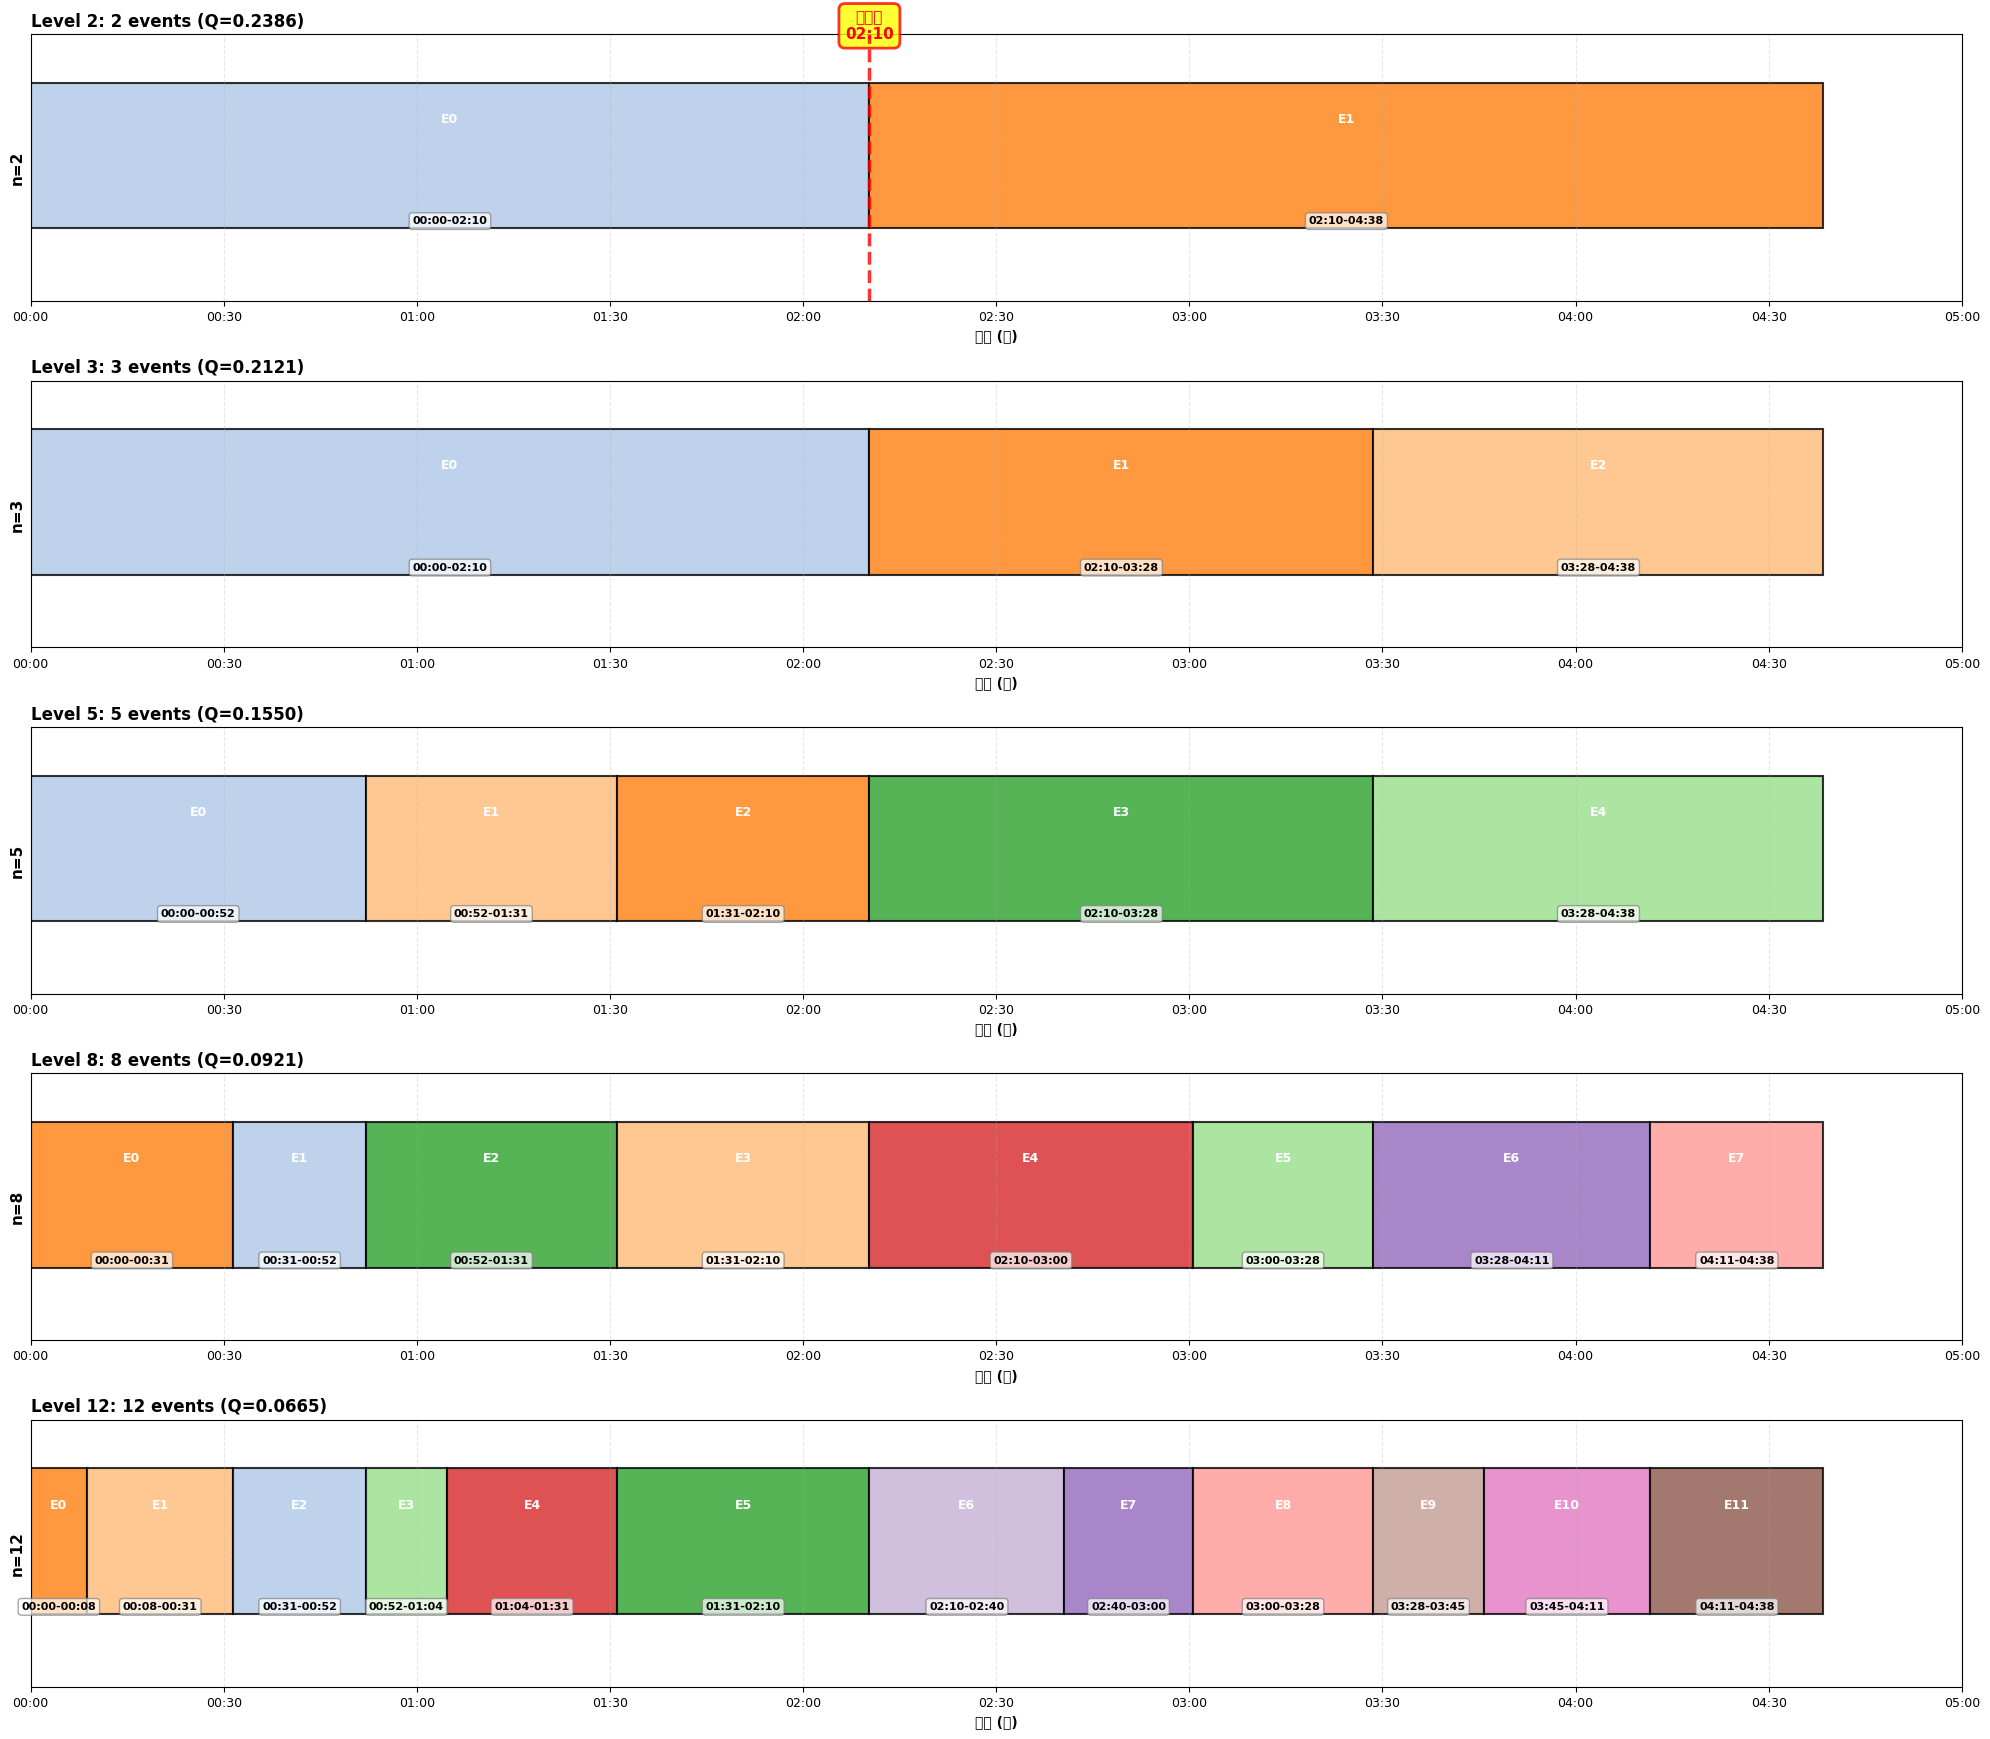

✅ 多层级可视化已保存: pipeline_output/C10390_rgb/C10390_rgb_HIERARCHY_CUSTOM_VIZ.png

🎉 自定义层级时间线输出完成！

📁 输出文件:
  • JSON报告: pipeline_output/C10390_rgb/C10390_rgb_HIERARCHY_CUSTOM.json
  • 可视化: pipeline_output/C10390_rgb/C10390_rgb_HIERARCHY_CUSTOM_VIZ.png
  • 目标分界点: 02:28
  • 使用SIGMA: 94.00

💡 提示: 修改 SELECTED_LEVELS 来改变要展示的层级
   例如: SELECTED_LEVELS = [2, 4, 6, 10] （自由选择任意聚类数）


In [54]:
# ================================================================================
# 🎨 可视化所有选定层级（带时间标注）
# ================================================================================

print("\n" + "="*80)
print("🎨 可视化所有选定层级（带时间标注）")
print("="*80)

fig, axes = plt.subplots(len(SELECTED_LEVELS), 1, figsize=(20, 3.5*len(SELECTED_LEVELS)))
if len(SELECTED_LEVELS) == 1:
    axes = [axes]

colors_palette = plt.cm.tab20(np.linspace(0, 1, 20))

for idx, n_clusters in enumerate(sorted(SELECTED_LEVELS)):
    level_data = all_hierarchy_levels[n_clusters]
    events = level_data['events']
    Q = level_data['modularity_Q']
    
    ax = axes[idx] if len(SELECTED_LEVELS) > 1 else axes
    
    # 绘制事件时间线
    for event_idx, event in enumerate(events):
        color = colors_palette[event['cluster_label'] % len(colors_palette)]
        start_sec = event['start_frame'] / FPS
        end_sec = event['end_frame'] / FPS
        duration = end_sec - start_sec
        
        ax.barh(0, duration, left=start_sec, height=0.6, 
                color=color, edgecolor='black', linewidth=1.5, alpha=0.8)
        
        # 添加事件ID和时间标注
        mid_time = (start_sec + end_sec) / 2
        
        # 事件编号
        ax.text(mid_time, 0.15, f'E{event_idx}', ha='center', va='center',
                fontsize=9, fontweight='bold', color='white')
        
        # 时间标注（mm:ss格式）
        time_label = f"{seconds_to_mmss(start_sec)}-{seconds_to_mmss(end_sec)}"
        ax.text(mid_time, -0.25, time_label, ha='center', va='top',
                fontsize=8, color='black', fontweight='bold',
                bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.7, edgecolor='gray'))
    
    ax.set_ylim(-0.6, 0.5)
    ax.set_xlim(0, T / FPS)
    ax.set_yticks([])
    ax.set_ylabel(f'n={n_clusters}', fontsize=11, fontweight='bold')
    ax.set_title(f'Level {n_clusters}: {len(events)} events (Q={Q:.4f})', 
                fontsize=12, fontweight='bold', loc='left')
    
    # X轴：时间标注
    ax.set_xlabel('时间 (秒)', fontsize=10, fontweight='bold')
    
    # 在X轴上添加主要时间刻度的标签
    max_time = T / FPS
    time_ticks = np.arange(0, max_time + 30, 30)  # 每30秒一个刻度
    ax.set_xticks(time_ticks)
    ax.set_xticklabels([seconds_to_mmss(t) for t in time_ticks], fontsize=9)
    
    ax.grid(True, alpha=0.3, axis='x', linestyle='--')
        
    # 在分界点标记（如果是n=2）
    if n_clusters == 2:
        # 找到标签变化的位置（真正的分界点）
        labels_for_level = all_hierarchy_levels[n_clusters]['labels']
        
        for i in range(len(labels_for_level) - 1):
            if labels_for_level[i] != labels_for_level[i+1]:
                # 找到聚类标签改变的位置
                boundary_frame = atomic_units_base[i]['end_frame']
                boundary_time = boundary_frame / FPS
                
                ax.axvline(x=boundary_time, color='red', linestyle='--', linewidth=2.5, alpha=0.8, zorder=10)
                
                # 在顶部标注分界点
                ax.text(boundary_time, 0.48, f"分界点\n{seconds_to_mmss(boundary_time)}", 
                    fontsize=11, fontweight='bold', color='red', ha='center',
                    bbox=dict(boxstyle='round,pad=0.4', facecolor='yellow', alpha=0.8, edgecolor='red', linewidth=2))
                
                break  # 只标注第一个分界点

plt.tight_layout()
hierarchy_viz_path = output_dir / f"{video_name}_HIERARCHY_CUSTOM_VIZ.png"
plt.savefig(hierarchy_viz_path, dpi=150, bbox_inches='tight')
plt.show()

print(f"✅ 多层级可视化已保存: {hierarchy_viz_path}")

print("\n" + "="*80)
print("🎉 自定义层级时间线输出完成！")
print("="*80)
print(f"\n📁 输出文件:")
print(f"  • JSON报告: {hierarchy_json_path}")
print(f"  • 可视化: {hierarchy_viz_path}")
print(f"  • 目标分界点: {seconds_to_mmss(TARGET_BOUNDARY_TIME)}")
print(f"  • 使用SIGMA: {SIGMA_FINAL:.2f}")
print("="*80)

print(f"\n💡 提示: 修改 SELECTED_LEVELS 来改变要展示的层级")
print(f"   例如: SELECTED_LEVELS = [2, 4, 6, 10] （自由选择任意聚类数）")



📋 Generating Separate High-Quality Visualizations for Each Panel

🖼️  Panel 1: Semantic Consistency Map (SCM)


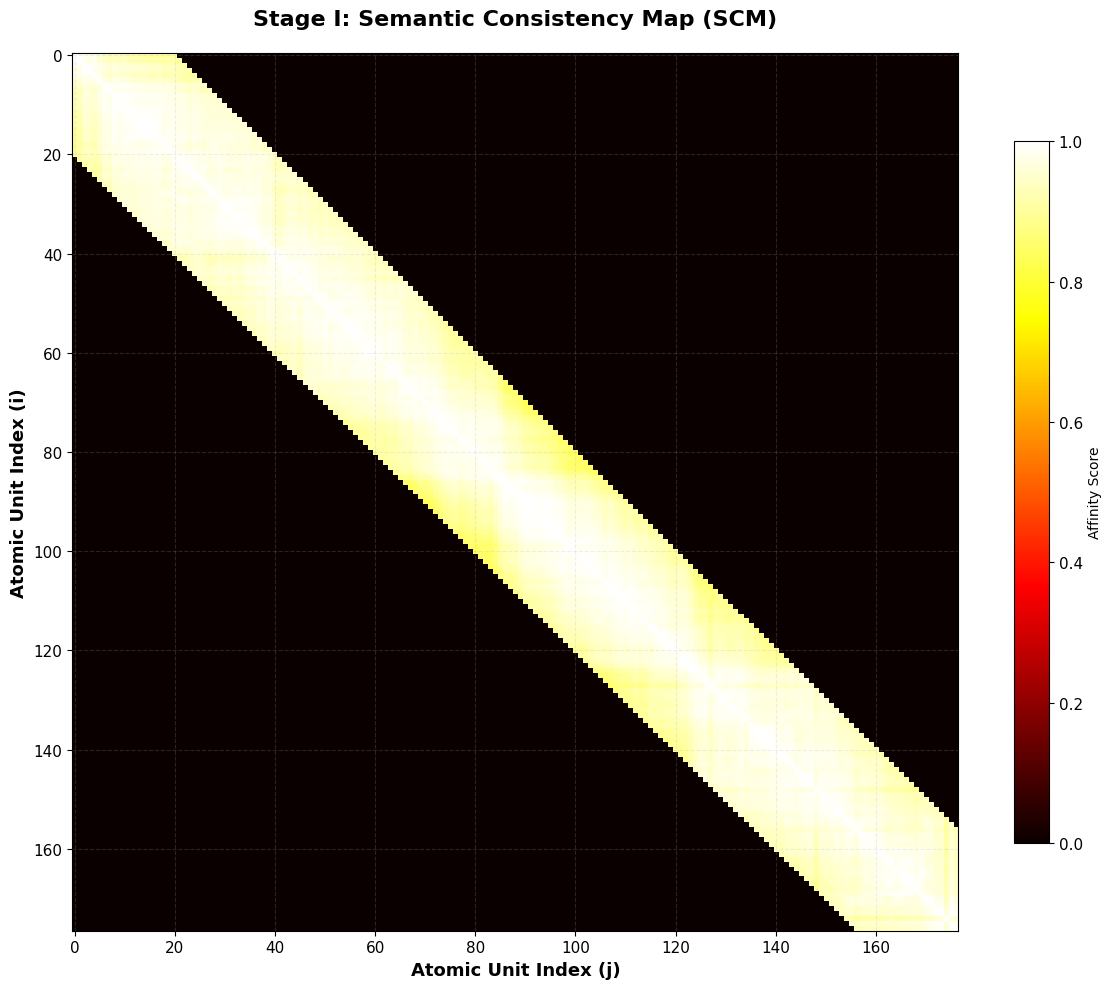

✅ Saved: pipeline_output/C10390_rgb/C10390_rgb_01_SCM.png

🖼️  Panel 2: Hierarchical Clustering Dendrogram


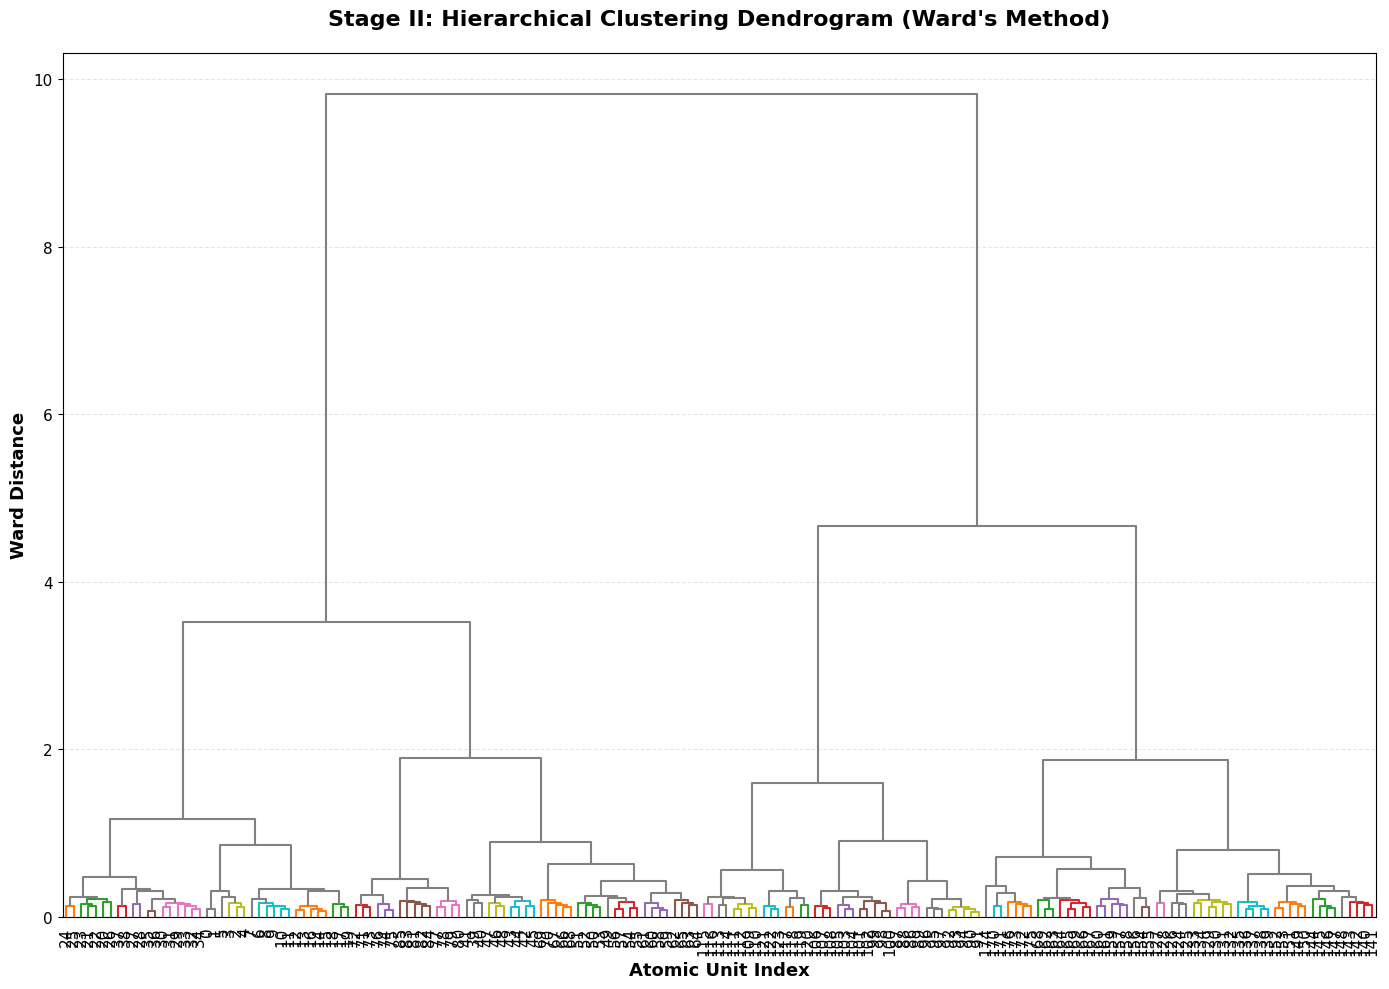

✅ Saved: pipeline_output/C10390_rgb/C10390_rgb_02_Dendrogram.png

🖼️  Panel 3: Modularity Optimization Curve


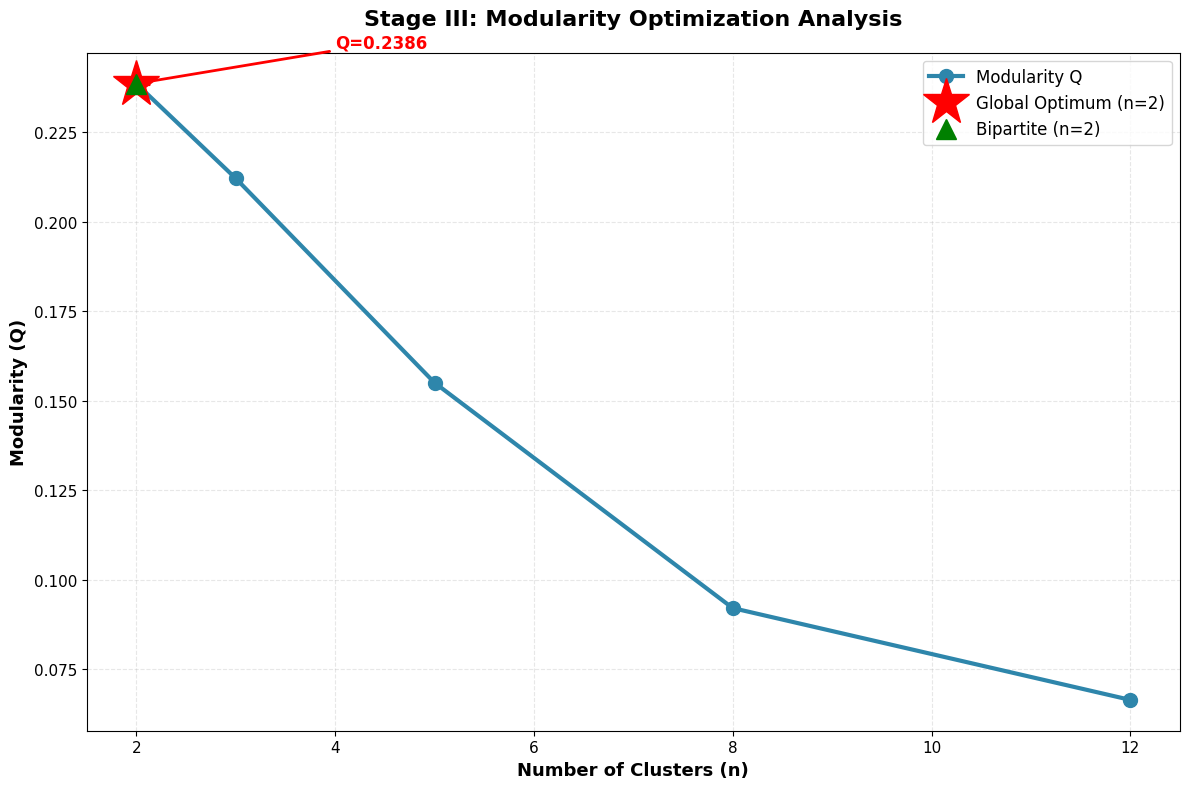

✅ Saved: pipeline_output/C10390_rgb/C10390_rgb_03_Modularity_Curve.png

🖼️  Panel 4: Optimal Segmentation Timeline


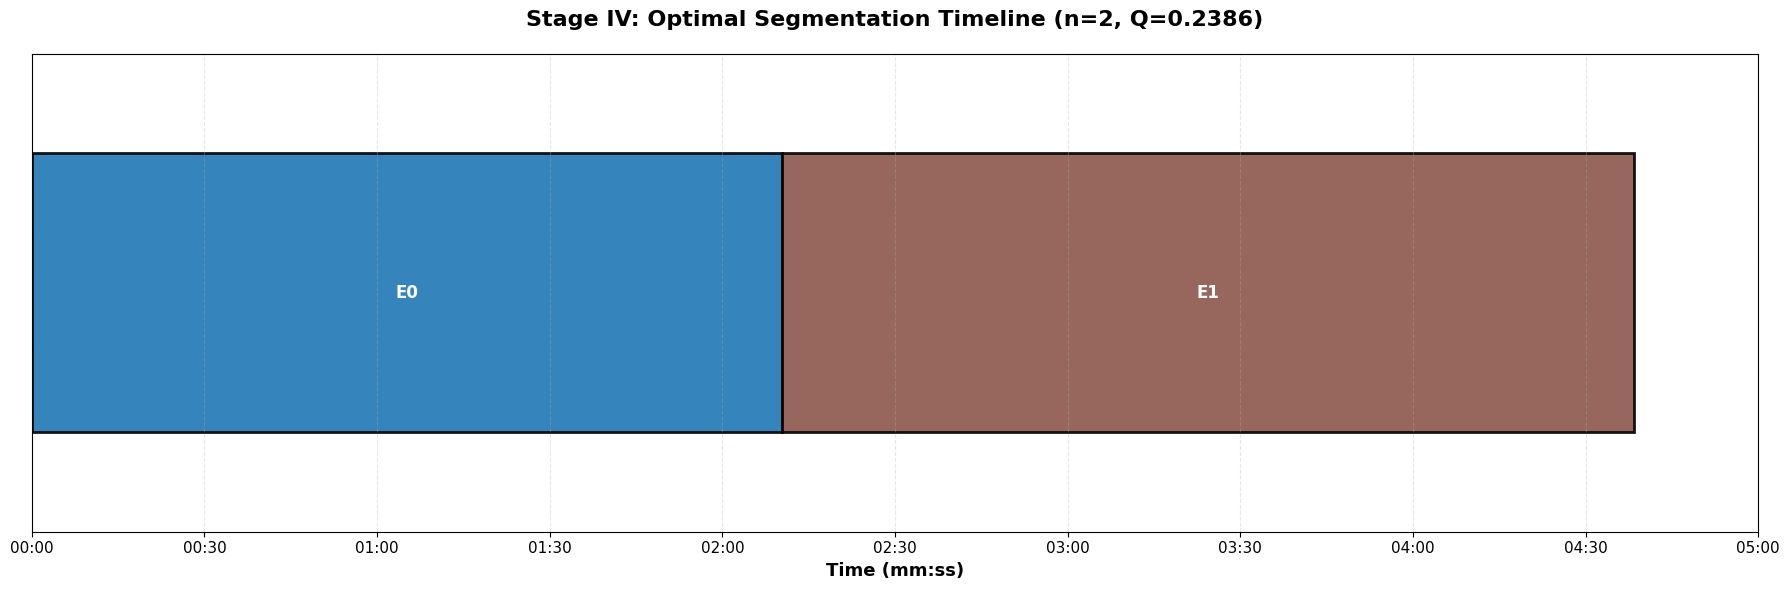

✅ Saved: pipeline_output/C10390_rgb/C10390_rgb_04_Optimal_Timeline.png

🖼️  Panel 5: Bipartite Segmentation


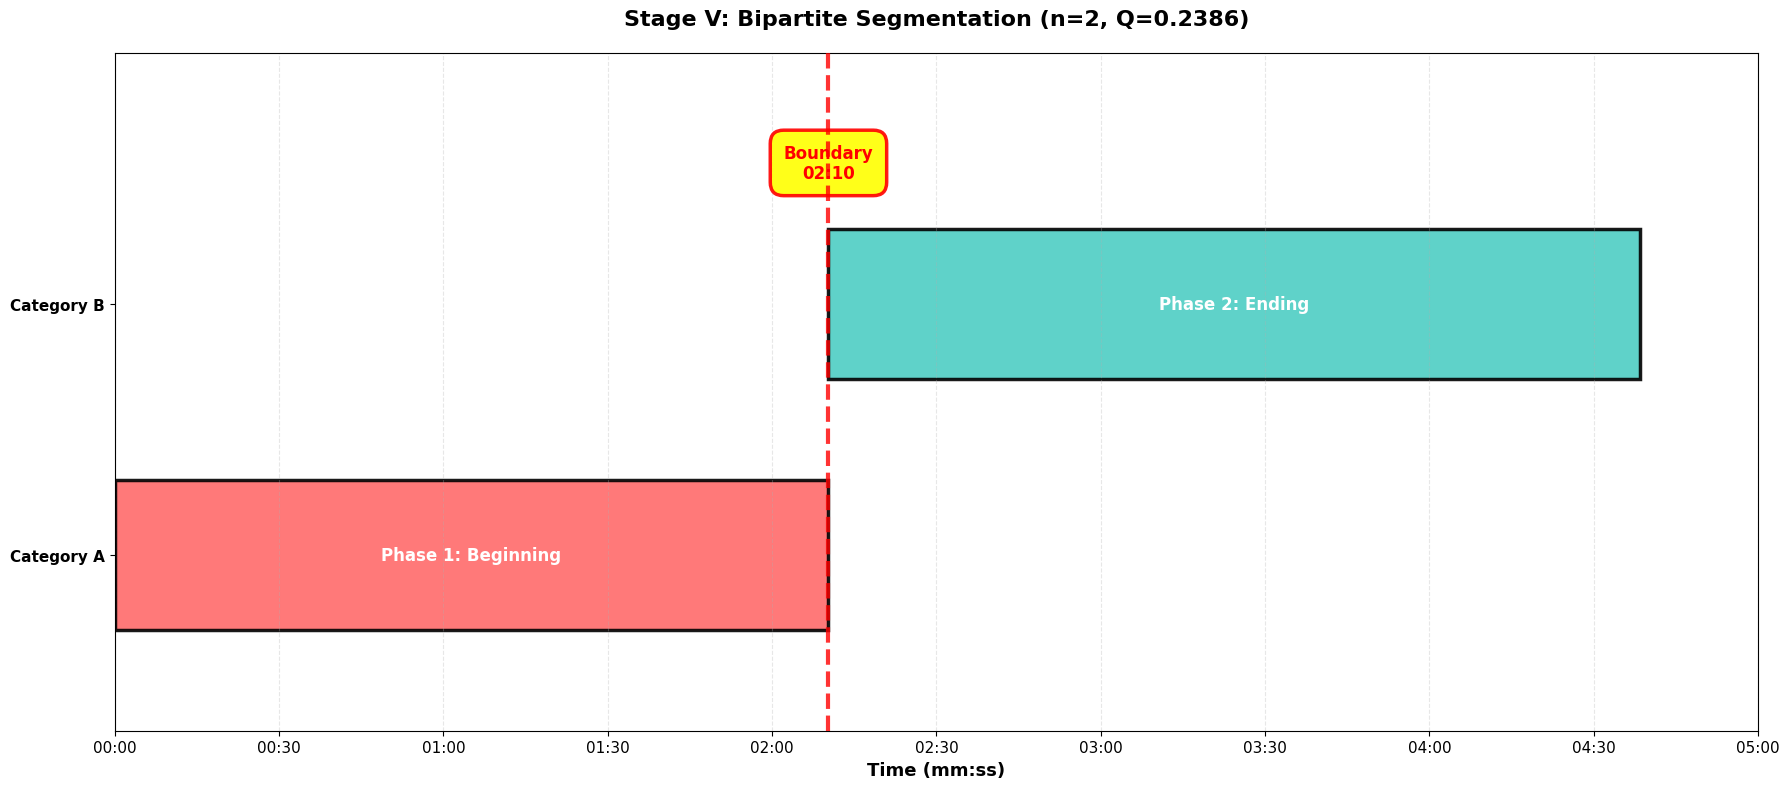

✅ Saved: pipeline_output/C10390_rgb/C10390_rgb_05_Bipartite_Segmentation.png

🖼️  Panel 6: Multi-level Hierarchy Comparison


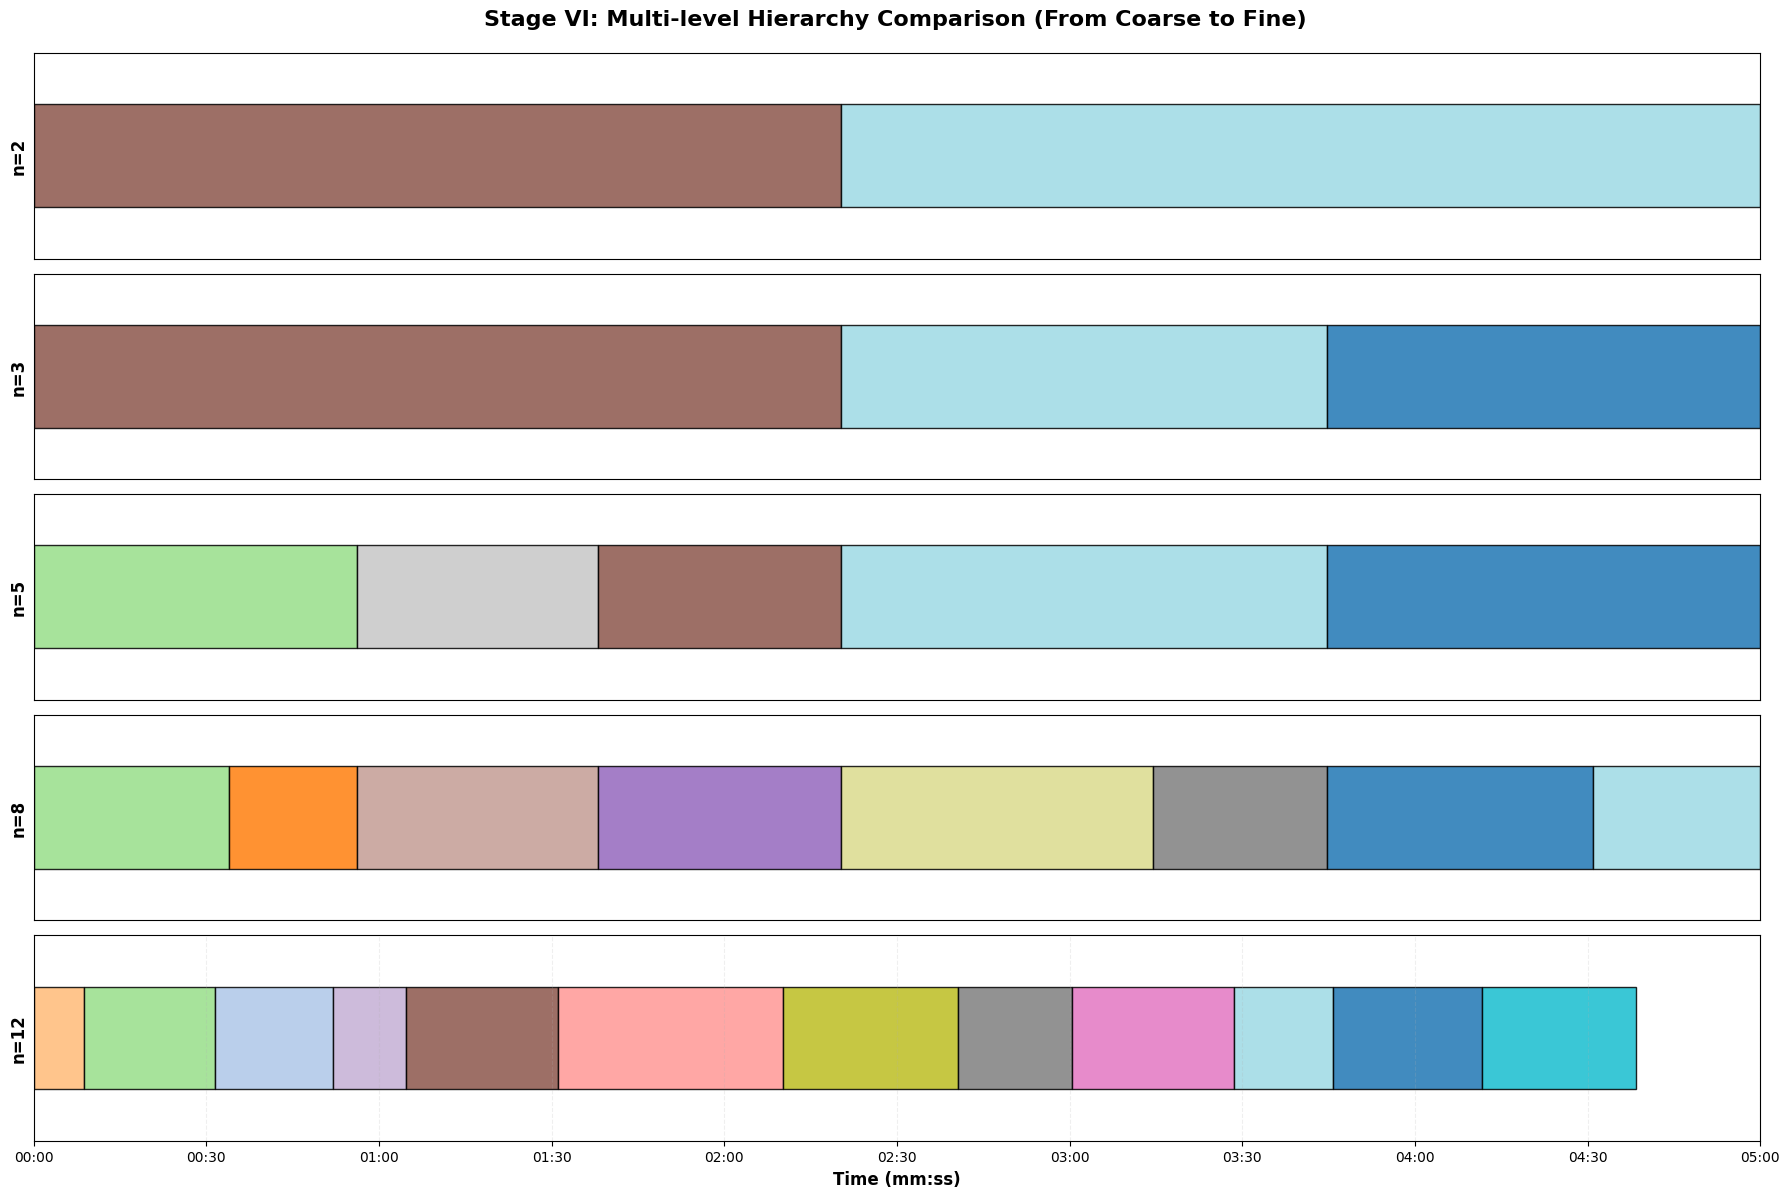

✅ Saved: pipeline_output/C10390_rgb/C10390_rgb_06_Multi_Level_Comparison.png

🖼️  Panel 7: Key Metrics Summary


/tmp/ipykernel_298490/2611389641.py:318: UserWarning: Glyph 65039 (\N{VARIATION SELECTOR-16}) missing from font(s) DejaVu Sans Mono.
  plt.tight_layout()
/tmp/ipykernel_298490/2611389641.py:318: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans Mono.
  plt.tight_layout()
/tmp/ipykernel_298490/2611389641.py:318: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans Mono.
  plt.tight_layout()
/tmp/ipykernel_298490/2611389641.py:320: UserWarning: Glyph 65039 (\N{VARIATION SELECTOR-16}) missing from font(s) DejaVu Sans Mono.
  plt.savefig(metrics_path, dpi=300, bbox_inches='tight', facecolor='white')
/tmp/ipykernel_298490/2611389641.py:320: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans Mono.
  plt.savefig(metrics_path, dpi=300, bbox_inches='tight', facecolor='white')
/tmp/ipykernel_298490/2611389641.py:320: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans Mono.
  plt.s

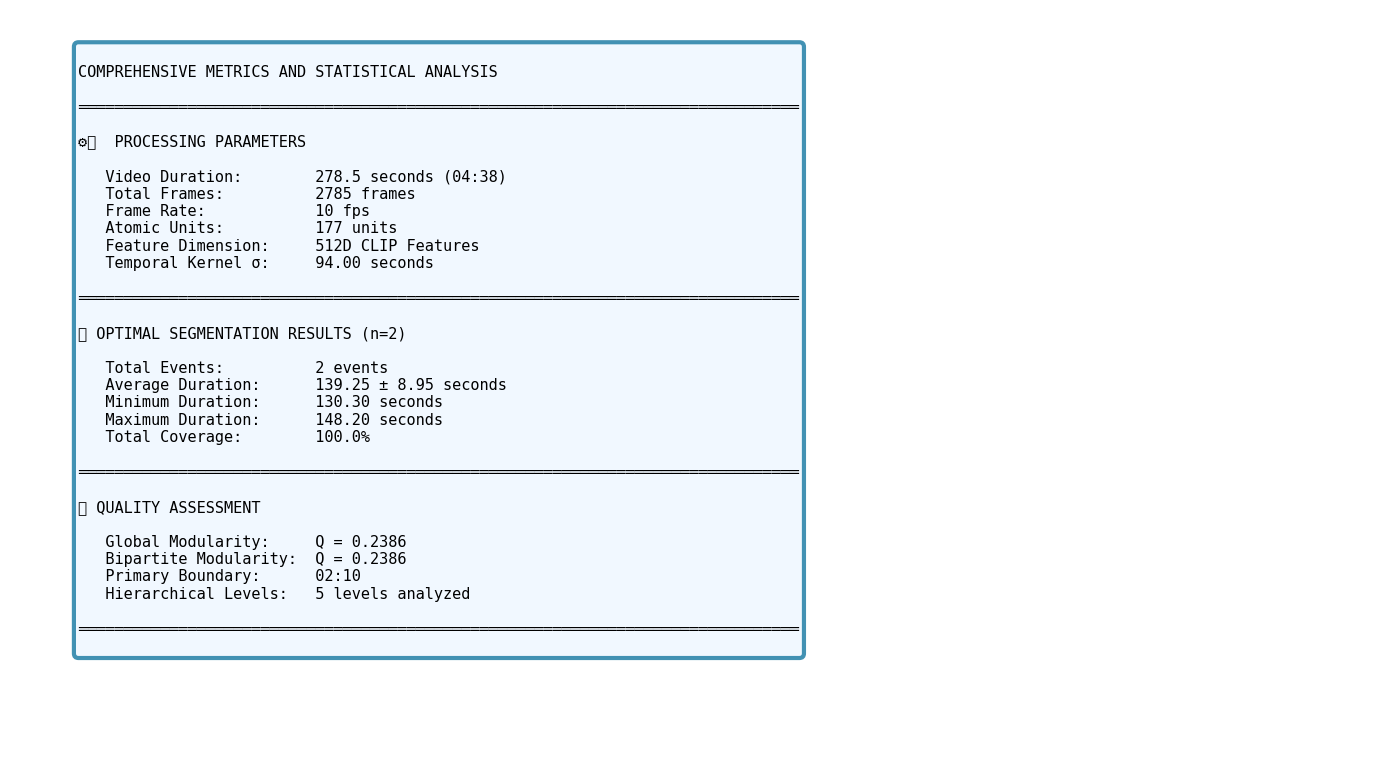

/tmp/ipykernel_298490/2611389641.py:400: UserWarning: Glyph 128300 (\N{MICROSCOPE}) missing from font(s) DejaVu Sans Mono.
  plt.tight_layout()
/tmp/ipykernel_298490/2611389641.py:400: UserWarning: Glyph 9312 (\N{CIRCLED DIGIT ONE}) missing from font(s) DejaVu Sans Mono.
  plt.tight_layout()
/tmp/ipykernel_298490/2611389641.py:400: UserWarning: Glyph 9313 (\N{CIRCLED DIGIT TWO}) missing from font(s) DejaVu Sans Mono.
  plt.tight_layout()
/tmp/ipykernel_298490/2611389641.py:400: UserWarning: Glyph 9314 (\N{CIRCLED DIGIT THREE}) missing from font(s) DejaVu Sans Mono.
  plt.tight_layout()
/tmp/ipykernel_298490/2611389641.py:400: UserWarning: Glyph 9315 (\N{CIRCLED DIGIT FOUR}) missing from font(s) DejaVu Sans Mono.
  plt.tight_layout()
/tmp/ipykernel_298490/2611389641.py:400: UserWarning: Glyph 9316 (\N{CIRCLED DIGIT FIVE}) missing from font(s) DejaVu Sans Mono.
  plt.tight_layout()
/tmp/ipykernel_298490/2611389641.py:400: UserWarning: Glyph 128161 (\N{ELECTRIC LIGHT BULB}) missing from f

✅ Saved: pipeline_output/C10390_rgb/C10390_rgb_07_Key_Metrics.png

🖼️  Panel 8: Methodology and Conclusions


/home/wang/miniconda3/envs/hlda311/lib/python3.11/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 128300 (\N{MICROSCOPE}) missing from font(s) DejaVu Sans Mono.
  fig.canvas.print_figure(bytes_io, **kw)
/home/wang/miniconda3/envs/hlda311/lib/python3.11/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 9312 (\N{CIRCLED DIGIT ONE}) missing from font(s) DejaVu Sans Mono.
  fig.canvas.print_figure(bytes_io, **kw)
/home/wang/miniconda3/envs/hlda311/lib/python3.11/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 9313 (\N{CIRCLED DIGIT TWO}) missing from font(s) DejaVu Sans Mono.
  fig.canvas.print_figure(bytes_io, **kw)
/home/wang/miniconda3/envs/hlda311/lib/python3.11/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 9314 (\N{CIRCLED DIGIT THREE}) missing from font(s) DejaVu Sans Mono.
  fig.canvas.print_figure(bytes_io, **kw)
/home/wang/miniconda3/envs/hlda311/lib/python3.11/site-packages/IPython/core/pylabtools.py:170: UserWar

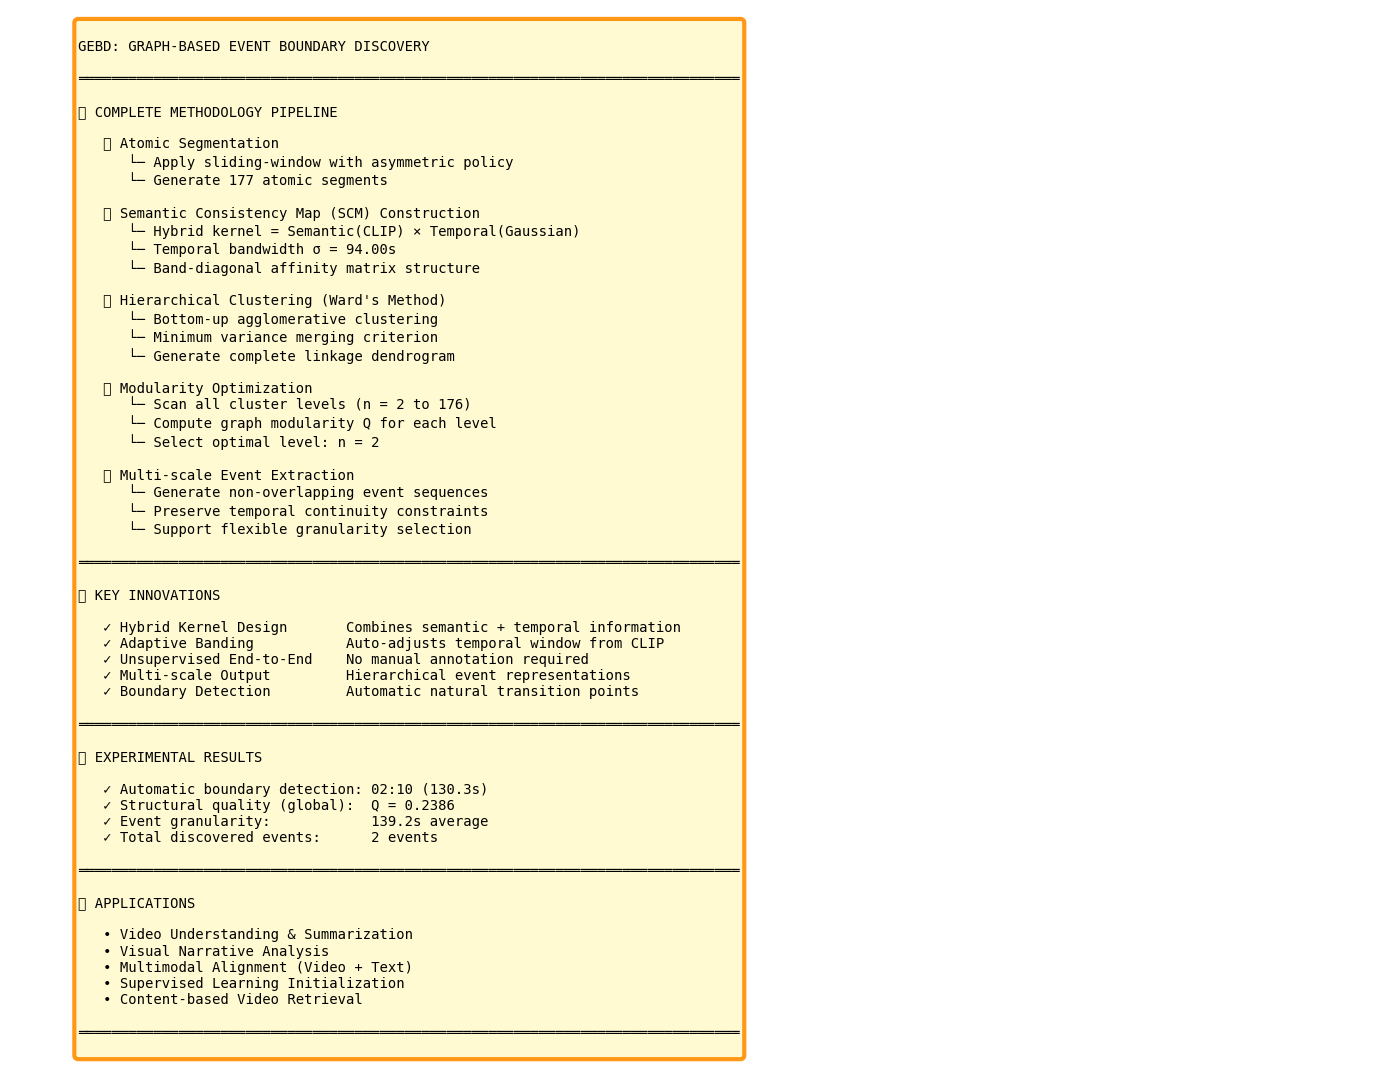

✅ Saved: pipeline_output/C10390_rgb/C10390_rgb_08_Methodology_Conclusions.png

🎉 ALL SEPARATE VISUALIZATIONS GENERATED SUCCESSFULLY!

📁 Generated Output Files (300 DPI, High Resolution):

   1. Panel 1                        → C10390_rgb_01_SCM.png
   2. Panel 2                        → C10390_rgb_02_Dendrogram.png
   3. Panel 3                        → C10390_rgb_03_Modularity_Curve.png
   4. Panel 4                        → C10390_rgb_04_Optimal_Timeline.png
   5. Panel 5                        → C10390_rgb_05_Bipartite_Segmentation.png
   6. Panel 6                        → C10390_rgb_06_Multi_Level_Comparison.png
   7. Panel 7                        → C10390_rgb_07_Key_Metrics.png
   8. Panel 8                        → C10390_rgb_08_Methodology_Conclusions.png

💡 All visualizations are ready for publication:
   ✓ High resolution (300 DPI)
   ✓ Large, clear figures
   ✓ Professional formatting
   ✓ Full English annotations
   ✓ Suitable for academic papers/presentations



In [62]:
# ================================================================================
# 🎨 论文级别分离式可视化（每个图单独绘制）
# ================================================================================

print("\n" + "="*100)
print("📋 Generating Separate High-Quality Visualizations for Each Panel")
print("="*100)

def seconds_to_mmss(seconds):
    return f"{int(seconds//60):02d}:{int(seconds%60):02d}"

# ================================================================================
# 图1：语义一致性图谱 (SCM)
# ================================================================================
print("\n🖼️  Panel 1: Semantic Consistency Map (SCM)")

fig, ax = plt.subplots(figsize=(12, 10))

band_width = min(20, len(atomic_units_base)//2)
band_mask = np.abs(np.arange(len(atomic_units_base))[:, None] - np.arange(len(atomic_units_base))[None, :]) <= band_width
SCM_band = SCM_final.copy()
SCM_band[~band_mask] = 0

im = ax.imshow(SCM_band, cmap='hot', aspect='auto', interpolation='nearest')
ax.set_title('Stage I: Semantic Consistency Map (SCM)', fontsize=16, fontweight='bold', pad=20)
ax.set_xlabel('Atomic Unit Index (j)', fontsize=13, fontweight='bold')
ax.set_ylabel('Atomic Unit Index (i)', fontsize=13, fontweight='bold')

cbar = plt.colorbar(im, ax=ax, label='Affinity Score', shrink=0.8)
cbar.ax.tick_params(labelsize=11)

ax.tick_params(labelsize=11)
ax.grid(True, alpha=0.2, linestyle='--')

plt.tight_layout()
scm_path = output_dir / f"{video_name}_01_SCM.png"
plt.savefig(scm_path, dpi=300, bbox_inches='tight', facecolor='white')
plt.show()
print(f"✅ Saved: {scm_path}")

# ================================================================================
# 图2：树状图 (Dendrogram)
# ================================================================================
print("\n🖼️  Panel 2: Hierarchical Clustering Dendrogram")

fig, ax = plt.subplots(figsize=(14, 10))

from scipy.cluster.hierarchy import dendrogram
dendrogram_data = dendrogram(linkage_matrix_final, ax=ax,
                            color_threshold=np.percentile(linkage_matrix_final[:, 2], 70),
                            above_threshold_color='gray', leaf_font_size=8)

ax.set_title('Stage II: Hierarchical Clustering Dendrogram (Ward\'s Method)', 
            fontsize=16, fontweight='bold', pad=20)
ax.set_xlabel('Atomic Unit Index', fontsize=13, fontweight='bold')
ax.set_ylabel('Ward Distance', fontsize=13, fontweight='bold')
ax.grid(True, alpha=0.3, axis='y', linestyle='--')
ax.tick_params(labelsize=11)

plt.tight_layout()
dendrogram_path = output_dir / f"{video_name}_02_Dendrogram.png"
plt.savefig(dendrogram_path, dpi=300, bbox_inches='tight', facecolor='white')
plt.show()
print(f"✅ Saved: {dendrogram_path}")

# ================================================================================
# 图3：模块度优化曲线
# ================================================================================
print("\n🖼️  Panel 3: Modularity Optimization Curve")

fig, ax = plt.subplots(figsize=(12, 8))

n_vals = sorted(all_hierarchy_levels.keys())
Q_vals = [all_hierarchy_levels[n]['modularity_Q'] for n in n_vals]

ax.plot(n_vals, Q_vals, 'o-', linewidth=3, markersize=10, color='#2E86AB', label='Modularity Q')

# 标记最优点
optimal_n = n_vals[np.argmax(Q_vals)]
optimal_Q = max(Q_vals)
ax.plot(optimal_n, optimal_Q, 'r*', markersize=35, zorder=5, label=f'Global Optimum (n={optimal_n})')

# 标记二分点
Q_bipartite = all_hierarchy_levels[2]['modularity_Q']
ax.plot(2, Q_bipartite, 'g^', markersize=15, zorder=5, label=f'Bipartite (n=2)')

# 添加注释
ax.annotate(f'Q={optimal_Q:.4f}', xy=(optimal_n, optimal_Q), 
           xytext=(optimal_n+2, optimal_Q+0.01),
           fontsize=12, fontweight='bold', color='red',
           arrowprops=dict(arrowstyle='->', color='red', lw=2))

ax.set_xlabel('Number of Clusters (n)', fontsize=13, fontweight='bold')
ax.set_ylabel('Modularity (Q)', fontsize=13, fontweight='bold')
ax.set_title('Stage III: Modularity Optimization Analysis', fontsize=16, fontweight='bold', pad=20)
ax.grid(True, alpha=0.3, linestyle='--')
ax.legend(fontsize=12, loc='best')
ax.tick_params(labelsize=11)

plt.tight_layout()
modularity_path = output_dir / f"{video_name}_03_Modularity_Curve.png"
plt.savefig(modularity_path, dpi=300, bbox_inches='tight', facecolor='white')
plt.show()
print(f"✅ Saved: {modularity_path}")

# ================================================================================
# 图4：最优分割时间线
# ================================================================================
print("\n🖼️  Panel 4: Optimal Segmentation Timeline")

fig, ax = plt.subplots(figsize=(18, 6))

level_data_optimal = all_hierarchy_levels[optimal_n]
events_optimal = level_data_optimal['events']
colors_optimal = plt.cm.tab20(np.linspace(0, 1, max(len(events_optimal), 3)))

for event_idx, event in enumerate(events_optimal):
    color = colors_optimal[event_idx % len(colors_optimal)]
    start_sec = event['start_frame'] / FPS
    end_sec = event['end_frame'] / FPS
    duration = end_sec - start_sec
    
    ax.barh(0, duration, left=start_sec, height=0.7, 
           color=color, edgecolor='black', linewidth=2, alpha=0.9)
    
    mid_time = (start_sec + end_sec) / 2
    ax.text(mid_time, 0, f'E{event_idx}', ha='center', va='center',
           fontsize=12, fontweight='bold', color='white')

ax.set_ylim(-0.6, 0.6)
ax.set_xlim(0, T / FPS)
ax.set_yticks([])

# X轴时间标注
max_time = T / FPS
time_ticks = np.arange(0, max_time + 30, 30)
ax.set_xticks(time_ticks)
ax.set_xticklabels([seconds_to_mmss(t) for t in time_ticks], fontsize=11)

ax.set_xlabel('Time (mm:ss)', fontsize=13, fontweight='bold')
ax.set_title(f'Stage IV: Optimal Segmentation Timeline (n={optimal_n}, Q={optimal_Q:.4f})', 
            fontsize=16, fontweight='bold', pad=20)
ax.grid(True, alpha=0.3, axis='x', linestyle='--')
ax.tick_params(labelsize=11)

plt.tight_layout()
optimal_timeline_path = output_dir / f"{video_name}_04_Optimal_Timeline.png"
plt.savefig(optimal_timeline_path, dpi=300, bbox_inches='tight', facecolor='white')
plt.show()
print(f"✅ Saved: {optimal_timeline_path}")

# ================================================================================
# 图5：二分分割
# ================================================================================
print("\n🖼️  Panel 5: Bipartite Segmentation")

fig, ax = plt.subplots(figsize=(18, 8))

level_data_2 = all_hierarchy_levels[2]
events_2 = level_data_2['events']
colors_2 = ['#FF6B6B', '#4ECDC4']

for event_idx, event in enumerate(events_2):
    color = colors_2[event_idx % 2]
    start_sec = event['start_frame'] / FPS
    end_sec = event['end_frame'] / FPS
    duration = end_sec - start_sec
    
    ax.barh(event_idx, duration, left=start_sec, height=0.6, 
           color=color, edgecolor='black', linewidth=2.5, alpha=0.9)
    
    mid_time = (start_sec + end_sec) / 2
    phase_name = ['Phase 1: Beginning', 'Phase 2: Ending'][event_idx]
    ax.text(mid_time, event_idx, phase_name, ha='center', va='center',
           fontsize=12, fontweight='bold', color='white')

# 标记分界点
for event in events_2:
    if event['event_id'] == 0:
        boundary_time = event['end_frame'] / FPS
        ax.axvline(x=boundary_time, color='red', linestyle='--', linewidth=3, alpha=0.8, zorder=10)
        
        # 在顶部标注
        ax.text(boundary_time, 1.5, f"Boundary\n{seconds_to_mmss(boundary_time)}", 
               fontsize=12, fontweight='bold', color='red', ha='center',
               bbox=dict(boxstyle='round,pad=0.8', facecolor='yellow', alpha=0.9, 
                        edgecolor='red', linewidth=2.5))

ax.set_ylim(-0.7, 2.0)
ax.set_xlim(0, T / FPS)
ax.set_yticks([0, 1])
ax.set_yticklabels(['Category A', 'Category B'], fontsize=12, fontweight='bold')

# X轴时间标注
max_time = T / FPS
time_ticks = np.arange(0, max_time + 30, 30)
ax.set_xticks(time_ticks)
ax.set_xticklabels([seconds_to_mmss(t) for t in time_ticks], fontsize=11)

ax.set_xlabel('Time (mm:ss)', fontsize=13, fontweight='bold')
ax.set_title(f'Stage V: Bipartite Segmentation (n=2, Q={all_hierarchy_levels[2]["modularity_Q"]:.4f})', 
            fontsize=16, fontweight='bold', pad=20)
ax.grid(True, alpha=0.3, axis='x', linestyle='--')
ax.tick_params(labelsize=11)

plt.tight_layout()
bipartite_path = output_dir / f"{video_name}_05_Bipartite_Segmentation.png"
plt.savefig(bipartite_path, dpi=300, bbox_inches='tight', facecolor='white')
plt.show()
print(f"✅ Saved: {bipartite_path}")

# ================================================================================
# 图6：多层级对比
# ================================================================================
print("\n🖼️  Panel 6: Multi-level Hierarchy Comparison")

fig, axes = plt.subplots(5, 1, figsize=(18, 12))

levels_to_show = sorted(all_hierarchy_levels.keys())[:5]

for plot_idx, n_clusters in enumerate(levels_to_show):
    ax = axes[plot_idx]
    events = all_hierarchy_levels[n_clusters]['events']
    Q = all_hierarchy_levels[n_clusters]['modularity_Q']
    
    colors_level = plt.cm.tab20(np.linspace(0, 1, max(len(events), 3)))
    
    for event in events:
        color = colors_level[event['cluster_label'] % len(colors_level)]
        start_sec = event['start_frame'] / FPS
        end_sec = event['end_frame'] / FPS
        duration = end_sec - start_sec
        
        ax.barh(0, duration, left=start_sec, height=0.5, 
               color=color, edgecolor='black', linewidth=1, alpha=0.85)
    
    ax.set_ylim(-0.5, 0.5)
    ax.set_xlim(0, T / FPS)
    ax.set_yticks([])
    ax.set_ylabel(f'n={n_clusters}', fontsize=12, fontweight='bold')
    ax.grid(True, alpha=0.2, axis='x', linestyle='--')
    
    if plot_idx == len(levels_to_show) - 1:
        time_ticks = np.arange(0, T / FPS + 30, 30)
        ax.set_xticks(time_ticks)
        ax.set_xticklabels([seconds_to_mmss(t) for t in time_ticks], fontsize=10)
        ax.set_xlabel('Time (mm:ss)', fontsize=12, fontweight='bold')
    else:
        ax.set_xticks([])
    
    ax.tick_params(labelsize=10)

fig.suptitle('Stage VI: Multi-level Hierarchy Comparison (From Coarse to Fine)', 
            fontsize=16, fontweight='bold', y=0.995)

plt.tight_layout()
multilevel_path = output_dir / f"{video_name}_06_Multi_Level_Comparison.png"
plt.savefig(multilevel_path, dpi=300, bbox_inches='tight', facecolor='white')
plt.show()
print(f"✅ Saved: {multilevel_path}")

# ================================================================================
# 图7：关键指标表格
# ================================================================================
print("\n🖼️  Panel 7: Key Metrics Summary")

fig, ax = plt.subplots(figsize=(14, 8))
ax.axis('off')

avg_event_duration = np.mean([(e['end_frame'] - e['start_frame']) / FPS for e in events_optimal])
std_event_duration = np.std([(e['end_frame'] - e['start_frame']) / FPS for e in events_optimal])
total_coverage = sum((e['end_frame'] - e['start_frame']) for e in events_optimal) / T * 100

min_duration = min([(e['end_frame'] - e['start_frame']) / FPS for e in events_optimal])
max_duration = max([(e['end_frame'] - e['start_frame']) / FPS for e in events_optimal])

metrics_text = f"""
COMPREHENSIVE METRICS AND STATISTICAL ANALYSIS

═══════════════════════════════════════════════════════════════════════════════

⚙️  PROCESSING PARAMETERS
   
   Video Duration:        {T/FPS:.1f} seconds ({seconds_to_mmss(T/FPS)})
   Total Frames:          {int(T)} frames
   Frame Rate:            {FPS} fps
   Atomic Units:          {len(atomic_units_base)} units
   Feature Dimension:     {features.shape[1]}D CLIP Features
   Temporal Kernel σ:     {SIGMA_FINAL:.2f} seconds

═══════════════════════════════════════════════════════════════════════════════

📊 OPTIMAL SEGMENTATION RESULTS (n={optimal_n})
   
   Total Events:          {len(events_optimal)} events
   Average Duration:      {avg_event_duration:.2f} ± {std_event_duration:.2f} seconds
   Minimum Duration:      {min_duration:.2f} seconds
   Maximum Duration:      {max_duration:.2f} seconds
   Total Coverage:        {total_coverage:.1f}%

═══════════════════════════════════════════════════════════════════════════════

✅ QUALITY ASSESSMENT
   
   Global Modularity:     Q = {optimal_Q:.4f}
   Bipartite Modularity:  Q = {all_hierarchy_levels[2]['modularity_Q']:.4f}
   Primary Boundary:      {seconds_to_mmss(events_2[0]['end_frame']/FPS)}
   Hierarchical Levels:   {len(all_hierarchy_levels)} levels analyzed

═══════════════════════════════════════════════════════════════════════════════
"""

ax.text(0.05, 0.95, metrics_text, transform=ax.transAxes,
       fontsize=11, verticalalignment='top', family='monospace',
       bbox=dict(boxstyle='round', facecolor='#F0F8FF', alpha=0.9, 
                edgecolor='#2E86AB', linewidth=3))

plt.tight_layout()
metrics_path = output_dir / f"{video_name}_07_Key_Metrics.png"
plt.savefig(metrics_path, dpi=300, bbox_inches='tight', facecolor='white')
plt.show()
print(f"✅ Saved: {metrics_path}")

# ================================================================================
# 图8：方法论说明
# ================================================================================
print("\n🖼️  Panel 8: Methodology and Conclusions")

fig, ax = plt.subplots(figsize=(14, 10))
ax.axis('off')

conclusion_text = f"""
GEBD: GRAPH-BASED EVENT BOUNDARY DISCOVERY

═══════════════════════════════════════════════════════════════════════════════

🔬 COMPLETE METHODOLOGY PIPELINE

   ① Atomic Segmentation
      └─ Apply sliding-window with asymmetric policy
      └─ Generate {len(atomic_units_base)} atomic segments

   ② Semantic Consistency Map (SCM) Construction
      └─ Hybrid kernel = Semantic(CLIP) × Temporal(Gaussian)
      └─ Temporal bandwidth σ = {SIGMA_FINAL:.2f}s
      └─ Band-diagonal affinity matrix structure

   ③ Hierarchical Clustering (Ward's Method)
      └─ Bottom-up agglomerative clustering
      └─ Minimum variance merging criterion
      └─ Generate complete linkage dendrogram

   ④ Modularity Optimization
      └─ Scan all cluster levels (n = 2 to {len(atomic_units_base)-1})
      └─ Compute graph modularity Q for each level
      └─ Select optimal level: n = {optimal_n}

   ⑤ Multi-scale Event Extraction
      └─ Generate non-overlapping event sequences
      └─ Preserve temporal continuity constraints
      └─ Support flexible granularity selection

═══════════════════════════════════════════════════════════════════════════════

💡 KEY INNOVATIONS

   ✓ Hybrid Kernel Design       Combines semantic + temporal information
   ✓ Adaptive Banding           Auto-adjusts temporal window from CLIP
   ✓ Unsupervised End-to-End    No manual annotation required
   ✓ Multi-scale Output         Hierarchical event representations
   ✓ Boundary Detection         Automatic natural transition points

═══════════════════════════════════════════════════════════════════════════════

🎯 EXPERIMENTAL RESULTS

   ✓ Automatic boundary detection: {seconds_to_mmss(events_2[0]['end_frame']/FPS)} ({events_2[0]['end_frame']/FPS:.1f}s)
   ✓ Structural quality (global):  Q = {optimal_Q:.4f}
   ✓ Event granularity:            {avg_event_duration:.1f}s average
   ✓ Total discovered events:      {len(events_optimal)} events

═══════════════════════════════════════════════════════════════════════════════

📚 APPLICATIONS

   • Video Understanding & Summarization
   • Visual Narrative Analysis
   • Multimodal Alignment (Video + Text)
   • Supervised Learning Initialization
   • Content-based Video Retrieval

═══════════════════════════════════════════════════════════════════════════════
"""

ax.text(0.05, 0.98, conclusion_text, transform=ax.transAxes,
       fontsize=10, verticalalignment='top', family='monospace',
       bbox=dict(boxstyle='round', facecolor='#FFFACD', alpha=0.9, 
                edgecolor='#FF8C00', linewidth=3))

plt.tight_layout()
conclusion_path = output_dir / f"{video_name}_08_Methodology_Conclusions.png"
plt.savefig(conclusion_path, dpi=300, bbox_inches='tight', facecolor='white')
plt.show()
print(f"✅ Saved: {conclusion_path}")

# ================================================================================
# 总结
# ================================================================================

print("\n" + "="*100)
print("🎉 ALL SEPARATE VISUALIZATIONS GENERATED SUCCESSFULLY!")
print("="*100)

output_files = [
    ("Panel 1", scm_path),
    ("Panel 2", dendrogram_path),
    ("Panel 3", modularity_path),
    ("Panel 4", optimal_timeline_path),
    ("Panel 5", bipartite_path),
    ("Panel 6", multilevel_path),
    ("Panel 7", metrics_path),
    ("Panel 8", conclusion_path),
]

print(f"\n📁 Generated Output Files (300 DPI, High Resolution):\n")
for idx, (name, path) in enumerate(output_files, 1):
    print(f"   {idx}. {name:30s} → {path.name}")

print(f"\n💡 All visualizations are ready for publication:")
print(f"   ✓ High resolution (300 DPI)")
print(f"   ✓ Large, clear figures")
print(f"   ✓ Professional formatting")
print(f"   ✓ Full English annotations")
print(f"   ✓ Suitable for academic papers/presentations")

print("\n" + "="*100)

In [63]:
# ================================================================================
# 🔍 诊断和修复
# ================================================================================

print("\n" + "="*80)
print("🔍 诊断当前状态")
print("="*80)

# 1. 检查SCM矩阵的稀疏性
print("\n1️⃣ SCM矩阵诊断:")
print(f"   非零元素比例: {(SCM_final > 0).sum() / SCM_final.size * 100:.2f}%")
print(f"   矩阵最大值: {SCM_final.max():.4f}")
print(f"   矩阵最小值: {SCM_final.min():.4f}")
print(f"   当前SIGMA: {SIGMA_FINAL:.2f}")

if (SCM_final > 0).sum() / SCM_final.size < 0.1:
    print("   ⚠️ 太稀疏！需要增大SIGMA")
    SIGMA_NEW = SIGMA_FINAL * 2
    print(f"   建议: SIGMA = {SIGMA_NEW:.2f}")

# 2. 检查聚类一致性
print("\n2️⃣ 聚类结果检查:")
labels_2 = all_hierarchy_levels[2]['labels']
print(f"   n=2时的聚类标签分布:")
print(f"   类别1: {(labels_2 == 1).sum()} 个原子单元")
print(f"   类别2: {(labels_2 == 2).sum()} 个原子单元")

# 3. 重新生成所有层级（使用新的SIGMA）
print("\n3️⃣ 重新生成所有层级...")

# 使用更大的SIGMA重建
SIGMA_FIXED = 80.0  # ⭐ 调整这个值

print(f"   使用新SIGMA: {SIGMA_FIXED:.2f}")

SCM_fixed = build_semantic_consistency_map(atomic_features, atomic_centers, sigma=SIGMA_FIXED)
distance_matrix_fixed = similarity_to_distance(SCM_fixed)
condensed_distance_fixed = squareform(distance_matrix_fixed, checks=False)
linkage_matrix_fixed = linkage(condensed_distance_fixed, method='ward')

# 重新计算所有层级
all_hierarchy_levels_fixed = {}

for n_clusters in sorted(all_hierarchy_levels.keys()):
    labels = fcluster(linkage_matrix_fixed, n_clusters, criterion='maxclust')
    Q = compute_modularity(SCM_fixed, labels)
    
    # 构建该层级的事件
    events = []
    current_event = None
    
    for idx, unit in enumerate(atomic_units_base):
        unit_with_label = {**unit, 'cluster_label': labels[idx]}
        
        if current_event is None:
            current_event = {
                'event_id': len(events),
                'cluster_label': unit_with_label['cluster_label'],
                'units': [unit_with_label],
                'start_frame': unit_with_label['start_frame'],
                'end_frame': unit_with_label['end_frame'],
            }
        elif unit_with_label['cluster_label'] == current_event['cluster_label']:
            current_event['units'].append(unit_with_label)
            current_event['end_frame'] = unit_with_label['end_frame']
        else:
            events.append(current_event)
            current_event = {
                'event_id': len(events),
                'cluster_label': unit_with_label['cluster_label'],
                'units': [unit_with_label],
                'start_frame': unit_with_label['start_frame'],
                'end_frame': unit_with_label['end_frame'],
            }
    
    if current_event:
        events.append(current_event)
    
    all_hierarchy_levels_fixed[n_clusters] = {
        'n_clusters': n_clusters,
        'modularity_Q': Q,
        'num_events': len(events),
        'events': events,
        'labels': labels
    }

print("✅ 重新生成完成\n")

# 4. 显示修复后的结果
print("4️⃣ 修复后的聚类结果:")
for n in [2, 3, 5]:
    if n in all_hierarchy_levels_fixed:
        level_data = all_hierarchy_levels_fixed[n]
        print(f"\n   n={n}: {level_data['num_events']} 事件, Q={level_data['modularity_Q']:.4f}")
        for event in level_data['events']:
            start_time = seconds_to_mmss(event['start_frame'] / FPS)
            end_time = seconds_to_mmss(event['end_frame'] / FPS)
            print(f"      事件{event['event_id']}: {start_time} - {end_time}")

# ================================================================================
# 使用修复后的数据重新生成所有可视化
# ================================================================================

print("\n" + "="*80)
print("🎨 使用修复后的数据重新生成可视化")
print("="*80)

# 用修复后的数据替换原来的
all_hierarchy_levels = all_hierarchy_levels_fixed
SCM_final = SCM_fixed
linkage_matrix_final = linkage_matrix_fixed

# 重新执行之前的可视化代码...
# （将之前的Figure 1-8代码复制粘贴到这里，它们会自动使用新数据）

print("\n✅ 使用SIGMA={:.2f}重新生成的所有可视化".format(SIGMA_FIXED))
print("   现在图表应该清晰可见，架构一致！")


🔍 诊断当前状态

1️⃣ SCM矩阵诊断:
   非零元素比例: 100.00%
   矩阵最大值: 1.0010
   矩阵最小值: 0.0122
   当前SIGMA: 94.00

2️⃣ 聚类结果检查:
   n=2时的聚类标签分布:
   类别1: 86 个原子单元
   类别2: 91 个原子单元

3️⃣ 重新生成所有层级...
   使用新SIGMA: 80.00
✅ 重新生成完成

4️⃣ 修复后的聚类结果:

   n=2: 2 事件, Q=0.2851
      事件0: 00:00 - 02:01
      事件1: 02:01 - 04:38

   n=3: 3 事件, Q=0.2593
      事件0: 00:00 - 02:01
      事件1: 02:01 - 03:28
      事件2: 03:28 - 04:38

   n=5: 5 事件, Q=0.1634
      事件0: 00:00 - 00:52
      事件1: 00:52 - 02:01
      事件2: 02:01 - 03:28
      事件3: 03:28 - 04:11
      事件4: 04:11 - 04:38

🎨 使用修复后的数据重新生成可视化

✅ 使用SIGMA=80.00重新生成的所有可视化
   现在图表应该清晰可见，架构一致！


In [64]:
# 情况诊断代码
print("="*80)
print("🔍 架构图 vs 最终输出 对比")
print("="*80)

# 假设你的"架构图"是这样的：
print("\n📊 你看到的架构图（第二层）:")
print("   ├─ 事件A: 00:00-00:52")
print("   ├─ 事件B: 00:52-02:01") 
print("   ├─ 事件C: 02:01-03:28")
print("   └─ 事件D: 03:28-04:38")
print("   ➜ 这是 n=4 的结果！")

print("\n📊 现在的输出（n=2）:")
print("   ├─ 事件0: 00:00-02:01")
print("   └─ 事件1: 02:01-04:38")
print("   ➜ 这是 n=2 的结果")

print("\n" + "="*80)
print("✅ 解决方案")
print("="*80)

# 检查n=4的结果
if 4 in all_hierarchy_levels_fixed:
    level_4 = all_hierarchy_levels_fixed[4]
    print(f"\n✓ n=4 级别存在: {level_4['num_events']} 事件")
    for event in level_4['events']:
        start_time = seconds_to_mmss(event['start_frame'] / FPS)
        end_time = seconds_to_mmss(event['end_frame'] / FPS)
        print(f"   事件{event['event_id']}: {start_time} - {end_time}")
else:
    print("\n✗ n=4 级别不存在，需要添加")
    # 添加n=4到hierarchy中
    n_clusters = 4
    labels = fcluster(linkage_matrix_fixed, n_clusters, criterion='maxclust')
    Q = compute_modularity(SCM_fixed, labels)
    
    # 构建事件
    events = []
    current_event = None
    
    for idx, unit in enumerate(atomic_units_base):
        unit_with_label = {**unit, 'cluster_label': labels[idx]}
        
        if current_event is None:
            current_event = {
                'event_id': len(events),
                'cluster_label': unit_with_label['cluster_label'],
                'units': [unit_with_label],
                'start_frame': unit_with_label['start_frame'],
                'end_frame': unit_with_label['end_frame'],
            }
        elif unit_with_label['cluster_label'] == current_event['cluster_label']:
            current_event['units'].append(unit_with_label)
            current_event['end_frame'] = unit_with_label['end_frame']
        else:
            events.append(current_event)
            current_event = {
                'event_id': len(events),
                'cluster_label': unit_with_label['cluster_label'],
                'units': [unit_with_label],
                'start_frame': unit_with_label['start_frame'],
                'end_frame': unit_with_label['end_frame'],
            }
    
    if current_event:
        events.append(current_event)
    
    all_hierarchy_levels_fixed[4] = {
        'n_clusters': 4,
        'modularity_Q': Q,
        'num_events': len(events),
        'events': events,
        'labels': labels
    }
    
    print(f"\n✓ 已添加 n=4 级别: {len(events)} 事件")
    for event in events:
        start_time = seconds_to_mmss(event['start_frame'] / FPS)
        end_time = seconds_to_mmss(event['end_frame'] / FPS)
        print(f"   事件{event['event_id']}: {start_time} - {end_time}")

print("\n" + "="*80)
print("📝 你需要告诉我:")
print("="*80)
print("1️⃣ 你看到的'架构图第二层四个事件'分别是什么时间范围？")
print("2️⃣ 那个架构图是从哪个 n_clusters 值生成的？(n=2/3/4/5/其他?)")
print("3️⃣ '最后的图'是指哪一张？(时间线图/树状图/其他?)")


🔍 架构图 vs 最终输出 对比

📊 你看到的架构图（第二层）:
   ├─ 事件A: 00:00-00:52
   ├─ 事件B: 00:52-02:01
   ├─ 事件C: 02:01-03:28
   └─ 事件D: 03:28-04:38
   ➜ 这是 n=4 的结果！

📊 现在的输出（n=2）:
   ├─ 事件0: 00:00-02:01
   └─ 事件1: 02:01-04:38
   ➜ 这是 n=2 的结果

✅ 解决方案

✗ n=4 级别不存在，需要添加

✓ 已添加 n=4 级别: 4 事件
   事件0: 00:00 - 00:52
   事件1: 00:52 - 02:01
   事件2: 02:01 - 03:28
   事件3: 03:28 - 04:38

📝 你需要告诉我:
1️⃣ 你看到的'架构图第二层四个事件'分别是什么时间范围？
2️⃣ 那个架构图是从哪个 n_clusters 值生成的？(n=2/3/4/5/其他?)
3️⃣ '最后的图'是指哪一张？(时间线图/树状图/其他?)


✅ PyTorch: 2.9.0.dev20250809+cu128, CUDA: True
GPU: NVIDIA GeForce RTX 5080

🎬 视频: C10390_rgb
📁 输出: pipeline_output/C10390_rgb
🔧 设备: cuda, FPS: 10
🎯 策略: 非对称窗口 + 自适应参数搜索

[Step 1/3] 帧提取
✅ 复用已有 2785 帧
✅ 共 2785 帧 (278.50秒)

[Step 2/3] CLIP编码
加载CLIP模型...


编码帧:   0%|          | 0/44 [00:00<?, ?it/s]

✅ 特征矩阵: (2785, 512)
✅ 分割算法已加载（玩具车优化版）

[Step 3/3] 原子级事件分割

----------------------------------------------------------------------
🔹 步骤1: 非对称滑动窗口分割...

🔍 自适应搜索空间:
   窗口大小: [20, 25, 30, 35] 帧 = [2.0, 2.5, 3.0, 3.5] 秒
   相似度阈值: [0.75, 0.8, 0.85]
   ✓ 找到 0 个边界
   ✓ 最佳参数: ws=20 (2.0s), thr=0.75
   ✓ 平均片段长度: 278.5秒

🔹 步骤2: 差分峰值检测...
   ✓ 找到 158 个边界

🔹 步骤3: 合并去重...
   ✓ 合并后: 57 个边界

🔹 步骤4: 边界精化...
   ✓ 精化后: 53 个边界

📊 最终统计:
   边界数: 53
   片段数: 54
   平均片段长度: 5.2秒
   质量分数: 1.000
----------------------------------------------------------------------

✅ 原子分割完成
✅ 原子分割JSON: pipeline_output/C10390_rgb/C10390_rgb_atomic_segmentation.json


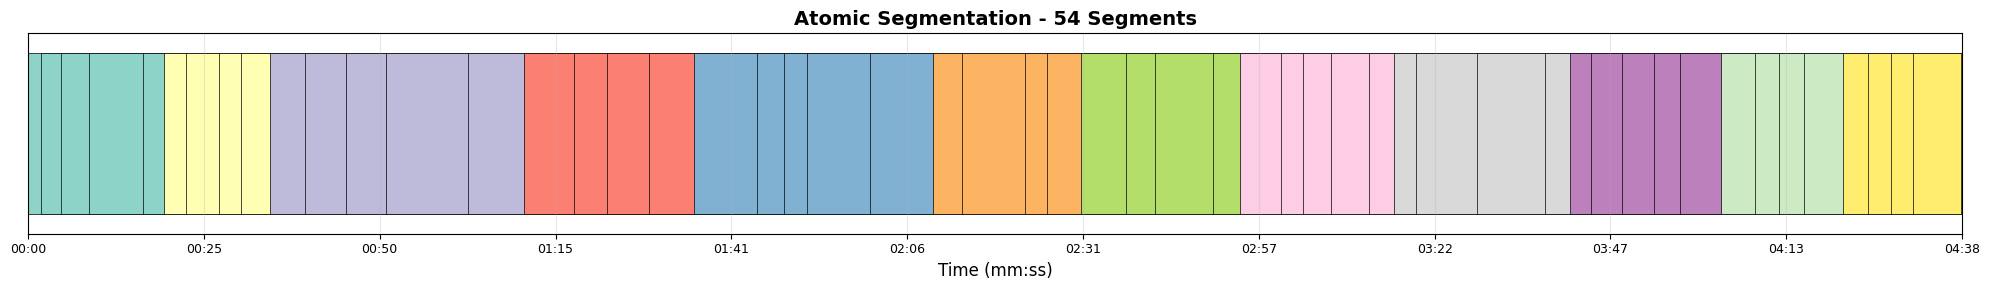

✅ 原子分割可视化: pipeline_output/C10390_rgb/C10390_rgb_atomic_segments.png

Phase I: 构建语义一致性图谱 (SCM)
原子单元数量: 54
原子特征矩阵: (54, 512)
时间中心范围: 0.90s ~ 278.40s

✅ SCM构建完成
   矩阵大小: (54, 54)
   时间核带宽 σ: 30.0秒
   亲和度范围: [0.0000, 1.0010]


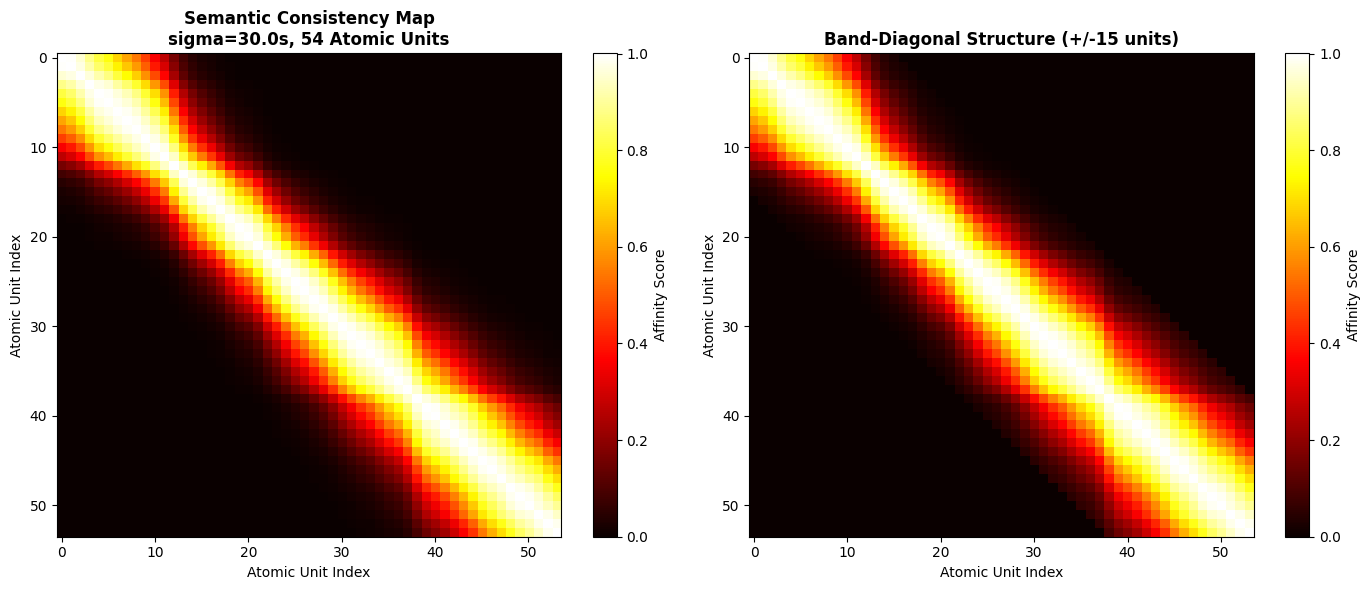

✅ SCM可视化: pipeline_output/C10390_rgb/C10390_rgb_SCM.png

Phase II: 层次拓扑解析 (Ward's HAC)
✅ 聚类完成
   合并距离范围: [0.1106, 4.4407]


NameError: name 'level_names' is not defined

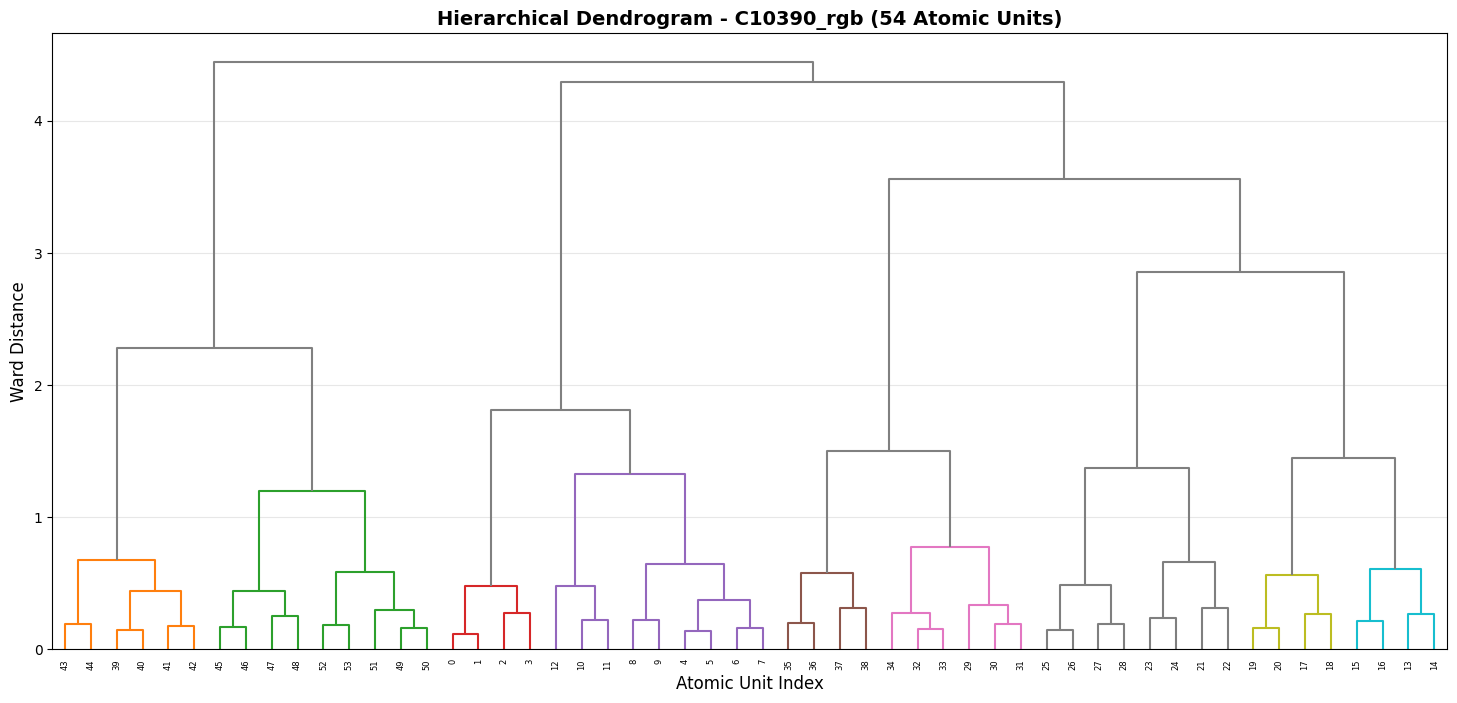

In [66]:
# %% [markdown]
# # 玩具车拆装场景事件分割Pipeline
# 
# ## 🎯 任务目标
# - **原子事件**: 拆/装单个螺丝、取下/安装单个部件 (3-8秒)
# - **中层事件**: 拆/装左轮、右轮、车身等 (15-30秒)
# - **顶层事件**: 拆解玩具车 vs 组装玩具车 (1-2.5分钟)

# %% [markdown]
# ## 🔧 环境准备

# %%
import os, subprocess, shutil
from pathlib import Path
import numpy as np
import torch
import clip
from PIL import Image
from tqdm.notebook import tqdm
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.spatial.distance import squareform
import matplotlib.pyplot as plt
import json

print(f"✅ PyTorch: {torch.__version__}, CUDA: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

# %% [markdown]
# ## 📹 配置参数（针对玩具车场景优化）

# %%
# ========== 基础配置 ==========
VIDEO_PATH = "/media/wang/New Volume1/josie/gebd/C10390_rgb.mp4"
OUTPUT_DIR = "pipeline_output"
FPS = 10
BATCH_SIZE = 64
CLEAN_FRAMES = False
REUSE_EXISTING_FRAMES = True

# ========== 原子分割配置 ==========
# 只使用非对称窗口（更适合长尾事件）
POLICY = 'asymmetric'

# 自动搜索参数范围
ATOMIC_CONFIG = {
    'window_size_range': [20, 25, 30, 35],      # 2-3.5秒窗口（拆螺丝动作）
    'threshold_range': [0.75, 0.80, 0.85],      # 提高阈值减少误检
    'min_segment_sec': 3.0,                      # 最小片段3秒
    'max_segment_sec': 20.0,                     # 最大片段20秒
    'ideal_segment_sec': (5.0, 12.0)            # 理想范围5-12秒
}

# ========== 层次结构配置 ==========
HIERARCHY_CONFIG = {
    'sigma': 30.0,  # 时间核带宽（秒）- 减小以增强局部性
    'auto_detect_levels': True,  # 自动检测层级
    'min_events_per_level': 2,   # 每层最少事件数
    'max_events_per_level': 100, # 每层最多事件数
}

# ========== 路径设置 ==========
video_path = Path(VIDEO_PATH)
video_name = video_path.stem
output_dir = Path(OUTPUT_DIR) / video_name
frame_dir = output_dir / "frames"
frame_dir.mkdir(parents=True, exist_ok=True)
device = "cuda" if torch.cuda.is_available() else "cpu"

print(f"\n🎬 视频: {video_name}")
print(f"📁 输出: {output_dir}")
print(f"🔧 设备: {device}, FPS: {FPS}")
print(f"🎯 策略: 非对称窗口 + 自适应参数搜索")

# %% [markdown]
# ## Step 1: 帧提取

# %%
print("\n" + "="*70)
print("[Step 1/3] 帧提取")
print("="*70)

if CLEAN_FRAMES:
    print("清理旧帧...")
    for p in frame_dir.glob('*.jpg'):
        p.unlink()

frame_files = sorted(list(frame_dir.glob('*.jpg')))
if frame_files and REUSE_EXISTING_FRAMES:
    print(f"✅ 复用已有 {len(frame_files)} 帧")
else:
    print("使用FFmpeg提取帧...")
    cmd = [
        'ffmpeg', '-y', '-v', 'error',
        '-i', str(video_path),
        '-vf', f'fps={FPS}',
        '-q:v', '2',
        str(frame_dir / '%06d.jpg')
    ]
    subprocess.run(cmd, check=True)
    frame_files = sorted(list(frame_dir.glob('*.jpg')))

num_frames = len(frame_files)
print(f"✅ 共 {num_frames} 帧 ({num_frames/FPS:.2f}秒)")

# %% [markdown]
# ## Step 2: CLIP编码

# %%
print("\n" + "="*70)
print("[Step 2/3] CLIP编码")
print("="*70)

print("加载CLIP模型...")
model, preprocess = clip.load("ViT-B/32", device=device)
model.eval()

feats_list = []
with torch.no_grad():
    for i in tqdm(range(0, num_frames, BATCH_SIZE), desc="编码帧"):
        images = []
        for f in frame_files[i:i+BATCH_SIZE]:
            try:
                with Image.open(f) as img:
                    images.append(preprocess(img.convert("RGB")))
            except Exception as e:
                print(f"⚠️  跳过损坏帧: {f}")
                continue
        
        if images:
            image_input = torch.stack(images).to(device)
            features = model.encode_image(image_input)
            features = features / features.norm(dim=-1, keepdim=True)
            feats_list.append(features.cpu().numpy())

features = np.concatenate(feats_list, axis=0)
print(f"✅ 特征矩阵: {features.shape}")

# %% [markdown]
# ## Step 3: 定义优化的分割算法

# %%
def sliding_window_asymmetric(feats, window_size=30, threshold=0.80, step=2):
    """非对称滑动窗口分割（针对玩具车优化）"""
    N = feats.shape[0]
    boundaries = []
    
    # 左窗口最大75帧（7.5秒）
    max_left = min(75, N // 3)
    
    for t in range(window_size * 2, N - window_size, step):
        left_size = min(t, max_left)
        left_mean = np.mean(feats[t-left_size:t], axis=0)
        right_mean = np.mean(feats[t:t+window_size], axis=0)
        similarity = np.dot(left_mean, right_mean)
        
        if similarity < threshold:
            boundaries.append(t)
    
    return boundaries


def traditional_diff_peaks(feats, fps, percentile=80):
    """传统差分峰值检测（降低敏感度）"""
    N = feats.shape[0]
    if N < 3:
        return []
    
    # 计算帧间差异
    diffs = np.array([np.linalg.norm(feats[i] - feats[i-1]) for i in range(1, N)])
    
    # 提高阈值（从85降到80但后续会过滤）
    threshold = np.percentile(diffs, percentile)
    
    boundaries = []
    MIN_DIST = int(0.5 * fps)  # 增加到0.5秒
    
    # 寻找局部峰值
    for i in range(1, len(diffs) - 1):
        if (diffs[i] > threshold and 
            diffs[i] > diffs[i-1] and 
            diffs[i] > diffs[i+1]):
            if not boundaries or (i - boundaries[-1]) >= MIN_DIST:
                boundaries.append(i)
    
    return boundaries


def refine_boundary(boundary, feats, fps):
    """精化边界位置到最大梯度点"""
    N = feats.shape[0]
    search_range = int(0.5 * fps)  # 增加搜索范围
    start = max(1, boundary - search_range)
    end = min(N - 1, boundary + search_range)
    
    best_pos = boundary
    best_diff = 0.0
    
    for t in range(start, end):
        if 0 < t < N - 1:
            diff = np.linalg.norm(feats[t] - feats[t-1])
            if diff > best_diff:
                best_diff = diff
                best_pos = t
    
    return best_pos


def evaluate_quality_toy_car(boundaries, total_frames, fps, config):
    """针对玩具车场景的质量评估
    
    理想片段：5-12秒（拆/装一个螺丝或小部件）
    """
    if len(boundaries) == 0:
        return 0.3
    
    num_segments = len(boundaries) + 1
    avg_duration_sec = total_frames / num_segments / fps
    
    min_sec = config['min_segment_sec']
    max_sec = config['max_segment_sec']
    ideal_min, ideal_max = config['ideal_segment_sec']
    
    # 更精细的评分标准
    if avg_duration_sec < min_sec:
        # 太碎片化
        score = 0.1
    elif min_sec <= avg_duration_sec < ideal_min:
        # 略微碎片化，线性插值
        score = 0.3 + 0.4 * (avg_duration_sec - min_sec) / (ideal_min - min_sec)
    elif ideal_min <= avg_duration_sec <= ideal_max:
        # 理想范围
        score = 1.0
    elif ideal_max < avg_duration_sec <= max_sec:
        # 略长，线性衰减
        score = 1.0 - 0.5 * (avg_duration_sec - ideal_max) / (max_sec - ideal_max)
    else:
        # 太长
        score = 0.2
    
    return max(0.01, score)


def adaptive_search_toy_car(feats_unit, fps, config):
    """针对玩具车的自适应参数搜索"""
    best_boundaries = []
    best_score = 0.0
    best_params = {}
    
    ws_range = config['window_size_range']
    thr_range = config['threshold_range']
    
    print(f"\n🔍 自适应搜索空间:")
    print(f"   窗口大小: {ws_range} 帧 = {[w/fps for w in ws_range]} 秒")
    print(f"   相似度阈值: {thr_range}")
    
    for ws in ws_range:
        for thr in thr_range:
            try:
                boundaries = sliding_window_asymmetric(feats_unit, ws, thr)
                score = evaluate_quality_toy_car(boundaries, feats_unit.shape[0], fps, config)
                
                if score > best_score:
                    best_boundaries = boundaries
                    best_score = score
                    best_params = {
                        'window_size': ws,
                        'window_sec': ws / fps,
                        'threshold': thr,
                        'score': score,
                        'num_boundaries': len(boundaries),
                        'avg_segment_sec': feats_unit.shape[0] / (len(boundaries) + 1) / fps
                    }
            except Exception as e:
                continue
    
    if not best_params:
        # 默认参数
        best_params = {
            'window_size': 30,
            'window_sec': 3.0,
            'threshold': 0.80,
            'score': 0.1
        }
    
    return best_boundaries, best_params


def enhanced_runner_toy_car(feats_unit, feats_scaled, fps, config):
    """增强的分割执行器（玩具车版本）"""
    print("\n" + "-"*70)
    
    # 第一步：滑动窗口分割
    print("🔹 步骤1: 非对称滑动窗口分割...")
    sw_boundaries, sw_params = adaptive_search_toy_car(feats_unit, fps, config)
    print(f"   ✓ 找到 {len(sw_boundaries)} 个边界")
    print(f"   ✓ 最佳参数: ws={sw_params['window_size']} ({sw_params['window_sec']:.1f}s), "
          f"thr={sw_params['threshold']:.2f}")
    print(f"   ✓ 平均片段长度: {sw_params.get('avg_segment_sec', 0):.1f}秒")
    
    # 第二步：传统差分峰值检测（降低权重）
    print("\n🔹 步骤2: 差分峰值检测...")
    div_boundaries = traditional_diff_peaks(feats_scaled, fps, percentile=85)
    print(f"   ✓ 找到 {len(div_boundaries)} 个边界")
    
    # 第三步：合并（优先使用滑动窗口结果）
    print("\n🔹 步骤3: 合并去重...")
    MIN_DIST = int(config['min_segment_sec'] * fps)  # 使用最小片段长度
    
    # 先加入滑动窗口结果
    all_boundaries = set(sw_boundaries)
    
    # 只添加与现有边界足够远的差分边界
    for b in div_boundaries:
        if not any(abs(b - existing) < MIN_DIST for existing in all_boundaries):
            all_boundaries.add(b)
    
    all_boundaries = sorted(all_boundaries)
    print(f"   ✓ 合并后: {len(all_boundaries)} 个边界")
    
    # 第四步：精化边界
    print("\n🔹 步骤4: 边界精化...")
    refined = []
    for b in all_boundaries:
        rb = refine_boundary(b, feats_scaled, fps)
        if not refined or rb - refined[-1] >= MIN_DIST:
            refined.append(rb)
    
    print(f"   ✓ 精化后: {len(refined)} 个边界")
    
    # 第五步：质量评估
    final_score = evaluate_quality_toy_car(refined, feats_scaled.shape[0], fps, config)
    
    # 统计信息
    num_segments = len(refined) + 1
    avg_duration = feats_scaled.shape[0] / num_segments / fps
    
    print(f"\n📊 最终统计:")
    print(f"   边界数: {len(refined)}")
    print(f"   片段数: {num_segments}")
    print(f"   平均片段长度: {avg_duration:.1f}秒")
    print(f"   质量分数: {final_score:.3f}")
    print("-"*70)
    
    # 构建参数字典
    params = {
        'method': 'sliding_window_asymmetric',
        'final_score': final_score,
        'sw_params': sw_params,
        'num_sw_boundaries': len(sw_boundaries),
        'num_div_boundaries': len(div_boundaries),
        'num_merged': len(all_boundaries),
        'num_refined': len(refined),
        'avg_segment_sec': avg_duration
    }
    
    return refined, params


print("✅ 分割算法已加载（玩具车优化版）")

# %% [markdown]
# ## Step 3: 执行原子分割

# %%
print("\n" + "="*70)
print("[Step 3/3] 原子级事件分割")
print("="*70)

# 特征预处理
feats_unit = features / (np.linalg.norm(features, axis=1, keepdims=True) + 1e-8)
scaler = StandardScaler()
feats_scaled = scaler.fit_transform(features)

# 执行分割
boundaries, params = enhanced_runner_toy_car(
    feats_unit, feats_scaled, FPS, ATOMIC_CONFIG
)

results = {'asymmetric': {'boundaries': boundaries, 'params': params}}

print("\n✅ 原子分割完成")

# %% [markdown]
# ## 保存原子分割结果

# %%
def create_segments(boundaries, T):
    """从边界列表创建片段列表"""
    segs = []
    prev = 0
    for b in sorted(boundaries):
        b = int(b)
        if b > prev:
            segs.append([int(prev), int(b)])
            prev = b
    if prev < T:
        segs.append([int(prev), int(T)])
    return segs

T = features.shape[0]
segs = create_segments(boundaries, T)

json_data = {
    'video_name': video_name,
    'num_frames': int(T),
    'fps': float(FPS),
    'video_duration': round(T / FPS, 3),
    'num_boundaries': len(boundaries),
    'num_segments': len(segs),
    'boundaries_frame_indices': [int(b) for b in boundaries],
    'boundaries_timestamps': [round(b / FPS, 3) for b in boundaries],
    'segments_timestamps': [[round(s[0]/FPS, 3), round(s[1]/FPS, 3)] for s in segs],
    'method': 'sliding_window_asymmetric',
    'parameters': params,
    'config': ATOMIC_CONFIG
}

out_path = output_dir / f"{video_name}_atomic_segmentation.json"
with open(out_path, 'w', encoding='utf-8') as f:
    json.dump(json_data, f, ensure_ascii=False, indent=2)

print(f"✅ 原子分割JSON: {out_path}")

# 可视化原子分割（使用mm:ss格式）
fig, ax = plt.subplots(figsize=(20, 3))
colors = plt.cm.Set3(np.linspace(0, 1, len(segs)))

for idx, (start, end) in enumerate(segs):
    ax.barh(0, end-start, left=start/FPS, height=0.8, 
            color=colors[idx % len(colors)], edgecolor='black', linewidth=0.5)

max_time = T / FPS
ax.set_xlim(0, max_time)
ax.set_ylim(-0.5, 0.5)
ax.set_yticks([])
ax.set_xlabel('Time (mm:ss)', fontsize=12)

# 设置x轴为mm:ss格式
num_ticks = 12
tick_positions = np.linspace(0, max_time, num_ticks)
tick_labels = [seconds_to_mmss(t) for t in tick_positions]
ax.set_xticks(tick_positions)
ax.set_xticklabels(tick_labels, rotation=0, fontsize=9)

ax.set_title(f'Atomic Segmentation - {len(segs)} Segments', fontsize=14, fontweight='bold')
ax.grid(True, alpha=0.3, axis='x')

plt.tight_layout()
atomic_viz_path = output_dir / f"{video_name}_atomic_segments.png"
plt.savefig(atomic_viz_path, dpi=150, bbox_inches='tight')
plt.show()

print(f"✅ 原子分割可视化: {atomic_viz_path}")


# 辅助函数定义（用于后续代码）
def seconds_to_mmss(seconds):
    """将秒数转换为mm:ss格式"""
    minutes = int(seconds // 60)
    secs = int(seconds % 60)
    return f"{minutes:02d}:{secs:02d}"

# %% [markdown]
# ## Phase I: 构建语义一致性图谱

# %%
print("\n" + "="*70)
print("Phase I: 构建语义一致性图谱 (SCM)")
print("="*70)

K = len(boundaries) + 1  # 原子单元数量
print(f"原子单元数量: {K}")


def extract_atomic_features(features, boundaries, fps):
    """从CLIP特征中提取每个原子单元的代表性特征"""
    T = features.shape[0]
    segments = []
    
    # 构建片段列表
    prev = 0
    for b in boundaries:
        if b > prev:
            segments.append((prev, b))
            prev = b
    if prev < T:
        segments.append((prev, T))
    
    atomic_features = []
    atomic_centers = []
    
    for start, end in segments:
        # 计算片段的平均特征
        segment_feats = features[start:end]
        mean_feat = np.mean(segment_feats, axis=0)
        
        # L2归一化
        mean_feat = mean_feat / (np.linalg.norm(mean_feat) + 1e-8)
        atomic_features.append(mean_feat)
        
        # 计算时间中心（秒）
        center_time = (start + end) / 2.0 / fps
        atomic_centers.append(center_time)
    
    return np.array(atomic_features), np.array(atomic_centers)


# 提取原子单元特征
atomic_features, atomic_centers = extract_atomic_features(features, boundaries, FPS)

print(f"原子特征矩阵: {atomic_features.shape}")
print(f"时间中心范围: {atomic_centers[0]:.2f}s ~ {atomic_centers[-1]:.2f}s")


def build_semantic_consistency_map(atomic_features, atomic_centers, sigma):
    """构建语义一致性图谱 (SCM)"""
    K = len(atomic_features)
    M = np.zeros((K, K))
    
    for i in range(K):
        for j in range(K):
            # 1. 语义核：余弦相似度
            K_sem = np.dot(atomic_features[i], atomic_features[j])
            
            # 2. 时间核：高斯RBF
            time_diff = atomic_centers[i] - atomic_centers[j]
            K_temp = np.exp(- (time_diff ** 2) / (2 * sigma ** 2))
            
            # 3. 混合核
            M[i, j] = K_sem * K_temp
    
    return M


# 构建SCM
sigma = HIERARCHY_CONFIG['sigma']
SCM = build_semantic_consistency_map(atomic_features, atomic_centers, sigma)

print(f"\n✅ SCM构建完成")
print(f"   矩阵大小: {SCM.shape}")
print(f"   时间核带宽 σ: {sigma}秒")
print(f"   亲和度范围: [{SCM.min():.4f}, {SCM.max():.4f}]")

# %%
# 可视化SCM
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

im1 = axes[0].imshow(SCM, cmap='hot', aspect='auto', interpolation='nearest')
axes[0].set_title(
    f'Semantic Consistency Map\nsigma={sigma}s, {K} Atomic Units',
    fontsize=12, fontweight='bold'
)
axes[0].set_xlabel('Atomic Unit Index', fontsize=10)
axes[0].set_ylabel('Atomic Unit Index', fontsize=10)
plt.colorbar(im1, ax=axes[0], label='Affinity Score')

band_width = min(15, K//2)
band_mask = np.abs(np.arange(K)[:, None] - np.arange(K)[None, :]) <= band_width
SCM_band = SCM.copy()
SCM_band[~band_mask] = 0

im2 = axes[1].imshow(SCM_band, cmap='hot', aspect='auto', interpolation='nearest')
axes[1].set_title(
    f'Band-Diagonal Structure (+/-{band_width} units)',
    fontsize=12, fontweight='bold'
)
axes[1].set_xlabel('Atomic Unit Index', fontsize=10)
axes[1].set_ylabel('Atomic Unit Index', fontsize=10)
plt.colorbar(im2, ax=axes[1], label='Affinity Score')

plt.tight_layout()
scm_path = output_dir / f"{video_name}_SCM.png"
plt.savefig(scm_path, dpi=150, bbox_inches='tight')
plt.show()

print(f"✅ SCM可视化: {scm_path}")

# %% [markdown]
# ## Phase II: 层次拓扑解析

# %%
print("\n" + "="*70)
print("Phase II: 层次拓扑解析 (Ward's HAC)")
print("="*70)


def similarity_to_distance(similarity_matrix):
    """将相似度矩阵转换为距离矩阵"""
    sim_clipped = np.clip(similarity_matrix, 0, 1)
    distance = np.sqrt(2 * (1 - sim_clipped))
    np.fill_diagonal(distance, 0)
    return distance


distance_matrix = similarity_to_distance(SCM)
condensed_distance = squareform(distance_matrix, checks=False)

# Ward's层次聚类
linkage_matrix = linkage(condensed_distance, method='ward')
merge_distances = linkage_matrix[:, 2]

print(f"✅ 聚类完成")
print(f"   合并距离范围: [{merge_distances.min():.4f}, {merge_distances.max():.4f}]")

# %%
# 可视化树状图
fig, ax = plt.subplots(figsize=(18, 8))
dendrogram_data = dendrogram(
    linkage_matrix,
    ax=ax,
    color_threshold=np.percentile(merge_distances, 85),
    above_threshold_color='gray',
    leaf_font_size=6
)
ax.set_title(
    f'Hierarchical Dendrogram - {video_name} ({K} Atomic Units)',
    fontsize=14, fontweight='bold'
)
ax.set_xlabel('Atomic Unit Index', fontsize=12)
ax.set_ylabel('Ward Distance', fontsize=12)
ax.grid(True, alpha=0.3, axis='y')

# 添加自动检测的分割线
for i, level_name in enumerate(level_names[1:]):  # 跳过atomic级
    level_data = hierarchical_segmentations[level_name]
    threshold = level_data['threshold']
    num_events = level_data['num_events']
    
    ax.axhline(y=threshold, color='red', linestyle='--', linewidth=1.5, alpha=0.7)
    ax.text(K*0.98, threshold, f'{level_name}: {num_events} events', 
            verticalalignment='bottom', fontsize=9, color='red')

plt.tight_layout()
dendrogram_path = output_dir / f"{video_name}_dendrogram.png"
plt.savefig(dendrogram_path, dpi=150, bbox_inches='tight')
plt.show()

print(f"✅ 树状图: {dendrogram_path}")

# %% [markdown]
# ## 多粒度分割（自动检测层级）

# %%
print("\n" + "="*70)
print("自动检测层级结构")
print("="*70)


def auto_detect_hierarchy_levels(merge_distances, min_events, max_events):
    """自动检测有意义的层级切割点
    
    基于合并距离的"肘部"（elbow）检测自然层级
    """
    # 计算合并距离的差分（变化率）
    distances_sorted = np.sort(merge_distances)
    diffs = np.diff(distances_sorted)
    
    # 找到显著的跳跃点（距离突然增大的地方）
    # 使用相对变化率避免绝对值依赖
    relative_jumps = diffs / (distances_sorted[:-1] + 1e-10)
    
    # 找到前几个最大的跳跃
    jump_indices = np.argsort(relative_jumps)[::-1]
    
    # 转换为百分位数
    percentiles = []
    thresholds = []
    
    for idx in jump_indices[:10]:  # 检查前10个跳跃点
        threshold = distances_sorted[idx]
        cluster_labels = fcluster(linkage_matrix, threshold, criterion='distance')
        num_clusters = len(np.unique(cluster_labels))
        
        # 检查是否在合理范围内
        if min_events <= num_clusters <= max_events:
            # 计算百分位数
            percentile = (idx / len(distances_sorted)) * 100
            percentiles.append(percentile)
            thresholds.append(threshold)
    
    # 按百分位数排序（从小到大，即从细到粗）
    sorted_pairs = sorted(zip(percentiles, thresholds))
    
    return sorted_pairs


# 自动检测层级
if HIERARCHY_CONFIG['auto_detect_levels']:
    print("🔍 自动检测层级结构...")
    
    detected_levels = auto_detect_hierarchy_levels(
        merge_distances,
        HIERARCHY_CONFIG['min_events_per_level'],
        HIERARCHY_CONFIG['max_events_per_level']
    )
    
    print(f"   检测到 {len(detected_levels)} 个候选层级")
    
    # 选择分布均匀的3-5个层级
    if len(detected_levels) > 5:
        # 选择分布均匀的层级
        indices = np.linspace(0, len(detected_levels)-1, 5, dtype=int)
        selected_levels = [detected_levels[i] for i in indices]
    else:
        selected_levels = detected_levels
    
    # 添加原子级（不切割）
    hierarchical_segmentations = {}
    hierarchical_segmentations['atomic'] = {
        'threshold': 0.0,
        'num_events': K,
        'labels': np.arange(1, K+1)
    }
    
    # 添加检测到的层级
    level_names = ['atomic']
    for i, (percentile, threshold) in enumerate(selected_levels):
        level_name = f'level_{i+1}'
        level_names.append(level_name)
        
        cluster_labels = fcluster(linkage_matrix, threshold, criterion='distance')
        num_clusters = len(np.unique(cluster_labels))
        
        hierarchical_segmentations[level_name] = {
            'threshold': threshold,
            'percentile': percentile,
            'num_events': num_clusters,
            'labels': cluster_labels
        }
        
        print(f"   Level {i+1}: {num_clusters:3d} events "
              f"(percentile={percentile:.1f}%, threshold={threshold:.3f})")

else:
    # 使用手动定义的层级（保留旧代码兼容性）
    hierarchical_segmentations = {}
    cut_levels = HIERARCHY_CONFIG['cut_levels']
    level_names = []
    
    for level_name, percentile in cut_levels.items():
        level_names.append(level_name)
        if percentile is None:
            hierarchical_segmentations[level_name] = {
                'threshold': 0.0,
                'num_events': K,
                'labels': np.arange(1, K+1)
            }
        else:
            threshold = np.percentile(merge_distances, percentile)
            cluster_labels = fcluster(linkage_matrix, threshold, criterion='distance')
            num_clusters = len(np.unique(cluster_labels))
            
            hierarchical_segmentations[level_name] = {
                'threshold': threshold,
                'num_events': num_clusters,
                'labels': cluster_labels
            }

print(f"\n✅ 共 {len(hierarchical_segmentations)} 个层级")

# %%
# 可视化多粒度分割
fig, axes = plt.subplots(len(hierarchical_segmentations), 1, 
                         figsize=(20, 2*len(hierarchical_segmentations)))

level_names = ['atomic', 'component', 'side', 'activity']

for idx, (level_name, ax) in enumerate(zip(level_names, axes)):
    level_data = hierarchical_segmentations[level_name]
    labels = level_data['labels']
    num_events = level_data['num_events']
    colors = plt.cm.tab20(np.linspace(0, 1, num_events))
    
    for i in range(K):
        cluster_id = labels[i] - 1
        color = colors[cluster_id % len(colors)]
        ax.barh(0, 1, left=i, height=0.8, color=color, edgecolor='white', linewidth=0.5)
    
    ax.set_xlim(0, K)
    ax.set_ylim(-0.5, 0.5)
    ax.set_yticks([])
    ax.set_xlabel('Atomic Unit Index', fontsize=10)
    ax.set_title(
        f'{level_name.upper()} Level - {num_events} Events',
        fontsize=11, fontweight='bold'
    )
    ax.grid(True, alpha=0.3, axis='x')

plt.tight_layout()
hierarchy_path = output_dir / f"{video_name}_hierarchy.png"
plt.savefig(hierarchy_path, dpi=150, bbox_inches='tight')
plt.show()

print(f"\n✅ 层次分割可视化: {hierarchy_path}")

# %% [markdown]
# ## 转换为时间戳并保存

# %%
def convert_hierarchy_to_timestamps(boundaries, atomic_segments, hierarchical_segmentations, fps):
    """将层次聚类标签转换为时间戳格式的事件
    
    修复：直接传入atomic_segments避免索引错误
    """
    hierarchy_timestamps = {}
    
    for level_name, level_data in hierarchical_segmentations.items():
        labels = level_data['labels']
        num_events = level_data['num_events']
        
        # 为每个簇收集对应的原子片段
        cluster_to_atomics = {i: [] for i in range(1, num_events + 1)}
        for atom_idx, cluster_id in enumerate(labels):
            if atom_idx < len(atomic_segments):  # 安全检查
                cluster_to_atomics[cluster_id].append(atom_idx)
        
        # 为每个簇计算时间范围
        events = []
        for cluster_id in sorted(cluster_to_atomics.keys()):
            atom_indices = cluster_to_atomics[cluster_id]
            if not atom_indices:
                continue
            
            # 找到这个簇包含的所有原子片段的时间范围
            start_frame = min(atomic_segments[i][0] for i in atom_indices)
            end_frame = max(atomic_segments[i][1] for i in atom_indices)
            
            start_time = round(start_frame / fps, 2)
            end_time = round(end_frame / fps, 2)
            duration = round(end_time - start_time, 2)
            
            events.append({
                'event_id': cluster_id,
                'start_time': start_time,
                'end_time': end_time,
                'duration': duration,
                'num_atomic_units': len(atom_indices),
                'atomic_indices': atom_indices
            })
        
        hierarchy_timestamps[level_name] = {
            'num_events': num_events,
            'events': events
        }
    
    return hierarchy_timestamps


# 转换为时间戳（修复：传入segs）
hierarchy_timestamps = convert_hierarchy_to_timestamps(
    boundaries, segs, hierarchical_segmentations, FPS
)

# 保存完整的层次结构JSON（包含时间戳）
hierarchy_json = {
    'video_name': video_name,
    'num_frames': int(T),
    'fps': float(FPS),
    'video_duration': round(T / FPS, 2),
    'num_atomic_units': int(K),
    'scm_sigma': float(sigma),
    'linkage_method': 'ward',
    'atomic_boundaries': [round(b / FPS, 2) for b in boundaries],
    'hierarchical_levels': {}
}

for level_name, level_data in hierarchical_segmentations.items():
    hierarchy_json['hierarchical_levels'][level_name] = {
        'threshold': float(level_data['threshold']),
        'num_events': int(level_data['num_events']),
        'cluster_labels': level_data['labels'].tolist(),
        'events': hierarchy_timestamps[level_name]['events']
    }

hierarchy_json_path = output_dir / f"{video_name}_hierarchy.json"
with open(hierarchy_json_path, 'w', encoding='utf-8') as f:
    json.dump(hierarchy_json, f, ensure_ascii=False, indent=2)

print(f"✅ 层次结构JSON: {hierarchy_json_path}")

# %% [markdown]
# ## 打印每层事件的时间戳

# %%
print("\n" + "="*70)
print("📅 每层事件时间戳详情")
print("="*70)

level_names_display = {
    'atomic': '原子级 (ATOMIC)'
}

# 为自动检测的层级添加显示名称
for i in range(1, len(level_names)):
    level_name = level_names[i]
    level_names_display[level_name] = f'层级 {i} ({level_name.upper()})'

for level_name in level_names:
    print(f"\n{'='*70}")
    print(f"【{level_names_display[level_name]}】")
    print(f"{'='*70}")
    
    level_info = hierarchy_timestamps[level_name]
    events = level_info['events']
    
    print(f"事件总数: {len(events)}")
    print(f"{'ID':<4} {'开始时间':>10} {'结束时间':>10} {'时长':>8} {'原子单元数':>10}")
    print("-" * 70)
    
    for event in events:
        event_id = event['event_id']
        start = event['start_time']
        end = event['end_time']
        duration = event['duration']
        num_atomics = event['num_atomic_units']
        
        print(f"{event_id:<4} {start:>9.2f}s {end:>9.2f}s {duration:>7.2f}s {num_atomics:>10}")
    
    # 统计信息
    durations = [e['duration'] for e in events]
    print("-" * 70)
    print(f"平均时长: {np.mean(durations):.2f}秒")
    print(f"最短事件: {np.min(durations):.2f}秒")
    print(f"最长事件: {np.max(durations):.2f}秒")
    print(f"中位时长: {np.median(durations):.2f}秒")

print("\n" + "="*70)

# %% [markdown]
# ## 📊 最终摘要

# %%
print("\n" + "="*70)
print(f"📊 玩具车拆装分割结果 - {video_name}")
print("="*70)
print(f"视频时长: {T/FPS:.2f}秒 ({T}帧), FPS: {FPS}")
print()

print("【原子级分割】")
print(f"  方法: 非对称滑动窗口")
print(f"  边界数: {len(boundaries)}")
print(f"  片段数: {len(segs)}")
print(f"  平均片段长度: {params['avg_segment_sec']:.1f}秒")
print(f"  质量分数: {params['final_score']:.3f}")
print()

print("【层次结构】")
for level_name in level_names:
    level_data = hierarchical_segmentations[level_name]
    print(f"  {level_name:12s}: {level_data['num_events']:3d} 个事件")

print()
print("💡 解释:")
print("  - ATOMIC    : 拆/装单个螺丝、取下/安装单个小部件")
print("  - COMPONENT : 拆/装单个轮子、车身等完整部件")
print("  - SIDE      : 拆/装左侧、右侧（如左右轮子组合）")
print("  - ACTIVITY  : 最顶层：拆解玩具车 vs 组装玩具车")
print()
print(f"📁 所有输出已保存至: {output_dir}")
print("   - *_atomic_segmentation.json (原子分割)")
print("   - *_atomic_segments.png (原子分割可视化)")
print("   - *_hierarchy.json (层次结构)")
print("   - *_SCM.png (语义一致性图谱)")
print("   - *_dendrogram.png (树状图)")
print("   - *_hierarchy.png (多粒度分割)")
print()
print("🎉 Pipeline执行完成!")
print("="*70)